# Re-Degradation Reveals Resolution: Observation Semigroups Make Sensor Shift Identifiable Without Labels
**CVPR 2027 · complete experimental program** (single T4 GPU; one or more Kaggle sessions with a universal 11-hour budget each). Every number is computed by this notebook from its own checkpoints; a later session continues an unfinished one from the zip of the previous session.

## Section 0 · Idea, theory, hypotheses, pre-registration and addendum
The specification below is restated verbatim from the pre-registered prompt (I-2 to I-7), followed by the state-of-the-art definition (I-14), the machine-readable pre-registration with its SHA-256, the addendum registered after run 1 (with its own SHA-256), the data and model lists, the run plan, the session budget and resume workflow, the seed policy, a run guide and every self-selected implementation decision.

### Core insight (I-2)
```text
I-2  CORE INSIGHT
Physical degradations compose. If the optics already blurred an image with a Gaussian-equivalent PSF of variance s0, blurring it further by eta gives exactly s0 + eta (heat semigroup). Per-image standardization removes contrast, gain and haze-like offsets. An unlabeled deployment image can therefore be located on the degradation axis by re-degrading it and reading where its response bends: the re-degradation knee. For scenes with 1/f^2 spectra, re-blurring by the existing blur variance removes half of the remaining gradient energy (half-energy law). This needs only pixels: no labels and no encoder. Degrading the labeled source to the identified level removes the physical part of the shift, so a confidence-based estimator (ATC) only has to absorb the residual content shift. Mechanistic corollary: encoders pretrained with blur augmentation under invariance objectives cannot report how blurred a single input is, so label-free monitoring must read the pixels, not the features.
```

### Problem statement (I-3)
```text
I-3  PROBLEM STATEMENT
Given labeled source data (x, y) ~ P, unlabeled target images x ~ Q, a frozen encoder phi and a linear probe h trained on clean source features:
(1) identify the effective blur s0 that separates Q from P;
(2) predict target accuracy Acc_Q = Pr_Q[h(phi(N x)) = y] without target labels;
(3) flag targets that are not pure blur translates of the source (e.g. fresh sensor noise added after the optics).
Evaluation conditions:
- exact-ground-truth in-family degradations of held-out data;
- label shift;
- a real cross-dataset shift (RESISC45 <-> UC Merced);
- a real cross-product shift (LandCover.ai 25 cm -> 50 cm).
Scale: 10 evaluation datasets with 6 frozen encoders. A 17-encoder mechanism screen explains which encoders can or cannot sense blur.
```

### Formal setup (I-4)
```text
I-4  FORMAL SETUP
Notation
- Tiles are 224 x 224 RGB in digital numbers (DN, 0-255). All pixel operators act per channel.
- D: non-wrapping forward difference on both axes. L = D^T D is the Neumann Laplacian.
  - Its eigenbasis is the orthonormal 2-D DCT-II, Phi.
  - Its eigenvalues are lambda_{k,l} = 4 sin^2(pi k / 448) + 4 sin^2(pi l / 448), in [0, 8].
- Blur: T_s = exp(-(s/2) L), with s >= 0 the Gaussian-equivalent PSF variance in px^2. It is exact on finite tiles: T_s x = Phi( exp(-s lambda / 2) * Phi^T x ).
- Radiometry: A_{a,b} x = a x + b 1 with a > 0, per image and channel. (a, b) may depend on (x, y).
- Standardization: N(x) = (x - mean(x) 1) / (sd(x) + 1e-6), per image and channel.
- Coefficients c = Phi^T x. Gradient-power measure nu_x = sum_{lambda > 0} lambda c_lambda^2 delta_lambda.
- Re-degradation energy: e_x(eta) = ||D T_eta x||^2 = integral exp(-eta lambda) d nu_x(lambda).
- Normalized pixel response: rho_x(eta) = 1 - e_x(eta) / e_x(0), in [0, 1]. Averaged over the three channels.
- Tilted measure: pi_t ∝ exp(-t lambda) nu.
- Observability: O_x = integral_0^{eta*} Var_{pi_u}(lambda) du, with eta* = 2 px^2 and pi_u ∝ exp(-u lambda) nu_x. Computed with the trapezoid rule on 32 points, channel-averaged.
- phi is a frozen encoder. h is a probe trained on phi(N x) of clean source images.
- Accuracy curve: A(s) = Pr_P[h(phi(N T_s x)) = y]. Noisy version: A(s, sigma) for x -> N(T_s x + sigma xi), with xi ~ N(0, I) in DN.
- Feature statistic: psi_eta(x) = 1/2 [1 - cos(phi(N T_eta x), phi(N x))], pooled or token-wise.
- Population curves: m_P(s, eta) = E_P[stat(T_s x; eta)] and m_Q(eta) = E_Q[stat(x; eta)].
- Hypothesis H(s0): Q = (A_{a,b} T_{s0} x id)_# P.
- The noise-extended family x -> A_{a,b}(T_{s0} x + sigma0 xi) is NOT covered by the theorems. It is handled by a heuristic fallback.

Assumptions
A1 Exact semigroup on finite tiles (true by construction).
A2 The radiometric nuisance is per-image affine: it commutes with blur and is removed by N.
A3 Spectral non-degeneracy: Pr_P{ Var_{pi_{x,t}}(lambda) > 0 } > 0 for all t in [0, s_max]. This fails exactly for narrowband scenes.
A4 Independent units. In the scene-classification datasets, images are units. LandCover.ai tiles are clustered by orthophoto, so orthophotos are the units.
A5 Bounded statistics in [0, 1] (rho, psi).
A6 Frozen encoder and probe. No target label enters any estimator, hyperparameter or decision; labels are used only to compute ground-truth accuracy.
```

### Theory (I-5), including the scope of what is and is not claimed
```text
I-5  THEORY (restate verbatim in Section 0)
Lemma 1.
  (i) T_s T_t = T_{s+t} and T_s 1 = 1.
  (ii) T_s A_{a,b} = A_{a,b} T_s.
  (iii) N o A_{a,b} = N.
  (iv) nu_{A_{a,b} x} = a^2 nu_x, hence rho_{A_{a,b} x} = rho_x.

Theorem 1 (exact transport). Let Q be the law of (A_{a,b} T_{s0} x, y) with (x, y) ~ P, where (a, b) are arbitrary measurable functions of (x, y) with a > 0. For every measurable F:
  E_Q F(N T_{eta_1} x, ..., N T_{eta_m} x, y) = E_P F(N T_{s0+eta_1} x, ..., N T_{s0+eta_m} x, y).
Hence m_Q(eta) = m_P(s0, eta), Acc_Q = A(s0), and E_Q rho(eta) = E_P rho_{T_{s0} x}(eta).
Proof: by Lemma 1, N T_eta A_{a,b} T_{s0} x = N T_{s0+eta} x.

Theorem 2 (spectral structure). Write x = T_{s0} x~ and pi_t ∝ exp(-t lambda) nu_{x~}.
  (a) Laplace form: 1 - rho_x(eta) = integral exp(-eta lambda) d pi_{s0}.
  (b) Sensitivity identity:
        d rho_x(eta) / d s0 = -(1 - rho_x(eta)) integral_0^eta Var_{pi_{s0+u}}(lambda) du,
      with pi_{s0+u} ∝ exp(-u lambda) nu_x. It is computable from the observed image alone.
  (c) Population identifiability: if Pr_P{ Var_{pi_{x,t}}(lambda) > 0 } > 0 for all t in [0, s_max], then d m_P^rho(s, eta) / d s < 0 for every eta > 0, so a single eta identifies s0.
  (d) Obstructions.
      - Narrowband (nu_{x~} a point mass): N T_s x~ does not depend on s, so no affine-invariant procedure can identify s0.
      - Intrinsic smoothness (spectrum in [0, lambda_c]): |d rho_x(eta) / d s0| <= min(lambda_c, eta lambda_c^2 / 4).
  (e) Power-law class. Let nu_{x~} = c lambda^beta 1_[0, Lambda] d lambda and gamma = beta + 1. Then
        1 - rho_x(eta) = (1 + eta/s0)^(-gamma) P(gamma, (s0+eta) Lambda) / P(gamma, s0 Lambda),
        |rho_x(eta) - [1 - (1 + eta/s0)^(-gamma)]| <= (1 + eta/s0)^(-gamma) Q(gamma, s0 Lambda) / (1 - Q(gamma, s0 Lambda)),
      where P and Q are the regularized lower and upper incomplete gamma functions. An isotropic |omega|^(-alpha) spectrum gives gamma = 2 - alpha/2.

Corollary 1 (half-energy law; information-optimal re-blur). With negligible Q(gamma, s0 Lambda) and u = eta/s0:
  - rho_x(eta) ≈ 1 - (1 + u)^(-gamma), and the half-point is eta_1/2 = s0 (2^(1/gamma) - 1).
  - For alpha = 2 (gamma = 1), rho_x(s0) = 1/2: re-blurring by the existing variance removes half the remaining gradient energy.
  - d rho / d log s0 = -gamma u (1 + u)^(-gamma-1). Its magnitude peaks at u* = 1/gamma with value (1 + 1/gamma)^(-(gamma+1)), which is 1/4 for gamma = 1. Precision in log-blur is therefore scale-free.

Theorem 3 (test-inversion certificate).
  Setup.
  - Target units are i.i.d. from Q. Source units are i.i.d. from P, plus a separate labeled source split of size n_A.
  - Statistic psi_eta in [0, 1] on a grid of K re-degradation levels. Hypothesis grid S of M blur levels.
  - s_bar is the grid point nearest s0. omega = sup_eta |m_P(s_bar, eta) - m_P(s0, eta)|.
  - Tolerances: eps_Q = sqrt(log(6K/delta) / (2 n_Q)), eps_P = sqrt(log(6KM/delta) / (2 n_P)), eps_A = sqrt(log(6M/delta) / (2 n_A)), and tau = eps_Q + eps_P.
  Construction.
  - CS = { s in S : max_eta |m^_Q(eta) - m^_P(s, eta)| <= tau + omega }.
  - C = [ min_{CS} A^ - eps_A, max_{CS} A^ + eps_A ].
  - Abstain if CS is empty.
  Under H(s0), with probability >= 1 - delta:
  (i) Coverage: s_bar in CS and Acc_Q in C. If s0 is off-grid, widen C by the accuracy modulus over one grid cell.
  (ii) No false abstention.
  (iii) Width: diam CS <= 2(2 tau + omega) / kappa, with kappa = inf_{s != s'} max_eta |m_P(s, eta) - m_P(s', eta)| / |s - s'|.
  (iv) Power: under any alternative with inf_s max_eta |m_Q - m_P(s, .)| > 2 tau + omega, the procedure abstains.
  For pixel statistics, kappa > 0 by Theorem 2(c). Empirical-Bernstein tolerances can replace Hoeffding without changing the proof.

Theorem 4 (minimax lower bound).
  Model: x_obs = T_s x + sigma xi with xi ~ N(0, I). The scene gradient spectrum is supported in [0, lambda_c], m2 = E||x - mean(x) 1||^2 < inf, and A_sigma(s) is a fixed classifier's accuracy.
  Statement: for any estimator built from n i.i.d. target units, with h = 2 sigma / (lambda_c sqrt(n m2)):
    max_{s in {s0, s0+h}} E|A^ - A_sigma(s)| >= (1/4)|A_sigma(s0+h) - A_sigma(s0)| ≈ |A_sigma'(s0)| sigma / (2 lambda_c sqrt(n m2)).
  The n^(-1/2) rate matches Theorem 3(iii); the constants do not. The theorem names the regime where accuracy loss is undetectable by any label-free method: smooth scenes, low SNR, steep accuracy curves.

Proposition 5 (content-anchor drift). ||T_{Lambda+s} x - T_Lambda x|| <= e^(-1) log(1 + s/Lambda) ||x - mean(x) 1||.

Proposition 6 (shift factorization; data processing). Let K_{s,sigma}: x -> T_s x + sigma xi be the degradation kernel. For any content laws P, P' on (x, y):
  TV(K_{s,sigma} P, K_{s,sigma} P') <= TV(P, P').
If Q = K_{s0,sigma0} P' (up to per-image radiometry, which N removes), then degrading the labeled source to the identified level leaves a residual discrepancy no larger than the clean content shift. A confidence estimator calibrated on the degraded source therefore faces only the residual shift. This is the design principle of ATC@s^.

Scope: what is claimed
- Exact transport and identifiability under H(s0) (Theorems 1-2).
- Certified coverage of the batch statistic with independent units (Theorem 3), tested in R8.
- Primary empirical claim: where the GOF test does not fire, ATC@s^ has lower mean and worst-case MAE over the 6 encoders than every single baseline (F1, F2).
Scope: what is NOT claimed
- Any guarantee when the GOF test fires (blur + fresh noise; the joint fit is a heuristic).
- Detection of label shift, which pixels cannot see by Theorem 1.
- Validity for non-Gaussian PSFs beyond their Gaussian-equivalent second moment.
- That the GOF test is an exact level-alpha test. It is a heuristic; its type-I error is measured in F5.
```

### Frozen method v1.0 (I-6)
```text
I-6  FROZEN METHOD v1.0 (do not change any constant or step)
Constants
- ETA_PIX = geomspace(0.25, 1024, 13)
- S_FIT = geomspace(0.05, 2048, 170); G_FIT = linspace(0.3, 2.2, 39)
- R_FIT = {0} ∪ geomspace(1e-3, 30, 15)
- CAL_GRID = {0} ∪ geomspace(0.05, 400, 30)
- lambda bins: 3000 log-spaced bins over lambda > 0, edges = geomspace(0.999 min lambda, 1.001 max lambda, 3001). LAMB = mean lambda per bin; CNT = coefficient count per bin.
- GOF alpha = 0.01. Secondary high band: lambda >= 6.

Steps
Steps 1-7 use only pixels and are identical for every encoder.
1. Spectra. Per image and channel: c = DCT-II(x) in float64, and W_b = sum over lambda in bin b of lambda c_lambda^2. This gives W of shape (n, 3, 3000). Applying blur s multiplies W_b by exp(-s LAMB_b). A noisy target uses the spectra of the actual noisy image.
2. Curves. E(s) = sum_b W_b exp(-s LAMB_b) and rho(eta) = 1 - E(s+eta)/E(s), per channel then channel-averaged, for eta in ETA_PIX.
3. Per-image knee fits.
   - One-parameter fit: grid least squares over S_FIT x G_FIT of rho(eta) ≈ 1 - (1 + eta/s)^(-gamma). Output (s_raw, gamma^, SSE).
   - Noise-aware fit: rho(eta) ≈ 1 - [(1 + eta/s)^(-gamma) + r ew(eta)] / (1 + r), over r in R_FIT, with ew(eta) = sum_b CNT_b LAMB_b exp(-eta LAMB_b) / sum_b CNT_b LAMB_b. Output (s_raw2, r^, SSE2).
4. Source calibration on the clean labeled source split A2.
   - CAL1(s) = median over A2 of s_raw(T_s x); CAL2(s) = median noise-aware knee; for s in CAL_GRID.
   - Inverse: v -> interp(v, cummax(CAL), CAL_GRID).
5. Identification: s^ = CAL1^-1( median over target of s_raw(x) ).
6. GOF test: one-sided Mann-Whitney U (alternative "greater") comparing target SSEs with the SSEs of A2 attenuated to s^. The condition is flagged iff p < 0.01.
7. Choose the source level.
   - Not flagged: (s_use, sigma_use) = (s^, 0).
   - Flagged (joint blur + noise fit; heuristic, no guarantee): s_use = CAL2^-1(median noise-aware knee), and sigma_use = sqrt( median_x[ Ebar_x r^_x / (1 + r^_x) ] / sum_b CNT_b LAMB_b ), where Ebar_x is the channel-mean of sum_b W_b.
8. Degrade the source: extract features of every A2 image at N(T_{s_use} x + sigma_use xi) with fresh seeded noise. Compute probe probabilities P_m and acc_m, the probe accuracy on A2 at that level.
9. ATC@s^ (PRIMARY estimator): t = quantile(max P_m, 1 - acc_m) with numpy linear interpolation, and A^ = mean over target of [max P_target > t].
Flagged conditions still receive a prediction. Claims are restricted to unflagged conditions (F1, F2); all conditions are reported (F8).

Permitted implementation changes: mathematically equivalent faster implementations only (SSE by expansion R M^T, a sparse binning matrix). Each must be guarded by an assertion against the reference implementation on random inputs: >= 98% identical grid indices for the fits, and <= 1e-9 relative difference for the binning.

Variants (reported; never used in a primary rule)
- ATC_m2: two-stage noise subtraction on the flagged path.
  sig2 = median over bins with lambda >= 6 of W / (CNT LAMB), per image and channel.
  W_s = max(W - sig2 CNT LAMB, 0); s2 = CAL1^-1(median knee of W_s).
  Source level (s2, sqrt(median sig2)).
- ATC_m_v11 (exploratory noise-profiled tail fit, flagged path only):
  (i) per-channel noise variance from the bins with lambda >= 6;
  (ii) subtract the expected noise energy 3 sigma^2 NB(eta), where NB(eta) = sum_b CNT_b LAMB_b exp(-eta LAMB_b), from Eobs(eta) = sum over channels and bins of W exp(-eta LAMB);
  (iii) keep the eta where noise <= 10% of Eobs and the signal stays positive; require >= 4 kept levels;
  (iv) fit log E = c - gamma log(s + eta) over S2 = geomspace(0.05, 2048, 200), G2 = linspace(0.3, 2.5, 45), with a free intercept;
  (v) calibrate on the clean source restricted to eta >= the median smallest kept eta.
- ATC_m_noGOF: always the one-parameter path, (s^, 0).
- PT = acc_m (pixel transport).
- PT_anchor: importance-weighted acc_m.
  Anchor features of A2 and of the target at s = 256 px^2 (ANCHOR) are standardized jointly. A domain logistic regression (C = 0.1, max_iter = 3000) is fit on them. Weights p/(1-p) n_src/n_tgt are clipped to [0.05, 20].
- DoC_m = acc_m - (mean max P_m - mean max P_target).
- ATC_NE_m: ATC@s^ with the negative-entropy score sum_k p_k log p_k.
- AE_LS_s: AutoEval-LS with log1p(s) as an extra meta-feature, evaluated at log1p(s_use).
- oracle_PT and oracle_ATC: the source at the TRUE (s0, sigma0). Diagnostics only; not label-free.
Identification variants (pixel-only), for ablations and identification baselines:
- id_raw: no calibration (median s_raw).
- id_mean: mean instead of median.
- id_batch: Theorem-3 batch matching, argmin over CAL_GRID of max_eta |mean_Q rho(eta) - mean_A2 rho_{T_s}(eta)|.
- id_single: single re-blur ratio rho(eta = 4) calibrated on the source, in the spirit of Crete-Roffet's re-blur metric.
- id_feat_<enc>: feature severity regressor. Ridge(alpha = 1.0) on standardized pooled A2 features at all S_ACC levels with sigma in {0, 3}, target log1p(s). The estimate is expm1 of the median prediction over the target. Zero extra forward passes.
```

### Pre-registered predictions and decision rules (I-7)
```text
I-7  PRE-REGISTERED PREDICTIONS AND DECISION RULES (fixed before this run)
Store every threshold in one frozen dict PREREG. Print its SHA-256 in Section 0 and re-check it in the final cell.

Verdict semantics:
- PASS / FAIL.
- PARTIAL: per-dataset rules where >= 70% but not all datasets pass.
- INCONCLUSIVE: required data missing (the reason is printed). F1-F5 need >= 8 of 10 datasets and >= 5 of 6 encoders loaded. M1-M3 need >= 3 encoders per group.
- Rules R0, R2 and R3 are hard assertions: failure means a bug, so stop the run.

Theory and physics
R0  Exactness on random 224^2 fields: semigroup T_1.3 T_2.1 = T_3.4, the Parseval/Neumann identity ||Dx||^2 = sum lambda c^2, constant preservation, commutation T_s A = A T_s, and N o A = N. All within 1e-10 (relative where appropriate).
R1  Sensitivity identity (Thm 2b): analytic vs central finite difference on 200 real LandCover.ai tiles x 13 eta. Median relative error <= 1e-3.
R2  Narrowband obstruction (Thm 2d): images built from a single DCT mode satisfy max_{s,s'} ||N T_s x - N T_{s'} x||_inf <= 1e-10.
R3  Proposition 5: measured drift <= the bound in 100% of (tile, Lambda in {16, 64, 256}, s in S_ACC) cases, up to a 1e-12 tolerance.
R4  Knee law (Thm 2e). Data: LandCover.ai held-out 25 cm tiles (B orthophotos), high-observability half (O_x >= median, computed at s0 = 0). Statistic: median per-tile OLS slope of s_raw on applied s0 in {1, 2, 4, 8, 16}. PASS if the 95% orthophoto-cluster bootstrap CI contains 1, or |slope - 1| <= 0.15.
R5  Half-energy exponent (Cor 1): the same tiles, the per-tile median gamma^ over s0 in {2, 4, 8, 16}, then the median over tiles. PASS if the 95% CI contains 1, or |gamma^ - 1| <= 0.15.
R6  Effective vs nominal resolution. Each product is measured on its own native grid with the median s_raw at s0 = 0; FWHM = 2.3548 x GSD x sqrt(knee). The ratio is FWHM(50 cm product) / FWHM(25 cm product). PASS if the 95% CI (independent orthophoto-cluster bootstraps) contains 2.0, or |ratio - 2| <= 0.2.
R7  Exact transport (Thm 1), finite sample. Cells are dataset x encoder x in-family condition (sigma in {0, 3}), seed 0. The oracle gap A_src(s0, sigma) - Acc_target must lie inside its 95% Newcombe hybrid-score interval for the difference of two independent proportions. PASS if this holds in >= 90% of cells.
R8  Certificate (Thm 3). Hoeffding version, delta = 0.1. PASS if coverage >= 0.88 (= 1 - delta - 0.02) in EVERY (dataset, encoder, s0, n_Q) configuration. The empirical-Bernstein version is reported.
R9  Observability (Thm 2b/2d). Per image: the median over s0 in {2, 8, 32} of the increment error |(s_raw(T_{s0} x) - s_raw(x)) - s0| / s0. PASS if Spearman(O_x, error) < 0 with one-sided p < 0.01 on >= 8 of the 10 evaluation datasets. LandCover.ai is reported descriptively.
R10 Information-optimal re-blur (Cor 1). On LandCover.ai high-observability tiles blurred by s0 = 4: the empirical peak eta* of |d rho / d log s| from the exact identity (200 log-spaced eta from 0.01 s^ to 100 s^), compared with s^/gamma^. PASS if |median log2(eta* gamma^ / s^)| <= 0.5.

Method, on the 10 evaluation datasets (seed 0 unless stated)
All MAE values are averaged with equal weight per encoder.
F1 (PRIMARY). Unflagged conditions only.
    - Statistic: per dataset, ATC@s^'s mean MAE over the 6 encoders must be lower than that of EVERY single baseline (all 11).
    - Pooled test: one-sided Wilcoxon signed-rank on all unflagged cells, comparing ATC@s^ with each dataset's best single baseline (chosen post hoc; conservative).
    - PASS if the win holds on >= 70% of datasets AND the pooled p < 0.01.
F2  The same as F1 for the worst case over encoders: max over encoders of the per-encoder mean MAE. PASS if it holds on >= 70% of datasets.
F3  Label shift: all label-shift cells, flagged or not, pooled over datasets. ATC@s^ vs SAC-ATC (pixel matching vs confidence matching), one-sided Wilcoxon. PASS if p < 0.05.
F4  Identification, per dataset: the median of |s^ - s0| / s0 over clean in-family conditions (sigma = 0, s0 >= 1) must be <= 0.15.
F5  Abstention, per dataset: flag rate >= 0.90 on noisy in-family conditions and <= 0.10 on clean ones.
F6  Seed stability. For every multi-seed dataset, ATC@s^ must have the lowest seed-averaged unflagged mean MAE among all 12 estimators, AND win in >= 2 of 3 seeds.
F7  Stakes, per dataset: >= 4 of 6 encoders lose >= 10 accuracy points on A2 between s = 0 and s = 64 px^2.
F8  All conditions including sensor noise: reported with the oracle comparison; no pass/fail.
F9  Real shifts (exploratory): RESISC45 <-> UCM and LandCover.ai 25 -> 50 cm; reported; no pass/fail.
Overall method verdict:
- "CONFIRMED" if F1 and F3 pass.
- "PARTIAL" if exactly one passes.
- "NOT CONFIRMED" otherwise.

Mechanism (17 encoders x {LandCover.ai, RESISC45}, fp32)
The knee rho is the "best" (maximum) of the pooled and token statistics.
M1  Group split, per dataset:
    - median knee rho < 0.6 for blur-augmented encoders;
    - median knee rho > 0.8 for non-augmented encoders;
    - one-sided Mann-Whitney test (non-augmented > augmented) with p < 0.05.
    PASS if all three conditions hold on both datasets.
M2  Controlled supervised pairs: rho(DeiT) - rho(DeiT III) >= 0.2 at both sizes (S, B) on both datasets.
M3  Perfect separation. Every SSL encoder with an invariance objective and blur augmentation (DINOv2-S/B, DINO-S, Barlow Twins, SwAV, VICReg) has rho < 0.6, and every non-augmented encoder has rho > 0.8, on both datasets.
M4  I-JEPA discriminator. Pre-registered interpretation, with no pass/fail:
    - rho > 0.8 on both datasets: supports "augmentation invariance erases blur observability";
    - rho < 0.6 on both datasets: supports "the SSL objective itself erases it";
    - otherwise: inconclusive.
Mechanism verdict:
- "MECHANISM CONFIRMED (group split + controlled pairs)" if M1 and M2 pass.
- "GROUP SPLIT ONLY" if only M1 passes.
- "NOT CONFIRMED" otherwise.
```

### State-of-the-art target (I-14)
```text
I-14  STATE-OF-THE-ART TARGET (Section 9)
No published numbers exist for this benchmark, so literature numbers are never quoted. The SOTA target for each metric is the STRONGEST BASELINE MEASURED IN THIS RUN, on identical features, probe, conditions and seeds. Source/Status reads: "measured in this run: <name> (<citation>)".
Rows:
- pooled unflagged MAE;
- mean worst-case-over-encoders MAE;
- label-shift MAE;
- all-conditions MAE including noise;
- real-shift MAE;
- clean blur-identification median relative error (vs the best identification baseline);
- seed-averaged unflagged MAE on the multi-seed datasets.
Status from the 95% CI of the paired difference (ours - target): entirely < 0 -> EXCEEDED; contains 0 -> MATCHED; entirely > 0 -> BELOW. Never assert a status the numbers do not support.
```

### Machine-readable pre-registration (v1.0)
SHA-256 of the canonical JSON (sorted keys, no whitespace): **`58594e8ccc059e4827b22061855cf0a139958113e5e114cce963d1b8b6aebfb5`**. Cell 1.4 recomputes it and stops the run on any mismatch; the final cell checks it again.

| key | thresholds |
|---|---|
| `verdict_semantics` | `{"F1_F5_min_datasets": 8, "F1_F5_min_encoders": 5, "M_min_encoders_per_group": 3, "hard_assertions": ["R0", "R2", "R3"], "partial_min_frac_datasets": 0.7, "values": ["PASS", "FAIL", "PARTIAL", "INCONCLUSIVE"]}` |
| `frozen_method_v1_0` | `{"CAL_GRID": "{0} U geomspace(0.05, 400, 30)", "ETA_PIX": "geomspace(0.25, 1024, 13)", "GOF_alpha": 0.01, "GOF_test": "one-sided Mann-Whitney U (greater): target SSE vs SSE of A2 attenuated to s_hat", "G_FIT": "linspace(0.3, 2.2, 39)", "N_eps": 1e-06, "R_FIT": "{0} U geomspace(1e-3, 30, 15)", "S_ACC": [0, 1, 2, 4, 8, 16, 32, 64, 128, 256], "S_FIT": "geomspace(0.05, 2048, 170)", "high_band_lambda_min": 6.0, "lambda_bins": 3000, "noise_DN": 3.0, "primary_estimator": "ATC@s_hat with the max-confidence score"}` |
| `R0` | `{"tol": 1e-10}` |
| `R1` | `{"max_median_rel_err": 0.001, "n_eta": 13, "n_tiles": 200}` |
| `R2` | `{"tol": 1e-10}` |
| `R3` | `{"Lambda": [16, 64, 256], "s": "S_ACC", "tol_rel": 1e-12}` |
| `R4` | `{"abs_tol": 0.15, "ci": 0.95, "s0": [1, 2, 4, 8, 16], "stratum": "O_x >= median at s0 = 0", "target": 1.0}` |
| `R5` | `{"abs_tol": 0.15, "ci": 0.95, "s0": [2, 4, 8, 16], "target": 1.0}` |
| `R6` | `{"abs_tol": 0.2, "ci": 0.95, "fwhm_factor": 2.3548, "gsd_m": [0.25, 0.5], "target_ratio": 2.0}` |
| `R7` | `{"ci": 0.95, "interval": "Newcombe hybrid score, difference of two independent proportions", "min_frac_cells": 0.9}` |
| `R8` | `{"K": 13, "M": 10, "delta": 0.1, "min_coverage": 0.88, "n_Q": [25, 50, 100, 200, 400, "all"], "n_rep": 500, "s0": [1, 4, 16, 64]}` |
| `R9` | `{"min_datasets": 8, "p_max": 0.01, "s0": [2, 8, 32]}` |
| `R10` | `{"eta_rel_range": [0.01, 100.0], "max_abs_median_log2": 0.5, "n_eta": 200, "s0": 4}` |
| `F1` | `{"min_frac_datasets": 0.7, "pooled_wilcoxon_p_max": 0.01, "regime": "unflagged", "statistic": "per-dataset mean over 6 encoders of per-encoder mean MAE"}` |
| `F2` | `{"min_frac_datasets": 0.7, "regime": "unflagged", "statistic": "max over encoders of per-encoder mean MAE"}` |
| `F3` | `{"comparison": "ATC@s_hat vs SAC-ATC, all label-shift cells, one-sided Wilcoxon", "p_max": 0.05}` |
| `F4` | `{"conditions": "in-family, sigma = 0, s0 >= 1", "max_median_rel_err": 0.15}` |
| `F5` | `{"max_flag_clean": 0.1, "min_flag_noisy": 0.9}` |
| `F6` | `{"min_seed_wins": 2, "n_estimators": 12, "n_seeds": 3}` |
| `F7` | `{"min_drop": 0.1, "min_encoders": 4, "s_high": 64, "s_low": 0}` |
| `M1` | `{"aug_median_max": 0.6, "noaug_median_min": 0.8, "p_max": 0.05}` |
| `M2` | `{"min_gap": 0.2, "pairs": [["deit_s16", "deit3_s16"], ["deit_b16", "deit3_b16"]]}` |
| `M3` | `{"no_blur_min": 0.8, "ssl_inv_blur_max": 0.6}` |
| `M4` | `{"supports_augmentation_if_min": 0.8, "supports_objective_if_max": 0.6}` |
| `statistics` | `{"ci": 0.95, "holm_family": "11 baselines, per test type", "n_boot": 10000, "sign_flip": "exact, all 2^D patterns of per-dataset mean differences"}` |

### Addendum v2 (registered after run 1, before this run)
Frozen v1.0 and every R/F/M rule stay exactly as registered and are re-evaluated on run 2. The addendum only adds estimators, real-shift pairs and the rules below; it changes no v1.0 constant, step or threshold. Run 1 evaluated frozen v1.0 alone and showed:

- run 1: the gain of ATC@s_hat concentrates where the shift is blur
- run 1: the v1.0 joint blur+noise fit fails under sensor noise, while the v1.1 tail fit recovers (s, sigma)
- run 1: on real cross-dataset shifts ATC@s_hat equals ATC and trails COTT
- run 1: the real 25 -> 50 cm change is flagged, because it is a resampling, not a Gaussian blur

The addendum therefore (i) applies the same label-free re-degradation to every calibration-based estimator (plug-ins `X@s_hat` for ATC, ATC-NE, DoC, COT, COTT and AE-LS), (ii) adds a noise-aware path that uses the v1.1 tail fit when v1.0 flags a condition and keeps a flag only if a noise-model check also rejects, (iii) adds a GSD-aware chain for the real 25 → 50 cm resampling, (iv) adds PatternNet ↔ RESISC45 as real cross-dataset pairs and requires seeds 1–2, and (v) reports every claim per shift regime with the strongest baseline of that regime. The v1.0 verdicts (R, F, M rules, method verdict) are computed exactly as registered and reported first; the addendum's rules P1–P4, N1–N3, G1 and S2 are reported separately and also on the fresh subset (data never used before the addendum).

SHA-256 of the addendum's canonical JSON: **`9e3ab0852200bfaabed8b711ad71453836e2649c981f3f92b84836781c863998`**. Cell 1.4 and the final cell check it the same way.

| key | registered content |
|---|---|
| `plugin` | `{"COTT_m": "COTT threshold calibrated on A2 degraded to the identified level (true A2 labels), applied to the target", "COT_m": "acc_src(level) + COT_err_src(level) - COT_err_target: the COT error calibrated on A2 degraded to the identified level", "level": "v1.0 level for the *_m columns; v2 level for the *_v2 columns", "pairs": [["ATC", "ATC_s"], ["ATC_NE", "ATC_NE_m"], ["DoC", "DoC_m"], ["COT", "COT_m"], ["COTT", "COTT_m"], ["AE_LS", "AE_LS_s"]]}` |
| `v2_path` | `{"alpha": 0.01, "flagged": "v1.1 tail fit (s_v11, sigma_v11) replaces the v1.0 joint fit", "noise_model_check": "one-sided Mann-Whitney U (greater): target knee-fit SSE vs the SSE of A2 simulated at (s_v11, sigma_v11) with fresh Gaussian noise; a v2 flag needs both checks to fire", "primary_v2": "ATC_v2 = ATC calibrated on A2 at the v2 level", "unflagged": "identical to v1.0 (s_hat, sigma = 0)"}` |
| `gsd` | `{"Delta": "label-free knee matching of the chain on A2 over CHAIN_GRID = {0} U geomspace(0.05, 64, 20)", "chain": "heat blur Delta (25 cm px^2) -> 2x2 area downsample to 50 cm -> 8-bit rounding -> PIL bicubic x2 upsample (the target's own resampling); the GSD ratio 2 comes from the image metadata", "estimators": ["ATC_g", "DoC_g", "ATC_NE_g", "COT_g", "COTT_g", "PT_g"], "pair": "lcai25_to_lcai50"}` |
| `real_pairs` | `[["resisc45", "ucm"], ["ucm", "resisc45"], ["patternnet", "resisc45"], ["resisc45", "patternnet"], ["lcai25", "lcai50"]]` |
| `fresh_data` | `"seeds 1-2 of ucm, whu_rs19, optimal31, clrs and the two PatternNet pairs were never run before this addendum; every addendum rule is also reported on that fresh subset"` |
| `P1` | `{"p_max": 0.01, "partial_min_pairs": 4, "pass_min_pairs": 6, "regime": "clean blur (syn, sigma = 0), v1.0-unflagged", "test": "X@s_hat < X, one-sided Wilcoxon on paired cells, Holm over the 6 pairs"}` |
| `P2` | `{"p_max": 0.01, "partial_min_pairs": 3, "pass_min_pairs": 4, "regime": "blur + label shift (ls), all cells", "test": "as P1"}` |
| `P3` | `{"margin_pp": 1.0, "partial_min_pairs": 4, "pass_min_pairs": 5, "regime": "real pairs, no added blur (real_plus0)", "test": "non-inferiority: upper 95% bound of the pooled paired difference X@s_hat - X <= +1.0 pp (hierarchical bootstrap)"}` |
| `P4` | `{"p_max": 0.05, "partial_min_pairs": 3, "pass_min_pairs": 4, "regime": "real pairs with added blur (real_plus4, real_plus16)", "test": "X@s_hat < X, one-sided Wilcoxon on paired cells"}` |
| `N1` | `{"max": 0.15, "min_frac_datasets": 0.8, "regime": "noisy in-family (sigma = 3 DN)", "statistic": "median \|s_v11 - s0\| / s0 per dataset"}` |
| `N2` | `{"p_max": 0.01, "regime": "noisy in-family", "test": "ATC_v2 vs the strongest baseline of the regime, one-sided Wilcoxon on paired cells"}` |
| `N3` | `{"max": 0.1, "min_frac_datasets": 0.8, "regime": "noisy in-family", "statistic": "v2 flag rate per dataset"}` |
| `G1` | `{"comparison": "MAE of ATC_g vs ATC_s and ATC over the 6 encoders", "regime": "LandCover.ai 25 -> 50 cm, real_plus0", "verdict": "REPORTED"}` |
| `S2` | `{"regimes": ["clean blur", "noisy blur", "blur + label shift", "real", "real + blur"], "status": "EXCEEDED / MATCHED / BELOW from the hierarchical 95% CI of (ATC_v2 - strongest baseline of the regime)"}` |
| `statistics` | `{"ci": 0.95, "n_boot": 10000}` |

### Datasets and models (I-8, I-9)
```text
I-8  DATA (public; no credentials, tokens, logins or Drive mounting)
Columns: id | source | classes | expected images | per-class quota (A1 probe / A2 source / B target)
resisc45    | HF dataset torchgeo/resisc45 (zip; list_repo_files + hf_hub_download)  | 45 | 31,500 | 60/25/25
ucm         | HF dataset torchgeo/ucmerced (zip)                                     | 21 | 2,100  | 40/20/20
imagenette  | https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz         | 10 | 13,394 | 300/100/100
patternnet  | HF dataset torchgeo/PatternNet, file PatternNet.zip                    | 38 | 30,400 | 30/15/15
whu_rs19    | HF jonathan-roberts1/WHU-RS19 (datasets.load_dataset, split "train")   | 19 | 1,005  | 30/10/10
rsscn7      | HF jonathan-roberts1/RSSCN7                                            | 7  | 2,800  | 120/60/60
optimal31   | HF jonathan-roberts1/Optimal-31                                        | 31 | 1,860  | 30/12/12
clrs        | HF jonathan-roberts1/CLRS                                              | 25 | 15,000 | 30/15/15
dtd         | torchvision.datasets.DTD (partition 1; pool train/val/test)            | 47 | 5,640  | 30/15/15
pets        | torchvision.datasets.OxfordIIITPet (pool trainval+test; category)      | 37 | 7,349  | 30/15/15
landcoverai | https://landcover.ai.linuxpolska.com/download/landcover.ai.v1.zip      | masks 0 background, 1 building, 2 woodland, 3 water, 4 road | 41 orthophotos (33 at 25 cm, 8 at 50 cm) + 41 masks | see below

Integrity: warn if a count differs from the expected value; fail the dataset if it is below 90% of it. A failed dataset is reported in every affected verdict and never silently dropped.

Licences:
- Read the licence string at runtime from the HF dataset card where it is machine-readable. Otherwise record "see <source URL>; verify before redistribution".
- LandCover.ai is CC BY-NC-SA 4.0.
- Image panels in figures use LandCover.ai imagery only. Other datasets are shown through spectra or statistics, never as image crops, unless their licence is verified.

Splits and seeds:
- For EVERY dataset and seed k in {0, 1, 2}: pool all images, make a stratified 60/20/20 split per class with stream (k, "split", dataset), then draw the per-class quotas from train/val/test into A1/A2/B with stream (k, "quota", dataset, split).
- Official splits are deliberately ignored, so that seeds are meaningful and uniform across datasets.
- A "seed" therefore varies: the split, the quota draw, the probe-training set, the label-shift subsets, every noise realization and the AutoEval meta-set draws. Encoders are fixed pretrained weights.

Preprocessing: resize the shortest side to 256 (bicubic), centre-crop 224, uint8 RGB. Images are loaded once per (dataset, seed).

LandCover.ai (development dataset; it shaped v1.0, so it is excluded from F1-F7):
- Resolution class from rasterio's res (fallback: width > 6000 px means 25 cm). Assert 33 + 8.
- The 33 x 25 cm orthophotos are split by orthophoto: A1 8 / A2 8 / B 17, from stream (0, "lcai_split"). The 8 x 50 cm orthophotos form P50.
- Tiles are random 224^2 windows with std >= 3 DN and <= 1% no-data pixels.
- Task for the real shift: dominant class among {background, woodland, water}. Tiles dominated by building or road are excluded; they are too rare at a 56 m tile size to form classes.
- Quotas: A1 800, A2 600, B 600. P50 has 300 tiles, upsampled x2 onto the 25 cm grid (image bicubic, mask nearest).
- Physics: 400 B tiles at 25 cm, plus 300 tiles from the 50 cm orthophotos on their NATIVE grid (for R6).
- Mechanism: 120 tiles from A1 orthophotos ("source") and 120 from B orthophotos ("target").
```

```text
I-9  MODELS (all frozen, eval mode, no gradients; torch.hub with trust_repo=True; any load failure is logged and skipped)
Every encoder receives N(degraded image) directly, with no ImageNet mean/std (the frozen convention, which keeps N o A = N exact). The pooled feature is the mean over output tokens.

Method encoders (6; features with fp16 autocast, batch 32):
1. dinov2_s14: torch.hub("facebookresearch/dinov2", "dinov2_vits14"); tokens = forward_features(z)["x_norm_patchtokens"].
2. r50_barlow: torch.hub("facebookresearch/barlowtwins:main", "resnet50"); drop avgpool/fc; tokens = layer4 map.
3. mae_b16: timm "vit_base_patch16_224.mae"; tokens = forward_features minus the prefix tokens.
4. clip_b16: timm "vit_base_patch16_clip_224.openai".
5. r50_sup: timm "resnet50.tv_in1k" (torchvision V1 weights); tokens = forward_features map.
6. satlas_swinb: torchvision swin_v2_b + https://hf.co/torchgeo/satlas/resolve/081d6607431bf36bdb59c223777cbb267131b8f2/aerial_swinb_si-e4169eb1.pth
   - Strip the prefixes "backbone.backbone." and "backbone.", load with strict=False, and raise if more than 10 non-head keys are missing.
   - Input map: (0.45 + 0.225 z).clamp(0, 1). This is a fixed affine map after N, so invariance is preserved.
   - Tokens: norm(features(z)) flattened.

Mechanism roster (17; fp32, batch 8): the 6 above plus:
- dinov2_b14 (hub "dinov2_vitb14").
- dino_s16 (hub "facebookresearch/dino:main", "dino_vits16"; tokens = get_intermediate_layers(z, 1)[0][:, 1:]).
- swav_r50 (hub "facebookresearch/swav:main", "resnet50": a torchvision ResNet-50 with SwAV weights; drop fc/avgpool; tokens = layer4 map).
- vicreg_r50 (hub "facebookresearch/vicreg:main", "resnet50": a custom ResNet; run padding -> conv1 -> bn1 -> relu -> maxpool -> layer1-4 to get the map).
- deit3_s16 (timm "deit3_small_patch16_224.fb_in1k") and deit3_b16 ("deit3_base_patch16_224.fb_in1k").
- mae_l16 ("vit_large_patch16_224.mae") and clip_l14 ("vit_large_patch14_clip_224.openai").
- deit_s16 ("deit_small_patch16_224.fb_in1k") and deit_b16 ("deit_base_patch16_224.fb_in1k").
- ijepa_h14 ("vit_huge_patch14_gap_224.in1k_ijepa"; num_prefix_tokens = 0).

Blur-augmentation labels (put the source of each label in table T4):
- Verified from the official code or config:
  - DINOv2 and DINO: GaussianBlur p = 1.0 / 0.1 / 0.5 (global 1 / global 2 / local).
  - Barlow Twins and VICReg: GaussianBlur p = 1.0 / 0.1.
  - SwAV: PILRandomGaussianBlur p = 0.5.
  - DeiT III: 3-Augment, a random choice of {grayscale, solarize, GaussianBlur}.
  - I-JEPA: config use_gaussian_blur = false and no colour or flip augmentation.
  - DeiT: RandAugment rand-m9-mstd0.5-inc1, whose op list includes Sharpness (factors < 1 smooth mildly). Label it "no explicit Gaussian blur" and state the caveat.
- From the papers, to verify before citing: MAE (crop + flip), CLIP (random square crop only), torchvision R50 V1 (RandomResizedCrop + flip).
- Satlas: unknown, so it is excluded from the group tests.
Groups:
- BLUR_AUG = {dinov2_s14, dinov2_b14, dino_s16, r50_barlow, swav_r50, vicreg_r50, deit3_s16, deit3_b16}
- NO_BLUR = {mae_b16, mae_l16, clip_b16, clip_l14, r50_sup, deit_s16, deit_b16, ijepa_h14}
- SSL_INV_BLUR = {dinov2_s14, dinov2_b14, dino_s16, r50_barlow, swav_r50, vicreg_r50}
- UNKNOWN = {satlas_swinb}

Mechanism screen protocol:
- Grids: S0_GRID = {0, 0.5, 1, 2, 4, 8, 16}; ETA_GRID = {0.25, 0.5, 1, 2, 4, 8, 16, 32}. Views are taken at every level in S0_GRID ∪ (S0_GRID + ETA_GRID).
- psi: pooled (cosine on L2-normalized mean tokens) and token-wise (mean over tokens of the per-token cosine distance).
- Single-image feature knee: eta_1/2, the first eta at which psi_eta / psi_eta_max reaches 1/2 (log-linear interpolation).
- Knee rho = Spearman(eta_1/2, s0), pooled over target tiles and S0 levels (NaN omitted). Both statistics are reported, plus "best" = the maximum of the two.
- 95% CIs by bootstrap over units (10,000 resamples): orthophotos for LandCover.ai, images for RESISC45. RESISC45 uses seed-0 A2 and B pools, 120 images each.

Probe: StandardScaler + LogisticRegression(C = 0.5, max_iter = 3000, lbfgs) on clean A1 pooled features.
```

Added by the addendum: PatternNet → RESISC45 and RESISC45 → PatternNet on their shared classes (I-10 normalisation), seed 0, the same six method encoders and estimators as the other real pairs.

### Run plan and seed policy (I-15)
```text
I-15  RUN PLAN AND 12-HOUR BUDGET (single session, single T4)
Estimated wall-clock; re-estimated live from measured throughput.
B0 Setup, installs, downloads (~17 GB of data + weights), integrity checks .......... 0.35 h
B1 Theory checks R0-R3 and the synthetic power-law study (CPU) ..................... 0.05 h
B2 LandCover.ai physics: R4-R6, R10, maps, image panels (CPU) ...................... 0.30 h
B3 Main evaluation, seed 0, 10 datasets x 6 encoders .............................. 4.60 h (+0.6 h for optional O1)
   Dataset order, cheapest first: UCM, WHU-RS19, Optimal-31, CLRS, RSSCN7, PatternNet, DTD, Pets, RESISC45, Imagenette.
B4 Real shifts, seed 0 ............................................................ 0.55 h
B5 Mechanism screen, 17 encoders x 2 datasets (fp32) .............................. 1.50 h
B6 Seeds 1-2 on UCM, WHU-RS19, Optimal-31, CLRS (dataset-major order: s1, s2 per dataset) ... 2.15 h
B7 CPU analyses (certificate, stress, sensitivity), statistics, figures, tables ..... 0.50 h
B8 Packaging and final cell ........................................................ 0.05 h
Total ≈ 10.05 h (≈ 10.65 h with O1).
Time guard:
- Before every unit, compute projected end = elapsed + this unit + the remaining mandatory units.
- If projected end > 10.75 h, drop optional units in this order: O1 for the remaining datasets, then the seed datasets from the end of the list.
- Never drop seed 0 of an evaluation dataset, the mechanism screen, the analyses or packaging.
- At 11.0 h elapsed, jump straight to B7/B8 with whatever is complete. Kaggle stops sessions at 12 h, and a killed run may lose its outputs.
- Append a heartbeat line (elapsed, unit, status) to logs/progress.log after every unit.
Seeds: three seeds on all 10 datasets would need about 15 h. The plan therefore uses seed 0 everywhere and seeds 1-2 on four datasets. State this in Section 0.
```

**How this notebook executes the plan.** The projection-based time guard above dropped every seed replication in run 1 on a warm-up throughput estimate; this run replaces it with one universal session budget and never drops a unit:
- The budget (`BUDGET_H = 11` h, Cell 1.1) is measured from the first cell. Units run in the fixed order B1 → B2 → B3 → B4 → B5 → B6; each unit part (pixel stage, one encoder pass, one mechanism unit) starts only if its live estimate ends before the compute stop at 10.75 h (budget minus a 0.25 h packaging reserve). Every finished part and unit is checkpointed atomically.
- Once 11 h are used, every later cell prints `SKIPPED FOR THIS RUN …` instead of running, except the cells marked `@always-run` (inventory, completeness check, packaging, final cell), so the session always ends with a complete zip.
- The analyses, figures and tables (Sections 7–9, marked `@needs-complete`) run in the session in which every compute unit is complete; a session that ends with pending units packages its checkpoints only, so no partial result can be mistaken for the final one.
- Expected compute: about 8–9 GPU-hours on one T4 without earlier checkpoints, about 1 h less with run 1's zip attached (its B1 and B5 checkpoints are reused), so a single session normally completes the program; otherwise the next session finishes it.

**Seeds.** A seed changes the split, the quota draw, the probe-training set, the label-shift subsets, every noise realisation and the AutoEval meta-set draws (the encoders are fixed pretrained weights). Seed 0 runs on all ten datasets; seeds 1–2 run on UC Merced, WHU-RS19, Optimal-31 and CLRS and are required in this run (never dropped). Three seeds on all ten datasets would need about 15 GPU-hours; datasets with one seed say so in every table.

### Run guide
**Session 1 (Kaggle, recommended).**
1. Kaggle → Create → New Notebook → File → Import Notebook → this `.ipynb`.
2. Settings (right panel): Accelerator **GPU T4** (×1 or ×2; the notebook pins one GPU), **Internet ON**.
3. Recommended: upload run 1's `outputs.zip` as a private dataset (Kaggle → Datasets → New Dataset) and attach it (Add Input → Your Datasets); B1 and 16 of the 17 B5 units are then reused. Any number of earlier zips can be attached; nothing else is needed.
4. Save Version → **Save & Run All (Commit)**. No unit part starts after 10.75 h, every cell after 11 h prints a skip notice, and the zip is packed at the end, well inside Kaggle's 12-hour limit.
5. Download the zip: the **download link in the last cell's output** (the zip is embedded in the notebook, so the link keeps working after the session ends; an open browser tab also starts the download automatically), or the version's Output tab (`outputs.zip`).

**Next sessions (only if Cell 6.10 reported pending units).**
1. Kaggle → Datasets → New Dataset → upload the downloaded `outputs.zip` (keep it private; any title; Kaggle may keep or extract the zip, both work).
2. Open the notebook → Add Input → Your Datasets → that dataset (earlier zips may stay attached).
3. Save & Run All again. Cell 1.4 finds every attached zip or checkpoint folder automatically (up to 7 folder levels deep), and Cell 1.5 prints the inventory: anonymous input labels, restored units, pending units and the datasets this session must download. Completed units are never recomputed.
4. Repeat until Cell 6.10 prints `ALL … COMPUTE UNITS ARE COMPLETE`; the analyses then run and the final cell prints the verdicts.

**Other modes.** `REDEG_MODE=analysis_only` (or edit `MODE` in Cell 1.1) rebuilds every statistic, verdict, figure and table on CPU from the attached checkpoints. `DRY_RUN=1` runs every block on synthetic data with stand-in encoders on CPU (writes to `outputs_dryrun/`). `REDEG_BUDGET_H` changes the session budget; `FORCE_RUN_ALL = True` in a scratch cell runs a skipped cell by hand. On Colab: Runtime → Change runtime type → T4 GPU → Run all (free sessions may end early; the zip workflow above resumes them).

**Outputs.** `OUTPUT_DIR` holds everything (logs, figure data, the standalone plotting script); the zip carries only what a resume or the paper needs: unit checkpoints (part files only for unfinished units), figures (PDF + PNG), tables (TeX + CSV), `key_results.txt`, `run_manifest.json` and `RESUME_README.txt`. Text files pass an anonymity audit before zipping (no input paths, account names, e-mail addresses or home folders).

### Self-selected decisions (Rule 2)
- Self-selected: R0 and R2 test the lemma's exact standardisation (no epsilon); the pipeline's N keeps eps = 1e-6 from frozen v1.0, and its deviation from N o A = N is printed, not asserted.
- Self-selected: target-condition noise is a seeded numpy float32 field in 32-image blocks; the same blocks feed the pixel identification and every encoder. Source-side noise (degraded A2, AutoEval meta-sets) comes from a seeded torch generator on the device, one field per batch shared across blur levels.
- Self-selected: pixel DCTs use scipy.fft (type II, orthonormal) and a sparse binning matrix, both asserted equal to the v1.0 matrix and bincount reference (<= 1e-9 relative).
- Self-selected: knee fits use the SSE-by-expansion form and the v1.1 tail fit is vectorised by valid-level pattern; both are asserted against the v1.0 reference on random curves (>= 98% identical grid indices).
- Self-selected: R1 and R10 use the closed form int_0^eta Var_{pi_u}(lambda) du = E_{pi_0}[lambda] - E_{pi_eta}[lambda] (log-partition identity), so they test the identity rather than quadrature error; O_x keeps the frozen 32-point trapezoid.
- Self-selected: pooled statistics weight datasets equally (mean of per-dataset means), matching the hierarchical bootstrap that resamples datasets first; the addendum's regime statistics average a dataset's seeds before pooling.
- Self-selected: COT and COTT use the A2 label marginal as the source label distribution and solve the C x n transportation problem, asserted equal to the n x n assignment on random cases; the target transport costs are computed once per condition and shared by the baselines and the plug-ins (same random streams, so COT and COTT equal their run-1 definitions).
- Self-selected: NucNorm accuracy comes from a LinearRegression of accuracy on the normalised nuclear norm over the AutoEval meta-sets; the ICML 2023 paper reports correlations only.
- Self-selected: predictions from regressions and confidence differences (DoC, the AutoEval family, NucNorm, DoC@s_hat, COT@s_hat, AE-LS+s_hat) are clipped to [0, 1]; this can only lower their error.
- Self-selected: PT_anchor weights are fitted once per target subset, because the anchor features at s = 256 px^2 do not depend on a condition's blur or noise.
- Self-selected: the mechanism screen runs on the 120 target tiles per dataset only; the knee rho uses no source tiles, which would cost about 45 GPU-minutes without entering any rule.
- Self-selected: stress tests (noise sweep, PSF misspecification, JPEG) run on a random subsample of at most 240 B images per dataset; the v1.0 check uses the full A2 calibration split, the v2 noise-model check at most 240 A2 images.
- Self-selected: images (and LandCover.ai tiles) whose minimum per-channel std is below 0.5 DN are dropped (logged for images), because a constant channel makes the normalised response undefined.
- Self-selected: the six method encoders stay in CPU RAM and move to the GPU one at a time, which avoids about 150 reloads while keeping one encoder on the GPU.
- Self-selected: in the certificate experiment an abstention counts as a coverage failure, and n_Q = 'all' is a single repetition on the full B.
- Self-selected: in MODE=full a failed check_figure triggers tick thinning and a re-check; a remaining problem is logged in the manifest instead of aborting after the GPU blocks. In DRY_RUN the check is strict.
- Self-selected: DRY_RUN writes to outputs_dryrun/ and its checkpoints carry a dry-run flag, so a smoke test can never be resumed into a real run.
- Self-selected: one universal session budget (REDEG_BUDGET_H, default 11 h, measured from the first cell) replaces the projection-based dropping of run 1, which dropped all seed replication on a warm-up throughput estimate: units run in a fixed order (B2, B3, B4, B5, B6), each unit part (pixel stage, one encoder pass, one mechanism unit) starts only if its live estimate fits before the compute stop (budget minus a 0.25 h packaging reserve), and nothing is dropped; once the budget is used up an IPython input transformer replaces every later cell by a one-line skip notice, except the cells marked @always-run (inventory, completeness, packaging, final cell).
- Self-selected: the analyses (Sections 7-9, marked @needs-complete) run in the session that finishes every compute unit; a session that ends with pending units only packages its checkpoints, so no partial result can be mistaken for the final one.
- Self-selected: a session acquires only the datasets its pending units read; data-dependent assumption checks of an earlier session are kept when no dataset is loaded.
- Self-selected: throughput measured during the self-check is discarded and a measured rate is trusted only after 2,000 images, because warm-up passes made run 1 overestimate the run by a factor of three.
- Self-selected: resume searches every attached input up to 7 folder levels deep for checkpoint folders and zip files (Kaggle may keep or extract an uploaded zip); zips are opened in DATA_DIR and only checkpoint files are read; inputs are reported as anonymous '<input #k>' labels, never by dataset slug or owner.
- Self-selected: checkpoints of run 1 (frozen v1.0, no addendum hash) are reused only for units whose computation the addendum leaves unchanged (B1 and the B5 mechanism units); B2 gains the Fig. 1(b) curves, B3, B4 and B6 gain the addendum estimators, and B5_vicreg_r50 is recomputed because run 1 loaded Barlow Twins weights for VICReg.
- Self-selected: Barlow Twins and VICReg weights are downloaded under distinct cache names, and every encoder's weight fingerprint (parameter count, sum of |theta|) must differ from every other encoder's.
- Self-selected: COT@s_hat = acc_src(level) + COT_err_src(level) - COT_err_target (the COT error calibrated on the re-degraded source, DoC-style); COTT@s_hat refits the COTT threshold on A2 at the level with the true A2 labels.
- Self-selected: the v2 noise-model check simulates A2 at (s_v11, sigma_v11) by adding fresh Gaussian noise in the orthonormal DCT domain (equal in distribution to pixel-space white noise) on at most 480 A2 images per condition.
- Self-selected: the GSD chain for LandCover.ai 25 -> 50 cm is calibrated on 300 A2 tiles over CHAIN_GRID = {0} U geomspace(0.05, 64, 20) and applied to all A2 tiles per condition; the chain outputs are cached across the six encoder passes of the unit.
- Self-selected: the addendum adds PatternNet <-> RESISC45 (shared class names after the I-10 normalisation) to the real shifts; together with seeds 1-2 these are data run 1 never used, and every addendum rule also reports its verdict on that fresh subset.
- Self-selected: the lean zip carries unit checkpoints (parts only for unfinished units), figures (PDF + PNG), tables (TeX + CSV), key_results.txt, run_manifest.json and a resume note; logs, figure data and code stay in OUTPUT_DIR. Text outputs pass an anonymity audit (input paths, e-mail addresses, home folders) before zipping.
- Self-selected: the zip is embedded (base64) in the output of the final cell, with a script that starts the browser download right after a fresh build; a panel in Cell 1.5 carries snapshots during the run and is reduced to a pointer at the end, so the notebook holds one embedded copy.
- Self-selected: PNGs are written as 600-dpi RGB without alpha or software metadata and PDFs without creator or date metadata (smaller, anonymous and byte-stable); the standalone script writes them the same way.
- Self-selected: panel labels are regular-weight '(a) caption' titles with a two-to-four-word caption (instead of bold letters), as requested for the camera-ready figures.
- Self-selected: the 120 RESISC45 mechanism images are drawn from the seed-0 B split (stream (0, 'mech', 'resisc45')).
- Self-selected: efficiency (S7) counts each method's extra forward passes beyond the target features, converted to GPU-seconds with the encoder's measured throughput; zero-cost methods sit at the axis floor.
- Self-selected: identification variant id_mean uses the mean in both the source calibration and the target summary; id_raw is the uncalibrated median knee.
- Self-selected: Fig. 5(c) is drawn per dataset, sharing the y-axis with (a) and (b), with the pooled SAC-ATC / ATC@s_hat MAE ratio in its caption; S12's fifth panel stacks the high- and low-observability tiles.
- Self-selected: Satlas (augmentation unknown) is plotted but excluded from the group tests; I-JEPA counts as non-augmented because its config disables blur.
- Self-selected: every figure's constrained layout is computed once and then frozen, so the notebook and code/plot_figures.py write pixel-identical PNGs (compared in Section 10); point labels are placed after the layout is final.
- Self-selected: GOF p-values below 1e-30 are drawn at a 1e-30 floor where a figure shows them (labelled with <=); the CSVs keep the exact values.
- Self-selected: a mechanism encoder that fails to load leaves no checkpoint, so a later session retries it; in the session of the failure it is reported as missing in the M-rules.
- Self-selected: a session without a GPU stops in Cell 1.5 only if GPU units are still pending, so the session that only runs the analyses after a complete set of units needs no GPU.
- Self-selected: in T13 the real-shift column marks the registered non-inferiority criterion of P3 (dagger) instead of a significance test; Fig. 7 draws the 95% CIs as thin bars below each row so that they never hide the change arrows, and omits arrows too short to draw.

## Section 1 · Setup
Installs, environment detection, the single definition of every output path, seeds and determinism, GPU pinning, the CVPR plotting library, and the run infrastructure: one universal session budget (11 h) that skips every remaining cell once it is used up, atomic checkpoints for every unit of work, keyed random streams, the hash-checked pre-registration and addendum, the automatic resume from a previous run's zip, and the lean, anonymous outputs zip with an in-notebook download.

In [1]:
# === 1.1 Clock start, universal session budget, GPU pinning variables, run mode, dependency installs ===
# @always-run
import os, sys, time, importlib, subprocess
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")            # one GPU even on 'GPU T4 x2'; set before torch is imported
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # deterministic cuBLAS; set before CUDA initialises
T_START = time.time()                                   # every budget check measures elapsed time from here
BUDGET_H = float(os.environ.get("REDEG_BUDGET_H", "11.0"))   # ONE universal budget for the whole session (Kaggle stops at 12 h)
MODE = os.environ.get("REDEG_MODE", "full")             # "full" = GPU run | "analysis_only" = CPU rebuild from checkpoints
DRY_RUN = os.environ.get("DRY_RUN", "0") == "1"         # synthetic CPU smoke test with stand-in encoders
assert MODE in ("full", "analysis_only"), f"unknown MODE {MODE!r}"
FORCE_RUN_ALL = False      # set to True in a scratch cell to run a cell by hand after the budget is used up
RUN_COMPLETE = True        # recomputed after the compute blocks; the final analyses wait for a complete set of units
PENDING_UNITS = []

def _cell_title(lines):
    for l in lines[:3]:
        s = l.strip()
        if s.startswith("# ==="):
            return s.strip("# =").strip()
    return "this cell"

def _budget_gate(lines):
    """IPython input transformer: once the session budget is used up, every later cell is replaced by a one-line notice
    (cells marked '@always-run' still run: packaging, inventory, final summary). Cells marked '@needs-complete' wait
    until every compute unit is finished (in MODE=full); they then run in the session that completes the units."""
    head = "".join(lines[:3])
    ns = _IP.user_ns if _IP is not None else {}
    if "@always-run" in head or ns.get("FORCE_RUN_ALL"):
        return lines
    el = (time.time() - T_START) / 3600.0
    title = _cell_title(lines)
    if el >= BUDGET_H:
        msg = (f"SKIPPED FOR THIS RUN: the {BUDGET_H:g}-hour session budget is used up ({el:.2f} h elapsed). '{title}' runs in "
               f"the next session: attach this session's outputs zip as a Kaggle dataset and run all cells again.")
        return [f"print({msg!r})\n"]
    if "@needs-complete" in head and not ns.get("RUN_COMPLETE", True):
        n = len(ns.get("PENDING_UNITS", []))
        if ns.get("MODE") == "full":
            msg = (f"SKIPPED FOR THIS RUN: {n} compute unit(s) are still pending, so '{title}' waits for the session that finishes "
                   f"them (attach this session's outputs zip as a dataset and run all cells again). Packaging still runs below.")
        else:
            msg = (f"SKIPPED FOR THIS RUN: the attached checkpoints contain no main-evaluation unit, so '{title}' has nothing to "
                   f"analyse in MODE=analysis_only. Attach a zip with completed B3 units.")
        return [f"print({msg!r})\n"]
    return lines

try:
    from IPython import get_ipython
    _IP = get_ipython()
except ImportError:
    _IP = None
if _IP is not None:
    _IP.input_transformers_cleanup[:] = [f for f in _IP.input_transformers_cleanup if getattr(f, "__name__", "") != "_budget_gate"]
    _IP.input_transformers_cleanup.append(_budget_gate)

def _version_tuple(v):
    out = []
    for part in str(v).split("+")[0].split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))

def _ensure(module, pip_name, min_version=None):
    """Import-or-install. Returns a short status string; never raises."""
    try:
        mod = importlib.import_module(module)
        if min_version is None or _version_tuple(getattr(mod, "__version__", "0")) >= _version_tuple(min_version):
            return f"present {getattr(mod, '__version__', '?')}"
    except Exception:
        pass
    spec = pip_name + (f">={min_version}" if min_version else "")
    res = subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], capture_output=True, text=True)
    importlib.invalidate_caches()
    if res.returncode != 0:
        return "INSTALL FAILED: " + res.stderr.strip()[-300:]
    return "installed " + spec

_NEEDED = [("ot", "pot", "0.9")]
if MODE == "full" and not DRY_RUN:
    _NEEDED += [("timm", "timm", "1.0"), ("huggingface_hub", "huggingface_hub", None), ("datasets", "datasets", None)]
for _mod, _pip, _minv in _NEEDED:
    print(f"{_pip:<16} {_ensure(_mod, _pip, _minv)}")
print(f"MODE={MODE} | DRY_RUN={DRY_RUN} | session budget {BUDGET_H:g} h (cells after the budget print a skip notice)")

/usr/local/lib/python3.13/dist-packages/ot/datasets.py:204: SyntaxWarning: invalid escape sequence '\d'
  positive floating numbers corresponding to the isotropic variances in the principal subspace, for the source and target distributions, respectively. The same as \delta in :ref:`[1] <references-make_gauss-hd>`, Proposition 2.2


pot              present 0.9.7.post1
timm             present 1.0.29
huggingface_hub  present 1.29.0
datasets         present 4.8.5
MODE=full | DRY_RUN=False | session budget 11 h (cells after the budget print a skip notice)


In [2]:
# === 1.2 Environment, output paths (defined once, used everywhere), seeds, determinism, GPU pinning ===
# @always-run
import json, glob, math, shutil, hashlib, pickle, random, platform, datetime, warnings, traceback, zipfile, tarfile, re, gc, io, base64
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 400)

if os.path.isdir("/kaggle/working"):                       # checked first: recent Kaggle images also ship google.colab
    ENV_NAME = "kaggle"
else:
    try:
        import google.colab  # noqa: F401
        ENV_NAME = "colab"
    except ImportError:
        ENV_NAME = "local"
_SFX = "_dryrun" if DRY_RUN else ""                          # a smoke test never shares folders with a real run
OUTPUT_DIR = ("/kaggle/working/outputs" if ENV_NAME == "kaggle" else os.path.abspath("./outputs")) + _SFX
ZIP_PATH = os.path.join(os.path.dirname(os.path.normpath(OUTPUT_DIR)) or ".", os.path.basename(os.path.normpath(OUTPUT_DIR)) + ".zip")
DATA_DIR = ("/kaggle/temp/redeg_data" if os.path.isdir("/kaggle/temp") else
            "/tmp/redeg_data" if os.path.isdir("/tmp") else os.path.abspath("./data")) + _SFX   # data and caches live outside OUTPUT_DIR
CKPT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
FIG_DIR, TAB_DIR, LOG_DIR, CODE_DIR = (os.path.join(OUTPUT_DIR, _d) for _d in ("figures", "tables", "logs", "code"))
for _d in (OUTPUT_DIR, DATA_DIR, CKPT_DIR, os.path.join(CKPT_DIR, "partial"), FIG_DIR, TAB_DIR, LOG_DIR, CODE_DIR):
    os.makedirs(_d, exist_ok=True)
os.environ.setdefault("HF_HOME", os.path.join(DATA_DIR, "hf"))
os.environ.setdefault("TORCH_HOME", os.path.join(DATA_DIR, "torch"))       # hub repositories and URL weights (e.g. I-JEPA)
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
print(f"Detected environment: {ENV_NAME}. Outputs: {OUTPUT_DIR}. Zip target: {ZIP_PATH}. Data/caches: {DATA_DIR}")

GLOBAL_SEED = 0
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(GLOBAL_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(GLOBAL_SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

NEED_GPU = (MODE == "full") and not DRY_RUN
GPU_MISSING = NEED_GPU and (torch is None or not torch.cuda.is_available())
if NEED_GPU and not GPU_MISSING:
    torch.cuda.set_device(0)
    DEV = "cuda"
    print(f"Using device: cuda:0 ({torch.cuda.get_device_name(0)})")
elif GPU_MISSING:          # decided in Cell 1.5: fine when every GPU unit is already complete (an analysis-only session)
    DEV = "cpu"
    print("WARNING: no GPU detected. This is only fine if the attached zip already holds every GPU unit (Cell 1.5 checks this).")
else:
    DEV = "cpu"
    if MODE == "full" and torch is None:
        raise RuntimeError("DRY_RUN needs PyTorch (a CPU build is enough).")
    print(f"Using device: cpu ({'synthetic smoke test' if DRY_RUN else 'analysis only'})")

def _pkg_version(name):
    try:
        return getattr(importlib.import_module(name), "__version__", "?")
    except Exception:
        return "not installed"

ENV_INFO = dict(timestamp=datetime.datetime.now().isoformat(timespec="seconds"), ENV_NAME=ENV_NAME, MODE=MODE, DRY_RUN=DRY_RUN,
                python=sys.version.split()[0], platform=platform.platform(), cpu_count=os.cpu_count(),
                cuda=(torch.version.cuda if torch is not None else None),
                gpu=(torch.cuda.get_device_name(0) if DEV == "cuda" else None), budget_h=BUDGET_H)
for _m in ["numpy", "scipy", "sklearn", "pandas", "matplotlib", "torch", "torchvision", "timm", "ot", "huggingface_hub", "datasets", "PIL"]:
    ENV_INFO[_m] = _pkg_version(_m)
for _k, _v in ENV_INFO.items():
    print(f"  {_k:<16} {_v}")
for _p in (DATA_DIR, OUTPUT_DIR):
    print(f"  free disk at {_p}: {shutil.disk_usage(_p).free / 1e9:.1f} GB")
if ENV_NAME == "kaggle" and NEED_GPU:
    print("REMINDER (Kaggle): the notebook's Settings -> Internet switch must be ON for dataset and weight downloads.")

Detected environment: kaggle. Outputs: /kaggle/working/outputs. Zip target: /kaggle/working/outputs.zip. Data/caches: /tmp/redeg_data
Using device: cuda:0 (Tesla T4)
  timestamp        2026-10-12T17:24:45
  ENV_NAME         kaggle
  MODE             full
  DRY_RUN          False
  python           3.13.15
  platform         Linux-6.18.48+-x86_64-with-glibc2.39
  cpu_count        4
  cuda             12.8
  gpu              Tesla T4
  budget_h         11.0
  numpy            2.1.3
  scipy            1.16.3
  sklearn          1.6.1
  pandas           2.3.3
  matplotlib       3.10.0
  torch            2.11.0+cu128
  torchvision      0.26.0+cu128
  timm             1.0.29
  ot               0.9.7.post1
  huggingface_hub  1.29.0
  datasets         4.8.5
  PIL              12.3.0
  free disk at /tmp/redeg_data: 1148.7 GB
  free disk at /kaggle/working/outputs: 20.9 GB
REMINDER (Kaggle): the notebook's Settings -> Internet switch must be ON for dataset and weight downloads.


In [3]:
# === 1.3 Plotting library: CVPR style block, check_figure, and one renderer per figure ===
# @always-run
# The renderers take only a JSON-serialisable data dict, so code/plot_figures.py (written below, byte-identical)
# regenerates every figure from logs/<stem>_data.json without models, data or GPU.
PLOT_SRC = r'''"""Re-Degradation Reveals Resolution: figure renderers (CVPR 2027 camera-ready geometry).
Each renderer takes only a JSON data dict (see logs/<stem>_data.json) and returns a matplotlib Figure."""
import json, logging, os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator, LogLocator, NullFormatter, FixedLocator, FuncFormatter
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

CVPR_TEXT_W, CVPR_COL_W = 6.875, 3.25
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "legend.title_fontsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.1, "lines.markersize": 3.5,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "errorbar.capsize": 1.5, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.dpi": 150, "figure.constrained_layout.use": True,
    "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42, "image.interpolation": "none",
})

OURS_COLOR = "#D55E00"
V2_COLOR = "#8C2D04"                  # addendum v2 primary (ATC@s_hat with the noise-aware path): deep vermillion
GSD_COLOR = "#2B8C5A"                 # addendum GSD path (green, as in Fig. 4)
METHOD_STYLE = {
    "ATC_s":       dict(label="ATC@$\\hat{s}$ (ours)", color=OURS_COLOR, marker="o", lw=1.6),
    "AC":          dict(label="AC", color="#BBBBBB", marker="v", lw=1.0),
    "DoC":         dict(label="DoC", color="#7F7F7F", marker="^", lw=1.0),
    "ATC":         dict(label="ATC", color="#0072B2", marker="s", lw=1.0),
    "ATC_NE":      dict(label="ATC-NE", color="#56B4E9", marker="D", lw=1.0),
    "SAC_ATC":     dict(label="SAC-ATC", color="#E69F00", marker="P", lw=1.0),
    "AE":          dict(label="AutoEval", color="#009E73", marker="X", lw=1.0),
    "AE_LS":       dict(label="AutoEval-LS", color="#7CCBA2", marker="x", lw=1.0),
    "AE_FD":       dict(label="AutoEval-FD", color="#1E6B52", marker="+", lw=1.0),
    "NucNorm":     dict(label="NucNorm", color="#CC79A7", marker="h", lw=1.0),
    "COT":         dict(label="COT", color="#332288", marker="*", lw=1.0),
    "COTT":        dict(label="COTT", color="#8E7CC3", marker="p", lw=1.0),
    "PT":          dict(label="PT", color="#8C3800", marker="<", lw=1.0),
    "PT_anchor":   dict(label="PT-anchor", color="#A84400", marker=">", lw=1.0),
    "DoC_m":       dict(label="DoC@$\\hat{s}$", color="#C25000", marker="d", lw=1.0),
    "ATC_NE_m":    dict(label="ATC-NE@$\\hat{s}$", color="#E07B39", marker="H", lw=1.0),
    "AE_LS_s":     dict(label="AE-LS+$\\hat{s}$", color="#EC9A66", marker="8", lw=1.0),
    "ATC_m2":      dict(label="ATC@$\\hat{s}$ 2-stage", color="#F0B48C", marker="1", lw=1.0),
    "ATC_m_v11":   dict(label="ATC@$\\hat{s}$ v1.1", color="#F6C6AC", marker="2", lw=1.0),
    "ATC_m_noGOF": dict(label="ATC@$\\hat{s}$ no GOF", color="#B04A1A", marker="3", lw=1.0),
    "COT_m":       dict(label="COT@$\\hat{s}$", color="#A23B72", marker="*", lw=1.0),
    "COTT_m":      dict(label="COTT@$\\hat{s}$", color="#6A3D9A", marker="p", lw=1.0),
    "ATC_v2":      dict(label="ATC@$\\hat{s}$ v2 (ours)", color=V2_COLOR, marker="D", lw=1.6),
    "DoC_v2":      dict(label="DoC@$\\hat{s}$ v2", color="#B84A0E", marker="d", lw=1.0),
    "ATC_NE_v2":   dict(label="ATC-NE@$\\hat{s}$ v2", color="#C8642A", marker="H", lw=1.0),
    "COT_v2":      dict(label="COT@$\\hat{s}$ v2", color="#A23B72", marker="*", lw=1.0),
    "COTT_v2":     dict(label="COTT@$\\hat{s}$ v2", color="#6A3D9A", marker="p", lw=1.0),
    "PT_v2":       dict(label="PT v2", color="#8C3800", marker="<", lw=1.0),
    "AE_LS_v2":    dict(label="AE-LS+$\\hat{s}$ v2", color="#EC9A66", marker="8", lw=1.0),
    "ATC_g":       dict(label="ATC@GSD", color=GSD_COLOR, marker="P", lw=1.4),
    "DoC_g":       dict(label="DoC@GSD", color="#4DAF7C", marker="d", lw=1.0),
    "ATC_NE_g":    dict(label="ATC-NE@GSD", color="#74C69D", marker="H", lw=1.0),
    "COT_g":       dict(label="COT@GSD", color="#1B5E3B", marker="*", lw=1.0),
    "COTT_g":      dict(label="COTT@GSD", color="#40916C", marker="p", lw=1.0),
    "PT_g":        dict(label="PT@GSD", color="#95D5B2", marker="<", lw=1.0),
    "oracle_ATC":  dict(label="oracle ATC", color="#000000", marker="_", lw=1.0, ls="--"),
    "oracle_PT":   dict(label="oracle PT", color="#000000", marker="|", lw=1.0, ls="--"),
}
FAMILY_STYLE = {
    "ssl_blur": dict(label="SSL invariance + blur aug.", color="#CC79A7"),
    "sup_blur": dict(label="supervised + blur aug.", color="#E69F00"),
    "no_blur":  dict(label="no blur aug.", color="#0072B2"),
    "ijepa":    dict(label="I-JEPA (no hand-crafted aug.)", color="#009E73"),
    "unknown":  dict(label="augmentation unknown", color="#999999"),
}

ENC_STYLE = {   # the six method encoders: family colour plus a distinct marker and line style
    "dinov2_s14":   dict(color="#CC79A7", marker="o", ls="-"),
    "r50_barlow":   dict(color="#CC79A7", marker="s", ls="--"),
    "mae_b16":      dict(color="#0072B2", marker="^", ls="-"),
    "clip_b16":     dict(color="#0072B2", marker="D", ls="--"),
    "r50_sup":      dict(color="#0072B2", marker="v", ls=":"),
    "satlas_swinb": dict(color="#999999", marker="P", ls="-"),
}
UNFILLED = {"x", "+", "1", "2", "3", "4", "|", "_"}

def mlabel(k):
    return METHOD_STYLE.get(k, dict(label=k))["label"]

def mcolor(k):
    return METHOD_STYLE.get(k, dict(color="#444444"))["color"]

def mmarker(k):
    return METHOD_STYLE.get(k, dict(marker="o"))["marker"]

def plain_label(k):
    """Method label without mathtext (tick labels in tightly spaced rows): ATC@$\\hat{s}$ -> ATC@ŝ."""
    return mlabel(k).replace("$\\hat{s}$", "ŝ")

def scat(ax, x, y, color, marker, s=4.0, alpha=0.5, label=None, filled=True, **kw):
    """Scatter that keeps line-only markers visible (x, +, 1, ...) and supports open markers."""
    if marker in UNFILLED:
        return ax.scatter(x, y, s=s, marker=marker, color=color, linewidths=0.5, alpha=alpha, label=label, **kw)
    if not filled:
        return ax.scatter(x, y, s=s, marker=marker, facecolors="none", edgecolors=color, linewidths=0.5, alpha=alpha, label=label, **kw)
    return ax.scatter(x, y, s=s, marker=marker, color=color, linewidths=0, alpha=alpha, label=label, **kw)

def handle(color, marker, label, filled=True, ls="none", ms=4):
    return Line2D([], [], color=color, marker=marker, ls=ls, ms=ms, mfc=(color if filled else "white"), mec=color, label=label)

def no_data(ax, msg="no data in this run"):
    ax.text(0.5, 0.5, msg, transform=ax.transAxes, ha="center", va="center", fontsize=7, color="#666666")

def image_axes(ax):
    """Image panel: no ticks or spines; the x label stays available for a caption line."""
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

def err(mid, lo, hi):
    """Asymmetric error-bar array from a point and its interval (clipped at 0 so a biased bootstrap CI never errors)."""
    mid, lo, hi = (np.atleast_1d(np.asarray(v, float)) for v in (mid, lo, hi))
    return np.vstack([np.clip(mid - lo, 0, None), np.clip(hi - mid, 0, None)])

def ds_axis(ax, labels, n_rs):
    """Datasets on the y-axis, top to bottom; a thin divider separates the remote-sensing block from natural images."""
    n = len(labels)
    y = np.arange(n)[::-1].astype(float)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_ylim(-0.6, n - 0.4)
    if 0 < n_rs < n:
        ax.axhline(n - n_rs - 0.5, color="#AAAAAA", lw=0.4, zorder=0)
    return y

def _logfmt(v, p=None):
    if v <= 0:
        return ""
    k = np.log10(v)
    if abs(k - round(k)) < 1e-9:
        return f"{v:g}" if -3 <= round(k) <= 3 else f"$10^{{{int(round(k))}}}$"
    r = float(f"{v:.2g}")
    return f"{r:g}" if 1e-3 <= v < 1e5 else f"{v:.1e}"

def log_ticks(axis, lo, hi, fmt=None):
    """Readable log-axis ticks: decades when at least two fall inside [lo, hi] (at most five), otherwise three rounded
    geometric values; minor ticks unlabelled."""
    lo, hi = max(float(lo), 1e-300), max(float(hi), 1e-300)
    a, b = int(np.ceil(np.log10(lo) - 1e-9)), int(np.floor(np.log10(hi) + 1e-9))
    if b - a + 1 >= 2:
        step = max(1, int(np.ceil((b - a + 1) / 5)))
        ticks = [10.0 ** k for k in range(a, b + 1, step)]
    else:
        cand = [m * 10.0 ** k for k in range(a - 1, b + 2) for m in (1, 2, 5) if lo <= m * 10.0 ** k <= hi]
        if len(cand) >= 2:
            ticks = cand if len(cand) <= 4 else cand[::int(np.ceil(len(cand) / 4))]
        else:
            ticks = sorted(set(float(f"{v:.2g}") for v in np.geomspace(lo * 1.08, hi / 1.08, 3)))
            ticks = [t for t in ticks if lo <= t <= hi] or [float(f"{np.sqrt(lo * hi):.2g}")]
    axis.set_major_locator(FixedLocator(ticks))
    axis.set_minor_formatter(NullFormatter())
    axis.set_major_formatter(FuncFormatter(fmt or _logfmt))

def fix_log(ax, which="y"):
    """Apply log_ticks to an autoscaled log axis using its current view limits."""
    lo, hi = ax.get_ylim() if which == "y" else ax.get_xlim()
    log_ticks(ax.yaxis if which == "y" else ax.xaxis, min(lo, hi), max(lo, hi))

def panel_label(ax, s, cap=""):
    """Panel label in regular weight with a very short caption, '(a) Knee law', top-left above the axes (same in every figure)."""
    ax.set_title(f"{s} {cap}".strip(), loc="left", fontsize=8, fontweight="normal", pad=3)

def save_figure_files(fig, base):
    """Vector PDF and a 600-dpi RGB PNG without software or date metadata (anonymous, byte-stable); used by the notebook and
    by this file's standalone main(), so both write identical images."""
    import io as _io
    from PIL import Image as _Image
    fig.savefig(base + ".pdf", metadata={"Creator": None, "Producer": None, "CreationDate": None})
    buf = _io.BytesIO()
    fig.savefig(buf, format="png", dpi=600, facecolor="white", metadata={"Software": None})
    buf.seek(0)
    with _Image.open(buf) as im:
        im.convert("RGB").save(base + ".png", optimize=True)

def _drawn_ticklabels(axis):
    lo, hi = sorted(axis.get_view_interval())
    span = abs(hi - lo) or 1.0
    out = []
    for tk in axis.get_major_ticks() + axis.get_minor_ticks():
        loc = tk.get_loc()
        if loc is None or not np.isfinite(loc) or loc < lo - 1e-9 * span or loc > hi + 1e-9 * span:
            continue
        for lab in (tk.label1, tk.label2):
            if lab.get_visible() and lab.get_text().strip():
                out.append(lab)
    return out

def _all_texts(fig):
    """Every visible text of a figure: tick labels, axis labels, titles, annotations, legends, figure-level texts."""
    T = []
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        if ax.axison:
            T += _drawn_ticklabels(ax.xaxis) + _drawn_ticklabels(ax.yaxis)
            for t in (ax.xaxis.label, ax.yaxis.label, ax.xaxis.get_offset_text(), ax.yaxis.get_offset_text()):
                if t.get_visible() and t.get_text().strip():
                    T.append(t)
        for t in (ax.title, ax._left_title, ax._right_title):
            if t.get_visible() and t.get_text().strip():
                T.append(t)
        T += [t for t in ax.texts if t.get_visible() and t.get_text().strip()]
        lg = ax.get_legend()
        if lg is not None and lg.get_visible():
            T += [t for t in lg.get_texts() if t.get_text().strip()]
            if lg.get_title().get_text().strip():
                T.append(lg.get_title())
    for lg in fig.legends:
        T += [t for t in lg.get_texts() if t.get_text().strip()]
        if lg.get_title().get_text().strip():
            T.append(lg.get_title())
    T += [t for t in fig.texts if t.get_visible() and t.get_text().strip()]
    for t in (getattr(fig, "_suptitle", None), getattr(fig, "_supxlabel", None), getattr(fig, "_supylabel", None)):
        if t is not None and t not in T and t.get_visible() and t.get_text().strip():
            T.append(t)
    return T

EDGE_PT = 1.0      # every text keeps at least 1 pt from the canvas edge (a glyph flush with the edge can be clipped in a PNG)

def check_figure(fig, design_w, strict=True, min_pt=6.5, tol_px=0.5):
    """Fail on text-text overlap, text outside the canvas (or closer than EDGE_PT to its edge), fonts below 6.5 pt, or width
    above the design width."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.bbox.width, fig.bbox.height
    edge = EDGE_PT * fig.dpi / 72.0
    issues = []
    if fig.get_size_inches()[0] > design_w + 1e-6:
        issues.append(("width_above_design", float(fig.get_size_inches()[0]), design_w))
    boxes = []
    for t in _all_texts(fig):
        if t.get_fontsize() < min_pt - 1e-6:
            issues.append(("font_below_6.5pt", t.get_text()[:30], t.get_fontsize()))
        bb = t.get_window_extent(r)
        if bb.width <= 0 or bb.height <= 0:
            continue
        if bb.x0 < edge - tol_px or bb.y0 < edge - tol_px or bb.x1 > W - edge + tol_px or bb.y1 > H - edge + tol_px:
            issues.append(("outside_canvas", t.get_text()[:30]))
        boxes.append((t, bb))
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            a, b = boxes[i][1], boxes[j][1]
            if min(a.x1, b.x1) - max(a.x0, b.x0) > tol_px and min(a.y1, b.y1) - max(a.y0, b.y0) > tol_px:
                issues.append(("overlap", boxes[i][0].get_text()[:25], boxes[j][0].get_text()[:25]))
    if strict and issues:
        raise AssertionError(f"check_figure: {issues[:8]}")
    return issues

def thin_ticks(fig):
    """Remedy for crowded tick labels: fewer major ticks on every quantitative axis."""
    for ax in fig.axes:
        if not ax.axison:
            continue
        for axis, scale in ((ax.xaxis, ax.get_xscale()), (ax.yaxis, ax.get_yscale())):
            if isinstance(axis.get_major_locator(), FixedLocator):
                continue
            if scale == "log":
                axis.set_major_locator(LogLocator(base=10, numticks=4))
                axis.set_minor_formatter(NullFormatter())
            elif scale == "linear":
                axis.set_major_locator(MaxNLocator(nbins=3))

def finite(a):
    a = np.asarray(a, float)
    return a[np.isfinite(a)]

def place_labels(ax, xs, ys, texts, fontsize=6.5, offsets=((4, 3), (4, -9), (-4, 3), (-4, -9), (0, 6), (0, -11), (6, -3), (-6, -3))):
    """Greedy non-overlapping point labels (call last, when every panel exists); the layout is then frozen so the labels
    cannot move relative to each other. A label that cannot be placed without overlap is omitted."""
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    placed = [t.get_window_extent(r) for t in _all_texts(fig)]
    pad = 1.5 * fig.dpi / 72.0                       # labels keep at least 1.5 pt from each other (no touching words)
    for x, y, s in zip(xs, ys, texts):
        if not (np.isfinite(x) and np.isfinite(y)):
            continue
        for dx, dy in offsets:
            t = ax.annotate(s, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=fontsize,
                            ha="left" if dx >= 0 else "right", va="bottom")
            bb = t.get_window_extent(r)
            axbb = ax.get_window_extent(r)
            inside = bb.x0 >= axbb.x0 - 2 and bb.x1 <= axbb.x1 + 2 and bb.y0 >= axbb.y0 - 2 and bb.y1 <= axbb.y1 + 2
            clash = any(min(bb.x1, p.x1) - max(bb.x0, p.x0) > -pad and min(bb.y1, p.y1) - max(bb.y0, p.y0) > -pad for p in placed)
            if inside and not clash:
                placed.append(bb)
                break
            t.remove()
    freeze_layout(fig)

FIGS = {}

def _texts_outside(fig, tol_px=0.5):
    r = fig.canvas.get_renderer()
    W, H = fig.bbox.width, fig.bbox.height
    edge = EDGE_PT * fig.dpi / 72.0
    for t in _all_texts(fig):
        bb = t.get_window_extent(r)
        if bb.width > 0 and (bb.x0 < edge - tol_px or bb.y0 < edge - tol_px or bb.x1 > W - edge + tol_px or bb.y1 > H - edge + tol_px):
            return True
    return False

def freeze_layout(fig):
    """Run the constrained layout once and fix it: constrained layout is iterative, so without this every further draw
    (checks, PDF, PNG) would move elements slightly and the notebook and plot_figures.py copies could differ. If a text
    still sticks out of the canvas (layout differences across matplotlib versions), the layout pads grow before freezing."""
    fig.canvas.draw()
    eng = fig.get_layout_engine() if hasattr(fig, "get_layout_engine") else None
    for pad in (6.0, 9.0, 12.0):
        if eng is None or not hasattr(eng, "set") or not _texts_outside(fig):
            break
        eng.set(w_pad=pad / 72.0, h_pad=pad / 72.0)
        fig.canvas.draw()
    try:
        fig.set_layout_engine("none")
    except AttributeError:
        fig.set_constrained_layout(False)

def figure(stem):
    """Register a renderer; data["_thin"] (set by the notebook when the first check needed it) thins crowded ticks.
    The layout is frozen after one draw, so the notebook and the standalone script save identical figures."""
    def deco(fn):
        def wrapped(d):
            fig = fn(d)
            if d.get("_thin"):
                thin_ticks(fig)
            freeze_layout(fig)
            return fig
        wrapped.__name__ = fn.__name__
        FIGS[stem] = wrapped
        return wrapped
    return deco

# ---------------------------------------------------------------- Figure 4: method schematic
@figure("fig4_method")
def fig4_method(d):
    fig, ax = plt.subplots(figsize=d["figsize"])
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    fill = dict(data="#F2F2F2", pixel="#FBE3D6", model="#D6E6F4", warn="#FFF1CC", v2="#DCEFE3")
    edge = dict(data="#555555", pixel=OURS_COLOR, model="#0072B2", warn="#B58900", v2=GSD_COLOR)
    pos = {}
    for b in d["boxes"]:
        (x, y), (w, h) = b["xy"], b["wh"]
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.004,rounding_size=0.02", fc=fill[b["kind"]], ec=edge[b["kind"]], lw=0.7))
        ax.text(x + w / 2, y + h / 2, b["text"], ha="center", va="center", fontsize=6.5, linespacing=1.15)
        pos[b["id"]] = (x, y, w, h)
    def anchor(k, side):
        x, y, w, h = pos[k]
        return dict(l=(x, y + h / 2), r=(x + w, y + h / 2), t=(x + w / 2, y + h), b=(x + w / 2, y))[side]
    for arr in d["arrows"]:
        a, b, lab = arr[:3]
        xa, ya, wa, ha = pos[a]
        xb, yb, wb, hb = pos[b]
        if len(arr) >= 5:
            sa, sb = arr[3], arr[4]
        elif abs(ya - yb) < 1e-6:
            sa, sb = ("r", "l") if xb > xa else ("l", "r")
        elif abs(xa - xb) < 1e-6:
            sa, sb = ("b", "t") if yb < ya else ("t", "b")
        else:
            sa, sb = "b", "l"
        start, end = anchor(a, sa), anchor(b, sb)
        if abs(start[0] - end[0]) < 1e-6 or abs(start[1] - end[1]) < 1e-6:
            cs = "arc3,rad=0"
        else:
            angA = {"b": -90, "t": 90, "r": 0, "l": 180}[sa]
            angB = {"l": 0, "r": 0, "b": 90, "t": 90}[sb]
            cs = f"angle,angleA={angA},angleB={angB},rad=0"
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", lw=0.7, color="#333333", shrinkA=1, shrinkB=1,
                                                              connectionstyle=cs, mutation_scale=7))
        if lab:
            mx, my = (start[0] + end[0]) / 2, (start[1] + end[1]) / 2
            vertical = abs(start[0] - end[0]) < 1e-6
            ax.text(mx + (0.012 if vertical else 0.0), my + (0.0 if vertical else 0.018), lab, fontsize=6.5,
                    ha="left" if vertical else "center", va="center" if vertical else "bottom", style="italic", color="#333333")
    handles = [Patch(fc=fill[k], ec=edge[k], lw=0.7, label=l) for l, k in d["legend"]]
    lg = d.get("legend_xy", [0.0, -0.02])
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=tuple(lg), fontsize=6.5, handlelength=1.2, borderaxespad=0.2)
    return fig

def cbar_ticks(cb, lo, hi, log):
    """A few readable colour-bar ticks: 1-2-5 steps on a log bar (decades only when that gives more than five ticks), fixed
    positions when the range is under one decade."""
    ax = cb.ax.yaxis if cb.orientation == "vertical" else cb.ax.xaxis
    if log and hi / max(lo, 1e-300) >= 10:
        k0, k1 = int(np.floor(np.log10(max(lo, 1e-300)))), int(np.ceil(np.log10(hi)))
        t = [m * 10.0 ** k for k in range(k0, k1 + 1) for m in (1, 2, 5) if lo * (1 - 1e-9) <= m * 10.0 ** k <= hi * (1 + 1e-9)]
        if len(t) > 5:
            t = [v for v in t if abs(np.log10(v) - round(np.log10(v))) < 1e-9]
        ax.set_major_locator(FixedLocator(t) if len(t) >= 2 else LogLocator(base=10, numticks=4))
        ax.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
    else:
        t = np.geomspace(lo, hi, 3) if log else np.linspace(lo, hi, 3)
        t = [float(f"{v:.2g}") for v in t]
        t = [v for v in t if lo <= v <= hi] or [float(f"{lo:.2g}")]
        ax.set_major_locator(FixedLocator(t))
        ax.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
    ax.set_minor_formatter(NullFormatter())

def hbox(ax, data, pos, **kw):
    """Horizontal box plot across matplotlib versions (orientation= since 3.10, vert= before)."""
    try:
        return ax.boxplot(data, positions=pos, orientation="horizontal", **kw)
    except TypeError:
        return ax.boxplot(data, positions=pos, vert=False, **kw)

def dot_rows(ax, y, series, n_rows):
    """Rows of points with horizontal CIs; series entries may vary colour/marker/label per row."""
    hs = {}
    for s in series:
        x, lo, hi = (np.asarray(s[k], float) for k in ("x", "lo", "hi"))
        cols = s.get("colors") or [s["color"]] * n_rows
        mks = s.get("markers") or [s["marker"]] * n_rows
        labs = s.get("labels") or [s["label"]] * n_rows
        filled = s.get("filled", True)
        for k in range(n_rows):
            if not np.isfinite(x[k]):
                continue
            mfc = cols[k] if (filled and mks[k] not in UNFILLED) else ("white" if mks[k] not in UNFILLED else cols[k])
            ax.errorbar([x[k]], [y[k] + s.get("dy", 0.0)], xerr=err(x[k], lo[k], hi[k]), fmt=mks[k], ms=s.get("ms", 3.4),
                        color=cols[k], mfc=mfc, mec=cols[k], mew=0.8, lw=0.7, capsize=1.2, zorder=3)
            hs.setdefault(labs[k], handle(cols[k], mks[k], labs[k], filled=filled))
    return hs

# ---------------------------------------------------------------- Figure 1: teaser
def image_strip(ax, imgs, top, bottom, gap=12, fs=6.5):
    """Tiles side by side on one image axis, with short white-on-dark labels inside the tiles."""
    imgs = [np.asarray(im, np.uint8) for im in imgs]
    h, w = imgs[0].shape[0], imgs[0].shape[1]
    strip = np.full((h, len(imgs) * w + gap * (len(imgs) - 1), 3), 255, np.uint8)
    for i, im in enumerate(imgs):
        strip[:, i * (w + gap):i * (w + gap) + w] = im
    ax.imshow(strip, interpolation="none")
    ax.set_anchor("N")
    box = dict(boxstyle="round,pad=0.15", fc="black", ec="none", alpha=0.6)
    for i, (t, b) in enumerate(zip(top, bottom)):
        x0 = i * (w + gap)
        if t:
            ax.text(x0 + 0.035 * w, 0.045 * h, t, ha="left", va="top", fontsize=fs, color="white", bbox=box)
        if b:
            ax.text(x0 + 0.035 * w, 0.955 * h, b, ha="left", va="bottom", fontsize=fs, color="white", bbox=box)
    image_axes(ax)

@figure("fig1_teaser")
def fig1_teaser(d):
    fig = plt.figure(figsize=d["figsize"])
    gs = fig.add_gridspec(1, 4, width_ratios=[1.55, 1, 1, 1.05])
    a, b, c, e = (fig.add_subplot(gs[0, i]) for i in range(4))
    hs = []
    A = d.get("a")
    if A:
        image_strip(a, A["imgs"], A["top"], A["bottom"])
        a.set_xlabel(A["xlabel"])
    else:
        no_data(a, d.get("missing_msg", "no data in this run"))
        image_axes(a)
    panel_label(a, "(a)", "Re-blurring a real tile")
    B = d.get("b")
    if B:
        eta = np.asarray(B["eta"], float)
        for s0, cur, kn, col in zip(B["s0"], B["curves"], B["knees"], B["colors"]):
            cur = np.asarray(cur, float)
            b.plot(eta, cur, color=col, lw=1.1, zorder=2)
            r_k = float(np.interp(np.log(kn), np.log(eta), cur))
            b.plot([kn], [r_k], marker="o", ms=3.6, color=col, mec="white", mew=0.6, ls="none", zorder=3)
            hs.append(Line2D([], [], color=col, lw=1.1, marker="o", ms=3.4, mec="white", mew=0.6,
                             label=f"$s_0$ = {s0:g} px$^2$ (knee {kn:.1f})"))
        b.set_xscale("log")
        log_ticks(b.xaxis, eta.min(), eta.max())
        b.set_xlim(eta.min(), eta.max())
        b.set_ylim(0, 1)
        b.set_xlabel("re-blur $\\eta$ (px$^2$)")
        b.set_ylabel("response $\\rho(\\eta)$")
    else:
        no_data(b, d.get("missing_msg", "no data in this run"))
    panel_label(b, "(b)", "Knee tracks the blur")
    C = d.get("c")
    if C and len(C["truth"]):
        t = np.asarray(C["truth"], float)
        for s_ in C["series"]:
            scat(c, t, np.asarray(s_["pred"], float), s_["color"], s_["marker"], s=3.0, alpha=0.42, rasterized=True)
            hs.append(handle(s_["color"], s_["marker"], s_["label"]))
        c.plot([0, 1], [0, 1], color="black", lw=0.6, ls="--")
        c.set_xlim(0, 1)
        c.set_ylim(0, 1)
        c.set_xticks([0, 0.5, 1])
        c.set_yticks([0, 0.5, 1])
        c.set_xlabel("true accuracy" + ("\n" + C["note"] if C.get("note") else ""))
        c.set_ylabel("predicted accuracy")
    else:
        no_data(c)
    panel_label(c, "(c)", "Label-free estimates")
    D = d.get("d")
    if D and D["rows"]:
        n = len(D["rows"])
        y = np.arange(n)[::-1].astype(float)
        for yi, r in zip(y, D["rows"]):
            xo, xb = r["ours"], r["base"]
            if np.isfinite(xo[0]) and np.isfinite(xb[0]):
                e.plot([xo[0], xb[0]], [yi, yi], color="#C8C8C8", lw=1.6, zorder=1, solid_capstyle="round")
            if np.isfinite(xb[0]):
                e.errorbar([xb[0]], [yi], xerr=err(*xb), fmt="s", ms=3.6, color="#6E6E6E", mfc="white", mec="#6E6E6E", mew=0.8,
                           lw=0.7, capsize=1.2, zorder=2)
            if np.isfinite(xo[0]):
                e.errorbar([xo[0]], [yi], xerr=err(*xo), fmt="o", ms=4.0, color=D["ours_color"], mfc=D["ours_color"], mec="white",
                           mew=0.5, lw=0.8, capsize=1.2, zorder=3)
        e.set_yticks(y)
        e.set_yticklabels([r["label"] for r in D["rows"]])
        e.tick_params(axis="y", length=0)
        e.set_ylim(-0.6, n - 0.4)
        e.set_xscale("log")
        lo, hi = D["xlim"]
        e.set_xlim(lo, hi)
        log_ticks(e.xaxis, lo, hi, fmt=lambda v, p: f"{v:g}")
        e.set_xlabel("MAE (pp)")
        hs.append(handle(D["ours_color"], "o", D["ours_label"]))
        hs.append(handle("#6E6E6E", "s", "strongest baseline of the regime", filled=False))
    else:
        no_data(e)
    panel_label(e, "(d)", "Error by regime")
    if hs:
        seen, H = set(), []
        for h_ in hs:
            if h_.get_label() not in seen:
                seen.add(h_.get_label())
                H.append(h_)
        fig.legend(handles=H, loc="outside lower center", ncol=4, handlelength=1.5, columnspacing=1.1)
    return fig

# ---------------------------------------------------------------- Figure 2: physics on LandCover.ai
@figure("fig2_physics")
def fig2_physics(d):
    fig, axs = plt.subplots(2, 3, figsize=d["figsize"])
    (a, b, c), (dd, e, f) = axs
    M = d.get("maps")
    if M:
        a.imshow(np.asarray(M["thumb"], np.uint8), interpolation="none")
        a.set_xlabel(M["label"])
        for ax, key, cmap, lab, logn in ((b, "O", "viridis", "$O_x$ (px$^{-2}$)", False),
                                         (c, "knee", "cividis", "$s_{\\mathrm{raw}}$ (px$^2$)", True)):
            Z = np.asarray(M[key], float)
            cm = plt.get_cmap(cmap).copy()
            cm.set_bad("#DDDDDD")
            fz = finite(Z)
            fz = fz[fz > 0] if logn else fz
            if len(fz) == 0:
                no_data(ax, d.get('missing_msg', 'no data in this run'))
                continue
            lo, hi = float(fz.min()), float(fz.max())
            hi = hi if hi > lo else lo * 1.5 + 1e-12
            norm = LogNorm(vmin=lo, vmax=hi) if logn else mpl.colors.Normalize(vmin=lo, vmax=hi)
            im = ax.imshow(np.ma.masked_invalid(Z), cmap=cm, norm=norm, interpolation="none")
            cb = fig.colorbar(im, ax=ax, fraction=0.07, pad=0.03)
            cb.set_label(lab)
            cbar_ticks(cb, lo, hi, logn)
            ax.set_xlabel("per-tile map (224-px tiles)")
    else:
        for ax in (a, b, c):
            no_data(ax, d.get('missing_msg', 'no data in this run'))
    for ax, lab, cap in zip((a, b, c), ("(a)", "(b)", "(c)"), ("Held-out orthophoto", "Observability $O_x$", "Effective blur")):
        image_axes(ax)
        panel_label(ax, lab, cap)
    hs = []
    Cl = d.get("collapse")
    if Cl and len(Cl["u"]):
        u, r = np.asarray(Cl["u"], float), np.asarray(Cl["rho"], float)
        ok = np.isfinite(u) & np.isfinite(r) & (u > 0)
        hb = dd.hexbin(u[ok], r[ok], xscale="log", gridsize=30, norm=LogNorm(), cmap="viridis", mincnt=1, linewidths=0, rasterized=True)
        cb = fig.colorbar(hb, ax=dd, fraction=0.07, pad=0.03)
        cb.set_label("count (tiles $\\times$ levels)")
        cb.ax.yaxis.set_minor_formatter(NullFormatter())
        uu = np.geomspace(u[ok].min(), u[ok].max(), 200)
        g = float(Cl["gamma_med"])
        dd.plot(uu, 1 - (1 + uu) ** (-g), color="white", lw=2.0)
        hs += dd.plot(uu, 1 - (1 + uu) ** (-g), color="black", lw=0.9, ls="--", label=f"(d) $1-(1+u)^{{-\\hat\\gamma}}$, $\\hat\\gamma$ = {g:.2f}")
        hs.append(dd.axvline(1.0, color="#D55E00", lw=0.9, ls=":", label="(d) $u = 1$, i.e. $\\eta = \\hat{s}$"))
        dd.set_xlim(u[ok].min(), u[ok].max())
        log_ticks(dd.xaxis, u[ok].min(), u[ok].max())
        dd.set_ylim(0, 1)
        dd.set_xlabel("$u = \\eta / \\hat{s}$")
        dd.set_ylabel("$\\rho(\\eta)$")
    else:
        no_data(dd, d.get('missing_msg', 'no data in this run'))
    panel_label(dd, "(d)", "Data collapse")
    K = d.get("knee_law")
    if K:
        s0, med, q1, q3 = (np.asarray(K[k], float) for k in ("s0", "med", "q1", "q3"))
        e.errorbar(s0, med, yerr=err(med, q1, q3), fmt="o", color="#0072B2", ms=3.2, lw=0.8, capsize=1.5)
        hs.append(handle("#0072B2", "o", "(e) per-tile knee: median, IQR"))
        xx = np.array([0.0, s0.max()])
        hs += e.plot(xx, K["intercept"] + xx, color="black", ls="-.", lw=0.7, label="(e) slope 1 reference")
        e.text(0.04, 0.97, K["annot"], transform=e.transAxes, ha="left", va="top", fontsize=6.5)
        e.set_xlabel("applied blur $s_0$ (px$^2$)")
        e.set_ylabel("knee $s_{\\mathrm{raw}}$ (px$^2$)")
    else:
        no_data(e, d.get('missing_msg', 'no data in this run'))
    panel_label(e, "(e)", "Knee law")
    Fw = d.get("fwhm")
    if Fw:
        y = np.array([Fw["fw25"], Fw["fw50"]], float)
        lo = np.array([Fw["ci25"][0], Fw["ci50"][0]], float)
        hi = np.array([Fw["ci25"][1], Fw["ci50"][1]], float)
        f.errorbar([0, 1], y, yerr=err(y, lo, hi), fmt="s", color="#009E73", ms=3.6, lw=0.9, capsize=2.0)
        hs.append(handle("#009E73", "s", "(f) effective FWHM, 95% CI"))
        hs.append(f.axhline(2.0 * Fw["fw25"], color="black", ls=":", lw=0.8, label="(f) nominal ratio: 2 $\\times$ FWHM(25 cm)"))
        f.set_xlim(-0.6, 1.6)
        f.set_ylim(0, max(np.nanmax(hi), 2.0 * Fw["fw25"]) * 1.25)
        f.set_xticks([0, 1])
        f.set_xticklabels(["25 cm", "50 cm"])
        f.set_xlabel(Fw["annot"])
        f.set_ylabel("effective FWHM (m)")
    else:
        no_data(f, d.get('missing_msg', 'no data in this run'))
    panel_label(f, "(f)", "Effective resolution")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=3, handlelength=1.8, columnspacing=1.2)
    return fig

# ---------------------------------------------------------------- Figure 3: mechanism screen
@figure("fig3_mechanism")
def fig3_mechanism(d):
    fig, ax = plt.subplots(figsize=d["figsize"])
    rows = d.get("rows") or []
    if not rows:
        no_data(ax)
        return fig
    n = len(rows)
    y = np.arange(n)[::-1].astype(float)
    for yi, r in zip(y, rows):
        col = FAMILY_STYLE[r["family"]]["color"]
        for key, dy, filled in (("lc", 0.18, True), ("r45", -0.18, False)):
            v = r.get(key)
            if not v or v[0] is None or not np.isfinite(v[0]):
                continue
            ax.errorbar([v[0]], [yi + dy], xerr=err(v[0], v[1], v[2]), fmt="o", ms=3.0, color=col, mfc=(col if filled else "white"),
                        mec=col, mew=0.8, lw=0.7, capsize=1.2)
    for t in d["thresholds"]:
        ax.axvline(t, color="#555555", ls="--", lw=0.6, zorder=0)
    fams = [r["family"] for r in rows]
    for i in range(1, n):
        if fams[i] != fams[i - 1]:
            ax.axhline(y[i] + 0.5, color="#CCCCCC", lw=0.5, zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels([r["display"] for r in rows])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.7, n - 0.3)
    ax.set_xlim(*d["xlim"])
    ax.set_xlabel("knee $\\rho$ (Spearman of feature knee vs. $s_0$)")
    hs = [handle("#333333", "o", d["ds_labels"][0], True), handle("#333333", "o", d["ds_labels"][1], False)]
    hs += [Patch(fc=FAMILY_STYLE[f_]["color"], ec="none", label=FAMILY_STYLE[f_]["label"]) for f_ in d["families"]]
    fig.legend(handles=hs, loc="outside lower center", ncol=2, handlelength=1.0, columnspacing=0.8)
    return fig

# ---------------------------------------------------------------- Figure 5: main results
@figure("fig5_main_results")
def fig5_main_results(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"], sharey=True)
    labels = d.get("datasets") or []
    if not labels:
        for ax, lab, cap in zip(axs, ("(a)", "(b)", "(c)"), d.get("captions", ["", "", ""])):
            no_data(ax)
            panel_label(ax, lab, cap)
        return fig
    n = len(labels)
    y = ds_axis(axs[0], labels, d["n_rs"])
    hs = {}
    for k, (ax, P) in enumerate(zip(axs, d["panels"])):
        if k:
            ax.tick_params(labelleft=False)
            if 0 < d["n_rs"] < n:
                ax.axhline(n - d["n_rs"] - 0.5, color="#AAAAAA", lw=0.4, zorder=0)
        if P.get("link"):
            s1, s2 = P["series"][P["link"][0]], P["series"][P["link"][1]]
            for i in range(n):
                if np.isfinite(s1["x"][i]) and np.isfinite(s2["x"][i]):
                    ax.plot([s1["x"][i], s2["x"][i]], [y[i] + s1["dy"], y[i] + s2["dy"]], color="#BBBBBB", lw=0.8, zorder=1)
        order = [i for i, s_ in enumerate(P["series"]) if s_.get("label") != P.get("top")] + \
                [i for i, s_ in enumerate(P["series"]) if s_.get("label") == P.get("top")]
        for lab_, h_ in dot_rows(ax, y, [P["series"][i] for i in order], n).items():
            hs.setdefault(lab_, h_)
        ax.set_xlim(*P["xlim"])
        ax.set_xlabel(P["xlabel"])
        panel_label(ax, "(" + "abc"[k] + ")", P.get("caption", ""))
    first = [k_ for k_ in d.get("legend_first", []) if k_ in hs]
    keys = first + sorted(k_ for k_ in hs if k_ not in first)
    fig.legend(handles=[hs[k_] for k_ in keys], loc="outside lower center", ncol=min(5, len(keys)), handlelength=1.2, columnspacing=1.0)
    return fig

# ---------------------------------------------------------------- Figure S1: theory checks
@figure("figS1_theory_checks")
def figS1_theory_checks(d):
    fig, axs = plt.subplots(1, 4, figsize=d["figsize"])
    a, b, c, e = axs
    hs1 = []
    R1 = d.get("r1")
    if R1 and len(R1["an"]):
        x, yv = np.abs(np.asarray(R1["fd"], float)), np.abs(np.asarray(R1["an"], float))
        ok = (x > 0) & (yv > 0) & np.isfinite(x) & np.isfinite(yv)
        a.scatter(x[ok], yv[ok], s=2, color="#0072B2", linewidths=0, alpha=0.5, rasterized=True)
        lo, hi = min(x[ok].min(), yv[ok].min()), max(x[ok].max(), yv[ok].max())
        a.plot([lo, hi], [lo, hi], color="black", ls="--", lw=0.6)
        a.set_xscale("log")
        a.set_yscale("log")
        log_ticks(a.xaxis, lo, hi)
        log_ticks(a.yaxis, lo, hi)
        a.text(0.04, 0.97, R1["annot"], transform=a.transAxes, ha="left", va="top", fontsize=6.5)
        a.set_xlabel("finite diff. $|\\partial_{s_0}\\rho|$")
        a.set_ylabel("closed form $|\\partial_{s_0}\\rho|$")
    else:
        no_data(a)
    panel_label(a, "(a)", "Sensitivity identity")
    R2 = d.get("r2")
    if R2:
        s = np.asarray(R2["s"], float)
        for cur in R2["curves"]:
            b.plot(s, np.maximum(np.asarray(cur["values"], float), 1e-17), color=cur["color"], marker=cur["marker"], ls=cur["ls"], ms=2.8, label=cur["label"])
        b.axhline(R2["tol"], color="black", ls=":", lw=0.7)
        b.text(s.max(), R2["tol"] / 4, "tolerance", ha="right", va="top", fontsize=6.5)
        b.set_xscale("log")
        b.set_yscale("log")
        log_ticks(b.xaxis, s.min(), s.max())
        b.set_ylim(1e-17, 10)
        b.yaxis.set_major_locator(FixedLocator([1e-15, 1e-10, 1e-5, 1.0]))
        b.yaxis.set_minor_formatter(NullFormatter())
        b.yaxis.set_major_formatter(FuncFormatter(lambda v, p: "1" if v == 1 else f"$10^{{{int(round(np.log10(v)))}}}$"))
        hs1 = [Line2D([], [], color=c_["color"], marker=c_["marker"], ls=c_["ls"], ms=2.8, label=c_["label"]) for c_ in R2["curves"]]
        b.set_xlabel("blur $s$ (px$^2$)")
        b.set_ylabel("$\\max|NT_sx - Nx|$")
    else:
        no_data(b)
    panel_label(b, "(b)", "Narrowband floor")
    H = d.get("half")
    if H and H["groups"]:
        allv = []
        for g in H["groups"]:
            m = np.asarray(g["measured"], float)
            xs = g["predicted"] * np.exp(0.03 * (np.arange(len(m)) - (len(m) - 1) / 2))
            c.plot(xs, m, ls="none", marker=g["marker"], color=g["color"], ms=3.2, label=g["label"])
            allv += list(m) + [g["predicted"]]
        allv = finite(allv)
        lo, hi = allv.min() / 1.3, allv.max() * 1.3
        c.plot([lo, hi], [lo, hi], color="black", ls="--", lw=0.6)
        c.set_xscale("log")
        c.set_yscale("log")
        c.set_xlim(lo, hi)
        c.set_ylim(lo, hi)
        for ax_ in (c.xaxis, c.yaxis):
            ax_.set_major_locator(FixedLocator([0.5, 1, 2, 4]))
            ax_.set_minor_formatter(NullFormatter())
            ax_.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
        c.legend(loc="upper left", handlelength=1.0)
        c.set_xlabel("predicted $2^{1/\\gamma}-1$")
        c.set_ylabel("measured $\\eta_{1/2}/s_0$")
    else:
        no_data(c)
    panel_label(c, "(c)", "Half-energy law")
    P5 = d.get("prop5")
    if P5 and P5["groups"]:
        allv = []
        for g in P5["groups"]:
            bx, dy = np.asarray(g["bound"], float), np.asarray(g["drift"], float)
            ok = (bx > 0) & (dy > 0)
            scat(e, bx[ok], dy[ok], g["color"], g["marker"], s=2.5, alpha=0.5, rasterized=True)
            allv += list(bx[ok]) + list(dy[ok])
        allv = finite(allv)
        lo, hi = allv.min(), allv.max()
        e.plot([lo, hi], [lo, hi], color="black", ls="--", lw=0.6)
        e.set_xscale("log")
        e.set_yscale("log")
        log_ticks(e.xaxis, lo, hi)
        log_ticks(e.yaxis, lo, hi)
        hs1 += [handle(g["color"], g["marker"], g["label"]) for g in P5["groups"]]
        e.set_xlabel("Prop. 5 bound\n(" + P5["annot"] + ")")
        e.set_ylabel("measured drift")
    else:
        no_data(e)
    panel_label(e, "(d)", "Prop. 5 bound")
    if hs1:
        fig.legend(handles=hs1, loc="outside lower center", ncol=len(hs1), handlelength=1.6, columnspacing=1.5)
    return fig

# ---------------------------------------------------------------- Figure S2: certificate
@figure("figS2_certificate")
def figS2_certificate(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"])
    a, b, c = axs
    st = {"Hoeffding": dict(color="#0072B2", marker="o", ls="-"), "EB": dict(color="#E69F00", marker="s", ls="--")}
    hs = []
    B = d.get("bounds") or {}
    for name, S in B.items():
        s_ = st[name]
        n = np.asarray(S["n"], float)
        ln, = a.plot(n, S["cov_med"], color=s_["color"], marker=s_["marker"], ls=s_["ls"], ms=3, label=f"{name}: median")
        ln2, = a.plot(n, S["cov_min"], color=s_["color"], marker=s_["marker"], ls=":", ms=2.6, mfc="white", label=f"{name}: minimum")
        hs += [ln, ln2]
        for ax_, key in ((a, "all_cov"), (b, "all_diam"), (c, "all_width")):
            xa, ya = np.asarray(S["all_n"], float), np.asarray(S[key], float)
            ok = np.isfinite(xa) & np.isfinite(ya) & ((ya > 0) if ax_ is not a else True)
            ax_.scatter(xa[ok], ya[ok], s=5, marker=s_["marker"], facecolors="none", edgecolors=s_["color"], linewidths=0.5)
        dm, wm = np.asarray(S["diam_med"], float), np.asarray(S["width_med"], float)
        b.plot(n[dm > 0], dm[dm > 0], color=s_["color"], marker=s_["marker"], ls=s_["ls"], ms=3)
        c.plot(n, wm, color=s_["color"], marker=s_["marker"], ls=s_["ls"], ms=3)
    if B:
        a.axhline(1 - d["delta"], color="black", ls="--", lw=0.7)
        a.axhline(d["min_cov"], color="black", ls=":", lw=0.7)
        hs += [Line2D([], [], color="black", ls="--", lw=0.7, label=f"$1-\\delta$ = {1 - d['delta']:.2f}"),
               Line2D([], [], color="black", ls=":", lw=0.7, label=f"R8 threshold {d['min_cov']:.2f}"),
               handle("#555555", "o", "$n_Q$ = all (per dataset)", filled=False)]
        nom = sorted({float(v) for S in B.values() for v in S["n"]})
        for ax_ in (a, b, c):
            ax_.set_xscale("log")
            ax_.set_xlim(*d["xlim"])
            ax_.xaxis.set_major_locator(FixedLocator(nom))
            ax_.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
            ax_.xaxis.set_minor_formatter(NullFormatter())
            ax_.set_xlabel("target size $n_Q$")
        a.set_ylim(max(0.0, min(d["min_cov"], np.nanmin([np.nanmin(S["cov_min"]) for S in B.values()])) - 0.05), 1.01)
        a.set_ylabel("coverage of $C$")
        ref = d.get("ref")
        if ref:
            xx = np.asarray(ref["n"], float)
            b.plot(xx, ref["y0"] * (xx / xx[0]) ** -0.5, color="black", ls="--", lw=0.7)
            hs.append(Line2D([], [], color="black", ls="--", lw=0.7, label="slope $-1/2$"))
        b.set_yscale("log")
        fix_log(b)
        b.set_ylabel("diam $CS$ (px$^2$)")
        c.set_yscale("log")
        fix_log(c)
        c.set_ylabel("width of $C$ (accuracy)")
        fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.0)
    else:
        for ax_ in axs:
            no_data(ax_)
    for ax_, lab, cap in zip(axs, ("(a)", "(b)", "(c)"), ("Coverage", "Confidence-set size", "Interval width")):
        panel_label(ax_, lab, cap)
    return fig

# ---------------------------------------------------------------- Figure S3: statistics and seeds
@figure("figS3_statistics_seeds")
def figS3_statistics_seeds(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"])
    a, b, c = axs
    hs = []
    A = d.get("paired")
    if A and A["datasets"]:
        y = ds_axis(a, A["datasets"], A["n_rs"])
        data, pos = [], []
        for yi, vals, jit in zip(y, A["diffs"], A["jitter"]):
            v = np.asarray(vals, float)
            if len(v):
                a.scatter(v, yi + np.asarray(jit, float), s=2, color="#D55E00", alpha=0.35, linewidths=0, rasterized=True)
                data.append(v)
                pos.append(yi)
        if data:
            hbox(a, data, pos, widths=0.55, showfliers=False, manage_ticks=False, medianprops=dict(color="black", lw=0.9),
                 boxprops=dict(lw=0.6), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
        a.axvline(0, color="black", lw=0.6, ls="--")
        a.set_xlabel("$\\Delta$ error, ours $-$ best (pp)")
    else:
        no_data(a)
    panel_label(a, "(a)", "Paired differences")
    B = d.get("seeds")
    if B and B["groups"]:
        xt, xl, seen = [], [], set()
        for j, g in enumerate(B["groups"]):
            xs = j * (len(g["seeds"]) + 1.5) + np.arange(len(g["seeds"]))
            for s in g["series"]:
                b.plot(xs, s["vals"], color=s["color"], marker=s["marker"], ms=3, lw=1.6 if s["key"] == "ours" else 0.9,
                       ls=s.get("ls", "-"), mfc=s["color"] if s["marker"] not in UNFILLED else None)
                if s["key"] not in seen:
                    seen.add(s["key"])
                    hs.append(handle(s["color"], s["marker"], s["legend"], ls=s.get("ls", "-")))
            xt.append(float(xs.mean()))
            xl.append(g["label"])
        b.set_xticks(xt)
        b.set_xticklabels(xl)
        b.set_ylabel("unflagged MAE (pp)")
        b.set_xlabel(B["xlabel"])
    else:
        no_data(b, "multi-seed data missing")
    panel_label(b, "(b)", "Seeds")
    C = d.get("signflip")
    if C and len(C["null"]):
        null = np.asarray(C["null"], float)
        c.hist(null, bins=min(40, max(5, len(np.unique(null)))), color="#BBBBBB", edgecolor="none")
        c.axvline(C["obs"], color="#D55E00", lw=1.5)
        hs.append(Line2D([], [], color="#D55E00", lw=1.5, label=C["label"]))
        c.set_xlabel("mean $\\Delta$ over datasets (pp)")
        c.set_ylabel("sign patterns")
    else:
        no_data(c)
    panel_label(c, "(c)", "Sign-flip null")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=min(4, len(hs)), handlelength=1.6, columnspacing=1.2)
    return fig

# ---------------------------------------------------------------- Figure S4: encoder breakdown
@figure("figS4_encoder_breakdown")
def figS4_encoder_breakdown(d):
    fig = plt.figure(figsize=d["figsize"])
    gs = fig.add_gridspec(1, 2, width_ratios=[5.2, 1.0])
    a, b = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
    Z = np.asarray(d["delta"], float) if d.get("datasets") else np.zeros((0, 0))
    if Z.size == 0 or not np.isfinite(Z).any():
        no_data(a)
        no_data(b)
        panel_label(a, "(a)", "Ours minus best baseline")
        panel_label(b, "(b)", "Wins")
        return fig
    v = max(float(np.nanmax(np.abs(Z))), 0.1)
    im = a.imshow(Z, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v), aspect="auto", interpolation="none")
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            if np.isfinite(Z[i, j]):
                a.text(j, i, f"{Z[i, j]:+.1f}", ha="center", va="center", fontsize=6.5, color="white" if abs(Z[i, j]) > 0.6 * v else "black")
    a.set_yticks(range(len(d["datasets"])))
    a.set_yticklabels(d["datasets"])
    a.set_xticks(range(len(d["enc_labels"])))
    a.set_xticklabels(d["enc_labels"])
    a.tick_params(length=0)
    for sp in a.spines.values():
        sp.set_visible(False)
    if 0 < d["n_rs"] < Z.shape[0]:
        a.axhline(d["n_rs"] - 0.5, color="black", lw=0.8)
    cb = fig.colorbar(im, ax=a, fraction=0.035, pad=0.015)
    cb.set_label("$\\Delta$ MAE, ours $-$ best (pp)")
    cb.ax.yaxis.set_major_locator(MaxNLocator(5))
    w = np.asarray(d["wins_ds"], float)
    b.barh(np.arange(len(w)), w, color="#D55E00", height=0.6)
    b.set_ylim(len(w) - 0.5, -0.5)
    b.set_yticks(range(len(w)))
    b.set_yticklabels([])
    b.tick_params(axis="y", length=0)
    b.set_xlim(0, d["n_enc"])
    b.xaxis.set_major_locator(FixedLocator(list(range(0, d["n_enc"] + 1, 2))))
    b.set_xlabel("encoders won")
    panel_label(a, "(a)", "Ours minus best baseline")
    panel_label(b, "(b)", "Wins")
    return fig

# ---------------------------------------------------------------- Figure S8: accuracy curves
@figure("figS8_accuracy_curves")
def figS8_accuracy_curves(d):
    fig, axs = plt.subplots(2, 5, figsize=d["figsize"], sharex=True, sharey=True)
    hs = {}
    panels = d.get("panels") or []
    for k, ax in enumerate(axs.ravel()):
        if k >= len(panels):
            ax.set_axis_off()                                  # unused slot: blank, but keeps the full figure width
            continue
        P = panels[k]
        for cv in P["curves"]:
            st = ENC_STYLE.get(cv["encoder"], dict(color="#444444", marker="o", ls="-"))
            ln, = ax.plot(cv["s"], cv["acc"], color=st["color"], marker=st["marker"], ls=st["ls"], ms=2.4, lw=0.9)
            hs.setdefault(cv["label"], ln)
        ax.set_xscale("function", functions=(np.log1p, np.expm1))
        ax.set_xlim(0, 256)
        ax.xaxis.set_major_locator(FixedLocator([0, 4, 16, 64, 256]))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
        ax.xaxis.set_minor_locator(FixedLocator([]))
        ax.set_ylim(0, 1)
        panel_label(ax, f"({chr(97 + k)})", P["title"])
    if not panels:
        axs[0, 0].set_axis_on()
        no_data(axs[0, 0])
    axs[1, 2].set_xlabel("blur $s$ (px$^2$, log1p axis)")
    fig.supylabel("probe accuracy on A2", fontsize=8)
    if hs:
        fig.legend(handles=list(hs.values()), labels=list(hs.keys()), loc="outside lower center", ncol=6, handlelength=2.0)
    return fig

# ---------------------------------------------------------------- Figure S10: invariance vs robustness
@figure("figS10_invariance_vs_robustness")
def figS10_invariance_vs_robustness(d):
    fig, ax = plt.subplots(figsize=d["figsize"])
    pts = [p for p in (d.get("points") or []) if np.isfinite(p["x"]) and np.isfinite(p["y"])]
    if not pts:
        no_data(ax)
        return fig
    for p in pts:
        st = ENC_STYLE.get(p["encoder"], dict(color="#444444", marker="o"))
        ax.errorbar([p["x"]], [p["y"]], xerr=err(p["x"], p["xlo"], p["xhi"]), yerr=err(p["y"], p["ylo"], p["yhi"]), fmt=st["marker"],
                    color=st["color"], ms=4, lw=0.7, capsize=1.2)
    xs = finite([p[k] for p in pts for k in ("xlo", "xhi", "x")])
    ys = finite([p[k] for p in pts for k in ("ylo", "yhi", "y")])
    ax.set_xlim(min(xs.min(), 0.0) - 0.08, max(xs.max(), 1.0) + 0.08)
    ax.set_ylim(min(ys.min(), 0.0) - 2.0, ys.max() + 0.12 * (ys.max() - min(ys.min(), 0.0)) + 3.0)
    ax.axvline(0.6, color="#777777", ls="--", lw=0.5, zorder=0)
    ax.axvline(0.8, color="#777777", ls="--", lw=0.5, zorder=0)
    ax.set_xlabel("feature knee $\\rho$ (mean of the two screen datasets)")
    ax.set_ylabel("accuracy drop $A(0)-A(64)$ (pp)")
    hs = [handle(ENC_STYLE.get(p["encoder"], {}).get("color", "#444444"), ENC_STYLE.get(p["encoder"], {}).get("marker", "o"), p["label"]) for p in pts]
    fig.legend(handles=hs, loc="outside lower center", ncol=3, handlelength=1.0, columnspacing=1.0)
    return fig

# ---------------------------------------------------------------- Figure S11: prediction scatter by regime
@figure("figS11_prediction_scatter")
def figS11_prediction_scatter(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"], sharex=True, sharey=True)
    hs = {}
    for k, (ax, P) in enumerate(zip(axs, d["panels"])):
        if P and len(P["truth"]):
            t = np.asarray(P["truth"], float)
            for s in P["series"]:
                scat(ax, t, np.asarray(s["pred"], float), s["color"], s["marker"], s=3.0, alpha=0.45, rasterized=True)
                hs.setdefault(s["legend"], handle(s["color"], s["marker"], s["legend"]))
            ax.plot([0, 1], [0, 1], color="black", lw=0.6, ls="--")
            ax.set_xlabel(P["xlabel"])
        else:
            no_data(ax)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        panel_label(ax, "(" + "abc"[k] + ")", ("Clean blur", "Noisy blur", "Label shift")[k])
    axs[0].set_ylabel("predicted accuracy")
    if hs:
        fig.legend(handles=list(hs.values()), loc="outside lower center", ncol=min(5, len(hs)), handlelength=1.2)
    return fig

# ---------------------------------------------------------------- Figure S12: gallery
@figure("figS12_gallery")
def figS12_gallery(d):
    fig = plt.figure(figsize=d["figsize"])
    gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.55])
    axs = [fig.add_subplot(gs[0, i]) for i in range(5)]
    for ax in axs:
        ax.set_anchor("N")                                   # images hang from the top; labels stay inside the canvas
    L = d.get("ladder")
    for k in range(4):
        ax = axs[k]
        if L:
            ax.imshow(np.asarray(L["imgs"][k], np.uint8), interpolation="none")
            ax.set_xlabel(L["labels"][k])
        else:
            no_data(ax, d.get('missing_msg', 'no data in this run'))
        image_axes(ax)
        panel_label(ax, f"({chr(97 + k)})", L["caps"][k] if L and "caps" in L else "")
    O = d.get("obs")
    ax = axs[4]
    if O:
        hi, lo = np.asarray(O["high"], np.uint8), np.asarray(O["low"], np.uint8)
        gap = np.full((12, hi.shape[1], 3), 255, np.uint8)
        ax.imshow(np.concatenate([hi, gap, lo], 0), interpolation="none")
        box = dict(boxstyle="round,pad=0.15", fc="black", ec="none", alpha=0.55)
        ax.text(8, 10, O["high_label"], ha="left", va="top", fontsize=6.5, color="white", bbox=box)
        ax.text(8, hi.shape[0] + 12 + 10, O["low_label"], ha="left", va="top", fontsize=6.5, color="white", bbox=box)
        ax.set_xlabel("high vs. low $O_x$")
    else:
        no_data(ax, d.get('missing_msg', 'no data in this run'))
    image_axes(ax)
    panel_label(ax, "(e)", "Extremes")
    return fig

# ---------------------------------------------------------------- Figure 6: limits
@figure("fig6_limits")
def fig6_limits(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"])
    a, b, c = axs
    hs = []
    A = d.get("noisy")
    if A and A["series"]:
        allv = list(A["s0"])
        for s in A["series"]:
            x = np.asarray(A["s0"], float) * s.get("xshift", 1.0)
            med, q1, q3 = (np.asarray(s[k], float) for k in ("med", "q1", "q3"))
            ok = np.isfinite(med) & (med > 0)
            a.errorbar(x[ok], med[ok], yerr=err(med[ok], np.maximum(q1[ok], 1e-3), q3[ok]), fmt=s["marker"], ls=s["ls"], color=s["color"],
                       ms=3.2, lw=0.9, capsize=1.2, mfc=s["color"] if s.get("filled", True) else "white")
            hs.append(handle(s["color"], s["marker"], "(a) " + s["label"], filled=s.get("filled", True), ls=s["ls"]))
            allv += list(finite(q3[ok])) + list(finite(np.maximum(q1[ok], 1e-3)))
        allv = finite(allv)
        lo, hi = max(allv.min() / 1.5, 1e-2), allv.max() * 1.5
        a.plot([lo, hi], [lo, hi], color="black", ls="--", lw=0.6)
        a.set_xscale("log")
        a.set_yscale("log")
        a.set_xlim(lo, hi)
        a.set_ylim(lo, hi)
        log_ticks(a.xaxis, lo, hi)
        log_ticks(a.yaxis, lo, hi)
        a.set_xlabel("true $s_0$ (px$^2$), $\\sigma$ = 3 DN")
        a.set_ylabel("identified $s$ (px$^2$)")
    else:
        no_data(a)
    panel_label(a, "(a)", "Identification under noise")
    B = d.get("nb")
    if B and len(B["x"]):
        x, y = np.asarray(B["x"], float), np.asarray(B["y"], float)
        b.scatter(x, y, s=12, color="#0072B2", marker="o", linewidths=0)
        b.axhline(B["max_clean"], color="black", ls=":", lw=0.7)
        pad = max(0.02, 0.15 * (np.nanmax(x) - np.nanmin(x)))
        b.set_xlim(np.nanmin(x) - pad, np.nanmax(x) + 3 * pad)
        b.set_ylim(-0.05, max(0.3, np.nanmax(y) + 0.12))
        b.set_xlabel("narrowband index NB (median, clean B)")
        b.set_ylabel("clean false-flag rate")
    else:
        no_data(b)
    panel_label(b, "(b)", "False flags")
    C = d.get("obs")
    if C and len(C["dec"]):
        x = np.asarray(C["dec"], float)
        med, q1, q3 = (np.asarray(C[k], float) for k in ("med", "q1", "q3"))
        c.fill_between(x, q1, q3, color="#0072B2", alpha=0.2, lw=0)
        c.plot(x, med, color="#0072B2", marker="o", ms=3)
        c.set_yscale("log")
        c.yaxis.set_minor_formatter(NullFormatter())
        c.set_xticks(x)
        c.set_xlabel(C["xlabel"])
        c.set_ylabel("identification error")
        fix_log(c)
    else:
        no_data(c)
    panel_label(c, "(c)", "Observability")
    if hs:
        hs.append(Line2D([], [], color="black", ls="--", lw=0.6, label="(a) identity"))
        hs.append(Line2D([], [], color="black", ls=":", lw=0.7, label="(b) F5 bound 0.10"))
        fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.8, columnspacing=1.2)
    if B and len(B["x"]):
        place_labels(b, np.asarray(B["x"], float), np.asarray(B["y"], float), B["labels"])
    return fig

# ---------------------------------------------------------------- Figure S5: estimator ablation
@figure("figS5_estimator_ablation")
def figS5_estimator_ablation(d):
    fig, axs = plt.subplots(1, 2, figsize=d["figsize"])
    for k, (ax, P) in enumerate(zip(axs, d["panels"])):
        if not P or not P["rows"]:
            no_data(ax)
            panel_label(ax, "(" + "ab"[k] + ")", ("Estimator variants", "Noise path")[k])
            continue
        rows = P["rows"]
        y = np.arange(len(rows))[::-1].astype(float)
        if P.get("oracle"):
            o = P["oracle"]
            ax.axvspan(o["lo"], o["hi"], color="#DDDDDD", lw=0, zorder=0)
            ax.axvline(o["x"], color="black", ls="--", lw=0.8, zorder=1)
        two = any(r.get("b") for r in rows)
        for yi, r in zip(y, rows):
            for key, dy, filled in (("a", 0.12 if two else 0.0, True), ("b", -0.12, False)):
                v = r.get(key)
                if not v or not np.isfinite(v[0]):
                    continue
                mk = ("o" if filled else "s") if two else (r["marker"] if r["marker"] not in UNFILLED else "o")
                ax.errorbar([v[0]], [yi + dy], xerr=err(v[0], v[1], v[2]), fmt=mk, color=r["color"], ms=3.8, lw=0.8, capsize=1.2,
                            mfc=(r["color"] if filled else "white"), mec="#333333" if filled else r["color"], mew=0.6)
        ax.set_yticks(y)
        ax.set_yticklabels([r["label"] for r in rows])
        ax.set_ylim(-0.6, len(rows) - 0.4)
        ax.set_xlabel(P["xlabel"])
        panel_label(ax, "(" + "ab"[k] + ")", ("Estimator variants", "Noise path")[k])
    hs = [Line2D([], [], color="black", ls="--", lw=0.8, label="oracle ATC (true $s_0,\\sigma_0$; not label-free)"),
          Patch(fc="#DDDDDD", ec="none", label="oracle 95% CI")]
    if any(P and P.get("legend_b") for P in d["panels"]):
        hs += [handle("#555555", "o", "(b) " + d["panels"][1]["legend_a"], True), handle("#555555", "s", "(b) " + d["panels"][1]["legend_b"], False)]
    fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.0)
    return fig

# ---------------------------------------------------------------- Figure S6: identification sensitivity
@figure("figS6_identification_sensitivity")
def figS6_identification_sensitivity(d):
    fig, axs = plt.subplots(1, 4, figsize=d["figsize"])
    a, b, c, e = axs
    hs = []
    V = d.get("variants")
    if V and V["names"]:
        x = np.arange(len(V["names"]), dtype=float)
        for key, dx, filled, lab in (("clean", -0.12, True, "clean in-family"), ("ls", 0.12, False, "label shift")):
            med, q1, q3 = (np.asarray(V[key][k], float) for k in ("med", "q1", "q3"))
            a.errorbar(x + dx, med, yerr=err(med, q1, q3), fmt="o", color="#0072B2", mfc="#0072B2" if filled else "white", ms=3.4, lw=0.7,
                       capsize=1.2)
            hs.append(handle("#0072B2", "o", "(a) " + lab, filled=filled))
        a.axhline(V["f4"], color="black", ls=":", lw=0.7)
        hs.append(Line2D([], [], color="black", ls=":", lw=0.7, label="(a) F4 threshold 0.15"))
        a.set_xticks(x)
        a.set_xticklabels(V["names"])
        a.set_yscale("log")
        fix_log(a)
        a.set_ylabel("median rel. error")
        a.set_xlabel("identification variant")
    else:
        no_data(a)
    panel_label(a, "(a)", "Variants")
    G = d.get("alpha")
    if G:
        al = list(G["alpha"])
        xa = np.arange(len(al), dtype=float)
        hs += b.plot(xa, G["clean"], color="#0072B2", marker="o", ms=3, label="(b) clean")
        hs += b.plot(xa, G["noisy"], color="#CC79A7", marker="^", ms=3, ls="--", label="(b) $\\sigma$ = 3 DN")
        if G["frozen"] in al:
            b.axvline(al.index(G["frozen"]), color="#777777", ls=":", lw=0.7)
        b.axhline(0.10, color="black", ls=":", lw=0.5)
        b.axhline(0.90, color="black", ls=":", lw=0.5)
        b.set_xticks(xa)
        b.set_xticklabels([f"{v:g}" for v in al])
        b.set_xlim(-0.4, len(al) - 0.6)
        b.set_ylim(-0.03, 1.03)
        b.set_xlabel("GOF $\\alpha$")
        b.set_ylabel("flag rate")
    else:
        no_data(b)
    panel_label(b, "(b)", "GOF $\\alpha$")
    K = d.get("K")
    if K:
        kk = np.asarray(K["K"], float)
        med, q1, q3 = (np.asarray(K[k], float) for k in ("med", "q1", "q3"))
        c.errorbar(kk, med, yerr=err(med, q1, q3), fmt="o-", color="#0072B2", ms=3.2, lw=0.9, capsize=1.2)
        c.set_xticks(kk)
        c.set_xticklabels([f"{int(v)}" for v in kk])
        c.set_yscale("log")
        fix_log(c)
        c.set_xlabel("number of $\\eta$ levels $K$")
        c.set_ylabel("median rel. error")
    else:
        no_data(c)
    panel_label(c, "(c)", "Re-blur levels")
    Q = d.get("nq")
    if Q and len(Q["n"]):
        n = np.asarray(Q["n"], float)
        med, q1, q3 = (np.asarray(Q[k], float) for k in ("med", "q1", "q3"))
        e.fill_between(n, np.maximum(q1, 1e-4), q3, color="#0072B2", alpha=0.2, lw=0)
        hs += e.plot(n, med, color="#0072B2", marker="o", ms=3, label="(d) " + Q["label"])
        if len(Q.get("all_n", [])):
            e.scatter(Q["all_n"], np.maximum(np.asarray(Q["all_err"], float), 1e-4), s=6, facecolors="none", edgecolors="#0072B2", linewidths=0.5)
            hs.append(handle("#0072B2", "o", "(d) $n_Q$ = all", filled=False, ms=3))
        e.set_xscale("log")
        e.set_yscale("log")
        log_ticks(e.xaxis, n.min(), max(n.max(), max(Q.get("all_n", [n.max()]))), fmt=lambda v, p: f"{v:g}")
        fix_log(e)
        e.set_xlabel("target size $n_Q$")
        e.set_ylabel("rel. error")
    else:
        no_data(e)
    panel_label(e, "(d)", "Target size")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.0)
    return fig

# ---------------------------------------------------------------- Figure S7: efficiency
@figure("figS7_efficiency")
def figS7_efficiency(d):
    fig, ax = plt.subplots(figsize=d["figsize"])
    pts = [p for p in (d.get("points") or []) if np.isfinite(p["mae"])]
    if not pts:
        no_data(ax)
        return fig
    floor = d["floor"]
    xs = np.array([max(p["cost"], floor) for p in pts])
    ys = np.array([p["mae"] for p in pts])
    for p, x, y in zip(pts, xs, ys):
        mk = p["marker"]
        ax.scatter([x], [y], s=26 if p["key"] == "ATC_s" else 16, marker=mk, color=p["color"], linewidths=(0.8 if mk in UNFILLED else 0),
                   zorder=3)
    order = np.argsort(xs, kind="stable")
    fx, fy, best = [], [], np.inf
    for i in order:
        if ys[i] < best:
            best = ys[i]
            fx.append(xs[i])
            fy.append(ys[i])
    ax.step(fx, fy, where="post", color="#555555", lw=0.8, ls="--", zorder=1)
    ax.set_xscale("log")
    hi = xs.max() * 3
    ax.set_xlim(floor / 2, hi)
    ticks = [floor] + [10.0 ** k for k in range(int(np.ceil(np.log10(floor * 3))), int(np.floor(np.log10(hi))) + 1)]
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: "0" if abs(v - floor) < 1e-9 * floor else f"{v:g}"))
    ax.set_xlabel("extra GPU-seconds per (dataset, encoder)")
    ax.set_ylabel("unflagged MAE (pp)")
    hs = [handle(p["color"], p["marker"], p["label"]) for p in pts] + [Line2D([], [], color="#555555", ls="--", lw=0.8, label="Pareto frontier")]
    fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.0, columnspacing=0.6, handletextpad=0.3)
    return fig

# ---------------------------------------------------------------- Figure S9: real shifts
@figure("figS9_real_shifts")
def figS9_real_shifts(d):
    panels = d.get("panels") or []
    fig, axs = plt.subplots(1, max(1, len(panels)), figsize=d["figsize"], sharey=True)
    axs = np.atleast_1d(axs)
    methods = d.get("methods") or []
    n = len(methods)
    y = np.arange(n)[::-1].astype(float)
    xmax = 0.0
    for k, (ax, P) in enumerate(zip(axs, panels)):
        if P is None or not P["rows"]:
            no_data(ax, "pair missing")
            panel_label(ax, "(" + "abcdefgh"[k] + ")", d.get("captions", [""] * len(panels))[k])
            continue
        for yi, r in zip(y, P["rows"]):
            e_, fl, jit = (np.asarray(r[k_], float) for k_ in ("err", "flagged", "jitter"))
            for filled in (True, False):
                m = (fl < 0.5) if filled else (fl >= 0.5)
                if m.any():
                    scat(ax, e_[m], yi + jit[m], r["color"], r["marker"], s=6, alpha=0.75, filled=filled)
            if np.isfinite(r["mean"]):
                ax.plot([r["mean"]], [yi], marker="|", color="black", ms=6.5, mew=1.1)
            xmax = max(xmax, float(np.nanmax(e_)) if np.isfinite(e_).any() else 0.0)
        for yb in P.get("dividers", []):
            ax.axhline(n - yb - 0.5, color="#CCCCCC", lw=0.5, zorder=0)
        panel_label(ax, "(" + "abcdefgh"[k] + ")", P["title"])
    for ax in axs:
        ax.set_xlim(0, xmax * 1.06 + 0.5)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
    axs[len(axs) // 2].set_xlabel("absolute error (pp)")
    axs[0].set_yticks(y)
    axs[0].set_yticklabels([plain_label(m) for m in methods], fontsize=6.5)
    axs[0].set_ylim(-0.6, n - 0.4)
    axs[0].tick_params(axis="y", length=0)
    for ax in axs[1:]:
        ax.tick_params(labelleft=False, length=0, axis="y")
    hs = [handle("#555555", "o", "blur model fits (unflagged)", True), handle("#555555", "o", "flagged condition", False),
          Line2D([], [], color="black", marker="|", ls="none", ms=6.5, mew=1.1, label="mean over cells")]
    fig.legend(handles=hs, loc="outside lower center", ncol=3)
    return fig

# ---------------------------------------------------------------- Figure S13: stress tests
@figure("figS13_stress_tests")
def figS13_stress_tests(d):
    fig, axs = plt.subplots(1, 3, figsize=d["figsize"])
    a, b, c = axs
    hs = []
    N = d.get("noise")
    if N and N["series"]:
        allv = []
        for s in N["series"]:
            x, yv = np.asarray(s["s0"], float), np.asarray(s["med"], float)
            ok = np.isfinite(yv) & (yv > 0)
            a.plot(x[ok], yv[ok], color=s["color"], marker=s["marker"], ls=s["ls"], ms=2.8, lw=0.9, mfc=s["color"] if s["ls"] == "-" else "white")
            allv += list(x) + list(yv[ok])
        allv = finite(allv)
        lo, hi = max(allv.min() / 1.5, 1e-2), allv.max() * 1.5
        a.plot([lo, hi], [lo, hi], color="black", ls=":", lw=0.6)
        a.set_xscale("log")
        a.set_yscale("log")
        a.set_xlim(lo, hi)
        a.set_ylim(lo, hi)
        log_ticks(a.xaxis, lo, hi)
        log_ticks(a.yaxis, lo, hi)
        hs += [handle(s["color"], s["marker"], "(a) " + s["legend"], ls="-") for s in N["series"] if s["ls"] == "-"]
        hs += [Line2D([], [], color="#555555", ls="-", lw=0.9, label="(a) v1.0 joint fit"),
               Line2D([], [], color="#555555", ls="--", lw=0.9, label="(a) v1.1 tail fit")]
        a.set_xlabel("true $s_0$ (px$^2$)")
        a.set_ylabel("identified $s$ (px$^2$)")
    else:
        no_data(a)
    panel_label(a, "(a)", "Noise sweep")
    P = d.get("psf")
    if P and P["groups"]:
        allv = []
        for g in P["groups"]:
            x, yv = np.asarray(g["truth"], float), np.asarray(g["med"], float)
            q1, q3 = np.asarray(g["q1"], float), np.asarray(g["q3"], float)
            b.errorbar(x, yv, yerr=err(yv, q1, q3), fmt=g["marker"], color=g["color"], ms=3.4, lw=0.7, capsize=1.2)
            hs.append(handle(g["color"], g["marker"], "(b) " + g["label"]))
            allv += list(finite(x)) + list(finite(q1)) + list(finite(q3))
        allv = finite(allv)
        allv = allv[allv > 0]
        lo, hi = allv.min() / 1.5, allv.max() * 1.5
        b.plot([lo, hi], [lo, hi], color="black", ls="--", lw=0.6)
        b.set_xscale("log")
        b.set_yscale("log")
        b.set_xlim(lo, hi)
        b.set_ylim(lo, hi)
        log_ticks(b.xaxis, lo, hi)
        log_ticks(b.yaxis, lo, hi)
        b.set_xlabel("Gaussian-equivalent variance (px$^2$)")
        b.set_ylabel("identified $\\hat{s}$ (px$^2$)")
    else:
        no_data(b)
    panel_label(b, "(b)", "PSF shape")
    J = d.get("jpeg")
    if J and len(J["q"]):
        q = np.asarray(J["q"], float)
        for xs_, ys_ in zip(J["per_ds_q"], J["per_ds_rate"]):
            c.plot(xs_, ys_, color="#BBBBBB", lw=0.6, zorder=1)
        hs += c.plot(q, J["mean"], color="#0072B2", marker="o", ms=3.2, lw=1.2, zorder=2, label="(c) mean over datasets")
        hs.append(Line2D([], [], color="#BBBBBB", lw=0.6, label="(c) per dataset"))
        c.set_ylim(-0.03, 1.03)
        c.set_xticks(q)
        c.set_xlabel("JPEG quality")
        c.set_ylabel("GOF flag rate")
    else:
        no_data(c)
    panel_label(c, "(c)", "JPEG")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.0, fontsize=6.5)
    return fig

# ---------------------------------------------------------------- Figure 7: re-degradation as a plug-in (addendum)
@figure("fig7_plugin")
def fig7_plugin(d):
    panels = d.get("panels") or []
    fig, axs = plt.subplots(1, max(1, len(panels)), figsize=d["figsize"], sharey=True, sharex=True)
    axs = np.atleast_1d(axs)
    rows = d.get("rows") or []
    n = len(rows)
    y = np.arange(n)[::-1].astype(float)
    lo, hi = d.get("xlim", [1.0, 30.0])
    span = np.log10(hi) - np.log10(lo)
    ax_w_pt = d["figsize"][0] * 72.0 / max(1, len(panels)) * 0.78      # approximate axes width in points
    msize = {"*": 6.4, "^": 4.9, "p": 5.0, "x": 4.8, "X": 4.8, "P": 4.8}
    for k, (ax, P) in enumerate(zip(axs, panels)):
        if not P or not P.get("base"):
            no_data(ax)
            panel_label(ax, f"({chr(97 + k)})", (P or {}).get("caption", ""))
            continue
        for i in range(n):
            xb, xp = np.asarray(P["base"][i], float), np.asarray(P["plug"][i], float)
            col, mk = d["colors"][i], d["markers"][i]
            # CIs: thin bands just below the row (they never hide the arrow); arrow: published -> re-degraded
            if np.isfinite(xb[0]):
                ax.plot([xb[1], xb[2]], [y[i] - 0.2, y[i] - 0.2], color="#B5B5B5", lw=0.9, solid_capstyle="butt", zorder=1)
            if np.isfinite(xp[0]):
                ax.plot([xp[1], xp[2]], [y[i] - 0.27, y[i] - 0.27], color=col, lw=0.9, alpha=0.75, solid_capstyle="butt", zorder=1)
            if np.isfinite(xb[0]) and np.isfinite(xp[0]) and xb[0] > 0 and xp[0] > 0 \
                    and abs(np.log10(xp[0]) - np.log10(xb[0])) / span * ax_w_pt > 10.0:     # no arrow when the change is too small to draw
                ax.annotate("", xy=(xp[0], y[i]), xytext=(xb[0], y[i]),
                            arrowprops=dict(arrowstyle="-|>", color=col, lw=1.0, shrinkA=2.8, shrinkB=3.6, mutation_scale=7.0))
            if np.isfinite(xb[0]):
                ax.plot([xb[0]], [y[i]], "o", ms=3.6, mfc="white", mec="#8A8A8A", mew=0.8, zorder=2)
            if np.isfinite(xp[0]):
                ax.plot([xp[0]], [y[i]], mk, ms=msize.get(mk, 4.4), mfc=col, mec="white" if mk not in UNFILLED else col,
                        mew=0.5 if mk not in UNFILLED else 0.9, zorder=3)
        ax.set_xscale("log")
        ax.set_xlim(lo, hi)
        panel_label(ax, f"({chr(97 + k)})", P.get("caption", ""))
        ax.grid(axis="x", which="major", color="#EEEEEE", lw=0.5, zorder=0)
    log_ticks(axs[0].xaxis, lo, hi, fmt=lambda v, p: f"{v:g}")
    for ax in axs:
        ax.tick_params(axis="y", length=0)
    axs[0].set_yticks(y)
    axs[0].set_yticklabels(rows)
    axs[0].set_ylim(-0.6, n - 0.4)
    axs[len(axs) // 2].set_xlabel("pooled MAE (pp, log scale)")
    hs = [handle("#8A8A8A", "o", "estimator as published", filled=False),
          handle("#555555", "o", d.get("legend_plug", "same estimator, source re-degraded to the identified level")),
          Line2D([], [], color="#555555", lw=1.0, marker="<", ms=3.6, label="change"),
          Line2D([], [], color="#9A9A9A", lw=0.9, label="95% CI (below each row)")]
    fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.3)
    return fig

# ---------------------------------------------------------------- Figure 8: real 25 -> 50 cm shift, GSD-aware re-degradation (addendum)
@figure("fig8_real_gsd")
def fig8_real_gsd(d):
    fig = plt.figure(figsize=d["figsize"])
    gs = fig.add_gridspec(1, 3, width_ratios=[2.05, 1.0, 1.2])
    a, b, c = (fig.add_subplot(gs[0, i]) for i in range(3))
    T = d.get("tiles")
    if T:
        image_strip(a, T["imgs"], T["top"], T["bottom"])
        a.set_xlabel(T["xlabel"])
    else:
        no_data(a, d.get("missing_msg", "no data in this run"))
        image_axes(a)
    panel_label(a, "(a)", "Real vs. simulated 50 cm")
    hs = []
    C = d.get("curves")
    if C:
        eta = np.asarray(C["eta"], float)
        for s_ in C["series"]:
            ln, = b.plot(eta, np.asarray(s_["y"], float), color=s_["color"], ls=s_["ls"], lw=s_.get("lw", 1.1), label=s_["label"],
                         zorder=s_.get("z", 2))
            hs.append(ln)
        b.set_xscale("log")
        log_ticks(b.xaxis, eta.min(), eta.max())
        b.set_xlim(eta.min(), eta.max())
        b.set_ylim(0, 1)
        b.set_xlabel("re-blur $\\eta$ (px$^2$)")
        b.set_ylabel("median $\\rho(\\eta)$")
    else:
        no_data(b, d.get("missing_msg", "no data in this run"))
    panel_label(b, "(b)", "Response curves")
    E = d.get("errors")
    if E and E["rows"]:
        n = len(E["rows"])
        y = np.arange(n)[::-1].astype(float)
        xm = 0.0
        for yi, r in zip(y, E["rows"]):
            e_ = np.asarray(r["err"], float)
            jit = np.asarray(r["jitter"], float)
            scat(c, e_, yi + jit, r["color"], r["marker"], s=9, alpha=0.8)
            if np.isfinite(r["mean"]):
                c.plot([r["mean"]], [yi], marker="|", color="black", ms=7, mew=1.2)
            xm = max(xm, float(np.nanmax(e_)) if np.isfinite(e_).any() else 0.0)
        for yb in E.get("dividers", []):
            c.axhline(n - yb - 0.5, color="#CCCCCC", lw=0.5, zorder=0)
        c.set_yticks(y)
        c.set_yticklabels([r["label"] for r in E["rows"]], fontsize=6.5)
        c.tick_params(axis="y", length=0)
        c.set_ylim(-0.6, n - 0.4)
        c.set_xlim(0, xm * 1.08 + 0.5)
        c.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        c.set_xlabel(E["xlabel"])
        hs.append(Line2D([], [], color="black", marker="|", ls="none", ms=7, mew=1.2, label="(c) mean over encoders"))
    else:
        no_data(c, d.get("missing_msg", "no data in this run"))
    panel_label(c, "(c)", "Accuracy error")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=min(5, len(hs)), handlelength=1.8, columnspacing=1.2)
    return fig

# ---------------------------------------------------------------- Figure S14: regime map (addendum)
@figure("figS14_regime_map")
def figS14_regime_map(d):
    fig, ax = plt.subplots(figsize=d["figsize"])
    Z = np.asarray(d.get("Z") or np.zeros((0, 0)), float)
    if Z.size == 0 or not np.isfinite(Z).any():
        no_data(ax)
        return fig
    pos = Z[np.isfinite(Z) & (Z > 0)]
    norm = LogNorm(vmin=max(pos.min(), 0.3), vmax=pos.max())
    cm = plt.get_cmap("viridis").copy()
    cm.set_bad("#F0F0F0")
    im = ax.imshow(np.ma.masked_invalid(np.clip(Z, norm.vmin, None)), cmap=cm, norm=norm, aspect="auto", interpolation="none")
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            if np.isfinite(Z[i, j]):
                rgba = cm(norm(max(Z[i, j], norm.vmin)))
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                best = d["best"][j] == i
                ax.text(j, i, f"{Z[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color="black" if lum > 0.55 else "white",
                        fontweight="bold" if best else "normal")
    for j, i in enumerate(d["best"]):
        if i is not None and i >= 0:
            ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#D55E00", lw=1.4))
    ax.set_xticks(range(Z.shape[1]))
    ax.set_xticklabels(d["regimes"])
    ax.xaxis.tick_top()
    ax.set_yticks(range(Z.shape[0]))
    ax.set_yticklabels(d["methods"], fontsize=6.5)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    for yb in d.get("dividers", []):
        ax.axhline(yb - 0.5, color="white", lw=2.0)
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.015)
    cb.set_label(d.get("cbar_label", "pooled MAE (pp)"))
    cbar_ticks(cb, norm.vmin, norm.vmax, True)
    cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
    return fig

# ---------------------------------------------------------------- Figure S15: dataset gallery (addendum)
@figure("figS15_dataset_gallery")
def figS15_dataset_gallery(d):
    cols = d.get("columns") or []
    nrow = len(d.get("rows") or [])
    if not cols or not nrow:
        fig, ax = plt.subplots(figsize=d["figsize"])
        no_data(ax)
        image_axes(ax)
        return fig
    fig, axs = plt.subplots(nrow, len(cols), figsize=d["figsize"], gridspec_kw=dict(wspace=0.04, hspace=0.06))
    axs = np.atleast_2d(axs)
    box = dict(boxstyle="round,pad=0.12", fc="black", ec="none", alpha=0.6)
    for j, name in enumerate(cols):
        for i in range(nrow):
            ax = axs[i, j]
            im = d["imgs"][j][i]
            if im is not None:
                arr = np.asarray(im, np.uint8)
                ax.imshow(arr, interpolation="none")
                lab = d["labels"][j][i]
                if lab:
                    ax.text(0.04 * arr.shape[1], 0.96 * arr.shape[0], lab, ha="left", va="bottom", fontsize=6.5, color="white", bbox=box)
            image_axes(ax)
            if i == 0:
                ax.set_title(name, fontsize=7, pad=2)
            if j == 0:
                ax.set_ylabel(d["rows"][i], fontsize=7)
    return fig

# ---------------------------------------------------------------- Figure S16: noise-aware path (addendum)
@figure("figS16_noise_v2")
def figS16_noise_v2(d):
    fig = plt.figure(figsize=d["figsize"])
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.15, 1.25])
    a, b, c = (fig.add_subplot(gs[0, i]) for i in range(3))
    hs = []
    A = d.get("ident")
    if A and A["series"]:
        allv = []
        for s_ in A["series"]:
            x, med = np.asarray(s_["s0"], float), np.asarray(s_["med"], float)
            ok = np.isfinite(med) & (med > 0)
            a.plot(x[ok], med[ok], color=s_["color"], marker=s_["marker"], ls=s_["ls"], ms=2.8, lw=0.9,
                   mfc=s_["color"] if s_["ls"] == "-" else "white")
            allv += list(x) + list(med[ok])
        allv = finite(allv)
        lo, hi = max(allv.min() / 1.5, 1e-2), allv.max() * 1.5
        a.plot([lo, hi], [lo, hi], color="black", ls=":", lw=0.6)
        a.set_xscale("log")
        a.set_yscale("log")
        a.set_xlim(lo, hi)
        a.set_ylim(lo, hi)
        log_ticks(a.xaxis, lo, hi)
        log_ticks(a.yaxis, lo, hi)
        hs += [handle(s_["color"], s_["marker"], "(a) " + s_["legend"], ls="-") for s_ in A["series"] if s_["ls"] == "-"]
        hs += [Line2D([], [], color="#555555", ls="-", lw=0.9, label="(a) v1.0 joint fit"),
               Line2D([], [], color="#555555", ls="--", lw=0.9, label="(a) v1.1 tail fit (v2)")]
        a.set_xlabel("true $s_0$ (px$^2$)")
        a.set_ylabel("identified $s$ (px$^2$)")
    else:
        no_data(a)
    panel_label(a, "(a)", "Identification")
    B = d.get("flags")
    if B and B["groups"]:
        x = np.arange(len(B["groups"]), dtype=float)
        b.bar(x - 0.19, B["v1"], width=0.36, color="#BBBBBB", edgecolor="none", label="v1.0 blur check")
        b.bar(x + 0.19, B["v2"], width=0.36, color=d.get("v2_color", "#8C2D04"), edgecolor="none", label="v2: both checks")
        hs += [Patch(fc="#BBBBBB", ec="none", label="(b) v1.0 flag rate"), Patch(fc=d.get("v2_color", "#8C2D04"), ec="none", label="(b) v2 flag rate")]
        b.axhline(0.10, color="black", ls=":", lw=0.6)
        b.set_xticks(x)
        b.set_xticklabels(B["groups"], fontsize=6.5)
        b.set_ylim(0, 1.05)
        b.set_ylabel("flag rate")
    else:
        no_data(b)
    panel_label(b, "(b)", "Abstention")
    C = d.get("mae")
    if C and C["datasets"]:
        y = ds_axis(c, C["datasets"], C["n_rs"])
        for lab_, h_ in dot_rows(c, y, C["series"], len(C["datasets"])).items():
            h_.set_label("(c) " + lab_)
            hs.append(h_)
        c.set_xscale("log")
        lo, hi = C["xlim"]
        c.set_xlim(lo, hi)
        log_ticks(c.xaxis, lo, hi, fmt=lambda v, p: f"{v:g}")
        c.set_xlabel("MAE on noisy cells (pp)")
    else:
        no_data(c)
    panel_label(c, "(c)", "Error under noise")
    if hs:
        fig.legend(handles=hs, loc="outside lower center", ncol=4, handlelength=1.6, columnspacing=1.0, fontsize=6.5)
    return fig
'''
PLOT_STANDALONE_MAIN = r'''

# ---------------------------------------------------------------- standalone regeneration
def _load_figure_data(logs_dir, stem):
    with open(os.path.join(logs_dir, f"{stem}_data.json"), encoding="utf-8") as f:
        d = json.load(f)
    npz = d.pop("__npz_file__", None)
    if npz:
        arrs = np.load(os.path.join(logs_dir, npz))
        def _fill(o):
            if isinstance(o, dict):
                if set(o) == {"__npz__"}:
                    return arrs[o["__npz__"]]
                return {k: _fill(v) for k, v in o.items()}
            if isinstance(o, list):
                return [_fill(v) for v in o]
            return o
        d = _fill(d)
    return d

def main(logs_dir="logs", out_dir="figures_regenerated"):
    """Regenerate every figure from logs/<stem>_data.json (+ .npz) with numpy and matplotlib only."""
    os.makedirs(out_dir, exist_ok=True)
    for stem, fn in FIGS.items():
        if not os.path.exists(os.path.join(logs_dir, f"{stem}_data.json")):
            print("no data for", stem)
            continue
        fig = fn(_load_figure_data(logs_dir, stem))
        save_figure_files(fig, os.path.join(out_dir, stem))
        plt.close(fig)
        print("regenerated", stem)

if __name__ == "__main__":
    import sys
    main(*sys.argv[1:])
'''
import types
if _IP is not None:
    _IP.run_line_magic("matplotlib", "inline")          # PNG display formatter active before the first figure (Fig. 4)

def load_plotting_library(src):
    """Execute the renderer library in its own module namespace, so no notebook variable can ever shadow its helpers."""
    mod = types.ModuleType("plot_figures")
    exec(compile(src, "plot_figures.py", "exec"), mod.__dict__)
    sys.modules["plot_figures"] = mod
    return mod

plotlib = load_plotting_library(PLOT_SRC)
from plot_figures import (CVPR_TEXT_W, CVPR_COL_W, OURS_COLOR, V2_COLOR, GSD_COLOR, METHOD_STYLE, FIGS, mlabel, mcolor, mmarker,
                          plain_label, finite, check_figure, save_figure_files, plt, mpl, display)
with open(os.path.join(CODE_DIR, "plot_figures.py"), "w", encoding="utf-8") as _f:
    _f.write(PLOT_SRC + PLOT_STANDALONE_MAIN)
print(f"plotting library ready: {len(FIGS)} figure renderers; standalone copy at {os.path.join(CODE_DIR, 'plot_figures.py')}")

FIG_REPORT = {}   # stem -> check status, written to the manifest

def finish_figure(stem, fig, data, design_w):
    """Rule-5 order: check -> save PDF + 600-dpi PNG (RGB, no metadata) -> save data JSON -> display -> close (strict in DRY_RUN)."""
    issues = check_figure(fig, design_w, strict=False)
    save_figure_files(fig, os.path.join(FIG_DIR, stem))
    save_figure_data(stem, data)
    from PIL import Image as _PILImage
    with _PILImage.open(os.path.join(FIG_DIR, stem + ".png")) as _im:
        ratio = _im.size[0] / (600.0 * design_w)
    if not (0.97 <= ratio <= 1.0 + 1e-9):
        issues = list(issues) + [("png_width_ratio", round(ratio, 4))]
    FIG_REPORT[stem] = dict(ok=not issues, issues=[str(i) for i in issues][:10], width_ratio=round(ratio, 4), thinned=bool(data.get("_thin")))
    if issues:
        print(f"WARNING {stem}: {issues[:4]}")
        if DRY_RUN:
            plt.close(fig)
            raise AssertionError(f"check_figure failed for {stem}: {issues[:6]}")
    display(fig)
    plt.close(fig)

def _split_big(data, stem):
    """JSON-ready copy of a figure-data dict plus the arrays above 50k elements (stored in <stem>_data.npz)."""
    big = {}
    def _shrink(o, path):
        if isinstance(o, np.ndarray) and o.size > 50000:
            big["__npz__" + path] = o
            return {"__npz__": "__npz__" + path}
        if isinstance(o, dict):
            return {k: _shrink(v, f"{path}.{k}") for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [_shrink(v, f"{path}.{i}") for i, v in enumerate(o)]
        return o
    return json.loads(json.dumps(_shrink(data, stem), default=_json_default)), big

def save_figure_data(stem, data):
    """logs/<stem>_data.json holds everything the renderer needs; arrays above 50k elements go to <stem>_data.npz."""
    slim, big = _split_big(data, stem)
    if big:
        np.savez_compressed(os.path.join(LOG_DIR, f"{stem}_data.npz"), **big)
        slim["__npz_file__"] = f"{stem}_data.npz"
    save_json(os.path.join(LOG_DIR, f"{stem}_data.json"), slim)

def _as_regenerated(data, stem):
    """The exact object plot_figures.py will load back from JSON + NPZ, so notebook and standalone figures are identical."""
    slim, big = _split_big(data, stem)
    def _fill(o):
        if isinstance(o, dict):
            if set(o) == {"__npz__"}:
                return big[o["__npz__"]]
            return {k: _fill(v) for k, v in o.items()}
        if isinstance(o, list):
            return [_fill(v) for v in o]
        return o
    return _fill(slim)

def render(stem, data):
    """Build a figure from its data dict with the shared renderer (exactly what plot_figures.py loads back), check it, and
    on a first failure rebuild it once with thinned tick labels (recorded in the data, so the standalone copy does the same)."""
    fig = FIGS[stem](_as_regenerated(data, stem))
    if check_figure(fig, data["figsize"][0], strict=False) and not data.get("_thin"):
        plt.close(fig)
        data = dict(data, _thin=True)
        fig = FIGS[stem](_as_regenerated(data, stem))
    finish_figure(stem, fig, data, data["figsize"][0])

plotting library ready: 24 figure renderers; standalone copy at /kaggle/working/outputs/code/plot_figures.py


In [4]:
# === 1.4 Infrastructure: atomic I/O, keyed random streams, PREREG + addendum (hash-checked), budget, checkpoints, resume ===
# @always-run
def _json_default(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    return str(o)

def atomic_write(path, data):
    tmp = f"{path}.tmp{os.getpid()}"
    with open(tmp, "wb") as f:
        f.write(data)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)

def save_json(path, obj):
    atomic_write(path, json.dumps(obj, indent=1, default=_json_default).encode("utf-8"))

def save_pickle(path, obj):
    atomic_write(path, pickle.dumps(obj, protocol=4))

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def stable_hash(key):
    """First 8 hex digits of md5(str(key)); never Python's salted hash()."""
    return int(hashlib.md5(str(key).encode("utf-8")).hexdigest()[:8], 16)

def rng_for(*keys):
    return np.random.default_rng(np.random.SeedSequence([GLOBAL_SEED, *[stable_hash(k) for k in keys]]))

def seed_for(*keys):
    return int(rng_for(*keys).integers(0, 2 ** 62))

def torch_gen(*keys):
    g = torch.Generator(device=DEV)
    g.manual_seed(seed_for(*keys))
    return g

PREREG = {
    "id": "Re-Degradation Reveals Resolution | CVPR 2027 | single fresh full run | frozen method v1.0",
    "verdict_semantics": {
        "values": ["PASS", "FAIL", "PARTIAL", "INCONCLUSIVE"],
        "partial_min_frac_datasets": 0.70,
        "F1_F5_min_datasets": 8,
        "F1_F5_min_encoders": 5,
        "M_min_encoders_per_group": 3,
        "hard_assertions": ["R0", "R2", "R3"],
    },
    "frozen_method_v1_0": {
        "ETA_PIX": "geomspace(0.25, 1024, 13)",
        "S_FIT": "geomspace(0.05, 2048, 170)",
        "G_FIT": "linspace(0.3, 2.2, 39)",
        "R_FIT": "{0} U geomspace(1e-3, 30, 15)",
        "CAL_GRID": "{0} U geomspace(0.05, 400, 30)",
        "lambda_bins": 3000,
        "GOF_alpha": 0.01,
        "GOF_test": "one-sided Mann-Whitney U (greater): target SSE vs SSE of A2 attenuated to s_hat",
        "high_band_lambda_min": 6.0,
        "primary_estimator": "ATC@s_hat with the max-confidence score",
        "N_eps": 1e-6,
        "noise_DN": 3.0,
        "S_ACC": [0, 1, 2, 4, 8, 16, 32, 64, 128, 256],
    },
    "R0": {"tol": 1e-10},
    "R1": {"n_tiles": 200, "n_eta": 13, "max_median_rel_err": 1e-3},
    "R2": {"tol": 1e-10},
    "R3": {"tol_rel": 1e-12, "Lambda": [16, 64, 256], "s": "S_ACC"},
    "R4": {"s0": [1, 2, 4, 8, 16], "target": 1.0, "abs_tol": 0.15, "stratum": "O_x >= median at s0 = 0", "ci": 0.95},
    "R5": {"s0": [2, 4, 8, 16], "target": 1.0, "abs_tol": 0.15, "ci": 0.95},
    "R6": {"target_ratio": 2.0, "abs_tol": 0.2, "fwhm_factor": 2.3548, "gsd_m": [0.25, 0.5], "ci": 0.95},
    "R7": {"ci": 0.95, "interval": "Newcombe hybrid score, difference of two independent proportions", "min_frac_cells": 0.90},
    "R8": {"delta": 0.1, "min_coverage": 0.88, "K": 13, "M": 10, "s0": [1, 4, 16, 64],
           "n_Q": [25, 50, 100, 200, 400, "all"], "n_rep": 500},
    "R9": {"s0": [2, 8, 32], "p_max": 0.01, "min_datasets": 8},
    "R10": {"s0": 4, "n_eta": 200, "eta_rel_range": [0.01, 100.0], "max_abs_median_log2": 0.5},
    "F1": {"min_frac_datasets": 0.70, "pooled_wilcoxon_p_max": 0.01, "regime": "unflagged",
           "statistic": "per-dataset mean over 6 encoders of per-encoder mean MAE"},
    "F2": {"min_frac_datasets": 0.70, "regime": "unflagged", "statistic": "max over encoders of per-encoder mean MAE"},
    "F3": {"p_max": 0.05, "comparison": "ATC@s_hat vs SAC-ATC, all label-shift cells, one-sided Wilcoxon"},
    "F4": {"max_median_rel_err": 0.15, "conditions": "in-family, sigma = 0, s0 >= 1"},
    "F5": {"min_flag_noisy": 0.90, "max_flag_clean": 0.10},
    "F6": {"n_seeds": 3, "min_seed_wins": 2, "n_estimators": 12},
    "F7": {"min_encoders": 4, "min_drop": 0.10, "s_low": 0, "s_high": 64},
    "M1": {"aug_median_max": 0.6, "noaug_median_min": 0.8, "p_max": 0.05},
    "M2": {"min_gap": 0.2, "pairs": [["deit_s16", "deit3_s16"], ["deit_b16", "deit3_b16"]]},
    "M3": {"ssl_inv_blur_max": 0.6, "no_blur_min": 0.8},
    "M4": {"supports_augmentation_if_min": 0.8, "supports_objective_if_max": 0.6},
    "statistics": {"n_boot": 10000, "ci": 0.95, "holm_family": "11 baselines, per test type",
                   "sign_flip": "exact, all 2^D patterns of per-dataset mean differences"},
}
PREREG_JSON = json.dumps(PREREG, sort_keys=True, separators=(",", ":"))
PREREG_SHA256 = hashlib.sha256(PREREG_JSON.encode("utf-8")).hexdigest()
PREREG_SHA256_REGISTERED = "58594e8ccc059e4827b22061855cf0a139958113e5e114cce963d1b8b6aebfb5"
assert PREREG_SHA256 == PREREG_SHA256_REGISTERED, "PREREG differs from the registered version: stop."
PREREG_V2 = {
    "id": "Re-Degradation Reveals Resolution | CVPR 2027 | addendum v2 | registered after run 1 and before run 2",
    "scope": "Frozen v1.0 and every R/F/M rule stay exactly as registered and are re-evaluated on run 2. The addendum only adds "
             "estimators, real-shift pairs and the rules below; it changes no v1.0 constant, step or threshold.",
    "motivation": ["run 1: the gain of ATC@s_hat concentrates where the shift is blur",
                   "run 1: the v1.0 joint blur+noise fit fails under sensor noise, while the v1.1 tail fit recovers (s, sigma)",
                   "run 1: on real cross-dataset shifts ATC@s_hat equals ATC and trails COTT",
                   "run 1: the real 25 -> 50 cm change is flagged, because it is a resampling, not a Gaussian blur"],
    "plugin": {
        "pairs": [["ATC", "ATC_s"], ["ATC_NE", "ATC_NE_m"], ["DoC", "DoC_m"], ["COT", "COT_m"], ["COTT", "COTT_m"], ["AE_LS", "AE_LS_s"]],
        "COT_m": "acc_src(level) + COT_err_src(level) - COT_err_target: the COT error calibrated on A2 degraded to the identified level",
        "COTT_m": "COTT threshold calibrated on A2 degraded to the identified level (true A2 labels), applied to the target",
        "level": "v1.0 level for the *_m columns; v2 level for the *_v2 columns",
    },
    "v2_path": {
        "unflagged": "identical to v1.0 (s_hat, sigma = 0)",
        "flagged": "v1.1 tail fit (s_v11, sigma_v11) replaces the v1.0 joint fit",
        "noise_model_check": "one-sided Mann-Whitney U (greater): target knee-fit SSE vs the SSE of A2 simulated at (s_v11, sigma_v11) "
                             "with fresh Gaussian noise; a v2 flag needs both checks to fire",
        "alpha": 0.01,
        "primary_v2": "ATC_v2 = ATC calibrated on A2 at the v2 level",
    },
    "gsd": {
        "pair": "lcai25_to_lcai50",
        "chain": "heat blur Delta (25 cm px^2) -> 2x2 area downsample to 50 cm -> 8-bit rounding -> PIL bicubic x2 upsample "
                 "(the target's own resampling); the GSD ratio 2 comes from the image metadata",
        "Delta": "label-free knee matching of the chain on A2 over CHAIN_GRID = {0} U geomspace(0.05, 64, 20)",
        "estimators": ["ATC_g", "DoC_g", "ATC_NE_g", "COT_g", "COTT_g", "PT_g"],
    },
    "real_pairs": [["resisc45", "ucm"], ["ucm", "resisc45"], ["patternnet", "resisc45"], ["resisc45", "patternnet"], ["lcai25", "lcai50"]],
    "fresh_data": "seeds 1-2 of ucm, whu_rs19, optimal31, clrs and the two PatternNet pairs were never run before this addendum; every "
                  "addendum rule is also reported on that fresh subset",
    "P1": {"regime": "clean blur (syn, sigma = 0), v1.0-unflagged", "test": "X@s_hat < X, one-sided Wilcoxon on paired cells, Holm over the 6 pairs",
           "p_max": 0.01, "pass_min_pairs": 6, "partial_min_pairs": 4},
    "P2": {"regime": "blur + label shift (ls), all cells", "test": "as P1", "p_max": 0.01, "pass_min_pairs": 4, "partial_min_pairs": 3},
    "P3": {"regime": "real pairs, no added blur (real_plus0)", "test": "non-inferiority: upper 95% bound of the pooled paired difference "
           "X@s_hat - X <= +1.0 pp (hierarchical bootstrap)", "margin_pp": 1.0, "pass_min_pairs": 5, "partial_min_pairs": 4},
    "P4": {"regime": "real pairs with added blur (real_plus4, real_plus16)", "test": "X@s_hat < X, one-sided Wilcoxon on paired cells",
           "p_max": 0.05, "pass_min_pairs": 4, "partial_min_pairs": 3},
    "N1": {"regime": "noisy in-family (sigma = 3 DN)", "statistic": "median |s_v11 - s0| / s0 per dataset", "max": 0.15, "min_frac_datasets": 0.8},
    "N2": {"regime": "noisy in-family", "test": "ATC_v2 vs the strongest baseline of the regime, one-sided Wilcoxon on paired cells", "p_max": 0.01},
    "N3": {"regime": "noisy in-family", "statistic": "v2 flag rate per dataset", "max": 0.10, "min_frac_datasets": 0.8},
    "G1": {"regime": "LandCover.ai 25 -> 50 cm, real_plus0", "comparison": "MAE of ATC_g vs ATC_s and ATC over the 6 encoders", "verdict": "REPORTED"},
    "S2": {"regimes": ["clean blur", "noisy blur", "blur + label shift", "real", "real + blur"],
           "status": "EXCEEDED / MATCHED / BELOW from the hierarchical 95% CI of (ATC_v2 - strongest baseline of the regime)"},
    "statistics": {"n_boot": 10000, "ci": 0.95},
}
PREREG_V2_SHA256 = hashlib.sha256(json.dumps(PREREG_V2, sort_keys=True, separators=(",", ":")).encode("utf-8")).hexdigest()
PREREG_V2_SHA256_REGISTERED = "9e3ab0852200bfaabed8b711ad71453836e2649c981f3f92b84836781c863998"
assert PREREG_V2_SHA256 == PREREG_V2_SHA256_REGISTERED, "the addendum differs from the registered version: stop."
save_json(os.path.join(LOG_DIR, "prereg.json"), dict(sha256=PREREG_SHA256, prereg=PREREG, addendum_sha256=PREREG_V2_SHA256, addendum=PREREG_V2))
print("PREREG v1.0 SHA-256 (registered and recomputed):", PREREG_SHA256)
print("Addendum v2 SHA-256 (registered and recomputed):", PREREG_V2_SHA256)

DECISIONS = [
 "Self-selected: R0 and R2 test the lemma's exact standardisation (no epsilon); the pipeline's N keeps eps = 1e-6 from frozen v1.0, and its deviation from N o A = N is printed, not asserted.",
 "Self-selected: target-condition noise is a seeded numpy float32 field in 32-image blocks; the same blocks feed the pixel identification and every encoder. Source-side noise (degraded A2, AutoEval meta-sets) comes from a seeded torch generator on the device, one field per batch shared across blur levels.",
 "Self-selected: pixel DCTs use scipy.fft (type II, orthonormal) and a sparse binning matrix, both asserted equal to the v1.0 matrix and bincount reference (<= 1e-9 relative).",
 "Self-selected: knee fits use the SSE-by-expansion form and the v1.1 tail fit is vectorised by valid-level pattern; both are asserted against the v1.0 reference on random curves (>= 98% identical grid indices).",
 "Self-selected: R1 and R10 use the closed form int_0^eta Var_{pi_u}(lambda) du = E_{pi_0}[lambda] - E_{pi_eta}[lambda] (log-partition identity), so they test the identity rather than quadrature error; O_x keeps the frozen 32-point trapezoid.",
 "Self-selected: pooled statistics weight datasets equally (mean of per-dataset means), matching the hierarchical bootstrap that resamples datasets first; the addendum's regime statistics average a dataset's seeds before pooling.",
 "Self-selected: COT and COTT use the A2 label marginal as the source label distribution and solve the C x n transportation problem, asserted equal to the n x n assignment on random cases; the target transport costs are computed once per condition and shared by the baselines and the plug-ins (same random streams, so COT and COTT equal their run-1 definitions).",
 "Self-selected: NucNorm accuracy comes from a LinearRegression of accuracy on the normalised nuclear norm over the AutoEval meta-sets; the ICML 2023 paper reports correlations only.",
 "Self-selected: predictions from regressions and confidence differences (DoC, the AutoEval family, NucNorm, DoC@s_hat, COT@s_hat, AE-LS+s_hat) are clipped to [0, 1]; this can only lower their error.",
 "Self-selected: PT_anchor weights are fitted once per target subset, because the anchor features at s = 256 px^2 do not depend on a condition's blur or noise.",
 "Self-selected: the mechanism screen runs on the 120 target tiles per dataset only; the knee rho uses no source tiles, which would cost about 45 GPU-minutes without entering any rule.",
 "Self-selected: stress tests (noise sweep, PSF misspecification, JPEG) run on a random subsample of at most 240 B images per dataset; the v1.0 check uses the full A2 calibration split, the v2 noise-model check at most 240 A2 images.",
 "Self-selected: images (and LandCover.ai tiles) whose minimum per-channel std is below 0.5 DN are dropped (logged for images), because a constant channel makes the normalised response undefined.",
 "Self-selected: the six method encoders stay in CPU RAM and move to the GPU one at a time, which avoids about 150 reloads while keeping one encoder on the GPU.",
 "Self-selected: in the certificate experiment an abstention counts as a coverage failure, and n_Q = 'all' is a single repetition on the full B.",
 "Self-selected: in MODE=full a failed check_figure triggers tick thinning and a re-check; a remaining problem is logged in the manifest instead of aborting after the GPU blocks. In DRY_RUN the check is strict.",
 "Self-selected: DRY_RUN writes to outputs_dryrun/ and its checkpoints carry a dry-run flag, so a smoke test can never be resumed into a real run.",
 "Self-selected: one universal session budget (REDEG_BUDGET_H, default 11 h, measured from the first cell) replaces the projection-based dropping of run 1, which dropped all seed replication on a warm-up throughput estimate: units run in a fixed order (B2, B3, B4, B5, B6), each unit part (pixel stage, one encoder pass, one mechanism unit) starts only if its live estimate fits before the compute stop (budget minus a 0.25 h packaging reserve), and nothing is dropped; once the budget is used up an IPython input transformer replaces every later cell by a one-line skip notice, except the cells marked @always-run (inventory, completeness, packaging, final cell).",
 "Self-selected: the analyses (Sections 7-9, marked @needs-complete) run in the session that finishes every compute unit; a session that ends with pending units only packages its checkpoints, so no partial result can be mistaken for the final one.",
 "Self-selected: a session acquires only the datasets its pending units read; data-dependent assumption checks of an earlier session are kept when no dataset is loaded.",
 "Self-selected: throughput measured during the self-check is discarded and a measured rate is trusted only after 2,000 images, because warm-up passes made run 1 overestimate the run by a factor of three.",
 "Self-selected: resume searches every attached input up to 7 folder levels deep for checkpoint folders and zip files (Kaggle may keep or extract an uploaded zip); zips are opened in DATA_DIR and only checkpoint files are read; inputs are reported as anonymous '<input #k>' labels, never by dataset slug or owner.",
 "Self-selected: checkpoints of run 1 (frozen v1.0, no addendum hash) are reused only for units whose computation the addendum leaves unchanged (B1 and the B5 mechanism units); B2 gains the Fig. 1(b) curves, B3, B4 and B6 gain the addendum estimators, and B5_vicreg_r50 is recomputed because run 1 loaded Barlow Twins weights for VICReg.",
 "Self-selected: Barlow Twins and VICReg weights are downloaded under distinct cache names, and every encoder's weight fingerprint (parameter count, sum of |theta|) must differ from every other encoder's.",
 "Self-selected: COT@s_hat = acc_src(level) + COT_err_src(level) - COT_err_target (the COT error calibrated on the re-degraded source, DoC-style); COTT@s_hat refits the COTT threshold on A2 at the level with the true A2 labels.",
 "Self-selected: the v2 noise-model check simulates A2 at (s_v11, sigma_v11) by adding fresh Gaussian noise in the orthonormal DCT domain (equal in distribution to pixel-space white noise) on at most 480 A2 images per condition.",
 "Self-selected: the GSD chain for LandCover.ai 25 -> 50 cm is calibrated on 300 A2 tiles over CHAIN_GRID = {0} U geomspace(0.05, 64, 20) and applied to all A2 tiles per condition; the chain outputs are cached across the six encoder passes of the unit.",
 "Self-selected: the addendum adds PatternNet <-> RESISC45 (shared class names after the I-10 normalisation) to the real shifts; together with seeds 1-2 these are data run 1 never used, and every addendum rule also reports its verdict on that fresh subset.",
 "Self-selected: the lean zip carries unit checkpoints (parts only for unfinished units), figures (PDF + PNG), tables (TeX + CSV), key_results.txt, run_manifest.json and a resume note; logs, figure data and code stay in OUTPUT_DIR. Text outputs pass an anonymity audit (input paths, e-mail addresses, home folders) before zipping.",
 "Self-selected: the zip is embedded (base64) in the output of the final cell, with a script that starts the browser download right after a fresh build; a panel in Cell 1.5 carries snapshots during the run and is reduced to a pointer at the end, so the notebook holds one embedded copy.",
 "Self-selected: PNGs are written as 600-dpi RGB without alpha or software metadata and PDFs without creator or date metadata (smaller, anonymous and byte-stable); the standalone script writes them the same way.",
 "Self-selected: panel labels are regular-weight '(a) caption' titles with a two-to-four-word caption (instead of bold letters), as requested for the camera-ready figures.",
 "Self-selected: the 120 RESISC45 mechanism images are drawn from the seed-0 B split (stream (0, 'mech', 'resisc45')).",
 "Self-selected: efficiency (S7) counts each method's extra forward passes beyond the target features, converted to GPU-seconds with the encoder's measured throughput; zero-cost methods sit at the axis floor.",
 "Self-selected: identification variant id_mean uses the mean in both the source calibration and the target summary; id_raw is the uncalibrated median knee.",
 "Self-selected: Fig. 5(c) is drawn per dataset, sharing the y-axis with (a) and (b), with the pooled SAC-ATC / ATC@s_hat MAE ratio in its caption; S12's fifth panel stacks the high- and low-observability tiles.",
 "Self-selected: Satlas (augmentation unknown) is plotted but excluded from the group tests; I-JEPA counts as non-augmented because its config disables blur.",
 "Self-selected: every figure's constrained layout is computed once and then frozen, so the notebook and code/plot_figures.py write pixel-identical PNGs (compared in Section 10); point labels are placed after the layout is final.",
 "Self-selected: GOF p-values below 1e-30 are drawn at a 1e-30 floor where a figure shows them (labelled with <=); the CSVs keep the exact values.",
 "Self-selected: a mechanism encoder that fails to load leaves no checkpoint, so a later session retries it; in the session of the failure it is reported as missing in the M-rules.",
 "Self-selected: a session without a GPU stops in Cell 1.5 only if GPU units are still pending, so the session that only runs the analyses after a complete set of units needs no GPU.",
 "Self-selected: in T13 the real-shift column marks the registered non-inferiority criterion of P3 (dagger) instead of a significance test; Fig. 7 draws the 95% CIs as thin bars below each row so that they never hide the change arrows, and omits arrows too short to draw."
]
RUNTIME_DECISIONS = []

def runtime_decision(msg):
    RUNTIME_DECISIONS.append(f"[{elapsed_h():.2f} h] {msg}")
    print("RUNTIME DECISION:", msg)

print("Self-selected decisions:")
for _d in DECISIONS:
    print("  -", _d)

def elapsed_h():
    return (time.time() - T_START) / 3600.0

PACK_RESERVE_H = float(os.environ.get("REDEG_PACK_RESERVE_H", "0.25" if not DRY_RUN else "0.0"))
COMPUTE_STOP_H = BUDGET_H - PACK_RESERVE_H     # no new unit or encoder pass starts after this; packaging always runs

def budget_left_h():
    return COMPUTE_STOP_H - elapsed_h()

def can_start(est_h):
    """True if a piece of work estimated at est_h hours still fits before the compute stop of this session."""
    return elapsed_h() + max(0.0, float(est_h)) <= COMPUTE_STOP_H

PROGRESS_LOG = os.path.join(LOG_DIR, "progress.log")
UNIT_STATUS = {}

def heartbeat(unit, status, note=""):
    line = f"{datetime.datetime.now().isoformat(timespec='seconds')}\t{elapsed_h():.3f}h\t{unit}\t{status}\t{note}"
    with open(PROGRESS_LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")
    print("[progress]", line)

def set_status(unit, status, note=""):
    rec = UNIT_STATUS.setdefault(unit, dict(status="", start_h=round(elapsed_h(), 3), end_h=None, note=""))
    if status == "running":
        rec["start_h"] = round(elapsed_h(), 3)
    rec.update(status=status, note=note, session=ENV_INFO["timestamp"])
    if status in ("done", "resumed", "skipped", "failed", "partial", "pending"):
        rec["end_h"] = round(elapsed_h(), 3)
    heartbeat(unit, status, note)
    save_run_state()

def status_table(prefix=None):
    rows = [dict(unit=u, **{k: v for k, v in r.items() if k != "session"}) for u, r in UNIT_STATUS.items() if prefix is None or u.startswith(prefix)]
    print(pd.DataFrame(rows).to_string(index=False) if rows else "(no units recorded)")

# ---- checkpoints: every unit of work is an atomic pickle; long units also write per-part files ----
CKPT_META = dict(dry_run=DRY_RUN, prereg=PREREG_SHA256, addendum=PREREG_V2_SHA256)
LEGACY_KINDS = {"B1", "B5"}            # units whose computation is unchanged since run 1: run-1 checkpoints are reused
LEGACY_EXCLUDE = {"B5_vicreg_r50"}     # run 1 loaded Barlow Twins weights for VICReg (shared cache file name): recomputed
_VALID_UNITS = set()

def unit_kind(unit):
    base = unit.split("__")[0]
    if base.startswith("B3_"):
        return "B3" if base.endswith("_s0") else "B6"
    return base.split("_")[0]

def ckpt_path(unit):
    return os.path.join(CKPT_DIR, f"{unit}.pkl")

def part_path(unit, part):
    return os.path.join(CKPT_DIR, "partial", f"{unit}__{part}.pkl")

def ckpt_status(obj, unit):
    """'ok', 'ok (run-1 ...)' or the reason a checkpoint cannot be used by this notebook."""
    meta = obj.get("meta", {}) if isinstance(obj, dict) else {}
    if meta.get("unit") != unit:
        return "unit name differs"
    if meta.get("dry_run") != DRY_RUN:
        return "dry-run flag differs"
    if meta.get("prereg") != PREREG_SHA256:
        return "different pre-registration"
    if meta.get("addendum") == PREREG_V2_SHA256:
        return "ok"
    if "addendum" not in meta:
        if unit_kind(unit) in LEGACY_KINDS and unit.split("__")[0] not in LEGACY_EXCLUDE:
            return "ok (run-1 checkpoint of an unchanged unit)"
        if unit.split("__")[0] in LEGACY_EXCLUDE:
            return "run-1 checkpoint with the wrong weights (VICReg): recomputed"
        return "run-1 checkpoint of a unit the addendum recomputes"
    return "different addendum"

def _valid_ckpt(obj, unit):
    return ckpt_status(obj, unit).startswith("ok")

def save_unit(unit, payload):
    save_pickle(ckpt_path(unit), dict(meta=dict(CKPT_META, unit=unit, saved_h=round(elapsed_h(), 3), session=ENV_INFO["timestamp"]),
                                      payload=payload))
    _VALID_UNITS.add(unit)

def load_unit(unit):
    p = ckpt_path(unit)
    if not os.path.exists(p):
        return None
    try:
        obj = load_pickle(p)
    except Exception as e:
        print(f"[resume] unreadable checkpoint {os.path.basename(p)}: {type(e).__name__}")
        return None
    if not _valid_ckpt(obj, unit):
        return None
    _VALID_UNITS.add(unit)
    return obj["payload"]

def unit_done(unit):
    return unit in _VALID_UNITS or load_unit(unit) is not None

def save_part(unit, part, payload):
    save_pickle(part_path(unit, part), dict(meta=dict(CKPT_META, unit=f"{unit}__{part}"), payload=payload))

def load_part(unit, part):
    p = part_path(unit, part)
    if not os.path.exists(p):
        return None
    try:
        obj = load_pickle(p)
    except Exception:
        return None
    return obj["payload"] if _valid_ckpt(obj, f"{unit}__{part}") else None

def clear_parts(unit):
    for p in glob.glob(os.path.join(CKPT_DIR, "partial", f"{unit}__*.pkl")):
        os.remove(p)

# ---- resume: find previous outputs (zip files or extracted folders) among the attached inputs, at any depth ----
INPUT_ROOTS = [r for r in ["/kaggle/input", os.environ.get("REDEG_RESUME_DIR", "")] if r and os.path.isdir(r)]
RESUME_REPORT = dict(sources=[], zips=[], copied=[], rejected=[], legacy_state=False)
LEGACY_STATE = {}

_KNOWN_NAMES = {"outputs.zip", "outputs_dryrun.zip", "checkpoints"}

def anon_source(k, path, is_file):
    """Anonymous label of an attached input: no dataset slug, owner or folder names (they can identify the authors); a file
    name is shown only when it is one this notebook writes."""
    name = os.path.basename(os.path.normpath(path))
    shown = name if name in _KNOWN_NAMES else ("<zip file>" if is_file else "<folder>")
    return f"<input #{k}>/…/{shown}"

def _walk_limited(root, max_depth=7):
    root = os.path.abspath(root)
    base = root.rstrip(os.sep).count(os.sep)
    for dp, dn, fn in os.walk(root):
        if dp.count(os.sep) - base >= max_depth:
            dn[:] = []
        yield dp, dn, fn

def _zip_summary(z):
    names = z.namelist()
    return dict(files=len(names), checkpoints=sum("/checkpoints/" in "/" + n and n.endswith(".pkl") for n in names),
                figures=sum("/figures/" in "/" + n and n.endswith((".pdf", ".png")) for n in names),
                tables=sum("/tables/" in "/" + n and n.endswith((".tex", ".csv")) for n in names))

def find_resume_sources():
    """Checkpoint folders and zip files under the attached inputs (Kaggle datasets may keep a zip or extract it)."""
    dirs, zips = [], []
    for root in INPUT_ROOTS:
        for dp, dn, fn in _walk_limited(root):
            if os.path.basename(dp) == "checkpoints" and any(f.endswith(".pkl") for f in fn):
                dirs.append(dp)
            zips += [os.path.join(dp, f) for f in fn if f.lower().endswith(".zip")]
    return sorted(set(dirs)), sorted(set(zips))

def extract_resume_zip(zp, k):
    """Extract only checkpoint files (and one level of nested zips) to DATA_DIR; returns the checkpoint folders found."""
    dest = os.path.join(DATA_DIR, "resume_inputs", f"zip{k}")
    found = []
    try:
        with zipfile.ZipFile(zp) as z:
            summ = _zip_summary(z)
            safe = [m for m in z.namelist() if not m.startswith("/") and ".." not in m.split("/")]
            ck = [m for m in safe if "/checkpoints/" in "/" + m and m.endswith(".pkl")]
            if ck:
                z.extractall(dest, ck)
            for m in [m for m in safe if m.lower().endswith(".zip")][:4]:
                inner = os.path.join(dest, "nested", os.path.basename(m))
                os.makedirs(os.path.dirname(inner), exist_ok=True)
                with z.open(m) as s, open(inner, "wb") as d:
                    shutil.copyfileobj(s, d)
                found += extract_resume_zip(inner, f"{k}n")
    except zipfile.BadZipFile:
        return found, dict(files=0, error="not a valid zip")
    found += sorted(set(dp for dp, _, fn in os.walk(dest) if os.path.basename(dp) == "checkpoints" and any(f.endswith(".pkl") for f in fn)))
    return found, summ

def resume_from_inputs():
    """Copy every usable checkpoint of the attached inputs into CKPT_DIR (completed units are then skipped)."""
    dirs, zips = find_resume_sources()
    sources = [(anon_source(i + 1, d, False), d) for i, d in enumerate(dirs)]
    for j, zp in enumerate(zips):
        k = len(dirs) + j + 1
        found, summ = extract_resume_zip(zp, k)
        RESUME_REPORT["zips"].append(dict(source=anon_source(k, zp, True), size_mb=round(os.path.getsize(zp) / 1e6, 1), **summ))
        sources += [(anon_source(k, zp, True), d) for d in found]
    for label, d in sources:
        RESUME_REPORT["sources"].append(label)
        for p in sorted(glob.glob(os.path.join(d, "*.pkl")) + glob.glob(os.path.join(d, "partial", "*.pkl"))):
            rel = os.path.relpath(p, d)
            unit = os.path.basename(p)[:-4]
            dst = os.path.join(CKPT_DIR, rel)
            if os.path.exists(dst):
                continue
            try:
                obj = load_pickle(p)
                why = ckpt_status(obj, unit)
            except Exception as e:
                obj, why = None, f"unreadable ({type(e).__name__})"
            if unit == "run_state" and why.startswith("run-1"):
                LEGACY_STATE.update(obj["payload"])              # run-1 timings of the reused units (reported in T10)
                RESUME_REPORT["legacy_state"] = True
                continue
            if why.startswith("ok"):
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy2(p, dst)
                RESUME_REPORT["copied"].append(dict(unit=unit, source=label, how=why))
            else:
                RESUME_REPORT["rejected"].append(dict(unit=unit, source=label, reason=why))
    present = sorted(os.path.basename(p)[:-4] for p in glob.glob(os.path.join(CKPT_DIR, "*.pkl")))
    return [u for u in present if u != "run_state" and load_unit(u) is not None]

RESUMED_UNITS = resume_from_inputs() if (INPUT_ROOTS or os.listdir(CKPT_DIR)) else []
for _u in RESUMED_UNITS:
    UNIT_STATUS[_u] = dict(status="resumed", start_h=None, end_h=None, note="checkpoint found")
print(f"resume: {len(RESUME_REPORT['sources'])} checkpoint source(s), {len(RESUME_REPORT['zips'])} zip(s); "
      f"copied {len(RESUME_REPORT['copied'])}, not usable {len(RESUME_REPORT['rejected'])}; completed units available: {len(RESUMED_UNITS)}")

# Cumulative run state (unit timings and statuses, dataset/encoder failures, throughput, decisions), stored next to the
# checkpoints, so that a resumed session or MODE="analysis_only" reports the timings and failures of earlier sessions.
PRIOR_STATE = load_unit("run_state") or {}
if not LEGACY_STATE and PRIOR_STATE.get("LEGACY_UNIT_STATUS"):
    LEGACY_STATE["UNIT_STATUS"] = PRIOR_STATE["LEGACY_UNIT_STATUS"]

def _state_snapshot():
    g = globals()
    return dict(UNIT_STATUS=UNIT_STATUS, DATASET_STATUS=g.get("DATASET_STATUS", {}), LCAI_STATUS=g.get("LCAI_STATUS", {}),
                ENCODER_STATUS=g.get("ENCODER_STATUS", {}), THROUGHPUT=dict(g.get("THROUGHPUT", {})), SELF_CHECK=g.get("SELF_CHECK", {}),
                ASSUMPTIONS_DATA=g.get("ASSUMPTIONS_DATA", []), ENV_INFO=ENV_INFO)

def save_run_state():
    """Merge this session's state into the stored one (this session wins, except that 'resumed' keeps the original timing)."""
    merged = {}
    for k, cur in _state_snapshot().items():
        old = PRIOR_STATE.get(k)
        if k == "UNIT_STATUS":
            m = dict(old or {})
            for u, rec in cur.items():
                if not (rec.get("status") == "resumed" and u in m):
                    m[u] = dict(rec)
            merged[k] = m
        elif k in ("DATASET_STATUS", "ENCODER_STATUS", "THROUGHPUT"):
            m = dict(old or {})
            m.update(cur or {})
            merged[k] = m
        else:
            merged[k] = cur if cur else (old if old is not None else cur)
    merged["RUNTIME_DECISIONS"] = list(PRIOR_STATE.get("RUNTIME_DECISIONS", [])) + [d for d in RUNTIME_DECISIONS if d not in PRIOR_STATE.get("RUNTIME_DECISIONS", [])]
    merged["SESSIONS"] = sorted(set(PRIOR_STATE.get("SESSIONS", [])) | {ENV_INFO["timestamp"]})
    merged["LEGACY_UNIT_STATUS"] = LEGACY_STATE.get("UNIT_STATUS", PRIOR_STATE.get("LEGACY_UNIT_STATUS", {}))
    save_pickle(ckpt_path("run_state"), dict(meta=dict(CKPT_META, unit="run_state"), payload=merged))
    return merged

if PRIOR_STATE:
    print(f"run state of earlier sessions found: {len(PRIOR_STATE.get('UNIT_STATUS', {}))} unit records, {len(PRIOR_STATE.get('SESSIONS', []))} session(s)")

# ---- outputs zip (lean: checkpoints, figures, tables, key results) with an anonymity audit and an in-notebook download ----
ZIP_STATE = dict(built=0, built_h=None, embedded_h=None, size_mb=0.0, files=0, note="")
_ANON_PATTERNS = [(re.compile(r"/kaggle/input/[^\s'\"<>,;)\]]*"), "<input>"), (re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+"), "<email>"),
                  (re.compile(r"/(home|Users)/[^/\s'\"]+"), "/<home>")]

def anonymity_audit(paths):
    """Rewrite any input path, e-mail address or home directory found in a text output (double-blind review)."""
    fixed = []
    for p in paths:
        if not p.endswith((".txt", ".json", ".csv", ".tex", ".log")):
            continue
        with open(p, encoding="utf-8", errors="replace") as f:
            s = f.read()
        t = s
        for rx, rep in _ANON_PATTERNS:
            t = rx.sub(rep, t)
        if t != s:
            with open(p, "w", encoding="utf-8") as f:
                f.write(t)
            fixed.append(os.path.relpath(p, OUTPUT_DIR))
    return fixed

def lean_files():
    """What the zip carries: unit checkpoints (+ parts of unfinished units), figures (PDF, PNG), tables (TeX, CSV), key results."""
    out = []
    for r, _, fs in os.walk(OUTPUT_DIR):
        for f in fs:
            rel = os.path.relpath(os.path.join(r, f), OUTPUT_DIR)
            top = rel.split(os.sep)[0]
            if ".tmp" in f:
                continue
            if top == "checkpoints" and f.endswith(".pkl"):
                if os.sep + "partial" + os.sep in os.sep + rel and unit_done(f[:-4].split("__")[0]):
                    continue                                  # parts of a finished unit are no longer needed
                out.append(rel)
            elif (top == "figures" and f.endswith((".pdf", ".png"))) or (top == "tables" and f.endswith((".tex", ".csv"))):
                out.append(rel)
            elif rel in ("key_results.txt", "run_manifest.json", "RESUME_README.txt"):
                out.append(rel)
    return sorted(out)

def build_zip(note=""):
    """Write the lean zip atomically (integrity-checked); a resumable snapshot after every finished unit."""
    with open(os.path.join(OUTPUT_DIR, "RESUME_README.txt"), "w", encoding="utf-8") as f:
        f.write("Re-Degradation Reveals Resolution: outputs zip\n\nTo continue or finish the run in a new Kaggle session: upload this zip "
                "as a Kaggle dataset, attach it to the notebook (Add Input), and run all cells. The notebook finds the zip (or its "
                "extracted folder) under /kaggle/input, reuses every completed unit and only computes what is missing.\n"
                f"Snapshot: {note} | session elapsed {elapsed_h():.2f} h | {datetime.datetime.now().isoformat(timespec='seconds')}\n")
    files = lean_files()
    fixes = anonymity_audit([os.path.join(OUTPUT_DIR, r) for r in files])
    if fixes:
        runtime_decision(f"anonymity audit rewrote paths/addresses in {fixes}")
    base = os.path.basename(os.path.normpath(OUTPUT_DIR))
    tmp = ZIP_PATH + ".tmp"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for rel in files:
            z.write(os.path.join(OUTPUT_DIR, rel), os.path.join(base, rel))
    with zipfile.ZipFile(tmp) as z:
        bad = z.testzip()
    assert bad is None, f"corrupt member in the zip: {bad}"
    os.replace(tmp, ZIP_PATH)
    ZIP_STATE.update(built=ZIP_STATE["built"] + 1, built_h=elapsed_h(), size_mb=os.path.getsize(ZIP_PATH) / 1e6, files=len(files), note=note)
    return len(files)

EMBED_MAX_MB = 60.0

def download_html(auto=False):
    """Self-contained download for the cell output: the zip is embedded (base64), so the link keeps working after the session
    ends; a script offers a second (Blob) route and, right after a fresh build, starts the download automatically."""
    if not os.path.exists(ZIP_PATH):
        return "<div style='font:13px sans-serif'>No outputs zip yet.</div>"
    with open(ZIP_PATH, "rb") as f:
        raw = f.read()
    fname = os.path.basename(ZIP_PATH)
    head = (f"<b>{fname}</b> &mdash; {ZIP_STATE['files']} files, {len(raw) / 1e6:.1f} MB, built at {ZIP_STATE['built_h'] or 0:.2f} h "
            f"of this session ({ZIP_STATE['note']}).")
    rel = os.path.relpath(ZIP_PATH, os.getcwd())
    if len(raw) / 1e6 > EMBED_MAX_MB:
        return (f"<div style='font:13px sans-serif'>{head}<br>Too large to embed; use <a href='{rel}' download>{fname}</a> or the "
                f"Output panel.</div>")
    b64 = base64.b64encode(raw).decode("ascii")
    aid = f"redeg_zip_{ZIP_STATE['built']}_{int(time.time())}"
    gen_ms = int(time.time() * 1000)
    js = ("<script>(function(){var a=document.getElementById('%s');if(!a)return;"
          "function blobdl(){var b=atob(a.href.split(',')[1]);var u=new Uint8Array(b.length);for(var i=0;i<b.length;i++)u[i]=b.charCodeAt(i);"
          "var url=URL.createObjectURL(new Blob([u],{type:'application/zip'}));var t=document.createElement('a');t.href=url;t.download='%s';"
          "document.body.appendChild(t);t.click();setTimeout(function(){URL.revokeObjectURL(url);t.remove();},10000);}"
          "var btn=document.getElementById('%s_btn');if(btn)btn.onclick=blobdl;"
          "a.addEventListener('click',function(e){try{blobdl();e.preventDefault();}catch(err){}});"
          "if(%s&&Date.now()-%d<1800000&&!window['%s_done']){window['%s_done']=1;try{blobdl();}catch(e){}}})();</script>"
          % (aid, fname, aid, "true" if auto else "false", gen_ms, aid, aid))
    return (f"<div style='font:13px sans-serif;border:1px solid #bbb;border-radius:6px;padding:8px;line-height:1.6'>{head}<br>"
            f"<a id='{aid}' download='{fname}' href='data:application/zip;base64,{b64}'>&#11015; Download {fname} (embedded copy; "
            f"works after the session ends)</a> &nbsp; <button id='{aid}_btn' type='button'>alternative download</button> &nbsp; "
            f"<a href='{rel}' download>server copy</a></div>{js}")

DL_PANEL = None

def refresh_outputs(note, embed=False, force_zip=False):
    """Rebuild the lean zip (at most every 10 min unless forced) and, when asked, refresh the embedded download panel."""
    try:
        if force_zip or ZIP_STATE["built_h"] is None or elapsed_h() - ZIP_STATE["built_h"] >= 10 / 60:
            build_zip(note)
        if embed and DL_PANEL is not None:
            from IPython.display import HTML
            DL_PANEL.update(HTML(download_html(auto=False)))
            ZIP_STATE["embedded_h"] = elapsed_h()
    except Exception as e:
        print(f"[zip] snapshot failed ({type(e).__name__}: {e}); the run continues")

PREREG v1.0 SHA-256 (registered and recomputed): 58594e8ccc059e4827b22061855cf0a139958113e5e114cce963d1b8b6aebfb5
Addendum v2 SHA-256 (registered and recomputed): 9e3ab0852200bfaabed8b711ad71453836e2649c981f3f92b84836781c863998
Self-selected decisions:
  - Self-selected: R0 and R2 test the lemma's exact standardisation (no epsilon); the pipeline's N keeps eps = 1e-6 from frozen v1.0, and its deviation from N o A = N is printed, not asserted.
  - Self-selected: target-condition noise is a seeded numpy float32 field in 32-image blocks; the same blocks feed the pixel identification and every encoder. Source-side noise (degraded A2, AutoEval meta-sets) comes from a seeded torch generator on the device, one field per batch shared across blur levels.
  - Self-selected: pixel DCTs use scipy.fft (type II, orthonormal) and a sparse binning matrix, both asserted equal to the v1.0 matrix and bincount reference (<= 1e-9 relative).
  - Self-selected: knee fits use the SSE-by-expansion form and the 

### Resume inventory
The next cell answers, without any manual searching: is a previous outputs zip (or its extracted folder) attached, what does it contain (checkpoints, figures, tables), which compute units are reused from it, which are partly done, which are computed in this session, and which datasets this session must download. Inputs are named only by anonymous labels (`<input #k>`). The cell also opens the download panel that carries the outputs zip during the run.

In [5]:
# === 1.5 Run plan, resume inventory (what the attached zip provides) and the download panel ===
# @always-run
EVAL_DATASETS = ["ucm", "whu_rs19", "optimal31", "clrs", "rsscn7", "patternnet", "dtd", "pets", "resisc45", "imagenette"]  # cheapest first
SEED_DATASETS = ["ucm", "whu_rs19", "optimal31", "clrs"]
REAL_PAIRS = [tuple(p) for p in PREREG_V2["real_pairs"]]
METHOD_ENCODERS = ["dinov2_s14", "r50_barlow", "mae_b16", "clip_b16", "r50_sup", "satlas_swinb"]
MECH_ENCODERS = ["dinov2_s14", "dinov2_b14", "dino_s16", "r50_barlow", "swav_r50", "vicreg_r50", "deit3_s16", "deit3_b16", "mae_b16",
                 "mae_l16", "clip_b16", "clip_l14", "r50_sup", "deit_s16", "deit_b16", "ijepa_h14", "satlas_swinb"]
PLAN_UNITS = (["B1_theory", "B2_physics"] + [f"B3_{d}_s0" for d in EVAL_DATASETS] + [f"B4_{a}_to_{b}" for a, b in REAL_PAIRS]
              + [f"B5_{e}" for e in MECH_ENCODERS] + [f"B3_{d}_s{k}" for d in SEED_DATASETS for k in (1, 2)])
PENDING_UNITS = [u for u in PLAN_UNITS if not unit_done(u)]

def needs_of(unit):
    """Datasets a unit reads ('landcoverai' for the LandCover.ai tiles)."""
    if unit.startswith("B3_"):
        return {unit[3:].rsplit("_s", 1)[0]}
    if unit.startswith("B4_"):
        a, b = unit[3:].split("_to_")
        return {"landcoverai"} if a == "lcai25" else {a, b}
    if unit.startswith("B5_"):
        return {"landcoverai", "resisc45"}
    if unit == "B2_physics":
        return {"landcoverai"}
    return set()

DATA_NEEDED = sorted(set().union(*[needs_of(u) for u in PENDING_UNITS])) if (MODE == "full" and PENDING_UNITS) else []
_GPU_UNITS_LEFT = [u for u in PENDING_UNITS if not u.startswith(("B1_", "B2_"))]
if GPU_MISSING and _GPU_UNITS_LEFT:
    raise RuntimeError(f"No GPU detected, but {len(_GPU_UNITS_LEFT)} GPU unit(s) are still to compute (e.g. {_GPU_UNITS_LEFT[0]}). "
                       "Kaggle: Settings -> Accelerator -> GPU T4, then run all cells again. Or set MODE='analysis_only' to rebuild "
                       "the results from the attached checkpoints on CPU, or DRY_RUN=1 for the synthetic smoke test.")

def parts_available(unit):
    """Checkpointed parts of an unfinished unit (pixel stage, encoder passes) that the next attempt reuses."""
    return sorted(n for n in (os.path.basename(p)[len(unit) + 2:-4] for p in glob.glob(os.path.join(CKPT_DIR, "partial", f"{unit}__*.pkl")))
                  if n != "assembled")

_inv = []
for _u in PLAN_UNITS:
    _src = next((c for c in RESUME_REPORT["copied"] if c["unit"] == _u), None)
    _rej = next((c for c in RESUME_REPORT["rejected"] if c["unit"] == _u), None)
    _pa = parts_available(_u) if _u in PENDING_UNITS else []
    _st = ("reused from the attached zip" + (" (run 1, unchanged unit)" if _src and _src["how"] != "ok" else "") if _src else
           "already in this session's outputs" if _u not in PENDING_UNITS else
           ("to compute (" + _rej["reason"] + ")" if _rej else
            f"to finish ({len(_pa)} part(s) reused: {', '.join(_pa)})" if _pa else "to compute"))
    _psrc = next((c["source"] for c in RESUME_REPORT["copied"] if c["unit"].startswith(_u + "__")), "")
    _inv.append(dict(unit=_u, block=unit_kind(_u), status=_st, source=_src["source"] if _src else _psrc))
INVENTORY = pd.DataFrame(_inv)
print("=" * 110)
print("RESUME INVENTORY")
print(f"  attached inputs searched: {len(INPUT_ROOTS)} root(s); checkpoint sources: {RESUME_REPORT['sources'] or 'none'}")
for _z in RESUME_REPORT["zips"]:
    print(f"  zip found: {_z['source']} ({_z.get('size_mb', 0)} MB): {_z.get('files', 0)} files = {_z.get('checkpoints', 0)} checkpoints, "
          f"{_z.get('figures', 0)} figure files, {_z.get('tables', 0)} table files" + (f" [{_z['error']}]" if _z.get("error") else ""))
if RESUME_REPORT["legacy_state"]:
    print("  run-1 run state found: its timings of the reused units are reported in T10")
print(f"  units in the plan: {len(PLAN_UNITS)} | complete (reused or earlier session): {len(PLAN_UNITS) - len(PENDING_UNITS)} | "
      f"to compute: {len(PENDING_UNITS)} (of which {sum(bool(parts_available(u)) for u in PENDING_UNITS)} partly done)")
if not RESUME_REPORT["sources"] and not RESUME_REPORT["zips"] and len(PENDING_UNITS) == len(PLAN_UNITS):
    print("  no previous outputs attached: this session starts from the beginning (attach a previous zip to resume)")
print(f"  data this session needs: {DATA_NEEDED or 'none (no compute left: analyses and packaging only)'}")
print("=" * 110)
with pd.option_context("display.max_colwidth", 90):
    display(INVENTORY)
if RESUME_REPORT["rejected"]:
    print("not usable:", pd.DataFrame(RESUME_REPORT["rejected"]).groupby("reason").unit.apply(lambda s: ", ".join(sorted(s)[:6]) + (" ..." if len(s) > 6 else "")).to_dict())
try:
    from IPython.display import HTML
    DL_PANEL = display(HTML("<div style='font:13px sans-serif'>Outputs-zip download panel: refreshed after every finished block "
                            "(the final copy is in the last cell).</div>"), display_id=True)
except Exception:
    DL_PANEL = None

RESUME INVENTORY
  attached inputs searched: 1 root(s); checkpoint sources: ['<input #1>/…/checkpoints']
  run-1 run state found: its timings of the reused units are reported in T10
  units in the plan: 42 | complete (reused or earlier session): 17 | to compute: 25 (of which 0 partly done)
  data this session needs: ['clrs', 'dtd', 'imagenette', 'landcoverai', 'optimal31', 'patternnet', 'pets', 'resisc45', 'rsscn7', 'ucm', 'whu_rs19']


,unit,block,status,source
0,B1_theory,B1,"reused from the attached zip (run 1, unchanged unit)",<input #1>/…/checkpoints
1,B2_physics,B2,to compute (run-1 checkpoint of a unit the addendum recomputes),
2,B3_ucm_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
3,B3_whu_rs19_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
4,B3_optimal31_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
5,B3_clrs_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
6,B3_rsscn7_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
7,B3_patternnet_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
8,B3_dtd_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),
9,B3_pets_s0,B3,to compute (run-1 checkpoint of a unit the addendum recomputes),


not usable: {'run-1 checkpoint of a unit the addendum recomputes': 'B2_physics, B3_clrs_s0, B3_dtd_s0, B3_imagenette_s0, B3_optimal31_s0, B3_patternnet_s0 ...', 'run-1 checkpoint with the wrong weights (VICReg): recomputed': 'B5_vicreg_r50'}


## Section 2 · Problem definition
The objects of I-4 in code, with docstrings that mirror the symbols: the exact DCT-Neumann heat semigroup $T_s$, the standardisation $N$, the binned gradient-power measure $\nu_x$, the normalised response $\rho_x(\eta)$, the tilted means behind the sensitivity identity, and the frozen observability $O_x$.
Cell 2.2 runs the hard assertions R0, R2 and R3 (a failure means a bug, so the run stops) and the data-free assumption checks A1, A2 and A5. Cell 2.3 runs the synthetic power-law study (block B1). Cell 2.4 defines the data-dependent checks (A3, A4, class balance, the A6 permuted-label test, frozen-encoder checksums); they execute at the end of Section 5.

In [6]:
# === 2.1 Mathematical objects (names mirror I-4) ===
import scipy
import scipy.fft as sfft
import scipy.sparse as sps
from scipy.stats import spearmanr, mannwhitneyu, wilcoxon, rankdata

TILE = 224
_k = np.arange(TILE)
DCT = np.sqrt(2.0 / TILE) * np.cos(np.pi * (2 * _k[None, :] + 1) * _k[:, None] / (2 * TILE))
DCT[0] /= np.sqrt(2.0)                                       # Phi: orthonormal DCT-II, eigenbasis of L = D^T D
LAM1 = 4.0 * np.sin(np.pi * _k / (2 * TILE)) ** 2             # 1-D eigenvalues 4 sin^2(pi k / 448)
LAM = LAM1[:, None] + LAM1[None, :]                           # lambda_{k,l} in [0, 8]
S_ACC = np.array([0., 1., 2., 4., 8., 16., 32., 64., 128., 256.])   # accuracy-curve / hypothesis grid (px^2)
ETA_PIX = np.geomspace(0.25, 1024.0, 13)                      # pixel re-degradation grid (frozen v1.0)
NOISE_DN = 3.0                                                # sensor-noise level of the in-family suite (DN)

def dct2_ref(x):
    """Phi^T x in the v1.0 matrix form."""
    return DCT @ x @ DCT.T

def idct2_ref(c):
    return DCT.T @ c @ DCT

def dct2(x):
    """Phi^T x via scipy.fft (type-II, orthonormal); asserted equal to dct2_ref in Cell 2.2."""
    return sfft.dctn(x, type=2, norm="ortho", axes=(-2, -1), workers=-1)

def idct2(c):
    return sfft.idctn(c, type=2, norm="ortho", axes=(-2, -1), workers=-1)

def heat(x, s):
    """T_s x = Phi(exp(-s lambda / 2) Phi^T x): exact Neumann heat semigroup, s = Gaussian-equivalent PSF variance (px^2)."""
    return idct2(dct2(x) * np.exp(-0.5 * s * LAM))

def N_exact(x):
    """Lemma-1 standardisation N(x) = (x - mean) / sd per image and channel (no epsilon)."""
    m = x.mean(axis=(-2, -1), keepdims=True)
    return (x - m) / x.std(axis=(-2, -1), ddof=1, keepdims=True)

def N_eps(x, eps=1e-6):
    """Pipeline standardisation (frozen v1.0): (x - mean) / (sd + 1e-6), sd with Bessel's correction as in torch.std."""
    m = x.mean(axis=(-2, -1), keepdims=True)
    return (x - m) / (x.std(axis=(-2, -1), ddof=1, keepdims=True) + eps)

_LF = LAM.ravel()
_POS = _LF > 0
EDGES = np.geomspace(_LF[_POS].min() * 0.999, _LF.max() * 1.001, 3001)
NBINS = len(EDGES) - 1
_BIN = np.clip(np.searchsorted(EDGES, _LF) - 1, 0, NBINS - 1)
_CNT = np.bincount(_BIN[_POS], minlength=NBINS).astype(float)
LAMB = np.bincount(_BIN[_POS], weights=_LF[_POS], minlength=NBINS) / np.maximum(_CNT, 1)
_BINMAT_T = sps.csr_matrix((np.ones(int(_POS.sum())), (_BIN[_POS], np.nonzero(_POS)[0])), shape=(NBINS, TILE * TILE))

def spectra_from_coeffs(c):
    """Binned nu_x: W[i, ch, b] = sum_{lambda in bin b} lambda c^2 (positive lambda only); c is (n, 3, H, W)."""
    n = c.shape[0]
    g = (c.reshape(n * c.shape[1], -1) ** 2) * _LF
    return np.asarray(_BINMAT_T @ g.T).T.reshape(n, c.shape[1], NBINS)

def spectra(tiles, bs=32):
    """W of shape (n, 3, 3000), float64, from uint8/float tiles (n, H, W, 3) in DN."""
    out = np.empty((len(tiles), 3, NBINS))
    for i in range(0, len(tiles), bs):
        x = np.asarray(tiles[i:i + bs], dtype=np.float64).transpose(0, 3, 1, 2)
        out[i:i + len(x)] = spectra_from_coeffs(dct2(x))
    return out

def spectra_ref(tiles):
    """v1.0 reference: matrix DCT plus per-channel bincount (used only for the equivalence assertion)."""
    W = np.empty((len(tiles), 3, NBINS))
    for i in range(0, len(tiles), 16):
        c = dct2_ref(np.asarray(tiles[i:i + 16], dtype=np.float64).transpose(0, 3, 1, 2))
        g = (LAM * c ** 2).reshape(c.shape[0], 3, -1)[..., _POS]
        for j in range(g.shape[0]):
            for ch in range(3):
                W[i + j, ch] = np.bincount(_BIN[_POS], weights=g[j, ch], minlength=NBINS)
    return W

def rho_curves(W, s=0.0, etas=None):
    """rho(eta) = 1 - E(s + eta) / E(s), E(t) = sum_b W_b exp(-t LAMB_b); per channel, then channel mean: (n, K)."""
    etas = ETA_PIX if etas is None else np.asarray(etas, float)
    E0 = W @ np.exp(-s * LAMB)
    Ek = W @ np.exp(-np.outer(s + etas, LAMB)).T
    return (1.0 - Ek / E0[..., None]).mean(1)

def drho_ds0(W, etas):
    """Theorem 2(b): d rho / d s0 = -(1 - rho(eta)) * int_0^eta Var_{pi_u}(lambda) du, with the exact log-partition
    form int_0^eta Var_{pi_u} du = E_{pi_0}[lambda] - E_{pi_eta}[lambda]; computable from the observed spectrum alone."""
    etas = np.asarray(etas, float)
    Z0, M0 = W.sum(-1), W @ LAMB
    ex = np.exp(-np.outer(etas, LAMB))
    Ek, Mk = W @ ex.T, W @ (ex * LAMB).T
    return (-(Ek / Z0[..., None]) * ((M0 / Z0)[..., None] - Mk / Ek)).mean(1)

def drho_ds0_fd(W, etas, h=1e-3):
    """Central finite difference in the extra blur (exact operators, so T_{-h} is defined in the DCT domain)."""
    return (rho_curves(W, h, etas) - rho_curves(W, -h, etas)) / (2 * h)

_trapz = getattr(np, "trapezoid", None) or np.trapz

def observability(W, eta_star=2.0, n_u=32):
    """O_x = int_0^{eta*} Var_{pi_u}(lambda) du, trapezoid rule on 32 points, channel mean (frozen v1.0)."""
    us = np.linspace(0, eta_star, n_u)
    V = []
    for u in us:
        Wu = W * np.exp(-u * LAMB)
        Z = Wu.sum(-1)
        m1, m2 = (Wu @ LAMB) / Z, (Wu @ LAMB ** 2) / Z
        V.append((m2 - m1 ** 2).mean(1))
    return _trapz(np.array(V), us, axis=0)

def narrowband_index(W):
    """NB_x = 1 - H(p_x) / log 60 over 60 log-lambda groups of the 3000 bins, channel mean (1 = a single band)."""
    P = W.reshape(W.shape[0], W.shape[1], 60, NBINS // 60).sum(-1)
    p = P / np.maximum(P.sum(-1, keepdims=True), 1e-300)
    H = -(p * np.log(np.where(p > 0, p, 1.0))).sum(-1)
    return (1.0 - H / np.log(60)).mean(1)

def powerlaw_coeffs(alpha, n, rng, channels=1):
    """DCT coefficients of isotropic |omega|^(-alpha) fields: c ~ N(0, 1) * lambda^(-alpha/4), DC removed."""
    amp = np.zeros_like(LAM)
    amp[LAM > 0] = LAM[LAM > 0] ** (-alpha / 4.0)
    return rng.standard_normal((n, channels, TILE, TILE)) * amp

print(f"math core ready: TILE={TILE}, {NBINS} log-lambda bins ({int((_CNT > 0).sum())} non-empty), lambda in [{LAM[LAM > 0].min():.2e}, {LAM.max():.3f}]")

math core ready: TILE=224, 3000 log-lambda bins (1344 non-empty), lambda in [1.97e-04, 8.000]


In [7]:
# === 2.2 Theory checks R0, R2, R3 (hard assertions) and data-free assumption checks A1, A2, A5 ===
THEORY = {}
_rc = rng_for("theory_checks")
_X = _rc.standard_normal((3, TILE, TILE))
_Xpl = idct2(powerlaw_coeffs(2.0, 3, _rc)[:, 0]) * 40.0 + 100.0
_FIELDS = np.concatenate([_X, _Xpl])

# R0: exactness on random 224^2 fields
_semi = max(np.abs(heat(heat(x, 1.3), 2.1) - heat(x, 3.4)).max() for x in _FIELDS)
_dx = lambda x: np.sum(np.diff(x, axis=0) ** 2) + np.sum(np.diff(x, axis=1) ** 2)
_pars = max(abs(_dx(x) - np.sum(LAM * dct2(x) ** 2)) / np.sum(LAM * dct2(x) ** 2) for x in _FIELDS)
_const = np.abs(heat(np.full((TILE, TILE), 3.7), 5.0) - 3.7).max()
_comm, _nexact, _neps = 0.0, 0.0, 0.0
for x in _FIELDS:
    for s in (0.5, 4.0, 64.0):
        a, b = float(_rc.uniform(0.2, 5.0)), float(_rc.uniform(-50, 50))
        _comm = max(_comm, np.abs(heat(a * x + b, s) - (a * heat(x, s) + b)).max() / (a * np.abs(x).max() + abs(b)))
        _nexact = max(_nexact, np.abs(N_exact(a * x + b) - N_exact(x)).max())
        _neps = max(_neps, np.abs(N_eps(a * x + b) - N_eps(x)).max())
_dctq = max(np.abs(dct2(_FIELDS) - dct2_ref(_FIELDS)).max() / np.abs(dct2_ref(_FIELDS)).max(),
            np.abs(idct2(dct2_ref(_FIELDS)) - idct2_ref(dct2_ref(_FIELDS))).max() / np.abs(_FIELDS).max())
_tiles_q = np.clip(np.stack([_Xpl[0], _Xpl[1], _Xpl[2]], -1), 0, 255)[None].repeat(2, 0)
_specq = np.abs(spectra(_tiles_q) - spectra_ref(_tiles_q)).max() / np.abs(spectra_ref(_tiles_q)).max()
TOL0 = PREREG["R0"]["tol"]
R0_VALUES = dict(semigroup=_semi, parseval_rel=_pars, constant=_const, commutation_rel=_comm, N_of_A_exact=_nexact)
for _name, _val in R0_VALUES.items():
    assert _val <= TOL0, f"R0 FAILED ({_name} = {_val:.2e} > {TOL0}): bug in the exact operators; stopping."
assert _dctq <= 1e-9 and _specq <= 1e-9, f"fast DCT/binning disagree with the v1.0 reference ({_dctq:.1e}, {_specq:.1e})"
THEORY["R0"] = dict(values=R0_VALUES, max=max(R0_VALUES.values()), verdict="PASS")
print("R0 PASS:", {k: f"{v:.1e}" for k, v in R0_VALUES.items()}, f"| fast-vs-reference DCT {_dctq:.1e}, binning {_specq:.1e}")
print(f"   documented: pipeline N with eps=1e-6 deviates from N o A = N by at most {_neps:.1e} on these fields (bounded by eps|a-1|/(a sd)); not asserted")

# R2: narrowband obstruction (single DCT-mode images, plus a degenerate-eigenspace mix)
S_NB = [0.0, 0.5, 2.0, 8.0, 32.0]
def _mode(k, l):
    return np.outer(DCT[k], DCT[l]) * TILE

_NB_IMGS = {"mode (1,0)": 10 + _mode(1, 0), "mode (3,2)": 10 + _mode(3, 2), "mode (10,5)": 10 + _mode(10, 5),
            "modes (3,2)+(2,3)": 10 + _mode(3, 2) + 0.7 * _mode(2, 3)}
_r2 = 0.0
for x in _NB_IMGS.values():
    Ns = [N_exact(heat(x, s)) for s in S_NB]
    _r2 = max(_r2, max(np.abs(Ns[i] - Ns[j]).max() for i in range(len(Ns)) for j in range(i + 1, len(Ns))))
assert _r2 <= PREREG["R2"]["tol"], f"R2 FAILED: narrowband images are not blur-invariant after N ({_r2:.2e}); stopping."
THEORY["R2"] = dict(value=_r2, verdict="PASS")
S_FLOOR = np.geomspace(0.25, 64, 12)
_bb = 100 + 40 * idct2(powerlaw_coeffs(2.0, 1, rng_for("r2_broadband"))[0, 0])
THEORY["R2_floor"] = dict(s=S_FLOOR.tolist(), curves={name: [float(np.abs(N_exact(heat(x, s)) - N_exact(x)).max()) for s in S_FLOOR]
                                                      for name, x in list(_NB_IMGS.items()) + [("broadband 1/f^2", _bb)]})
print(f"R2 PASS: max ||N T_s x - N T_s' x||_inf over narrowband images = {_r2:.1e}")

# R3: Proposition 5 on synthetic fields (real LandCover.ai tiles are added in block B2)
def prop5_pairs(fields):
    out = []
    for x in fields:
        x = np.asarray(x, float)
        c = dct2(x)
        base = np.sqrt(np.sum((x - x.mean()) ** 2))
        for Lam in PREREG["R3"]["Lambda"]:
            tl = idct2(c * np.exp(-0.5 * Lam * LAM))
            for s in S_ACC:
                lhs = float(np.sqrt(np.sum((idct2(c * np.exp(-0.5 * (Lam + s) * LAM)) - tl) ** 2)))
                rhs = float(np.exp(-1.0) * np.log1p(s / Lam) * base)
                out.append((Lam, float(s), lhs, rhs, base))
    return np.array(out)

_P5 = prop5_pairs(_FIELDS)
_viol = _P5[:, 2] - _P5[:, 3] * (1 + PREREG["R3"]["tol_rel"]) - PREREG["R3"]["tol_rel"] * _P5[:, 4]
assert (_viol <= 0).all(), f"R3 FAILED: Proposition 5 bound violated on synthetic fields (max excess {_viol.max():.2e}); stopping."
THEORY["R3_synthetic"] = dict(n=len(_P5), max_ratio=float(np.max(_P5[:, 2] / np.maximum(_P5[:, 3], 1e-300))), pairs=_P5)
print(f"R3 PASS (synthetic): {len(_P5)} cases, max drift/bound = {THEORY['R3_synthetic']['max_ratio']:.3f}")

# R1 preview on synthetic power-law fields (the registered R1 runs on 200 LandCover.ai tiles in block B2)
_Wpl = spectra_from_coeffs(powerlaw_coeffs(2.0, 6, rng_for("r1_preview"), channels=3) * np.exp(-0.5 * 0.6 * LAM))
_an, _fd = drho_ds0(_Wpl, ETA_PIX), drho_ds0_fd(_Wpl, ETA_PIX)
print(f"R1 preview (synthetic): median relative error analytic vs finite difference = {np.median(np.abs(_an - _fd) / np.abs(_an)):.1e}")

# Data-free assumption checks
ASSUMPTIONS = []
ASSUMPTIONS.append(dict(assumption="A1 exact semigroup on finite tiles", measured=f"{_semi:.1e}", threshold="<= 1e-10",
                        verdict="PASS" if _semi <= 1e-10 else "FAIL"))
ASSUMPTIONS.append(dict(assumption="A2 per-image affine radiometry commutes with blur and is removed by N",
                        measured=f"commutation {_comm:.1e}; N o A {_nexact:.1e}", threshold="<= 1e-10",
                        verdict="PASS" if max(_comm, _nexact) <= 1e-10 else "FAIL"))
_rhos = np.concatenate([rho_curves(spectra_from_coeffs(dct2(_FIELDS[:, None].repeat(3, 1))), s) for s in (0.0, 1.0, 16.0, 256.0)])
_u = _rc.standard_normal((2000, 64)); _v = _rc.standard_normal((2000, 64))
_psi = 0.5 * (1 - (_u * _v).sum(1) / (np.linalg.norm(_u, axis=1) * np.linalg.norm(_v, axis=1)))
ASSUMPTIONS.append(dict(assumption="A5 bounded statistics rho, psi in [0, 1]",
                        measured=f"rho [{_rhos.min():.3f}, {_rhos.max():.3f}]; psi [{_psi.min():.3f}, {_psi.max():.3f}]",
                        threshold="within [0, 1]", verdict="PASS" if (_rhos.min() >= 0 and _rhos.max() <= 1 and _psi.min() >= 0 and _psi.max() <= 1) else "FAIL"))
print(pd.DataFrame(ASSUMPTIONS).to_string(index=False))

R0 PASS: {'semigroup': '1.4e-13', 'parseval_rel': '2.9e-16', 'constant': '8.9e-16', 'commutation_rel': '8.8e-16', 'N_of_A_exact': '3.6e-15'} | fast-vs-reference DCT 1.9e-14, binning 7.1e-14
   documented: pipeline N with eps=1e-6 deviates from N o A = N by at most 3.4e-06 on these fields (bounded by eps|a-1|/(a sd)); not asserted
R2 PASS: max ||N T_s x - N T_s' x||_inf over narrowband images = 1.4e-14
R3 PASS (synthetic): 180 cases, max drift/bound = 0.393
R1 preview (synthetic): median relative error analytic vs finite difference = 3.1e-07
                                                           assumption                               measured     threshold verdict
                                   A1 exact semigroup on finite tiles                                1.4e-13      <= 1e-10    PASS
A2 per-image affine radiometry commutes with blur and is removed by N     commutation 8.8e-16; N o A 3.6e-15      <= 1e-10    PASS
                             A5 bounded statistics rho, psi 

In [8]:
# === 2.3 Block B1: synthetic power-law study (half-energy law, Corollary 1) ===
ALPHAS = [1.5, 2.0, 2.5, 3.0]
S0_PL = [2.0, 4.0, 8.0, 16.0]
ETA_FINE = np.geomspace(0.01, 1e4, 600)

def half_point_curve(rho, etas):
    """First eta where rho crosses 1/2 (log-linear interpolation); NaN if it never does."""
    k = int(np.argmax(rho >= 0.5))
    if rho[k] < 0.5:
        return np.nan
    if k == 0:
        return float(etas[0])
    t = (0.5 - rho[k - 1]) / (rho[k] - rho[k - 1])
    return float(np.exp(np.log(etas[k - 1]) + t * (np.log(etas[k]) - np.log(etas[k - 1]))))

def run_powerlaw_study(n_fields):
    rows = []
    for alpha in ALPHAS:
        gamma = 2.0 - alpha / 2.0
        pred = 2.0 ** (1.0 / gamma) - 1.0
        c = powerlaw_coeffs(alpha, n_fields, rng_for("powerlaw", alpha))
        W0 = spectra_from_coeffs(c)
        for s0 in S0_PL:
            R = rho_curves(W0, s0, ETA_FINE)
            for i in range(n_fields):
                eh = half_point_curve(R[i], ETA_FINE)
                rows.append(dict(alpha=alpha, gamma=gamma, s0=s0, field=i, ratio=eh / s0, predicted=pred))
    return pd.DataFrame(rows)

if MODE == "full" and not unit_done("B1_theory"):
    t0 = time.time()
    set_status("B1_theory", "running")
    POWERLAW = run_powerlaw_study(4 if DRY_RUN else 16)
    _pl = POWERLAW.groupby(["alpha", "s0"]).ratio.median().unstack()
    print("measured eta_1/2 / s0 (median over fields) vs prediction 2^(1/gamma) - 1:")
    print(pd.concat([_pl, POWERLAW.groupby("alpha").predicted.first().rename("predicted")], axis=1).round(3).to_string())
    save_unit("B1_theory", dict(theory=THEORY, assumptions=ASSUMPTIONS, powerlaw=POWERLAW, r0_neps=_neps))
    set_status("B1_theory", "done", f"{time.time() - t0:.0f}s")
elif MODE == "full":
    set_status("B1_theory", "resumed", "checkpoint found")
    print("B1 (power-law study) reused from its checkpoint; R0, R2 and R3 above were re-run in this session.")

[progress] 2026-10-12T17:24:47	0.011h	B1_theory	resumed	checkpoint found
B1 (power-law study) reused from its checkpoint; R0, R2 and R3 above were re-run in this session.


In [9]:
# === 2.4 Data-dependent assumption checks (executed at the end of Section 5) ===
def check_A3(W_by_name, t_grid=(0.0, 16.0, 256.0)):
    """A3 spectral non-degeneracy: the share of source images with Var_{pi_{x,t}}(lambda) > 0 must be positive at every t."""
    out = {}
    for name, W in W_by_name.items():
        shares = []
        for t in t_grid:
            Wt = W * np.exp(-t * LAMB)
            Z = Wt.sum(-1)
            v = ((Wt @ LAMB ** 2) / Z - ((Wt @ LAMB) / Z) ** 2).min(1)
            shares.append(float(np.mean(v > 1e-12)))
        out[name] = min(shares)
    return out

def check_A4(split_index_sets, ortho_split):
    """A4 independent units: A1/A2/B index sets disjoint per (dataset, seed); LandCover.ai orthophoto splits disjoint."""
    ok = True
    for key, parts in split_index_sets.items():
        a1, a2, b = (set(parts[p]) for p in ("A1", "A2", "B"))
        ok &= not (a1 & a2 or a1 & b or a2 & b)
    if ortho_split:
        s = [set(v) for k, v in ortho_split.items() if k in ("A1", "A2", "B", "P50")]
        ok &= all(not (s[i] & s[j]) for i in range(len(s)) for j in range(i + 1, len(s)))
    return bool(ok)

def check_balance(split_labels):
    """Class-balance gap between A2 and B (total-variation distance of the class marginals), per (dataset, seed)."""
    out = {}
    for key, (ya2, yb, C) in split_labels.items():
        pa, pb = np.bincount(ya2, minlength=C) / len(ya2), np.bincount(yb, minlength=C) / len(yb)
        out[key] = float(0.5 * np.abs(pa - pb).sum())
    return out

def check_A6(predict_fn, yB, rng):
    """A6 label-free code path: predictions must not change when the target labels are permuted."""
    p1 = predict_fn(yB)
    p2 = predict_fn(rng.permutation(yB))
    keys = [k for k in p1 if k != "truth"]
    return all((np.isnan(p1[k]) and np.isnan(p2[k])) or p1[k] == p2[k] for k in keys)

def param_checksum(model):
    """Frozen-encoder fingerprint: (number of parameters, float64 sum of |theta|, any requires_grad)."""
    n, s, grad = 0, 0.0, False
    for p in model.parameters():
        n += p.numel()
        s += float(p.detach().double().abs().sum().cpu())
        grad |= bool(p.requires_grad)
    return n, s, grad

## Section 3 · Method (frozen v1.0)
Steps 1–7 of I-6 use only pixels and are identical for every encoder: spectra, response curves, per-image knee fits, source calibration on the clean labelled split A2, identification $\hat s$, the matched-level GOF test, and the choice of source level (joint blur+noise fit only when the test fires). Steps 8–9 degrade A2 to that level and calibrate ATC there (**ATC@$\hat s$**, the primary estimator).
The only implementation changes from v1.0 are mathematically equivalent faster forms, each asserted against the v1.0 reference below. The reported variants, the identification variants, the addendum's pixel-level additions (the noise-model check of the v2 path and the GSD-aware resampling chain) and Fig. 4 follow; none of them changes a v1.0 step.

In [10]:
# === 3.1 Frozen constants, v1.0 reference fits, fast equivalent fits, equivalence assertions ===
S_FIT = np.geomspace(0.05, 2048, 170)
G_FIT = np.linspace(0.3, 2.2, 39)
R_FIT = np.concatenate([[0.0], np.geomspace(1e-3, 30, 15)])
CAL_GRID = np.concatenate([[0.0], np.geomspace(0.05, 400, 30)])
GOF_ALPHA = PREREG["frozen_method_v1_0"]["GOF_alpha"]
_BASE = (1 + ETA_PIX[None, None, :] / S_FIT[:, None, None]) ** (-G_FIT[None, :, None])     # (170, 39, 13)
_MOD = (1 - _BASE).astype(np.float32)
EW = (np.exp(-np.outer(ETA_PIX, LAMB)) @ (_CNT * LAMB)) / np.sum(_CNT * LAMB)             # white-noise response, ew(0) = 1
_HI = (LAMB >= PREREG["frozen_method_v1_0"]["high_band_lambda_min"]) & (_CNT > 0)
IDX_ETA4 = int(np.argmin(np.abs(ETA_PIX - 4.0)))
assert abs(ETA_PIX[IDX_ETA4] - 4.0) < 1e-12

def knee_fit_ref(R):
    """v1.0 reference: grid least squares of rho(eta) = 1 - (1 + eta/s)^(-gamma) -> (s_raw, gamma, SSE)."""
    s_, g_, e_ = np.empty(len(R)), np.empty(len(R)), np.empty(len(R))
    for i in range(0, len(R), 32):
        r = R[i:i + 32].astype(np.float32)
        sse = ((r[:, None, None, :] - _MOD[None]) ** 2).sum(-1).reshape(len(r), -1)
        j = sse.argmin(1)
        s_[i:i + 32], g_[i:i + 32], e_[i:i + 32] = S_FIT[j // len(G_FIT)], G_FIT[j % len(G_FIT)], sse.min(1)
    return s_, g_, e_

def knee_fit_noise_ref(R):
    """v1.0 reference: blur + fresh white noise, rho = 1 - [(1+eta/s)^-g + r ew(eta)] / (1+r) -> (s, r, SSE)."""
    bs, br, be = np.empty(len(R)), np.zeros(len(R)), np.full(len(R), np.inf)
    for r_ in R_FIT:
        mod = (1 - (_BASE + r_ * EW[None, None, :]) / (1 + r_)).astype(np.float32)
        for i in range(0, len(R), 32):
            rr = R[i:i + 32].astype(np.float32)
            sse = ((rr[:, None, None, :] - mod[None]) ** 2).sum(-1).reshape(len(rr), -1)
            j, m = sse.argmin(1), sse.min(1)
            u = m < be[i:i + 32]
            be[i:i + 32][u] = m[u]
            bs[i:i + 32][u] = S_FIT[j[u] // len(G_FIT)]
            br[i:i + 32][u] = r_
    return bs, br, be

_GRID = np.c_[np.repeat(S_FIT, len(G_FIT)), np.tile(G_FIT, len(S_FIT))]
_M1 = (1 - _BASE).reshape(-1, len(ETA_PIX)).astype(np.float64)
_MN = [(1 - (_BASE + r_ * EW[None, None, :]) / (1 + r_)).reshape(-1, len(ETA_PIX)).astype(np.float64) for r_ in R_FIT]
_MNSQ = [(M ** 2).sum(1) for M in _MN]

def knee_fit(R, cols=None, chunk=1024):
    """Fast equivalent of knee_fit_ref (SSE by expansion); `cols` restricts the fit to a subset of eta levels."""
    R = np.asarray(R, np.float64)
    M = _M1 if cols is None else _M1[:, cols]
    Rc = R if cols is None else R[:, cols]
    Msq = (M ** 2).sum(1)
    s_, g_, e_ = np.empty(len(Rc)), np.empty(len(Rc)), np.empty(len(Rc))
    for i in range(0, len(Rc), chunk):
        r = Rc[i:i + chunk]
        sse = (r ** 2).sum(1)[:, None] - 2 * r @ M.T + Msq[None, :]
        j = sse.argmin(1)
        s_[i:i + chunk], g_[i:i + chunk] = _GRID[j, 0], _GRID[j, 1]
        e_[i:i + chunk] = np.maximum(sse[np.arange(len(r)), j], 0)
    return s_, g_, e_

def knee_fit_noise(R, chunk=1024):
    """Fast equivalent of knee_fit_noise_ref."""
    R = np.asarray(R, np.float64)
    bs, br, be = np.empty(len(R)), np.zeros(len(R)), np.full(len(R), np.inf)
    for i in range(0, len(R), chunk):
        r = R[i:i + chunk]
        r2 = (r ** 2).sum(1)[:, None]
        for k, (M, Msq) in enumerate(zip(_MN, _MNSQ)):
            sse = r2 - 2 * r @ M.T + Msq[None, :]
            j = sse.argmin(1)
            m = sse[np.arange(len(r)), j]
            u = m < be[i:i + chunk]
            be[i:i + chunk][u] = m[u]
            bs[i:i + chunk][u] = _GRID[j[u], 0]
            br[i:i + chunk][u] = R_FIT[k]
    return bs, br, be

_rq = rng_for("fit_equivalence")
_s, _g = np.exp(_rq.uniform(np.log(0.2), np.log(300), 400)), _rq.uniform(0.5, 2.0, 400)
_Rq = 1 - (1 + ETA_PIX[None, :] / _s[:, None]) ** (-_g[:, None]) + 0.01 * _rq.standard_normal((400, len(ETA_PIX)))
_eq1 = np.mean(knee_fit_ref(_Rq)[0] == knee_fit(_Rq)[0])
_eq2 = np.mean(knee_fit_noise_ref(_Rq)[0] == knee_fit_noise(_Rq)[0])
assert _eq1 >= 0.98 and _eq2 >= 0.98, f"fast knee fits disagree with v1.0 ({_eq1:.3f}, {_eq2:.3f}): stop"
print(f"fit equivalence vs v1.0 reference: knee_fit {_eq1:.1%} identical, knee_fit_noise {_eq2:.1%} identical (need >= 98%)")

fit equivalence vs v1.0 reference: knee_fit 100.0% identical, knee_fit_noise 100.0% identical (need >= 98%)


In [11]:
# === 3.2 Calibration, identification (v1.0), joint noise fit, two-stage and v1.1 variants, identification variants ===
def inv(cal_curve, v):
    """CAL^{-1}(v) = interp(v, cummax(CAL), CAL_GRID) (frozen v1.0)."""
    return float(np.interp(v, np.maximum.accumulate(cal_curve), CAL_GRID))

def inv_decreasing(cal_curve, v):
    """Inverse of a calibration curve that decreases with s (the single re-blur ratio rho(eta = 4))."""
    return float(np.interp(v, np.maximum.accumulate(cal_curve[::-1]), CAL_GRID[::-1]))

def noise_sigma(W, r):
    """Fresh-noise std (DN) implied by the noise-aware fit: N0 = E_tot r/(1+r) = sigma^2 sum(cnt * lambda) (frozen v1.0)."""
    E = W.sum(-1).mean(1)
    return float(np.sqrt(np.median(E * r / (1 + r)) / np.sum(_CNT * LAMB)))

def build_cal(W_src, cols_list=()):
    """Source calibration on clean A2 over CAL_GRID: CAL1 (median knee), CAL2 (median noise-aware knee), and the
    curves needed by the identification variants (mean knee, batch-matching means, single re-blur ratio, K subsets)."""
    G = len(CAL_GRID)
    cal = dict(CAL1=np.empty(G), CAL2=np.empty(G), CAL1_mean=np.empty(G), MP=np.empty((G, len(ETA_PIX))), SING=np.empty(G),
               COLS={tuple(c): np.empty(G) for c in cols_list})
    for i, s in enumerate(CAL_GRID):
        R = rho_curves(W_src, s)
        ks = knee_fit(R)[0]
        cal["CAL1"][i], cal["CAL1_mean"][i] = np.median(ks), ks.mean()
        cal["CAL2"][i] = np.median(knee_fit_noise(R)[0])
        cal["MP"][i] = R.mean(0)
        cal["SING"][i] = np.median(R[:, IDX_ETA4])
        for c in cal["COLS"]:
            cal["COLS"][c][i] = np.median(knee_fit(R, cols=list(c))[0])
    return cal

# v1.1 noise-profiled tail fit (exploratory variant ATC_m_v11), vectorised by valid-level pattern
S2 = np.geomspace(0.05, 2048, 200)
G2 = np.linspace(0.3, 2.5, 45)
_X2 = np.log(S2[:, None] + ETA_PIX[None, :])
_NB = np.exp(-np.outer(ETA_PIX, LAMB)) @ (_CNT * LAMB)

def _tail_prep(W, sig2, eta_min):
    Eobs = W.sum(1) @ np.exp(-np.outer(ETA_PIX, LAMB)).T
    if sig2 is None:
        sig2 = np.median(W[..., _HI] / (_CNT[_HI] * LAMB[_HI]), axis=-1).mean(1)
    En = 3 * sig2[:, None] * _NB[None, :]
    Es = Eobs - En
    valid = (En <= 0.1 * Eobs) & (Es > 0)
    if eta_min is not None:
        valid &= ETA_PIX[None, :] >= eta_min
    return np.log(np.maximum(Es, 1e-30)), valid, sig2

def tail_fit_ref(W, sig2=None, eta_min=None):
    """v1.1 reference (per-image loop)."""
    L, valid, sig2 = _tail_prep(W, sig2, eta_min)
    out, emin = np.full(len(W), np.nan), np.full(len(W), np.nan)
    for i in range(len(W)):
        v = valid[i]
        if v.sum() < 4:
            continue
        res = L[i, v][None, None, :] + G2[None, :, None] * _X2[:, v][:, None, :]
        sse = ((res - res.mean(-1, keepdims=True)) ** 2).sum(-1)
        out[i], emin[i] = S2[np.unravel_index(sse.argmin(), sse.shape)[0]], ETA_PIX[v].min()
    return out, emin, sig2

def tail_fit(W, sig2=None, eta_min=None, chunk=512):
    """v1.1 tail fit, vectorised: SSE(s, g) = S_LL + 2 g S_LX(s) + g^2 S_XX(s) after removing the free intercept."""
    L, valid, sig2 = _tail_prep(W, sig2, eta_min)
    out, emin = np.full(len(W), np.nan), np.full(len(W), np.nan)
    ok = np.nonzero(valid.sum(1) >= 4)[0]
    if len(ok) == 0:
        return out, emin, sig2
    pats, inv_idx = np.unique(valid[ok], axis=0, return_inverse=True)
    inv_idx = np.asarray(inv_idx).ravel()
    for pi, pat in enumerate(pats):
        rows = ok[inv_idx == pi]
        Xc = _X2[:, pat] - _X2[:, pat].mean(1, keepdims=True)
        SXX = (Xc ** 2).sum(1)
        for i in range(0, len(rows), chunk):
            rr = rows[i:i + chunk]
            Lc = L[rr][:, pat] - L[rr][:, pat].mean(1, keepdims=True)
            sse = (Lc ** 2).sum(1)[:, None, None] + 2 * G2[None, None, :] * (Lc @ Xc.T)[:, :, None] + (G2 ** 2)[None, None, :] * SXX[None, :, None]
            j = sse.reshape(len(rr), -1).argmin(1)
            out[rr], emin[rr] = S2[j // len(G2)], ETA_PIX[pat].min()
    return out, emin, sig2

def identify_v11(W_t, W_src):
    """v1.1: noise-profiled tail fit on the target, calibrated on the clean source restricted to the same eta range."""
    raw, emin, sig2 = tail_fit(W_t)
    if np.all(np.isnan(raw)):
        return np.nan, float(np.sqrt(np.median(sig2))), np.nan
    em = float(np.nanmedian(emin))
    zero = np.zeros(len(W_src))
    cal = np.array([np.nanmedian(tail_fit(W_src * np.exp(-s * LAMB)[None, None, :], sig2=zero, eta_min=em)[0]) for s in CAL_GRID])
    cal = np.where(np.isfinite(cal), cal, 0.0)
    return inv(cal, np.nanmedian(raw)), float(np.sqrt(np.median(sig2))), em

_Wq = spectra_from_coeffs(powerlaw_coeffs(2.0, 60, rng_for("v11_equivalence"), channels=3) * np.exp(-0.5 * 3.0 * LAM)
                          + 0.02 * rng_for("v11_noise").standard_normal((60, 3, TILE, TILE)))
_a, _b = tail_fit_ref(_Wq)[0], tail_fit(_Wq)[0]
_eqv = np.mean((_a == _b) | (np.isnan(_a) & np.isnan(_b)))
assert _eqv >= 0.98, f"vectorised v1.1 tail fit disagrees with the reference ({_eqv:.3f})"
print(f"v1.1 tail-fit equivalence: {_eqv:.1%} identical (need >= 98%)")

def identify(W, W_src, cal, variants=True, v11=False, cols_list=()):
    """Frozen v1.0 identification (steps 2-7) plus the reported variants.
    Returns (dict, per-image raw knees, per-image knee-fit SSE); the SSE feeds the addendum's noise-model check."""
    R = rho_curves(W, 0.0)
    assert W.ndim == 3 and W.shape[1:] == (3, NBINS) and R.shape == (len(W), len(ETA_PIX)), "spectra (n, 3, 3000) / curves (n, 13)"
    assert R.min() >= -1e-9 and R.max() <= 1 + 1e-9, "rho outside [0, 1]"
    ks, gs, res = knee_fit(R)
    s1 = inv(cal["CAL1"], np.median(ks))
    p = float(mannwhitneyu(res, knee_fit(rho_curves(W_src, s1))[2], alternative="greater").pvalue)
    o = dict(s_hat=s1, p_gof=p, flagged=bool(p < GOF_ALPHA), s_use=s1, sig_use=0.0, s_use2=s1, sig_use2=0.0,
             s_v11=s1, sig_v11=0.0, gamma_med=float(np.median(gs)), knee_med=float(np.median(ks)), n=int(len(W)))
    if o["flagged"]:
        kn, rr, _ = knee_fit_noise(R)
        o["s_use"], o["sig_use"] = inv(cal["CAL2"], np.median(kn)), noise_sigma(W, rr)
        sig2 = np.median(W[..., _HI] / (_CNT[_HI] * LAMB[_HI]), axis=-1)
        Ws = np.clip(W - sig2[..., None] * (_CNT * LAMB), 0, None)
        o["s_use2"], o["sig_use2"] = inv(cal["CAL1"], np.median(knee_fit(rho_curves(Ws, 0.0))[0])), float(np.sqrt(np.median(sig2)))
    if v11 or (variants and o["flagged"]):
        o["s_v11"], o["sig_v11"], _ = identify_v11(W, W_src)
    if variants:
        o["id_raw"] = float(np.median(ks))
        o["id_mean"] = inv(cal["CAL1_mean"], float(ks.mean()))
        o["id_batch"] = float(CAL_GRID[np.argmin(np.abs(R.mean(0)[None, :] - cal["MP"]).max(1))])
        o["id_single"] = inv_decreasing(cal["SING"], float(np.median(R[:, IDX_ETA4])))
        for c in cols_list:
            o[f"id_K{len(c)}"] = inv(cal["COLS"][tuple(c)], float(np.median(knee_fit(R, cols=list(c))[0])))
    return o, ks, res

# Addendum v2, noise-aware path: when the v1.0 blur-only check fires, the level becomes the v1.1 tail fit (s_v11, sigma_v11),
# and a second Mann-Whitney check compares the target SSE with A2 simulated at that level with fresh Gaussian noise.
def noise_model_pvalue(A2, res_target, s, sigma, key, max_ref=480):
    """p-value of the blur+noise model check (v2): target knee-fit SSE vs the SSE of (a subsample of) A2 at (s, sigma)."""
    idx = np.sort(rng_for("gof2_subset", *key).permutation(len(A2))[:min(max_ref, len(A2))])
    ref = []
    for b in range(0, len(idx), 32):
        C = dct2(A2[idx[b:b + 32]].astype(np.float64).transpose(0, 3, 1, 2)) * np.exp(-0.5 * s * LAM)
        C = C + sigma * rng_for("gof2_noise", *key, b).standard_normal(C.shape)    # orthonormal DCT of white noise is white
        ref.append(knee_fit(rho_curves(spectra_from_coeffs(C), 0.0))[2])
    return float(mannwhitneyu(res_target, np.concatenate(ref), alternative="greater").pvalue)

# Addendum v2, GSD-aware path (LandCover.ai 25 -> 50 cm): the target is a 50 cm product resampled to the 25 cm grid, so the
# source is re-degraded through the same chain (blur Delta -> 2x2 area downsample -> 8-bit -> bicubic x2) and only Delta is
# identified, by matching the median knee of the chain output to the target's (label-free, calibrated on A2).
CHAIN_GRID = np.concatenate([[0.0], np.geomspace(0.05, 64.0, 20)])

def chain_degrade(tiles_u8, delta):
    """uint8 (n, 224, 224, 3) 25 cm tiles -> the same tiles as a 50 cm product upsampled back to the 25 cm grid."""
    from PIL import Image as _Im
    out = np.empty_like(tiles_u8)
    for i, t in enumerate(tiles_u8):
        x = t.astype(np.float64).transpose(2, 0, 1)
        if delta > 0:
            x = heat(x, delta)
        h = x.reshape(3, TILE // 2, 2, TILE // 2, 2).mean((2, 4))
        small = np.clip(np.round(h), 0, 255).astype(np.uint8).transpose(1, 2, 0)
        out[i] = np.asarray(_Im.fromarray(small).resize((TILE, TILE), _Im.BICUBIC))
    return out

def chain_calibration(A2, key, n_cal=300):
    """Median knee of the chain output over CHAIN_GRID (A2 subsample), and the subsample used for the chain checks."""
    idx = np.sort(rng_for("chain_cal", *key).permutation(len(A2))[:min(n_cal, len(A2))])
    cal = np.array([np.median(knee_fit(rho_curves(spectra(chain_degrade(A2[idx], dl)), 0.0))[0]) for dl in CHAIN_GRID])
    return cal, idx

def chain_identify(ks_target, res_target, A2, cal, idx):
    """Delta from the target's median knee; p-value of the chain model check (target SSE vs chain-degraded A2 SSE)."""
    delta = float(np.interp(np.median(ks_target), np.maximum.accumulate(cal), CHAIN_GRID))
    ref = knee_fit(rho_curves(spectra(chain_degrade(A2[idx], delta)), 0.0))[2]
    return delta, float(mannwhitneyu(res_target, ref, alternative="greater").pvalue)

v1.1 tail-fit equivalence: 100.0% identical (need >= 98%)


In [12]:
# === 3.3 Estimators: ATC@s_hat (primary) and the reported variants ===
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def maxconf(P):
    return P.max(1)

def negent(P):
    """Negative entropy sum_k p_k log p_k (higher = more confident), the ATC-NE score."""
    return np.sum(P * np.log(np.clip(P, 1e-12, None)), axis=1)

def atc_predict(score_t, score_src, acc_src):
    """ATC: t = quantile(score_src, 1 - acc_src) (numpy linear interpolation); predicted accuracy = mean(score_t > t)."""
    return float(np.mean(score_t > np.quantile(score_src, 1.0 - acc_src)))

def anchor_weights(Fs, Ft):
    """PT_anchor weights: domain classifier on jointly standardised anchor features at s = 256 px^2 (frozen v1.0)."""
    sc = StandardScaler().fit(np.vstack([Fs, Ft]))
    dc = LogisticRegression(max_iter=3000, C=0.1).fit(sc.transform(np.vstack([Fs, Ft])), np.r_[np.zeros(len(Fs)), np.ones(len(Ft))])
    p = dc.predict_proba(sc.transform(Fs))[:, 1]
    return np.clip(p / (1 - p + 1e-9) * len(Fs) / len(Ft), 0.05, 20.0)

def ours_from_source(P_t, P_m, corr_m, w_anchor=None):
    """Given target probabilities and probabilities/correctness of A2 degraded to the identified level:
    ATC@s_hat (primary), PT, PT_anchor, DoC@s_hat, ATC-NE@s_hat."""
    acc_m = float(corr_m.mean())
    out = dict(ATC_s=atc_predict(maxconf(P_t), maxconf(P_m), acc_m), PT=acc_m,
               DoC_m=acc_m - float(maxconf(P_m).mean() - maxconf(P_t).mean()),
               ATC_NE_m=atc_predict(negent(P_t), negent(P_m), acc_m))
    out["PT_anchor"] = float((corr_m * w_anchor).sum() / w_anchor.sum()) if w_anchor is not None else np.nan
    return out

**Figure 4 (method schematic).** The pipeline. Orange boxes use pixels only and are identical for every encoder: exact re-degradation of each unlabelled target image by the DCT heat semigroup, per-image knee fits of $\rho(\eta)$, the source-calibrated level $\hat s$ and the blur-model check (frozen v1.0). Green boxes are the addendum (v2): when the blur model fails, the v1.1 tail fit identifies $(\hat s,\hat\sigma)$ and a noise-model check decides whether to abstain; when the ground sampling distance (GSD) of the target is known, the source passes through the same resampling chain. The encoder and the probe (blue) enter only in the last stage, where any confidence- or transport-based estimator is calibrated on the identically degraded source. Tests nothing by itself; it fixes the notation of Theorems 1–3, the rules F1–F5 and the addendum rules P1–P4, N1–N3 and G1.

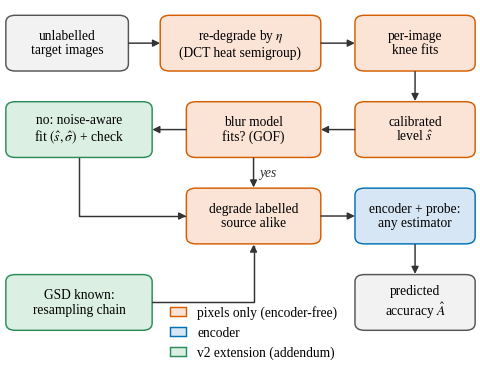

In [13]:
# === 3.4 Figure 4: method schematic ===
FIG4_DATA = dict(
    figsize=[CVPR_COL_W, 2.5],
    boxes=[
        dict(id="tgt", xy=[0.01, 0.81], wh=[0.25, 0.15], text="unlabelled\ntarget images", kind="data"),
        dict(id="redeg", xy=[0.335, 0.81], wh=[0.33, 0.15], text="re-degrade by $\\eta$\n(DCT heat semigroup)", kind="pixel"),
        dict(id="knee", xy=[0.745, 0.81], wh=[0.245, 0.15], text="per-image\nknee fits", kind="pixel"),
        dict(id="cal", xy=[0.745, 0.565], wh=[0.245, 0.15], text="calibrated\nlevel $\\hat{s}$", kind="pixel"),
        dict(id="gof", xy=[0.39, 0.565], wh=[0.275, 0.15], text="blur model\nfits? (GOF)", kind="pixel"),
        dict(id="flag", xy=[0.01, 0.565], wh=[0.30, 0.15], text="no: noise-aware\nfit $(\\hat{s},\\hat\\sigma)$ + check", kind="v2"),
        dict(id="src", xy=[0.39, 0.32], wh=[0.275, 0.15], text="degrade labelled\nsource alike", kind="pixel"),
        dict(id="est", xy=[0.745, 0.32], wh=[0.245, 0.15], text="encoder + probe:\nany estimator", kind="model"),
        dict(id="gsd", xy=[0.01, 0.075], wh=[0.30, 0.15], text="GSD known:\nresampling chain", kind="v2"),
        dict(id="out", xy=[0.745, 0.075], wh=[0.245, 0.15], text="predicted\naccuracy $\\hat{A}$", kind="data"),
    ],
    arrows=[["tgt", "redeg", ""], ["redeg", "knee", ""], ["knee", "cal", ""], ["cal", "gof", ""], ["gof", "flag", ""],
            ["gof", "src", "yes"], ["flag", "src", "", "b", "l"], ["gsd", "src", "", "r", "b"], ["src", "est", ""], ["est", "out", ""]],
    legend=[["pixels only (encoder-free)", "pixel"], ["encoder", "model"], ["v2 extension (addendum)", "v2"]],
    legend_xy=[0.335, -0.035],
)
render("fig4_method", FIG4_DATA)

## Section 4 · Baselines
Eleven label-free accuracy estimators on the same features, probe, conditions and seeds as ours: AC, DoC, ATC, ATC-NE, SAC-ATC (confidence matching), AutoEval, AutoEval-LS, AutoEval-FD, NucNorm, COT and COTT. Identification baselines (single re-blur ratio, batch matching, feature severity regressor) live with the identification variants in Cell 3.2 and Cell 4.3. Cell 4.4 combines everything into one per-condition predictor whose signature has no access to target labels: the baselines, ATC@$\hat s$ and its variants, and the addendum's estimators (the plug-ins X@$\hat s$ for ATC, ATC-NE, DoC, COT, COTT and AE-LS, the v2 noise-aware path and the GSD-aware path).

In [14]:
# === 4.1 Confidence baselines (AC, DoC, ATC, ATC-NE, SAC-ATC) and the AutoEval family (AE, AE-LS, AE-FD) ===
import ot
import scipy.linalg as sla

def entropy(P):
    return -negent(P)

def nuc_score(P):
    """Normalised nuclear norm ||P||_* / sqrt(min(n, K) n) of the softmax matrix (Deng, Suh, Gould and Zheng, ICML 2023)."""
    n, K = P.shape
    return float(np.linalg.norm(P, ord="nuc") / np.sqrt(min(n, K) * n))

def shift_stat(F, F0_mean):
    return float(np.linalg.norm(F.mean(0) - F0_mean) / np.linalg.norm(F0_mean))

class FrechetRef:
    """Gaussian fit of PCA-64 features of clean A2 (StandardScaler then PCA, both fit on clean A2)."""
    def __init__(self, F_A2):
        self.sc = StandardScaler().fit(F_A2)
        k = int(min(64, F_A2.shape[0] - 1, F_A2.shape[1]))
        self.pca = PCA(n_components=k, svd_solver="full", random_state=0).fit(self.sc.transform(F_A2))
        Z = self.pca.transform(self.sc.transform(F_A2))
        self.mu, self.cov = Z.mean(0), np.cov(Z, rowvar=False)
        w, V = np.linalg.eigh(self.cov)
        self.cov_sqrt = (V * np.sqrt(np.clip(w, 0, None))) @ V.T

    def fd(self, F):
        Z = self.pca.transform(self.sc.transform(F))
        mu, cov = Z.mean(0), np.cov(Z, rowvar=False)
        M = self.cov_sqrt @ cov @ self.cov_sqrt                # tr sqrt(C1 C2) = tr sqrt(C1^1/2 C2 C1^1/2)
        tr_sqrt = float(np.sqrt(np.clip(np.linalg.eigvalsh((M + M.T) / 2), 0, None)).sum())
        return float(((mu - self.mu) ** 2).sum() + np.trace(cov) + np.trace(self.cov) - 2 * tr_sqrt)

def meta_record(P, F, acc, F0_mean, fdref, s, family):
    mx, en = maxconf(P), entropy(P)
    return dict(family=family, s=float(s), acc=float(acc), x=[float(mx.mean()), float(en.mean()), shift_stat(F, F0_mean)],
                nuc=nuc_score(P), fd=fdref.fd(F))

def fit_meta_regressors(records):
    """AutoEval: Ridge(1e-2) on [mean max-conf, mean entropy, feature shift]; AE-LS: same on class-reweighted meta-sets;
    AE-LS+s: AE-LS with log1p(s) appended; AE-FD and NucNorm: LinearRegression of accuracy on FD / normalised nuclear norm."""
    ae = [r for r in records if r["family"] == "AE"]
    ls = [r for r in records if r["family"] == "LS"]
    X = lambda rs: np.array([r["x"] for r in rs])
    y = lambda rs: np.array([r["acc"] for r in rs])
    return dict(AE=Ridge(alpha=1e-2).fit(X(ae), y(ae)), AE_LS=Ridge(alpha=1e-2).fit(X(ls), y(ls)),
                AE_LS_s=Ridge(alpha=1e-2).fit(np.c_[X(ls), np.log1p([r["s"] for r in ls])], y(ls)),
                AE_FD=LinearRegression().fit(np.array([[r["fd"]] for r in ae]), y(ae)),
                NucNorm=LinearRegression().fit(np.array([[r["nuc"]] for r in ae]), y(ae)))

def meta_set_plan(nA2, yA2, n_classes, seed, dname, n_meta):
    """Pre-registered meta-set draws (keyed streams): AE = 150 uniform images without replacement; LS = Dirichlet(1)
    class weights, 150 images with replacement; blur s ~ logUniform(0.3, 256); sigma from {0, 0, 1.5, 3, 6}."""
    plans = []
    for fam in ("AE", "LS"):
        for k in range(n_meta):
            r = rng_for(seed, "meta", dname, fam, k)
            m = min(150, nA2)
            if fam == "AE":
                idx = r.choice(nA2, m, replace=False)
            else:
                wc = r.dirichlet(np.ones(n_classes))
                pp = wc[yA2]
                idx = r.choice(nA2, m, replace=True, p=pp / pp.sum())
            s = float(np.exp(r.uniform(np.log(0.3), np.log(256.0))))
            sg = float(r.choice([0.0, 0.0, 1.5, 3.0, 6.0]))
            plans.append(dict(family=fam, k=k, idx=np.sort(idx), s=s, sigma=sg))
    return plans

def clip01(v):
    return float(np.clip(v, 0.0, 1.0))

In [15]:
# === 4.2 COT and COTT (Lu et al., NeurIPS 2023; official-code semantics) with an assignment-equivalence assertion ===
def sample_label_counts(prior, n, rng):
    """Proportional allocation plus a random remainder (official sample_label_dist)."""
    base = np.floor(prior * n).astype(int)
    rem = int(n - base.sum())
    if rem > 0:
        base += np.bincount(rng.choice(len(prior), size=rem, p=prior), minlength=len(prior))
    return base

def _ot_costs(P, counts, full_l1):
    """Exact OT between n one-hot labels (as class counts) and the n softmax rows; per-target-sample transport cost."""
    n = P.shape[0]
    keep = counts > 0
    a = counts[keep].astype(np.float64)
    a = a / a.sum()
    b = np.full(n, 1.0 / n)
    M = (1.0 - P.T[keep]).astype(np.float64)                 # 1/2 ||e_c - p||_1 = 1 - p_c
    if full_l1:
        M = 2.0 * M                                          # ||e_c - p||_1 = 2 (1 - p_c)
    G = ot.emd(a, b, np.ascontiguousarray(M), numItermax=10_000_000)
    return n * (G * M).sum(0)

# COT: predicted error = mean transport cost with cost 1/2 ||e_y - p||_1 (accuracy = 1 - error); COTT: fraction of per-sample
# costs (||e_y - p||_1) above a threshold tau fitted on clean A2 with the true labels. Both are evaluated in Cell 4.4, where the
# target costs are computed once per condition and shared by the baselines and the addendum's plug-ins.
def cott_threshold(P_src, y_src):
    """COTT: per-sample costs (||e_y - p||_1) on clean A2 with the TRUE labels; tau = quantile(costs, 1 - err)."""
    costs = _ot_costs(P_src, np.bincount(y_src, minlength=P_src.shape[1]), True)
    err = float(np.mean(P_src.argmax(1) != y_src))
    return float(np.quantile(costs, 1.0 - err))

from scipy.optimize import linear_sum_assignment
for _t in range(5):
    _r = rng_for("cot_equivalence", _t)
    _n, _C = 14, 4
    _P = _r.dirichlet(np.ones(_C) * 0.7, size=_n)
    _cnt = sample_label_counts(np.full(_C, 1.0 / _C), _n, _r)
    _labels = np.repeat(np.arange(_C), _cnt)
    _cost = 0.5 * np.abs(np.eye(_C)[_labels][:, None, :] - _P[None, :, :]).sum(-1)
    _ri, _ci = linear_sum_assignment(_cost)
    _assign = _cost[_ri, _ci].mean()
    _emd = _ot_costs(_P, _cnt, False).mean()
    assert abs(_assign - _emd) < 1e-9, f"COT transport != assignment ({_assign}, {_emd})"
print("COT: C x n transportation equals the n x n assignment on 5 random cases")

COT: C x n transportation equals the n x n assignment on 5 random cases


In [16]:
# === 4.3 Feature severity regressor (identification baseline id_feat) and confidence-matching surrogates ===
def fit_id_feat(FA2, FA2n):
    """Ridge(alpha=1) on standardised pooled A2 features at all S_ACC levels with sigma in {0, 3}; target log1p(s)."""
    d = FA2.shape[-1]
    X = np.concatenate([FA2.reshape(-1, d), FA2n.reshape(-1, d)])
    y = np.tile(np.repeat(np.log1p(S_ACC), FA2.shape[1]), 2)
    sc = StandardScaler().fit(X)
    rg = Ridge(alpha=1.0).fit(sc.transform(X), y)
    return lambda F: float(np.expm1(np.median(rg.predict(sc.transform(F)))))

def sac_surrogates(P_A2, P_A2n, corr_A2, corr_A2n):
    """SAC grid: A2 at the 10 S_ACC levels x sigma in {0, 3}; stores the max-confidence scores and accuracy of each."""
    sur = []
    for sg, PP, CC in ((0.0, P_A2, corr_A2), (NOISE_DN, P_A2n, corr_A2n)):
        for j, s in enumerate(S_ACC):
            mx = maxconf(PP[j])
            sur.append(dict(s=float(s), sigma=sg, mx=mx, mx_mean=float(mx.mean()), acc=float(CC[j].mean())))
    return sur

In [17]:
# === 4.4 Per-condition predictor: all baselines, ATC@s_hat and variants, plug-ins and the addendum paths (no target labels enter) ===
BASELINES = ["AC", "DoC", "ATC", "ATC_NE", "SAC_ATC", "AE", "AE_LS", "AE_FD", "NucNorm", "COT", "COTT"]
OURS = "ATC_s"                    # frozen v1.0 primary estimator
OURS_V2 = "ATC_v2"                # addendum primary: ATC@s_hat with the noise-aware path
VARIANTS = ["PT", "PT_anchor", "DoC_m", "ATC_NE_m", "AE_LS_s", "COT_m", "COTT_m", "ATC_m2", "ATC_m_v11", "ATC_m_noGOF"]
V2_METHODS = ["ATC_v2", "DoC_v2", "ATC_NE_v2", "COT_v2", "COTT_v2", "PT_v2", "AE_LS_v2"]
GSD_METHODS = ["ATC_g", "DoC_g", "ATC_NE_g", "COT_g", "COTT_g", "PT_g"]
ORACLES = ["oracle_PT", "oracle_ATC"]
ESTIMATORS12 = [OURS] + BASELINES
PLUGIN_PAIRS = [("ATC", "ATC_s", "ATC_v2", "ATC_g"), ("ATC_NE", "ATC_NE_m", "ATC_NE_v2", "ATC_NE_g"), ("DoC", "DoC_m", "DoC_v2", "DoC_g"),
                ("COT", "COT_m", "COT_v2", "COT_g"), ("COTT", "COTT_m", "COTT_v2", "COTT_g"), ("AE_LS", "AE_LS_s", "AE_LS_v2", None)]
assert [list(p[:2]) for p in PLUGIN_PAIRS] == PREREG_V2["plugin"]["pairs"], "plug-in pairs differ from the addendum"
_FAMILY_KEYS = ("ATC", "DoC", "ATC_NE", "COT", "COTT", "PT")

def _cot_cost(P, prior, rng):
    """Mean COT transport cost (= the COT error estimate before clipping)."""
    return float(_ot_costs(P, sample_label_counts(prior, P.shape[0], rng), False).mean())

def plugin_family(ctx, P_t, P_m, c_m, key, cost_t, cott_costs_t):
    """Every plug-in estimator calibrated on A2 degraded to one identified level (P_m, correctness c_m). COT@level calibrates
    the COT error on the degraded source (DoC-style); COTT@level re-fits the COTT threshold there. Source-side OT quantities
    are cached per level key; the target costs are shared with the COT and COTT baselines (same random streams)."""
    acc_m = float(c_m.mean())
    mx_t, mx_m = maxconf(P_t), maxconf(P_m)
    cache = ctx["level_cache"]
    if key not in cache:
        v = ctx["valid"]
        Pv, yv = P_m[v], ctx["ycol"][v]
        cache[key] = dict(cost=_cot_cost(Pv, ctx["prior"], rng_for("cot_src", *key)) if len(Pv) else np.nan,
                          tau=cott_threshold(Pv, yv) if len(Pv) else np.nan)
    q = cache[key]
    return dict(ATC=atc_predict(mx_t, mx_m, acc_m), DoC=clip01(acc_m - (mx_m.mean() - mx_t.mean())),
                ATC_NE=atc_predict(negent(P_t), negent(P_m), acc_m), PT=acc_m,
                COT=clip01(acc_m + q["cost"] - cost_t), COTT=clip01(1.0 - float(np.mean(cott_costs_t > q["tau"]))))

def predict_condition(ctx, P_t, F_t, cond, mask_key, rng_key, do_o1):
    """Every prediction for one (encoder, condition). ctx holds source-side quantities only; nothing here sees yB."""
    mx_t, ne_t = maxconf(P_t), negent(P_t)
    out = dict(AC=float(mx_t.mean()),
               DoC=clip01(ctx["acc0"] - (ctx["mx0"].mean() - mx_t.mean())),
               ATC=atc_predict(mx_t, ctx["mx0"], ctx["acc0"]),
               ATC_NE=atc_predict(ne_t, ctx["ne0"], ctx["acc0"]))
    sur = min(ctx["sur"], key=lambda z: abs(z["mx_mean"] - mx_t.mean()))
    out.update(SAC_ATC=atc_predict(mx_t, sur["mx"], sur["acc"]), sac_s=sur["s"], sac_sigma=sur["sigma"])
    x = [float(mx_t.mean()), float(entropy(P_t).mean()), shift_stat(F_t, ctx["F0_mean"])]
    reg = ctx["reg"]
    cost_t = _cot_cost(P_t, ctx["prior"], rng_for(*rng_key, "cot"))
    cott_costs_t = _ot_costs(P_t, sample_label_counts(ctx["prior"], P_t.shape[0], rng_for(*rng_key, "cott")), True)
    out.update(AE=clip01(reg["AE"].predict([x])[0]), AE_LS=clip01(reg["AE_LS"].predict([x])[0]),
               AE_FD=clip01(reg["AE_FD"].predict([[ctx["fdref"].fd(F_t)]])[0]),
               NucNorm=clip01(reg["NucNorm"].predict([[nuc_score(P_t)]])[0]),
               COT=clip01(1.0 - cost_t), COTT=clip01(1.0 - float(np.mean(cott_costs_t > ctx["cott_tau"]))))
    # frozen v1.0 level: ATC@s_hat (primary) and its registered variants, plus the COT/COTT plug-ins of the addendum
    P_m, c_m = ctx["src_probs"](cond["s_use"], cond["sig_use"], ("main", cond["cid"]))
    out.update(ours_from_source(P_t, P_m, c_m, ctx["anchor"](mask_key)))
    out["DoC_m"] = clip01(out["DoC_m"])
    fam = plugin_family(ctx, P_t, P_m, c_m, ("lvl", round(float(cond["s_use"]), 6), round(float(cond["sig_use"]), 6)), cost_t, cott_costs_t)
    out.update(COT_m=fam["COT"], COTT_m=fam["COTT"])
    out["AE_LS_s"] = clip01(reg["AE_LS_s"].predict([x + [float(np.log1p(cond["s_use"]))]])[0])
    # addendum v2 level: identical to v1.0 when the blur model fits; the v1.1 tail fit (s_v11, sigma_v11) when it does not
    if not cond["flagged"]:
        out.update(ATC_v2=out["ATC_s"], DoC_v2=out["DoC_m"], ATC_NE_v2=out["ATC_NE_m"], COT_v2=out["COT_m"], COTT_v2=out["COTT_m"],
                   PT_v2=out["PT"], AE_LS_v2=out["AE_LS_s"])
    elif np.isfinite(cond.get("s_v11", np.nan)):
        s2, g2 = float(cond["s_v11"]), float(cond["sig_v11"])
        Pv, cv = ctx["src_probs"](s2, g2, ("v2", cond["cid"]))
        f2 = plugin_family(ctx, P_t, Pv, cv, ("lvl", round(s2, 6), round(g2, 6)), cost_t, cott_costs_t)
        out.update({k + "_v2": f2[k] for k in _FAMILY_KEYS})
        out["AE_LS_v2"] = clip01(reg["AE_LS_s"].predict([x + [float(np.log1p(s2))]])[0])
    else:
        out.update({m: np.nan for m in V2_METHODS})
    # registered noise-path variants (O1): two-stage subtraction, v1.1 tail fit (= the v2 level), no GOF
    if not cond["flagged"]:
        out.update(ATC_m2=out["ATC_s"], ATC_m_v11=out["ATC_s"], ATC_m_noGOF=out["ATC_s"])
    else:
        out["ATC_m_v11"] = out["ATC_v2"]
        if do_o1:
            for key, (s, sg) in dict(ATC_m2=(cond["s_use2"], cond["sig_use2"]), ATC_m_noGOF=(cond["s_hat"], 0.0)).items():
                if np.isfinite(s):
                    Pv, cv = ctx["src_probs"](s, sg, (key, cond["cid"]))
                    out[key] = atc_predict(mx_t, maxconf(Pv), float(cv.mean()))
                else:
                    out[key] = np.nan
        else:
            out.update(ATC_m2=np.nan, ATC_m_noGOF=np.nan)
    # addendum GSD path (LandCover.ai 25 -> 50 cm): the source passes through the target's resampling chain
    if np.isfinite(cond.get("s_gsd", np.nan)) and ctx.get("src_probs_chain") is not None:
        Pg, cg = ctx["src_probs_chain"](cond["s_gsd"], ("gsd", cond["cid"]))
        fg = plugin_family(ctx, P_t, Pg, cg, ("gsd", round(float(cond["s_gsd"]), 6)), cost_t, cott_costs_t)
        out.update({k + "_g": fg[k] for k in _FAMILY_KEYS})
    else:
        out.update({m: np.nan for m in GSD_METHODS})
    if cond.get("s0") is not None and np.isfinite(cond.get("s0", np.nan)) and cond.get("suite") in ("syn", "ls"):
        P_o, c_o = ctx["src_probs"](cond["s0"], cond["sigma"], ("oracle", cond["cid"]))
        out.update(oracle_PT=float(c_o.mean()), oracle_ATC=atc_predict(mx_t, maxconf(P_o), float(c_o.mean())))
    else:
        out.update(oracle_PT=np.nan, oracle_ATC=np.nan)
    out["id_feat"] = ctx["id_feat"](F_t)
    return out
print("baselines and per-condition predictor ready:", ", ".join(BASELINES), "| plug-ins:", ", ".join(p[1] for p in PLUGIN_PAIRS))

baselines and per-condition predictor ready: AC, DoC, ATC, ATC_NE, SAC_ATC, AE, AE_LS, AE_FD, NucNorm, COT, COTT | plug-ins: ATC_s, ATC_NE_m, DoC_m, COT_m, COTT_m, AE_LS_s


## Section 5 · Datasets
Eleven public datasets, downloaded without credentials (3 attempts with exponential backoff, plus a fallback route for each source), with licence strings read at runtime where the source exposes them, integrity checks against the expected counts, and the pre-registered per-seed splits: every scene dataset is pooled and split 60/20/20 per class with keyed streams, then the per-class quotas are drawn into A1 (probe), A2 (source calibration) and B (target). LandCover.ai is split by orthophoto. A failed dataset is reported in every affected verdict, never dropped silently. The cell at the end runs the data-dependent assumption checks.

In [18]:
# === 5.1 Registry, quotas, download helpers with retries and fallbacks ===
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
IMG_EXTS = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

DS_INFO = {
    "resisc45":   dict(display="RESISC45", kind="hf_zip", repo="torchgeo/resisc45", file="NWPU-RESISC45.zip", expected=31500, n_classes=45, quota=(60, 25, 25), rs=True),
    "ucm":        dict(display="UC Merced", kind="hf_zip", repo="torchgeo/ucmerced", file="UCMerced_LandUse.zip", expected=2100, n_classes=21, quota=(40, 20, 20), rs=True),
    "patternnet": dict(display="PatternNet", kind="hf_zip", repo="torchgeo/PatternNet", file="PatternNet.zip", expected=30400, n_classes=38, quota=(30, 15, 15), rs=True),
    "whu_rs19":   dict(display="WHU-RS19", kind="hf_parquet", repo="jonathan-roberts1/WHU-RS19", expected=1005, n_classes=19, quota=(30, 10, 10), rs=True),
    "rsscn7":     dict(display="RSSCN7", kind="hf_parquet", repo="jonathan-roberts1/RSSCN7", expected=2800, n_classes=7, quota=(120, 60, 60), rs=True),
    "optimal31":  dict(display="Optimal-31", kind="hf_parquet", repo="jonathan-roberts1/Optimal-31", expected=1860, n_classes=31, quota=(30, 12, 12), rs=True),
    "clrs":       dict(display="CLRS", kind="hf_parquet", repo="jonathan-roberts1/CLRS", expected=15000, n_classes=25, quota=(30, 15, 15), rs=True),
    "imagenette": dict(display="Imagenette", kind="url_tgz", url="https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz",
                       expected=13394, n_classes=10, quota=(300, 100, 100), rs=False, source="https://github.com/fastai/imagenette"),
    "dtd":        dict(display="DTD", kind="tv_dtd", expected=5640, n_classes=47, quota=(30, 15, 15), rs=False,
                       source="https://www.robots.ox.ac.uk/~vgg/data/dtd/"),
    "pets":       dict(display="Oxford-IIIT Pets", kind="tv_pets", expected=7349, n_classes=37, quota=(30, 15, 15), rs=False,
                       source="https://www.robots.ox.ac.uk/~vgg/data/pets/"),
}
for _n, _i in DS_INFO.items():
    _i.setdefault("source", f"https://huggingface.co/datasets/{_i.get('repo')}")
DISPLAY_ORDER = ["resisc45", "ucm", "patternnet", "whu_rs19", "rsscn7", "optimal31", "clrs", "imagenette", "dtd", "pets"]  # RS, then natural
assert sorted(DISPLAY_ORDER) == sorted(EVAL_DATASETS) == sorted(DS_INFO) and set(SEED_DATASETS) <= set(EVAL_DATASETS)
LCAI_URL = "https://landcover.ai.linuxpolska.com/download/landcover.ai.v1.zip"
LCAI_LICENCE = "CC BY-NC-SA 4.0 (LandCover.ai v1, https://landcover.ai.linuxpolska.com/)"
if DRY_RUN:
    for _n, _i in DS_INFO.items():
        _i.update(quota=(8, 6, 10), expected=6 * 50, n_classes=6)
LC_COUNTS = dict(phys25=400, mech=120, r1=200, lc_A1=800, lc_A2=600, phys50=300, lc_P50=300) if not DRY_RUN else \
            dict(phys25=60, mech=24, r1=40, lc_A1=60, lc_A2=48, phys50=40, lc_P50=40)

def retry(fn, what, attempts=3, base_wait=10):
    for a in range(attempts):
        try:
            return fn()
        except Exception as e:
            print(f"  [{what}] attempt {a + 1}/{attempts} failed: {type(e).__name__}: {str(e)[:200]}")
            if a < attempts - 1:
                time.sleep(base_wait * 2 ** a)
    raise RuntimeError(f"{what}: all {attempts} attempts failed")

def http_download(url, dst):
    import urllib.request
    def _get():
        with urllib.request.urlopen(url, timeout=300) as r, open(dst + ".part", "wb") as f:
            shutil.copyfileobj(r, f, length=1 << 22)
        os.replace(dst + ".part", dst)
    if not os.path.exists(dst):
        retry(_get, f"download {os.path.basename(dst)}")
    return dst

def safe_extract(archive, root):
    if archive.lower().endswith(".zip"):
        with zipfile.ZipFile(archive) as z:
            z.extractall(root)
    else:
        with tarfile.open(archive) as t:
            try:
                t.extractall(root, filter="data")
            except TypeError:
                t.extractall(root)

def hf_licence(repo):
    try:
        from huggingface_hub import HfApi
        cd = getattr(HfApi().dataset_info(repo), "card_data", None)
        lic = cd.get("license") if cd is not None else None
        if lic:
            return (lic if isinstance(lic, str) else ", ".join(lic)) + " (HF dataset card)"
    except Exception:
        pass
    return None

In [19]:
# === 5.2 Acquisition of the ten scene datasets (or synthetic stand-ins when DRY_RUN) + integrity + licences ===
def pool_from(name, kind, refs, labels, obj, licence):
    classes = sorted(set(labels))
    cidx = {c: i for i, c in enumerate(classes)}
    return dict(name=name, kind=kind, refs=list(refs), y=np.array([cidx[l] for l in labels], dtype=np.int64),
                classes=classes, obj=obj, licence=licence, count=len(refs))

def _is_image_file(p):
    b = os.path.basename(p)
    return p.lower().endswith(IMG_EXTS) and "__MACOSX" not in p and not b.startswith("._")

def acquire_hf_zip(name, info):
    root = os.path.join(DATA_DIR, name)
    os.makedirs(root, exist_ok=True)
    marker = os.path.join(root, ".extracted")
    if not os.path.exists(marker):
        zp = os.path.join(root, info["file"])
        try:
            from huggingface_hub import hf_hub_download
            zp = retry(lambda: hf_hub_download(info["repo"], info["file"], repo_type="dataset", local_dir=root), f"{name} hf_hub_download")
        except Exception as e:
            print(f"  [{name}] hub download failed ({e}); falling back to the direct resolve URL")
            http_download(f"https://huggingface.co/datasets/{info['repo']}/resolve/main/{info['file']}", zp)
        safe_extract(zp, root)
        os.remove(zp)
        open(marker, "w").close()
    paths = sorted(p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True) if _is_image_file(p))
    labels = [os.path.basename(os.path.dirname(p)) for p in paths]
    return pool_from(name, "files", paths, labels, None, hf_licence(info["repo"]) or f"see {info['source']}; verify before redistribution")

def acquire_hf_parquet(name, info):
    lic = hf_licence(info["repo"]) or f"see {info['source']}; verify before redistribution"
    try:
        from datasets import load_dataset
        ds = retry(lambda: load_dataset(info["repo"], split="train", cache_dir=os.path.join(DATA_DIR, "hf_datasets")), f"{name} load_dataset")
        names = getattr(ds.features["label"], "names", None)
        lab = list(ds["label"])
        labels = [names[l] for l in lab] if names else [str(l) for l in lab]
        return pool_from(name, "hf", list(range(len(ds))), labels, ds, lic)
    except Exception as e:
        print(f"  [{name}] datasets.load_dataset failed ({type(e).__name__}); falling back to the parquet shards")
        from huggingface_hub import list_repo_files, hf_hub_download
        root = os.path.join(DATA_DIR, name)
        files = [f for f in retry(lambda: list_repo_files(info["repo"], repo_type="dataset"), f"{name} list") if f.endswith(".parquet")]
        frames = [pd.read_parquet(retry(lambda f=f: hf_hub_download(info["repo"], f, repo_type="dataset", local_dir=root), f"{name} {f}"))
                  for f in sorted(files)]
        df = pd.concat(frames, ignore_index=True)
        blobs = [im["bytes"] if isinstance(im, dict) else im for im in df["image"]]
        return pool_from(name, "bytes", list(range(len(df))), [str(v) for v in df["label"]], blobs, lic)

def acquire_url_tgz(name, info):
    root = os.path.join(DATA_DIR, name)
    os.makedirs(root, exist_ok=True)
    marker = os.path.join(root, ".extracted")
    if not os.path.exists(marker):
        tp = http_download(info["url"], os.path.join(root, os.path.basename(info["url"])))
        safe_extract(tp, root)
        os.remove(tp)
        open(marker, "w").close()
    paths = sorted(p for p in glob.glob(os.path.join(root, "*", "*", "*", "*")) if _is_image_file(p))
    labels = [os.path.basename(os.path.dirname(p)) for p in paths]
    return pool_from(name, "files", paths, labels, None, f"see {info['source']}; verify before redistribution")

def acquire_tv(name, info):
    import torchvision
    root = os.path.join(DATA_DIR, name)
    if name == "dtd":
        parts = {k: retry(lambda k=k: torchvision.datasets.DTD(root, split=k, partition=1, download=True), f"dtd {k}") for k in ("train", "val", "test")}
    else:
        parts = {k: retry(lambda k=k: torchvision.datasets.OxfordIIITPet(root, split=k, target_types="category", download=True), f"pets {k}")
                 for k in ("trainval", "test")}
    refs, labels = [], []
    for k, dsk in parts.items():
        labs = getattr(dsk, "_labels", None)
        labs = labs if labs is not None else [dsk[j][1] for j in range(len(dsk))]
        for j, l in enumerate(labs):
            refs.append((k, j))
            labels.append(dsk.classes[l])
    return pool_from(name, "tv", refs, labels, parts, f"see {info['source']}; verify before redistribution")

def synth_pool(name, n_classes=6, per_class=50):
    """DRY_RUN stand-in: class = spectral slope (keyed by class name, so shared names look alike across datasets)."""
    shared = 3 if name in ("resisc45", "ucm", "patternnet") else 0
    classes = [f"shared{chr(97 + k)}" if k < shared else f"{name}{chr(97 + k)}" for k in range(n_classes)]
    refs = [(name, c, j) for c in classes for j in range(per_class)]
    return pool_from(name, "synth", refs, [r[1] for r in refs], None, "synthetic (DRY_RUN)")

def synth_image(ref):
    dname, cname, j = ref
    r = rng_for("synth_img", dname, cname, j)
    alpha = 1.5 + 0.18 * (stable_hash(cname) % 7)
    s_int = 0.4 + 0.15 * (stable_hash(dname) % 4)
    c = powerlaw_coeffs(alpha, 1, r, channels=1)[0, 0]
    chans = np.stack([0.8 * c + 0.2 * powerlaw_coeffs(alpha, 1, r, channels=1)[0, 0] for _ in range(3)]) * np.exp(-0.5 * s_int * LAM)
    img = idct2(chans)
    img = (img - img.min()) / (np.ptp(img) + 1e-9) * 200 + 20
    return np.round(img).astype(np.uint8).transpose(1, 2, 0)

ACQUIRE = dict(hf_zip=acquire_hf_zip, hf_parquet=acquire_hf_parquet, url_tgz=acquire_url_tgz, tv_dtd=acquire_tv, tv_pets=acquire_tv)
POOLS, DATASET_STATUS = {}, {}

def acquire_all(names):
    """Download (or synthesise) only the datasets that the pending units of this session read."""
    for name in [n for n in DISPLAY_ORDER if n in names]:
        info = DS_INFO[name]
        t0 = time.time()
        try:
            pool = synth_pool(name) if DRY_RUN else ACQUIRE[info["kind"]](name, info)
            n, exp = pool["count"], info["expected"]
            if n < 0.9 * exp:
                raise RuntimeError(f"only {n} images (< 90% of the expected {exp})")
            if len(pool["classes"]) != info["n_classes"]:
                print(f"  WARNING {name}: {len(pool['classes'])} classes (expected {info['n_classes']})")
            if n != exp:
                print(f"  WARNING {name}: {n} images (expected {exp})")
            POOLS[name] = pool
            DATASET_STATUS[name] = dict(status="loaded", images=n, classes=len(pool["classes"]), licence=pool["licence"],
                                        seconds=round(time.time() - t0, 1))
        except Exception as e:
            DATASET_STATUS[name] = dict(status="FAILED", reason=f"{type(e).__name__}: {str(e)[:300]}", seconds=round(time.time() - t0, 1))
            runtime_decision(f"dataset {name} failed to load and is reported as missing in every affected verdict: {e}")
        print(f"{name:<11} {DATASET_STATUS[name]}")

if MODE == "full":
    acquire_all(DATA_NEEDED)
    if not [n for n in DATA_NEEDED if n in DS_INFO]:
        print("no scene dataset is needed in this session (every unit that reads one is complete)")

NWPU-RESISC45.zip: reconstructing file:   0%|          |  0.00B /  427MB            

NWPU-RESISC45.zip: downloading bytes:           |  0.00B            

resisc45    {'status': 'loaded', 'images': 31500, 'classes': 45, 'licence': 'cc-by-nc-4.0 (HF dataset card)', 'seconds': 10.6}


UCMerced_LandUse.zip: reconstructing file:   0%|          |  0.00B /  332MB            

UCMerced_LandUse.zip: downloading bytes:           |  0.00B            

ucm         {'status': 'loaded', 'images': 2100, 'classes': 21, 'licence': 'cc0-1.0 (HF dataset card)', 'seconds': 6.2}


... (33 outputs left out)

100%|██████████| 625M/625M [00:18<00:00, 34.0MB/s] 


dtd         {'status': 'loaded', 'images': 5640, 'classes': 47, 'licence': 'see https://www.robots.ox.ac.uk/~vgg/data/dtd/; verify before redistribution', 'seconds': 25.3}


100%|██████████| 792M/792M [00:18<00:00, 41.7MB/s] 
100%|██████████| 19.2M/19.2M [00:01<00:00, 14.3MB/s]


pets        {'status': 'loaded', 'images': 7349, 'classes': 37, 'licence': 'see https://www.robots.ox.ac.uk/~vgg/data/pets/; verify before redistribution', 'seconds': 38.5}


In [20]:
# === 5.3 Image loading (shortest side 256 bicubic, centre crop 224, uint8) and per-seed splits with quotas ===
def _crop224(im):
    im = im.convert("RGB")
    w, h = im.size
    sc = 256.0 / min(w, h)
    im = im.resize((max(256, round(w * sc)), max(256, round(h * sc))), Image.BICUBIC)
    w, h = im.size
    l, t = (w - TILE) // 2, (h - TILE) // 2
    return np.asarray(im.crop((l, t, l + TILE, t + TILE)), dtype=np.uint8)

def load_ref(pool, ref):
    kind = pool["kind"]
    if kind == "synth":
        return synth_image(ref)
    if kind == "files":
        with Image.open(ref) as im:
            return _crop224(im)
    if kind == "hf":
        return _crop224(pool["obj"][int(ref)]["image"])
    if kind == "bytes":
        with Image.open(io.BytesIO(pool["obj"][int(ref)])) as im:
            return _crop224(im)
    split, j = ref
    return _crop224(pool["obj"][split][j][0])

def load_images(pool, idx):
    """uint8 (n, 224, 224, 3); images with a (near-)constant channel are dropped (logged)."""
    out = np.empty((len(idx), TILE, TILE, 3), np.uint8)
    for i, k in enumerate(idx):
        out[i] = load_ref(pool, pool["refs"][k])
    keep = out.reshape(len(out), -1, 3).std(1).min(1) >= 0.5
    if not keep.all():
        runtime_decision(f"{pool['name']}: dropped {int((~keep).sum())} degenerate images (a channel with std < 0.5 DN)")
    return out[keep], np.asarray(idx)[keep]

def make_split(pool, dname, seed):
    """Pooled stratified 60/20/20 per class (stream (seed,'split',d)), then per-class quotas (stream (seed,'quota',d,part))."""
    y = pool["y"]
    parts = {"train": [], "val": [], "test": []}
    r = rng_for(seed, "split", dname)
    for c in range(len(pool["classes"])):
        idx = r.permutation(np.nonzero(y == c)[0])
        a = int(0.6 * len(idx))
        b = a + int(0.2 * len(idx))
        parts["train"] += idx[:a].tolist()
        parts["val"] += idx[a:b].tolist()
        parts["test"] += idx[b:].tolist()
    out = {}
    for part, key, per in zip(("train", "val", "test"), ("A1", "A2", "B"), DS_INFO[dname]["quota"]):
        rq = rng_for(seed, "quota", dname, part)
        pidx = np.array(parts[part])
        sel = []
        for c in range(len(pool["classes"])):
            ci = pidx[y[pidx] == c]
            if len(ci):
                sel += rq.choice(ci, min(per, len(ci)), replace=False).tolist()
        out[key] = sorted(sel)
    return out

def load_split(dname, seed):
    pool = POOLS[dname]
    sp = make_split(pool, dname, seed)
    U = dict(dataset=dname, seed=seed, classes=pool["classes"])
    for key in ("A1", "A2", "B"):
        imgs, kept = load_images(pool, sp[key])
        U[key], U["y" + key], U["idx" + key] = imgs, pool["y"][kept], kept
    return U

In [21]:
# === 5.4 LandCover.ai: orthophotos, resolution classes, orthophoto-level split, tiles for physics, mechanism and the real shift ===
LC = {}

def _synth_ortho(name, size):
    r = rng_for("synth_ortho", name)
    k = np.arange(size)
    lam1 = 4.0 * np.sin(np.pi * k / (2 * size)) ** 2
    lam = lam1[:, None] + lam1[None, :]
    amp = np.zeros_like(lam)
    amp[lam > 0] = lam[lam > 0] ** (-0.5)
    base = r.standard_normal((size, size)) * amp
    chans = np.stack([0.85 * base + 0.15 * r.standard_normal((size, size)) * amp for _ in range(3)]) * np.exp(-0.5 * 0.6 * lam)
    img = sfft.idctn(chans, type=2, norm="ortho", axes=(-2, -1))
    img = np.round((img - img.min()) / (np.ptp(img) + 1e-9) * 200 + 25).astype(np.uint8).transpose(1, 2, 0)
    smooth = sfft.idctn(r.standard_normal((size, size)) * np.exp(-200.0 * lam), type=2, norm="ortho")
    q = np.quantile(smooth, [0.5, 0.8, 0.9, 0.95])
    mask = np.digitize(smooth, q)
    mask = np.array([0, 2, 3, 1, 4])[mask].astype(np.uint8)
    return img, mask

def read_rgb(path):
    if DRY_RUN:
        return LC["synth"][path][0]
    try:
        import rasterio
        with rasterio.open(path) as ds:
            return ds.read([1, 2, 3]).transpose(1, 2, 0)
    except Exception:
        with Image.open(path) as im:
            return np.asarray(im.convert("RGB"))

def read_mask(path):
    if DRY_RUN:
        return LC["synth"][path][1]
    mp = LC["masks"][os.path.basename(path)]
    try:
        import rasterio
        with rasterio.open(mp) as ds:
            return ds.read(1)
    except Exception:
        with Image.open(mp) as im:
            return np.asarray(im)

def tif_res(path):
    if DRY_RUN:
        return LC["synth"][path][2]
    try:
        import rasterio
        with rasterio.open(path) as ds:
            return float(abs(ds.res[0]))
    except Exception:
        with Image.open(path) as im:
            return 0.25 if im.size[0] > 6000 else 0.5

def acquire_landcover():
    if DRY_RUN:
        LC["synth"] = {}
        for i in range(41):
            p = f"synth_lcai_{i:02d}.tif"
            img, mask = _synth_ortho(p, 640 if i < 33 else 448)
            LC["synth"][p] = (img, mask, 0.25 if i < 33 else 0.5)
        imgs = sorted(LC["synth"])
    else:
        root = os.path.join(DATA_DIR, "landcoverai")
        img_dir, msk_dir = os.path.join(root, "images"), os.path.join(root, "masks")
        for d in (img_dir, msk_dir):
            os.makedirs(d, exist_ok=True)
        if len(glob.glob(os.path.join(img_dir, "*.tif"))) < 41 or len(glob.glob(os.path.join(msk_dir, "*.tif"))) < 41:
            zp = http_download(LCAI_URL, os.path.join(root, "landcover.ai.v1.zip"))
            with zipfile.ZipFile(zp) as z:
                for m in z.namelist():
                    if m.lower().endswith(".tif"):
                        dst = os.path.join(msk_dir if "mask" in m.lower() else img_dir, os.path.basename(m))
                        with z.open(m) as s, open(dst, "wb") as d:
                            shutil.copyfileobj(s, d, length=1 << 22)
            os.remove(zp)
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.tif")))
        LC["masks"] = {os.path.basename(p): p for p in glob.glob(os.path.join(msk_dir, "*.tif"))}
        assert len(imgs) == 41 and all(os.path.basename(p) in LC["masks"] for p in imgs), "LandCover.ai image/mask pairing failed"
    res = {p: tif_res(p) for p in imgs}
    P25, P50 = [p for p in imgs if res[p] < 0.375], [p for p in imgs if res[p] >= 0.375]
    assert len(P25) == 33 and len(P50) == 8, f"LandCover.ai layout differs: {len(P25)} x 25 cm, {len(P50)} x 50 cm"
    perm = rng_for(0, "lcai_split").permutation(len(P25))
    LC["split"] = dict(A1=[P25[i] for i in perm[:8]], A2=[P25[i] for i in perm[8:16]], B=[P25[i] for i in perm[16:]], P50=P50)
    LC["ortho_ids"] = {p: i for i, p in enumerate(imgs)}

def _sample_from(a, mk, r, n, labelled):
    H, W = a.shape[:2]
    T, Y, tries = [], [], 0
    while len(T) < n and tries < 300 * max(n, 1):
        tries += 1
        y, x = int(r.integers(0, H - TILE + 1)), int(r.integers(0, W - TILE + 1))
        t = a[y:y + TILE, x:x + TILE]
        if t.std() < 3.0 or (t.max(-1) == 0).mean() > 0.01 or t.reshape(-1, 3).std(0).min() < 0.5:
            continue
        if labelled:
            dom = int(np.bincount(mk[y:y + TILE, x:x + TILE].ravel(), minlength=5)[:5].argmax())
            if dom in (1, 4):                                   # building- or road-dominated tiles are excluded
                continue
            Y.append({0: 0, 2: 1, 3: 2}[dom])
        else:
            Y.append(-1)
        T.append(t.copy())
    return T, Y

def lc_tiles(group, specs):
    """One read per orthophoto; specs = [(name, n_total, labelled, upsample)]. Tiles are drawn with keyed streams."""
    paths = LC["split"][group]
    out = {s[0]: ([], [], []) for s in specs}
    need_mask = any(s[2] for s in specs)
    for p in paths:
        a = read_rgb(p)
        mk = np.clip(read_mask(p), 0, 4).astype(np.uint8) if need_mask else np.zeros(a.shape[:2], np.uint8)
        gid = LC["ortho_ids"][p]
        for name, n_total, labelled, up in specs:
            per = int(math.ceil(n_total / len(paths)))
            aa, mm = a, mk
            if up != 1:
                aa = np.asarray(Image.fromarray(a).resize((a.shape[1] * up, a.shape[0] * up), Image.BICUBIC))
                mm = np.asarray(Image.fromarray(mk).resize((mk.shape[1] * up, mk.shape[0] * up), Image.NEAREST))
            T, Y = _sample_from(aa, mm, rng_for(0, "lcai_tiles", name, os.path.basename(p)), per, labelled)
            out[name][0].extend(T)
            out[name][1].extend(Y)
            out[name][2].extend([gid] * len(T))
        del a, mk
    res = {}
    for name, n_total, _, _ in specs:
        T, Y, G = out[name]
        sel = np.sort(rng_for(0, "lcai_subsample", name).permutation(len(T))[:n_total])
        res[name] = dict(x=np.stack([T[i] for i in sel]), y=np.array(Y)[sel], g=np.array(G)[sel])
    return res

def lc_full_ortho_grid(path, thumb_w=None):
    """Non-overlapping 224 tiles over one held-out orthophoto (for the maps of Fig. 2) and an area-averaged thumbnail."""
    a = read_rgb(path)
    H, W = a.shape[:2]
    nr, nc = H // TILE, W // TILE
    tiles = a[:nr * TILE, :nc * TILE].reshape(nr, TILE, nc, TILE, 3).transpose(0, 2, 1, 3, 4).reshape(-1, TILE, TILE, 3)
    f = max(1, int(round(W / (thumb_w or (480 if not DRY_RUN else 160)))))
    th = a[:(H // f) * f, :(W // f) * f].reshape(H // f, f, W // f, f, 3).mean((1, 3)).astype(np.uint8)
    return dict(tiles=tiles, nr=nr, nc=nc, thumb=th, path=os.path.basename(path), shape=[H, W])

def prepare_landcover():
    cache = os.path.join(DATA_DIR, "lcai_tiles.pkl")
    if os.path.exists(cache):
        LC.update(load_pickle(cache))
        return
    acquire_landcover()
    tiles = {}
    tiles.update(lc_tiles("B", [("phys25", LC_COUNTS["phys25"], False, 1), ("mech", LC_COUNTS["mech"], False, 1)]))
    tiles.update(lc_tiles("A1", [("lc_A1", LC_COUNTS["lc_A1"], True, 1)]))
    tiles.update(lc_tiles("A2", [("lc_A2", LC_COUNTS["lc_A2"], True, 1)]))
    tiles.update(lc_tiles("P50", [("phys50", LC_COUNTS["phys50"], False, 1), ("lc_P50", LC_COUNTS["lc_P50"], True, 2)]))
    grid = lc_full_ortho_grid(sorted(LC["split"]["B"])[0])
    keep = dict(tiles=tiles, grid=grid, split={k: [os.path.basename(p) for p in v] for k, v in LC["split"].items()},
                ortho_ids={os.path.basename(p): i for p, i in LC["ortho_ids"].items()})
    save_pickle(cache, keep)
    LC.update(keep)

LCAI_STATUS = {}
if MODE == "full" and "landcoverai" in DATA_NEEDED:
    t0 = time.time()
    try:
        prepare_landcover()
        LCAI_STATUS = dict(status="loaded", seconds=round(time.time() - t0, 1),
                           counts={k: int(len(v["x"])) for k, v in LC["tiles"].items()}, licence=LCAI_LICENCE)
    except Exception as e:
        LCAI_STATUS = dict(status="FAILED", reason=f"{type(e).__name__}: {str(e)[:300]}")
        runtime_decision(f"LandCover.ai failed ({e}); B2, the 25->50 cm real shift and the LandCover.ai mechanism screen are reported as missing")
    print("LandCover.ai:", LCAI_STATUS)
elif MODE == "full":
    LCAI_STATUS = dict(PRIOR_STATE.get("LCAI_STATUS") or {}) or dict(status="not needed in this session")
    print("LandCover.ai not needed in this session (every unit that reads it is complete)")

LandCover.ai: {'status': 'loaded', 'seconds': 152.9, 'counts': {'phys25': 400, 'mech': 120, 'lc_A1': 800, 'lc_A2': 600, 'phys50': 300, 'lc_P50': 300}, 'licence': 'CC BY-NC-SA 4.0 (LandCover.ai v1, https://landcover.ai.linuxpolska.com/)'}


In [22]:
# === 5.5 Data-dependent assumption checks (A3, A4, class balance, A6 permuted labels, frozen-encoder checksum: Cell 6.2) ===
def evaluate_condition(ctx, P_t, F_t, y_t, cond, mask_key, rng_key, do_o1):
    """Truth from the target labels; predictions from predict_condition, which never receives the labels."""
    pred = predict_condition(ctx, P_t, F_t, cond, mask_key, rng_key, do_o1)
    pred["truth"] = float(np.mean(ctx["classes"][P_t.argmax(1)] == y_t))
    return pred

def _toy_ctx(rng, C=4, d=16, n=80):
    """Small source-side context from random features, used only by the A6 permuted-label test."""
    Fs = rng.standard_normal((n, d))
    ys = rng.integers(0, C, n)
    probe = LogisticRegression(max_iter=500).fit(Fs, ys)
    P0 = probe.predict_proba(Fs)
    c0 = probe.classes_[P0.argmax(1)] == ys
    recs = [meta_record(P0[i::3], Fs[i::3], c0[i::3].mean(), Fs.mean(0), FrechetRef(Fs), s, fam)
            for i, (s, fam) in enumerate([(1.0, "AE"), (4.0, "AE"), (16.0, "AE"), (2.0, "LS"), (8.0, "LS"), (32.0, "LS")] * 2)]
    return dict(classes=probe.classes_, acc0=float(c0.mean()), mx0=maxconf(P0), ne0=negent(P0), F0_mean=Fs.mean(0),
                valid=np.ones(n, bool), ycol=ys, level_cache={},
                sur=[dict(s=0.0, sigma=0.0, mx=maxconf(P0), mx_mean=float(maxconf(P0).mean()), acc=float(c0.mean()))],
                reg=fit_meta_regressors(recs), fdref=FrechetRef(Fs), prior=np.bincount(ys, minlength=C) / n,
                cott_tau=cott_threshold(P0, ys), src_probs=lambda s, sg, tag: (P0, c0), anchor=lambda key: None,
                id_feat=lambda F: 1.0), probe

ASSUMPTIONS_DATA = []
if MODE == "full" and not POOLS and PRIOR_STATE.get("ASSUMPTIONS_DATA"):
    ASSUMPTIONS_DATA = [dict(r) for r in PRIOR_STATE["ASSUMPTIONS_DATA"]]
    print("data-dependent assumption checks: no dataset loaded in this session; the results of the earlier session are kept:")
    print(pd.DataFrame(ASSUMPTIONS_DATA).to_string(index=False))
elif MODE == "full":
    _W_A2 = {}
    _split_sets, _split_labels = {}, {}
    for _d in DISPLAY_ORDER:
        if _d not in POOLS:
            continue
        for _s in ([0, 1, 2] if _d in SEED_DATASETS else [0]):
            _sp = make_split(POOLS[_d], _d, _s)
            _split_sets[(_d, _s)] = _sp
            _split_labels[(_d, _s)] = (POOLS[_d]["y"][_sp["A2"]], POOLS[_d]["y"][_sp["B"]], len(POOLS[_d]["classes"]))
        _sp0 = _split_sets[(_d, 0)]
        _sub = rng_for(0, "A3_subset", _d).permutation(_sp0["A2"])[:64]
        _W_A2[_d] = spectra(load_images(POOLS[_d], _sub)[0])
    if LCAI_STATUS.get("status") == "loaded":
        _W_A2["landcoverai"] = spectra(LC["tiles"]["lc_A2"]["x"][:64])
    _a3 = check_A3(_W_A2)
    ASSUMPTIONS_DATA.append(dict(assumption="A3 spectral non-degeneracy (share of A2 images with Var > 0 at t in {0, 16, 256})",
                                 measured=f"min share {min(_a3.values()):.3f} over {len(_a3)} data sources loaded in this session" if _a3 else "no data",
                                 threshold="> 0", verdict="PASS" if _a3 and min(_a3.values()) > 0 else "INCONCLUSIVE"))
    _a4 = check_A4(_split_sets, {k: set(v) for k, v in LC.get("split", {}).items()})
    ASSUMPTIONS_DATA.append(dict(assumption="A4 independent units (disjoint A1/A2/B; disjoint orthophoto splits)",
                                 measured="disjoint" if _a4 else "OVERLAP", threshold="disjoint", verdict="PASS" if _a4 else "FAIL"))
    _bal = check_balance(_split_labels)
    ASSUMPTIONS_DATA.append(dict(assumption="A2-vs-B class balance (TV distance of class marginals)",
                                 measured=f"max {max(_bal.values()):.3f}" if _bal else "no data", threshold="reported",
                                 verdict="PASS" if _bal and max(_bal.values()) <= 0.05 else "REPORTED"))
    _rr = rng_for("A6_test")
    _ctx, _probe = _toy_ctx(_rr)
    _Ft = _rr.standard_normal((40, 16))
    _Pt = _probe.predict_proba(_Ft)
    _yt = _rr.integers(0, 4, 40)
    _cond = dict(cid="toy", suite="syn", s0=4.0, sigma=0.0, s_hat=3.9, s_use=3.9, sig_use=0.0, s_use2=3.9, sig_use2=0.0,
                 s_v11=3.9, sig_v11=0.0, flagged=False, flagged2=False, p_gof2=0.5)
    _ok6 = check_A6(lambda y: evaluate_condition(_ctx, _Pt, _Ft, y, _cond, "all", ("A6",), True), _yt, _rr)
    ASSUMPTIONS_DATA.append(dict(assumption="A6 label-free code path (permuted target labels change only the truth)",
                                 measured="identical predictions" if _ok6 else "PREDICTIONS CHANGED", threshold="identical",
                                 verdict="PASS" if _ok6 else "FAIL"))
    assert _ok6, "A6 failed: an estimator depends on target labels"
    print(pd.DataFrame(ASSUMPTIONS_DATA).to_string(index=False))
    print("A3 per dataset:", {k: round(v, 3) for k, v in _a3.items()})
    del _W_A2

                                                                       assumption                                                    measured threshold verdict
A3 spectral non-degeneracy (share of A2 images with Var > 0 at t in {0, 16, 256}) min share 1.000 over 11 data sources loaded in this session       > 0    PASS
              A4 independent units (disjoint A1/A2/B; disjoint orthophoto splits)                                                    disjoint  disjoint    PASS
                           A2-vs-B class balance (TV distance of class marginals)                                                   max 0.000  reported    PASS
           A6 label-free code path (permuted target labels change only the truth)                                       identical predictions identical    PASS
A3 per dataset: {'resisc45': 1.0, 'ucm': 1.0, 'patternnet': 1.0, 'whu_rs19': 1.0, 'rsscn7': 1.0, 'optimal31': 1.0, 'clrs': 1.0, 'imagenette': 1.0, 'dtd': 1.0, 'pets': 1.0, 'landcoverai': 1.0}


## Section 6 · Inference (blocks B2–B6)
Every unit writes an atomic checkpoint; long units also write per-encoder partial files, so an interruption costs at most one encoder pass. Nothing is dropped any more: units run in a fixed priority order (B2, B3, B4, B5, B6), each unit and each encoder pass starts only if its estimate fits before the compute stop of this session (the 11-hour budget minus a packaging reserve), and whatever does not fit stays pending for the next session, which resumes from the attached zip. A reproducibility self-check runs before the first GPU unit of every session that has GPU work left.

In [23]:
# === 6.1 Encoders (17), feature extraction with exact re-degradation, target/source noise, mechanism screen ===
ENC_INFO = {
    # name: (display, family, blur augmentation, label source, objective)
    "dinov2_s14":   ("DINOv2-S/14", "ssl_blur", "yes: GB p=1.0/0.1/0.5", "code", "SSL self-distillation"),
    "dinov2_b14":   ("DINOv2-B/14", "ssl_blur", "yes: GB p=1.0/0.1/0.5", "code", "SSL self-distillation"),
    "dino_s16":     ("DINO-S/16", "ssl_blur", "yes: GB p=1.0/0.1/0.5", "code", "SSL self-distillation"),
    "r50_barlow":   ("Barlow Twins R50", "ssl_blur", "yes: GB p=1.0/0.1", "code", "SSL redundancy reduction"),
    "swav_r50":     ("SwAV R50", "ssl_blur", "yes: GB p=0.5", "code", "SSL clustering"),
    "vicreg_r50":   ("VICReg R50", "ssl_blur", "yes: GB p=1.0/0.1", "code", "SSL var./inv./cov."),
    "deit3_s16":    ("DeiT III-S/16", "sup_blur", "yes: 3-Augment (GB of 3)", "code", "supervised IN-1k"),
    "deit3_b16":    ("DeiT III-B/16", "sup_blur", "yes: 3-Augment (GB of 3)", "code", "supervised IN-1k"),
    "mae_b16":      ("MAE-B/16", "no_blur", "no: crop + flip", "paper", "SSL masked autoencoding"),
    "mae_l16":      ("MAE-L/16", "no_blur", "no: crop + flip", "paper", "SSL masked autoencoding"),
    "clip_b16":     ("CLIP-B/16", "no_blur", "no: random square crop", "paper", "image-text contrastive"),
    "clip_l14":     ("CLIP-L/14", "no_blur", "no: random square crop", "paper", "image-text contrastive"),
    "r50_sup":      ("Sup. R50 (tv V1)", "no_blur", "no: RRC + flip", "paper", "supervised IN-1k"),
    "deit_s16":     ("DeiT-S/16", "no_blur", "no explicit GB (RandAug sharpness)", "code", "supervised IN-1k"),
    "deit_b16":     ("DeiT-B/16", "no_blur", "no explicit GB (RandAug sharpness)", "code", "supervised IN-1k"),
    "ijepa_h14":    ("I-JEPA-H/14", "ijepa", "no: config disables blur/colour/flip", "code", "SSL joint-embedding prediction"),
    "satlas_swinb": ("Satlas Swin-V2-B", "unknown", "unknown", "unknown", "supervised RS multi-task"),
}
assert list(ENC_INFO) == MECH_ENCODERS and set(METHOD_ENCODERS) <= set(MECH_ENCODERS)
BARLOW_URL = "https://dl.fbaipublicfiles.com/barlowtwins/ep1000_bs2048_lrw0.2_lrb0.0048_lambd0.0051/resnet50.pth"
VICREG_URL = "https://dl.fbaipublicfiles.com/vicreg/resnet50.pth"
BLUR_AUG = ["dinov2_s14", "dinov2_b14", "dino_s16", "r50_barlow", "swav_r50", "vicreg_r50", "deit3_s16", "deit3_b16"]
NO_BLUR = ["mae_b16", "mae_l16", "clip_b16", "clip_l14", "r50_sup", "deit_s16", "deit_b16", "ijepa_h14"]
SSL_INV_BLUR = ["dinov2_s14", "dinov2_b14", "dino_s16", "r50_barlow", "swav_r50", "vicreg_r50"]
TIMM_NAMES = {"mae_b16": "vit_base_patch16_224.mae", "mae_l16": "vit_large_patch16_224.mae",
              "clip_b16": "vit_base_patch16_clip_224.openai", "clip_l14": "vit_large_patch14_clip_224.openai",
              "r50_sup": "resnet50.tv_in1k", "deit_s16": "deit_small_patch16_224.fb_in1k", "deit_b16": "deit_base_patch16_224.fb_in1k",
              "deit3_s16": "deit3_small_patch16_224.fb_in1k", "deit3_b16": "deit3_base_patch16_224.fb_in1k",
              "ijepa_h14": "vit_huge_patch14_gap_224.in1k_ijepa"}
SATLAS_URL = "https://hf.co/torchgeo/satlas/resolve/081d6607431bf36bdb59c223777cbb267131b8f2/aerial_swinb_si-e4169eb1.pth"
S0_GRID = np.array([0., .5, 1., 2., 4., 8., 16.])
ETA_GRID = np.array([.25, .5, 1., 2., 4., 8., 16., 32.])
V_GRID = sorted(set(round(float(v), 6) for v in list(S0_GRID) + [s + e for s in S0_GRID for e in ETA_GRID]))
NOISE_BLOCK = 32
ENCODER_STATUS = {}

if torch is not None and MODE == "full":
    DCT_T = torch.tensor(DCT, dtype=torch.float32, device=DEV)
    LAM_T = torch.tensor(LAM, dtype=torch.float32, device=DEV)
_ATT = {}

def att_t(v):
    key = round(float(v), 9)
    if key in _ATT:
        return _ATT[key]
    a = torch.exp(-0.5 * float(v) * LAM_T)
    if len(_ATT) < 256:
        _ATT[key] = a
    return a

def std_t(y):
    """N on the device: per image and channel, (y - mean) / (std + 1e-6), torch's unbiased std (frozen v1.0)."""
    return (y - y.mean((-2, -1), keepdim=True)) / (y.std((-2, -1), keepdim=True) + 1e-6)

class StandIn(torch.nn.Module if torch is not None else object):
    """DRY_RUN stand-in encoder: blur-augmented names see the input through a heavy blur (blur-invariant)."""
    def __init__(self, name):
        super().__init__()
        g = torch.Generator().manual_seed(stable_hash(name) % (2 ** 31))
        self.invariant = name in BLUR_AUG
        self.proj = torch.nn.Parameter(torch.randn(6, 32, generator=g) * 0.5, requires_grad=False)

    def forward(self, z):
        if self.invariant:                                   # 16x16 block means: insensitive to blur up to ~32 px^2
            z = F.interpolate(F.avg_pool2d(z, 16), scale_factor=16, mode="nearest")
        g = (z - torch.roll(z, 1, -1)).abs() + (z - torch.roll(z, 1, -2)).abs()
        f = torch.cat([F.avg_pool2d(z, 8), F.avg_pool2d(g, 8)], 1)
        return torch.tanh(torch.einsum("bchw,ck->bhwk", f, self.proj)).reshape(z.shape[0], -1, 32)

def _hub_load(repo, entry, **kw):
    for m in ("hubconf", "resnet", "utils", "vision_transformer", "main", "src"):
        sys.modules.pop(m, None)
    return torch.hub.load(repo, entry, trust_repo=True, **kw)

def build_encoder(name):
    """Returns (module on CPU, fn) with fn(z) -> tokens (B, T, d); z = N(degraded image), no ImageNet mean/std."""
    if DRY_RUN:
        m = StandIn(name).eval()
        return m, (lambda z, m=m: m(z))
    import torchvision
    if name in TIMM_NAMES:
        import timm
        m = timm.create_model(TIMM_NAMES[name], pretrained=True, num_classes=0).eval()
        npt = int(getattr(m, "num_prefix_tokens", 1))
        def fn(z, m=m, npt=npt):
            f = m.forward_features(z)
            return f.flatten(2).transpose(1, 2) if f.dim() == 4 else f[:, npt:]
        return m, fn
    if name in ("dinov2_s14", "dinov2_b14"):
        m = _hub_load("facebookresearch/dinov2", {"dinov2_s14": "dinov2_vits14", "dinov2_b14": "dinov2_vitb14"}[name]).eval()
        return m, (lambda z, m=m: m.forward_features(z)["x_norm_patchtokens"])
    if name == "dino_s16":
        m = _hub_load("facebookresearch/dino:main", "dino_vits16").eval()
        return m, (lambda z, m=m: m.get_intermediate_layers(z, n=1)[0][:, 1:])
    # Barlow Twins and VICReg both publish their weights as 'resnet50.pth'; torch.hub caches by file name, so run 1 silently
    # loaded the Barlow file for VICReg. Each is now downloaded under its own cache name.
    if name == "r50_barlow":
        bb = _hub_load("facebookresearch/barlowtwins:main", "resnet50", pretrained=False)
        bb.load_state_dict(torch.hub.load_state_dict_from_url(BARLOW_URL, map_location="cpu", file_name="barlowtwins_resnet50.pth"), strict=False)
        m = nn.Sequential(*list(bb.children())[:-2]).eval()
        return m, (lambda z, m=m: m(z).flatten(2).transpose(1, 2))
    if name == "swav_r50":
        bb = _hub_load("facebookresearch/swav:main", "resnet50")
        m = nn.Sequential(*list(bb.children())[:-2]).eval()
        return m, (lambda z, m=m: m(z).flatten(2).transpose(1, 2))
    if name == "vicreg_r50":
        m = _hub_load("facebookresearch/vicreg:main", "resnet50", pretrained=False)
        m.load_state_dict(torch.hub.load_state_dict_from_url(VICREG_URL, map_location="cpu", file_name="vicreg_resnet50.pth"), strict=True)
        m = m.eval()
        def fn(z, m=m):
            x = m.maxpool(m.relu(m.bn1(m.conv1(m.padding(z)))))
            return m.layer4(m.layer3(m.layer2(m.layer1(x)))).flatten(2).transpose(1, 2)
        return m, fn
    if name == "satlas_swinb":
        m = torchvision.models.swin_v2_b()
        sd = torch.hub.load_state_dict_from_url(SATLAS_URL, map_location="cpu")
        sd = sd.get("state_dict", sd)
        sd = {k.replace("backbone.backbone.", "").replace("backbone.", ""): v for k, v in sd.items()}
        miss, _ = m.load_state_dict(sd, strict=False)
        if len([k for k in miss if not k.startswith("head")]) > 10:
            raise RuntimeError(f"Satlas weights mismatch ({len(miss)} missing keys)")
        m = m.eval()
        return m, (lambda z, m=m: m.norm(m.features((0.45 + 0.225 * z).clamp(0, 1))).flatten(1, 2))
    raise KeyError(name)

_ENC_CACHE = {}
ENC_FINGERPRINT = {}

def get_encoder(name, keep=True):
    """Load once (CPU), freeze, and move to the device; one encoder on the GPU at a time (Rule 9). A weight fingerprint
    (number of parameters, sum of |theta|) must differ from every other encoder's, which catches cache-name collisions."""
    for other, (m_o, _) in list(_ENC_CACHE.items()):
        if other != name and next(m_o.parameters()).device.type != "cpu":
            m_o.to("cpu")
    if name not in _ENC_CACHE:
        t0 = time.time()
        m, fn = build_encoder(name)
        m.requires_grad_(False)
        fp = param_checksum(m)[:2]
        twin = [o for o, f in ENC_FINGERPRINT.items() if o != name and f == fp]
        if twin and not DRY_RUN:
            raise RuntimeError(f"encoder {name} has exactly the weights of {twin[0]} (weight cache collision); refusing to use it")
        ENC_FINGERPRINT[name] = fp
        _ENC_CACHE[name] = (m, fn)
        ENCODER_STATUS[name] = dict(status="loaded", load_s=round(time.time() - t0, 1), params=sum(p.numel() for p in m.parameters()),
                                    fingerprint=f"{fp[0]}:{fp[1]:.6e}")
    m, fn = _ENC_CACHE[name]
    m.to(DEV)
    if DEV == "cuda":
        torch.cuda.empty_cache()
    if not keep:
        _ENC_CACHE.pop(name)
    return m, fn

def release_encoder(name, m=None):
    if name in _ENC_CACHE:
        _ENC_CACHE[name][0].to("cpu")
    elif m is not None:
        del m
    gc.collect()
    if DEV == "cuda":
        torch.cuda.empty_cache()

def target_noise_block(seed, dname, cid, b, n_total):
    """Pixel-space N(0, 1) noise of target images [32b, 32b + 32) of a noisy condition (numpy float32, keyed stream);
    the same blocks feed the pixel identification and every encoder."""
    nb = min(NOISE_BLOCK, n_total - b * NOISE_BLOCK)
    return rng_for(seed, "tnoise", dname, cid, b).standard_normal((nb, 3, TILE, TILE), dtype=np.float32)

THROUGHPUT = {}   # (encoder, precision) -> [images, seconds]

@torch.inference_mode() if torch is not None else (lambda f: f)
def extract(enc, fn, tiles, levels, sigma=0.0, noise=None, bs=32, fp16=True):
    """Pooled features of N(T_v x + sigma xi) for each v in `levels` -> numpy (len(levels), n, d) float32.
    noise = ('src', key) -> torch generator per batch on the device; ('tgt', (seed, dname, cid)) -> shared numpy blocks."""
    n, out, t0 = len(tiles), None, time.time()
    for i in range(0, n, bs):
        xb = torch.from_numpy(np.ascontiguousarray(np.asarray(tiles[i:i + bs]).transpose(0, 3, 1, 2))).to(DEV, torch.float32)
        c = DCT_T @ xb @ DCT_T.T
        xi = None
        if sigma > 0:
            if noise[0] == "src":
                xi = torch.randn(xb.shape, generator=torch_gen(*noise[1], i // bs), device=DEV)
            else:
                assert bs == NOISE_BLOCK and i % NOISE_BLOCK == 0
                xi = torch.from_numpy(target_noise_block(*noise[1], i // NOISE_BLOCK, n)).to(DEV)
        for j, v in enumerate(levels):
            y = DCT_T.T @ (c * att_t(v)) @ DCT_T
            if xi is not None:
                y = y + float(sigma) * xi
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(fp16 and DEV == "cuda")):
                t = fn(std_t(y))
            p = t.float().mean(1)
            if out is None:
                out = np.empty((len(levels), n, p.shape[1]), np.float32)
            out[j, i:i + len(xb)] = p.cpu().numpy()
    if DEV == "cuda":
        torch.cuda.synchronize()
    assert out.shape[:2] == (len(levels), n) and out.dtype == np.float32 and np.isfinite(out).all(), f"{enc}: non-finite features"
    rec = THROUGHPUT.setdefault((enc, "fp16" if fp16 else "fp32"), [0, 0.0])
    rec[0] += n * len(levels)
    rec[1] += time.time() - t0
    return out

@torch.inference_mode() if torch is not None else (lambda f: f)
def screen_curves(enc, fn, tiles, bs=8):
    """Mechanism screen (fp32): psi_eta between N(T_{s0} x) and N(T_{s0+eta} x), pooled and token-wise -> (n, 7, 8) each."""
    n, t0 = len(tiles), time.time()
    PP, PT = np.empty((n, len(S0_GRID), len(ETA_GRID))), np.empty((n, len(S0_GRID), len(ETA_GRID)))
    for i in range(0, n, bs):
        xb = torch.from_numpy(np.ascontiguousarray(np.asarray(tiles[i:i + bs]).transpose(0, 3, 1, 2))).to(DEV, torch.float32)
        c = DCT_T @ xb @ DCT_T.T
        pooled, toks = {}, {}
        for v in V_GRID:
            t = fn(std_t(DCT_T.T @ (c * att_t(v)) @ DCT_T)).float()
            pooled[v], toks[v] = F.normalize(t.mean(1), dim=-1), F.normalize(t, dim=-1)
        for a, s0 in enumerate(S0_GRID):
            for b, e in enumerate(ETA_GRID):
                k0, k1 = round(float(s0), 6), round(float(s0 + e), 6)
                PP[i:i + bs, a, b] = (0.5 * (1 - (pooled[k0] * pooled[k1]).sum(-1))).cpu().numpy()
                PT[i:i + bs, a, b] = (0.5 * (1 - (toks[k0] * toks[k1]).sum(-1))).mean(-1).cpu().numpy()
        del pooled, toks
    if DEV == "cuda":
        torch.cuda.synchronize()
    for A in (PP, PT):
        assert np.isfinite(A).all() and A.min() >= -1e-6 and A.max() <= 1 + 1e-6, f"{enc}: psi outside [0, 1]"
    rec = THROUGHPUT.setdefault((enc, "fp32"), [0, 0.0])
    rec[0] += n * len(V_GRID)
    rec[1] += time.time() - t0
    return PP, PT

def rate(enc, prec):
    """Measured images per second, trusted only after 2,000 images (a warm-up pass alone would be far too slow)."""
    rec = THROUGHPUT.get((enc, prec))
    return rec[0] / rec[1] if rec and rec[0] >= 2000 and rec[1] > 1.0 else None

In [24]:
# === 6.2 Budget guard: unit plan in priority order, live-calibrated estimates, nothing dropped (pending units resume next session) ===
DEFAULT_RATE16 = dict(dinov2_s14=500, r50_barlow=450, mae_b16=260, clip_b16=260, r50_sup=450, satlas_swinb=120)
DEFAULT_RATE32 = dict(dinov2_s14=300, dinov2_b14=110, dino_s16=320, r50_barlow=220, swav_r50=220, vicreg_r50=220, deit3_s16=320,
                      deit3_b16=110, mae_b16=110, mae_l16=35, clip_b16=110, clip_l14=28, r50_sup=220, deit_s16=320, deit_b16=110,
                      ijepa_h14=13, satlas_swinb=45)
PIX_SEC_PER_IMG = [0.012]         # live-updated from measured pixel stages
OVERHEAD = [1.15]                 # probes, regressions, OT, I/O
N_META = 40 if not DRY_RUN else 6
MIN_SUB = 30 if not DRY_RUN else 6
SYN_S0 = [1., 2., 4., 8., 16., 32., 64., 128.]
LS_S0 = [2., 8., 32.]
REAL_EXTRA = [0., 4., 16.]
N_STRESS = 240 if not DRY_RUN else 30

def _sizes(dname):
    if dname in ("lcai25", "lcai50"):
        return LC_COUNTS["lc_A1"], LC_COUNTS["lc_A2"], LC_COUNTS["lc_P50"]
    q, C = DS_INFO[dname]["quota"], DS_INFO[dname]["n_classes"]
    return q[0] * C, q[1] * C, q[2] * C

def est_encoder_h(dname, enc, real=False, o1=True):
    """One encoder pass of one evaluation unit (images: A1, A2 grids, targets, meta-sets, matched and v2 source levels)."""
    n1, n2, nb = _sizes(dname)
    imgs = n1 + 20 * n2 + (4 if real else 10) * nb + (0 if real else 8 * nb) + 2 * N_META * min(150, n2) + (3 if real else 25) * n2 \
        + (0 if real else 8 * n2) + (16 * n2 if (o1 and not real) else 0) + (3 * n2 if dname == "lcai25" else 0)
    return imgs / (rate(enc, "fp16") or DEFAULT_RATE16[enc]) * OVERHEAD[0] / 3600.0

def est_pixel_h(dname, extras, real=False):
    n1, n2, nb = _sizes(dname)
    ops = n2 + 9 * nb + (8 * min(480, n2) if not real else 0) + ((38 * min(N_STRESS, nb) + 38 * min(240, n2) + 2 * nb) if extras else 0) \
        + (25 * min(300, n2) if dname == "lcai25" else 0)
    return PIX_SEC_PER_IMG[0] * ops / 3600.0

def est_b5_h(enc):
    n_tiles = LC_COUNTS["mech"] + LC_COUNTS["mech"]
    return n_tiles * len(V_GRID) / (rate(enc, "fp32") or DEFAULT_RATE32[enc]) / 3600.0 * 1.05

def unit_dataset(unit):
    return unit[3:].rsplit("_s", 1)[0] if unit.startswith("B3_") else (unit[3:].split("_to_")[0] if unit.startswith("B4_") else None)

def est_unit_h(unit):
    """Whole-unit estimate (reported in the plan); the guard itself only needs the next part to fit."""
    if unit.startswith("B5_"):
        return est_b5_h(unit[3:])
    if unit.startswith(("B3_", "B4_")):
        d, real = unit_dataset(unit), unit.startswith("B4_")
        extras = unit.endswith("_s0") and not real
        return est_pixel_h(d, extras, real) + sum(est_encoder_h(d, e, real, extras) for e in METHOD_ENCODERS)
    return 0.3 if unit == "B2_physics" and not DRY_RUN else 0.01

def first_part_h(unit):
    """The smallest piece of a unit that can be checkpointed (pixel stage, or one encoder pass, or one mechanism unit)."""
    if unit.startswith(("B3_", "B4_")) and load_part(unit, "pixel") is None:
        d, real = unit_dataset(unit), unit.startswith("B4_")
        return est_pixel_h(d, unit.endswith("_s0") and not real, real)
    if unit.startswith(("B3_", "B4_")):
        d, real = unit_dataset(unit), unit.startswith("B4_")
        return min(est_encoder_h(d, e, real) for e in METHOD_ENCODERS)
    return est_unit_h(unit)

def guard(unit):
    """'run' if the next checkpointable piece of the unit fits before the compute stop of this session, else 'pending'."""
    return "run" if can_start(first_part_h(unit)) else "pending"

def plan_table():
    rows = [dict(unit=u, block=unit_kind(u), est_h=round(est_unit_h(u), 3),
                 state=("done" if unit_done(u) else UNIT_STATUS.get(u, {}).get("status") or "pending")) for u in PLAN_UNITS]
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    left = df[df.state != "done"].est_h.sum()
    print(f"elapsed {elapsed_h():.2f} h | compute stop {COMPUTE_STOP_H:.2f} h | remaining compute estimate {left:.2f} h")

if MODE == "full":
    plan_table()

                     unit block  est_h   state
                B1_theory    B1  0.010    done
               B2_physics    B2  0.300 pending
                B3_ucm_s0    B3  0.443 pending
           B3_whu_rs19_s0    B3  0.270 pending
          B3_optimal31_s0    B3  0.411 pending
               B3_clrs_s0    B3  0.411 pending
             B3_rsscn7_s0    B3  0.443 pending
         B3_patternnet_s0    B3  0.547 pending
                B3_dtd_s0    B3  0.638 pending
               B3_pets_s0    B3  0.536 pending
           B3_resisc45_s0    B3  0.927 pending
         B3_imagenette_s0    B3  0.846 pending
       B4_resisc45_to_ucm    B4  0.361 pending
       B4_ucm_to_resisc45    B4  0.188 pending
B4_patternnet_to_resisc45    B4  0.224 pending
B4_resisc45_to_patternnet    B4  0.361 pending
      B4_lcai25_to_lcai50    B4  0.248 pending
            B5_dinov2_s14    B5  0.008    done
            B5_dinov2_b14    B5  0.023    done
              B5_dino_s16    B5  0.008    done
            B

In [25]:
# === 6.3 Reproducibility self-check (Rule 10) and frozen-encoder checksum ===
def self_check():
    out = {}
    imgs = (LC["tiles"]["phys25"]["x"] if LCAI_STATUS.get("status") == "loaded"
            else load_images(POOLS[next(iter(POOLS))], np.arange(80))[0])
    W1, W2 = spectra(imgs[:64]), spectra(imgs[:64])
    cal1, cal2 = build_cal(spectra(imgs[-16:])), build_cal(spectra(imgs[-16:]))
    o1, k1, _ = identify(W1 * np.exp(-4.0 * LAMB), spectra(imgs[-16:]), cal1)
    o2, k2, _ = identify(W2 * np.exp(-4.0 * LAMB), spectra(imgs[-16:]), cal2)
    same = all(np.array_equal(np.asarray(o1[k]), np.asarray(o2[k]), equal_nan=isinstance(o1[k], float)) for k in o1)
    out["pixel_bitwise"] = bool(np.array_equal(W1, W2) and np.array_equal(k1, k2) and same and set(o1) == set(o2))
    m, fn = get_encoder("dinov2_s14")
    before = param_checksum(m)
    fa = extract("dinov2_s14", fn, imgs[:16], [0.0, 4.0])
    fb = extract("dinov2_s14", fn, imgs[:16], [0.0, 4.0])
    after = param_checksum(m)
    out["fp16_max_abs_diff"] = float(np.abs(fa - fb).max())
    lab = (np.arange(16) % 2)
    pr = LogisticRegression(max_iter=500).fit(fa[0], lab)
    out["probe_predictions_identical"] = bool(np.array_equal(pr.predict(fa[1]), pr.predict(fb[1])))
    pa = screen_curves("dinov2_s14", fn, imgs[:4])
    pb = screen_curves("dinov2_s14", fn, imgs[:4])
    out["fp32_psi_max_abs_diff"] = float(max(np.abs(pa[0] - pb[0]).max(), np.abs(pa[1] - pb[1]).max()))
    r1, r2 = rng_for(1, "check").standard_normal(5), rng_for(1, "check").standard_normal(5)
    out["rng_streams_identical"] = bool(np.array_equal(r1, r2) and rng_for(1, "check").standard_normal() != rng_for(2, "check").standard_normal())
    _ga, _gb = torch_gen(7), torch_gen(7)                       # generators live on DEV: draw on their own device
    g1, g2 = torch.randn(4, generator=_ga, device=_ga.device), torch.randn(4, generator=_gb, device=_gb.device)
    out["torch_streams_identical"] = bool(torch.equal(g1, g2))
    out["frozen_encoder"] = bool(before[:2] == after[:2] and not after[2] and not m.training)
    release_encoder("dinov2_s14")
    THROUGHPUT.clear()                                          # warm-up timings must not calibrate the budget estimates
    ok = (out["pixel_bitwise"] and out["fp16_max_abs_diff"] <= 1e-3 and out["probe_predictions_identical"] and
          out["fp32_psi_max_abs_diff"] <= 1e-5 and out["rng_streams_identical"] and out["torch_streams_identical"] and out["frozen_encoder"])
    return ok, out

GPU_WORK_LEFT = MODE == "full" and any(not u.startswith(("B1_", "B2_")) for u in PENDING_UNITS)
SELF_CHECK = dict(PRIOR_STATE.get("SELF_CHECK") or {})
if GPU_WORK_LEFT:
    t0 = time.time()
    SELF_CHECK_OK, SELF_CHECK = self_check()
    print("self-check:", SELF_CHECK, f"({time.time() - t0:.0f}s)")
    ASSUMPTIONS_DATA.append(dict(assumption="Frozen encoders (parameter checksum before/after inference, eval mode, no grad)",
                                 measured="unchanged" if SELF_CHECK["frozen_encoder"] else "CHANGED", threshold="unchanged",
                                 verdict="PASS" if SELF_CHECK["frozen_encoder"] else "FAIL"))
    if not SELF_CHECK_OK:
        raise RuntimeError(f"Reproducibility self-check failed: {SELF_CHECK}. Stopping before the full run.")
    print("self-check PASSED: pixel identification bitwise identical, fp16 features within 1e-3, fp32 psi within 1e-5, streams reproducible")
elif MODE == "full":
    print("no GPU unit is pending in this session: the self-check of the earlier session stands:", SELF_CHECK or "none recorded")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /tmp/redeg_data/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /tmp/redeg_data/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 494MB/s]


self-check: {'pixel_bitwise': True, 'fp16_max_abs_diff': 0.0, 'probe_predictions_identical': True, 'fp32_psi_max_abs_diff': 0.0, 'rng_streams_identical': True, 'torch_streams_identical': True, 'frozen_encoder': True} (13s)
self-check PASSED: pixel identification bitwise identical, fp16 features within 1e-3, fp32 psi within 1e-5, streams reproducible


In [26]:
# === 6.4 Unit implementations: B2 physics, evaluation units (B3/B6), real-shift units (B4), mechanism units (B5) ===
from collections import Counter
import scipy.ndimage as ndi

K_SUBSETS = [[IDX_ETA4], [2, 4, 6, 8], [0, 2, 4, 6, 8, 10, 12]]          # K = 1 (eta = 4), 4 (eta = 1, 4, 16, 64), 7
CERT_S0 = [1.0, 4.0, 16.0, 64.0]
N_CERT_REP = PREREG["R8"]["n_rep"] if not DRY_RUN else 40
N_NQ_REP = 50 if not DRY_RUN else 10
FAILED_ENCODERS = set()
ETA_F = np.geomspace(0.02, 300.0, 60)                                      # fine re-blur grid for the plotted response curves

# ---------- B2: LandCover.ai physics ----------
def prop5_real(x, Lams=(16.0, 64.0, 256.0)):
    """Proposition 5 on real tiles via Parseval (exact): per tile and channel, drift and bound for Lambda x S_ACC."""
    c2 = (dct2(np.asarray(x, np.float64).transpose(0, 3, 1, 2)) ** 2).reshape(len(x) * 3, -1)
    base = np.sqrt(c2[:, 1:].sum(1))                                      # ||x - mean||: all but the DC coefficient
    out = []
    for Lam in Lams:
        for s in S_ACC:
            w = (np.exp(-0.5 * (Lam + s) * _LF) - np.exp(-0.5 * Lam * _LF)) ** 2
            lhs = np.sqrt(c2 @ w)
            out.append(np.c_[np.full(len(lhs), Lam), np.full(len(lhs), s), lhs, np.exp(-1.0) * np.log1p(s / Lam) * base, base])
    return np.concatenate(out)

def _to_u8(img_chw):
    return np.clip(np.round(img_chw), 0, 255).astype(np.uint8).transpose(1, 2, 0)

def run_b2():
    T = LC["tiles"]
    x25, g25, x50, g50 = T["phys25"]["x"], T["phys25"]["g"], T["phys50"]["x"], T["phys50"]["g"]
    W25, W50 = spectra(x25), spectra(x50)
    O25 = observability(W25)
    high = O25 >= np.median(O25)
    S0K = [0.0, 1.0, 2.0, 4.0, 8.0, 16.0]
    fits = [knee_fit(rho_curves(W25, s)) for s in S0K]
    KNEE, GAM = np.stack([f[0] for f in fits], 1), np.stack([f[1] for f in fits], 1)
    k50 = knee_fit(rho_curves(W50, 0.0))[0]
    Xs = np.array(S0K[1:])
    Xc = Xs - Xs.mean()
    slopes = ((KNEE[:, 1:] - KNEE[:, 1:].mean(1, keepdims=True)) @ Xc) / (Xc @ Xc)          # R4 per-tile OLS slope
    gam5 = np.median(GAM[:, 2:], axis=1)                                                    # R5 per-tile median gamma, s0 in {2,4,8,16}
    n1 = min(LC_COUNTS["r1"], len(W25))
    r1_an, r1_fd = drho_ds0(W25[:n1], ETA_PIX), drho_ds0_fd(W25[:n1], ETA_PIX)              # R1
    j4 = S0K.index(4.0)
    r10 = []
    for i in np.nonzero(high)[0]:                                                           # R10
        sh, gh = KNEE[i, j4], GAM[i, j4]
        etas = np.geomspace(0.01 * sh, 100.0 * sh, PREREG["R10"]["n_eta"])
        g = np.abs(drho_ds0(W25[i:i + 1] * np.exp(-4.0 * LAMB), etas))[0]
        r10.append((sh, gh, etas[int(np.argmax(g))]))
    r10 = np.array(r10)
    p5 = prop5_real(x25[:50])
    viol = p5[:, 2] - p5[:, 3] * (1 + PREREG["R3"]["tol_rel"]) - PREREG["R3"]["tol_rel"] * p5[:, 4]
    assert (viol <= 0).all(), "R3 FAILED on real LandCover.ai tiles: Proposition 5 bound violated; stopping."
    hi_idx = np.nonzero(high)[0]
    coll_u, coll_r, coll_s = [], [], []
    for j, s0 in enumerate(S0K[1:], start=1):                                               # data collapse (Fig. 2d)
        R = rho_curves(W25[hi_idx], s0)
        coll_u.append((ETA_PIX[None, :] / KNEE[hi_idx, j][:, None]).ravel())
        coll_r.append(R.ravel())
        coll_s.append(np.full(R.size, s0))
    rho25, rho50 = rho_curves(W25, 0.0, ETA_F), rho_curves(W50, 0.0, ETA_F)
    k_hi = KNEE[hi_idx, 0]
    i_star = int(hi_idx[np.argmin(np.abs(k_hi - np.median(k_hi)))])
    xs = x25[i_star].astype(np.float64).transpose(2, 0, 1)
    sh = float(KNEE[i_star, 0])
    S_TEASE = [0.0, 2.0, 8.0, 32.0]                                                           # Fig. 1(b): the knee moves with the blur
    Wi = W25[i_star:i_star + 1]
    tease_curves = [rho_curves(Wi * np.exp(-s * LAMB), 0.0, ETA_F)[0] for s in S_TEASE]
    tease_knees = [float(knee_fit(rho_curves(Wi * np.exp(-s * LAMB), 0.0))[0][0]) for s in S_TEASE]
    teaser = dict(tile=x25[i_star], s_hat=sh, imgs=[_to_u8(heat(xs, sh)), _to_u8(heat(xs, 8 * sh))],
                  rho=rho_curves(Wi, 0.0, [sh, 8 * sh])[0].tolist(), eta=ETA_F, s0=S_TEASE, curves=np.array(tease_curves), knees=tease_knees)
    ladder = dict(s=[0.0, 4.0, 16.0, 64.0], imgs=[_to_u8(heat(xs, s)) if s > 0 else x25[i_star] for s in (0.0, 4.0, 16.0, 64.0)],
                  fwhm=[2.3548 * 0.25 * math.sqrt(sh + s) for s in (0.0, 4.0, 16.0, 64.0)])
    q_hi, q_lo = np.argsort(O25)[int(0.975 * (len(O25) - 1))], np.argsort(O25)[int(0.025 * (len(O25) - 1))]
    obs_examples = dict(high=x25[q_hi], low=x25[q_lo], O_high=float(O25[q_hi]), O_low=float(O25[q_lo]))
    G = LC["grid"]
    Wg = spectra(G["tiles"])
    flat = (G["tiles"].reshape(len(G["tiles"]), -1, 3).std(1).min(1) < 3.0) | ((G["tiles"].max(-1) == 0).mean((1, 2)) > 0.01)
    Og, kg = observability(Wg), knee_fit(rho_curves(Wg, 0.0))[0]
    Og[flat], kg[flat] = np.nan, np.nan
    maps = dict(thumb=G["thumb"], O=Og.reshape(G["nr"], G["nc"]), knee=kg.reshape(G["nr"], G["nc"]), path=G["path"], shape=G["shape"])
    return dict(O25=O25, high=high, KNEE=KNEE, GAM=GAM, S0K=S0K, g25=g25, g50=g50, k50=k50, slopes=slopes, gam5=gam5,
                r1_an=r1_an, r1_fd=r1_fd, r10=r10, p5=p5, collapse=dict(u=np.concatenate(coll_u), rho=np.concatenate(coll_r),
                s0=np.concatenate(coll_s), gamma_med=float(np.median(GAM[hi_idx, 1:]))),
                curves=dict(eta=ETA_F, rho25_q=np.percentile(rho25, [25, 50, 75], axis=0), rho50_q=np.percentile(rho50, [25, 50, 75], axis=0)),
                teaser=teaser, ladder=ladder, obs_examples=obs_examples, maps=maps)

# ---------- evaluation units: conditions, pixel stage, encoder stage, certificate ----------
def make_conditions(kind, yB, W_B, seed, dname):
    n = len(yB)
    allm = np.arange(n)
    C = []
    obs = observability(W_B)
    if kind == "within":
        for s0 in SYN_S0:
            for sg in (0.0, NOISE_DN):
                C.append(dict(cid=f"syn_s{s0:g}_n{sg:g}", suite="syn", s0=s0, sigma=sg, idx=allm, mask_key="all"))
        r = rng_for(seed, "label_shift", dname)
        cls = np.unique(yB)
        k3 = max(1, len(cls) // 3)
        third = r.choice(cls, k3, replace=False)
        w = r.dirichlet(0.3 * np.ones(len(cls)))
        keep = np.zeros(n, bool)
        for c_, wc in zip(cls, w):
            ii = np.nonzero(yB == c_)[0]
            keep[r.choice(ii, max(1, int(round(len(ii) * wc / w.max()))), replace=False)] = True
        cm = np.array([obs[yB == c_].mean() for c_ in cls])
        low = cls[np.argsort(cm)[:k3]]
        for nm, m in (("random_third", np.isin(yB, third)), ("dirichlet_skew", keep), ("low_obs_third", np.isin(yB, low))):
            if m.sum() < MIN_SUB:
                print(f"  [{dname} s{seed}] label-shift subset {nm} skipped: {int(m.sum())} images < {MIN_SUB}")
                continue
            for s0 in LS_S0:
                C.append(dict(cid=f"ls_{nm}_s{s0:g}", suite="ls", s0=s0, sigma=0.0, idx=np.nonzero(m)[0], mask_key=nm))
    else:
        for s0 in REAL_EXTRA:
            C.append(dict(cid=f"real_plus{s0:g}", suite="real", s0=s0, sigma=0.0, idx=allm, mask_key="all"))
    return C, obs

def noisy_spectra(B, s0, sigma, seed, dname, cid):
    """Spectra of T_{s0} x + sigma xi with the shared numpy noise blocks (identical to what the encoders see)."""
    n = len(B)
    W = np.empty((n, 3, NBINS))
    for b in range((n + NOISE_BLOCK - 1) // NOISE_BLOCK):
        sl = slice(b * NOISE_BLOCK, min(n, (b + 1) * NOISE_BLOCK))
        c = dct2(B[sl].astype(np.float64).transpose(0, 3, 1, 2)) * np.exp(-0.5 * s0 * LAM)
        c = c + sigma * dct2(target_noise_block(seed, dname, cid, b, n).astype(np.float64))
        W[sl] = spectra_from_coeffs(c)
    return W

def gauss_eq_var(K):
    """Gaussian-equivalent variance of a discrete kernel: per-axis second moment, averaged over the two axes."""
    w = K / K.sum()
    ys, xs = np.indices(K.shape)
    vx = (w * (xs - (w * xs).sum()) ** 2).sum()
    vy = (w * (ys - (w * ys).sum()) ** 2).sum()
    return float((vx + vy) / 2)

def disk_kernel(r):
    R = int(np.ceil(r))
    y, x = np.mgrid[-R:R + 1, -R:R + 1]
    K = (x ** 2 + y ** 2 <= r ** 2 + 1e-9).astype(float)
    return K / K.sum()

def jpeg_roundtrip(imgs, q):
    out = np.empty_like(imgs)
    for i, im in enumerate(imgs):
        buf = io.BytesIO()
        Image.fromarray(im).save(buf, format="JPEG", quality=int(q))
        buf.seek(0)
        with Image.open(buf) as j:
            out[i] = np.asarray(j.convert("RGB"))
    return out

def stress_tests(B, A2, W_A2, cal, seed, dname):
    """Pixel-only stress tests on a subsample of B: noise sweep, PSF misspecification, JPEG; each with the v1.0 check and,
    when it fires, the addendum's noise-model check (on at most 240 A2 images)."""
    sub = np.sort(rng_for(seed, "stress", dname).permutation(len(B))[:min(N_STRESS, len(B))])
    X = B[sub].astype(np.float64).transpose(0, 3, 1, 2)
    C0 = dct2(X)
    rows = []
    def run(W, family, param, truth, s0=np.nan, sigma=0.0, v11=False):
        o, _, res = identify(W, W_A2, cal, variants=False, v11=v11)
        p2 = o["p_gof"]
        if o["flagged"]:
            if not v11:
                o["s_v11"], o["sig_v11"], _ = identify_v11(W, W_A2)
            p2 = (noise_model_pvalue(A2, res, o["s_v11"], o["sig_v11"], (seed, dname, "stress", family, str(param), sigma), max_ref=240)
                  if np.isfinite(o["s_v11"]) else np.nan)
        rows.append(dict(dataset=dname, family=family, param=str(param), s0=s0, sigma=sigma, truth=truth,
                         **{k: o[k] for k in ("s_hat", "p_gof", "flagged", "s_use", "sig_use", "s_v11", "sig_v11")},
                         p_gof2=p2, flagged2=bool(o["flagged"] and not (np.isfinite(p2) and p2 >= GOF_ALPHA))))
    for sg in (1.5, 3.0, 6.0):
        for s0 in SYN_S0:
            z = rng_for(seed, "stress_noise", dname, sg, s0).standard_normal(C0.shape)
            run(spectra_from_coeffs(C0 * np.exp(-0.5 * s0 * LAM) + sg * z), "noise", sg, s0, s0, sg, v11=True)
    conv = lambda K: np.stack([[ndi.convolve(X[i, ch], K, mode="reflect") for ch in range(3)] for i in range(len(X))])
    for k in (2, 3, 4):
        K = np.ones((k, k)) / k ** 2
        run(spectra_from_coeffs(dct2(conv(K))), "box", k, gauss_eq_var(K))
    for r in (1.0, 1.5, 2.0, 3.0):
        K = disk_kernel(r)
        run(spectra_from_coeffs(dct2(conv(K))), "disk", r, gauss_eq_var(K))
    for sx2, sy2 in ((1.0, 4.0), (2.0, 8.0), (4.0, 16.0)):
        f = np.exp(-0.5 * (sy2 * LAM1[:, None] + sx2 * LAM1[None, :]))
        run(spectra_from_coeffs(C0 * f), "aniso", f"{sx2:g}/{sy2:g}", (sx2 + sy2) / 2)
    for q in (30, 50, 70, 90):
        run(spectra(jpeg_roundtrip(B[sub], q)), "jpeg", q, np.nan)
    return pd.DataFrame(rows)

def cert_pixel(W_A2, W_B, seed, dname):
    perm = rng_for(seed, "cert_split", dname).permutation(len(W_A2))
    h = len(perm) // 2
    Pidx, Aidx = np.sort(perm[:h]), np.sort(perm[h:])
    RP = np.stack([rho_curves(W_A2[Pidx], s) for s in S_ACC])
    return dict(Pidx=Pidx, Aidx=Aidx, MP=RP.mean(1), VP=RP.var(1, ddof=1), rhoB={s0: rho_curves(W_B, s0) for s0 in CERT_S0})

def pixel_extras(A2, W_A2, W_B, B, obs, cal, per_img, seed, dname):
    ks0 = knee_fit(rho_curves(W_B, 0.0))[0]
    errs = np.stack([np.abs((per_img[f"syn_s{s:g}_n0"] - ks0) - s) / s for s in PREREG["R9"]["s0"]], 1)
    rows = []
    for cid, ks in per_img.items():
        s0 = float(cid.split("_s")[1].split("_n")[0])
        for nq in [10, 25, 50, 100, 200, "all"]:
            if nq != "all" and nq >= len(ks):
                continue
            r = rng_for(seed, "nq", dname, cid, nq)
            subs = [np.arange(len(ks))] if nq == "all" else [r.choice(len(ks), nq, replace=False) for _ in range(N_NQ_REP)]
            for sub in subs:
                rows.append(dict(cid=cid, s0=s0, nQ=len(sub), all=(nq == "all"), rel_err=abs(inv(cal["CAL1"], np.median(ks[sub])) - s0) / s0))
    return dict(r9=dict(O=obs, err=np.median(errs, 1)), nb_index=narrowband_index(W_B), nq=pd.DataFrame(rows),
                stress=stress_tests(B, A2, W_A2, cal, seed, dname), cert_pix=cert_pixel(W_A2, W_B, seed, dname))

def gallery_example(B, obs, conds):
    """One target image of median observability and the identified levels of its dataset (dataset gallery, Fig. S15)."""
    i = int(np.argsort(obs)[len(obs) // 2])
    lv = {float(c["s0"]): float(c["s_hat"]) for c in conds if c["suite"] == "syn" and c["sigma"] == 0}
    return dict(img=B[i], obs=float(obs[i]), s0=[0.0, 4.0, 16.0], s_hat=[np.nan, lv.get(4.0, np.nan), lv.get(16.0, np.nan)])

def gsd_stage(A2, B, conds, ks_by_cid, res_by_cid, key):
    """GSD path of the addendum (LandCover.ai 25 -> 50 cm): chain calibration on A2, Delta and the chain check per condition,
    and the material of Fig. 8 (example tiles and median response curves)."""
    cal, idx = chain_calibration(A2, key)
    for c in conds:
        c["s_gsd"], c["p_gof_gsd"] = chain_identify(ks_by_cid[c["cid"]], res_by_cid[c["cid"]], A2, cal, idx)
        c["flagged_gsd"] = bool(c["p_gof_gsd"] < GOF_ALPHA)
    c0 = next(c for c in conds if c["cid"] == "real_plus0")
    W_src = spectra(A2[idx])
    i = int(idx[np.argsort(knee_fit(rho_curves(W_src, 0.0))[0])[len(idx) // 2]])
    j = int(np.argsort(ks_by_cid["real_plus0"])[len(B) // 2])
    sim_chain = chain_degrade(A2[idx], c0["s_gsd"])
    W_chain = spectra(sim_chain)
    W_blur = W_src * np.exp(-c0["s_hat"] * LAMB)
    W_t = spectra(B)
    med = lambda W: np.median(rho_curves(W, 0.0, ETA_F), 0)
    vis = dict(eta=ETA_F, rho_target=med(W_t), rho_chain=med(W_chain), rho_blur=med(W_blur), rho_source=med(W_src),
               s_hat=float(c0["s_hat"]), delta=float(c0["s_gsd"]), p_gof=float(c0["p_gof"]), p_gof_gsd=float(c0["p_gof_gsd"]),
               tile_target=B[j], tile_source=A2[i], tile_chain=chain_degrade(A2[i:i + 1], c0["s_gsd"])[0],
               tile_blur=_to_u8(heat(A2[i].astype(np.float64).transpose(2, 0, 1), c0["s_hat"])), chain_grid=CHAIN_GRID, chain_cal=cal)
    return vis

def pixel_stage(A2, B, yB, kind, seed, dname, extras):
    t0 = time.time()
    W_A2, W_B = spectra(A2), spectra(B)
    assert W_A2.shape == (len(A2), 3, NBINS) and W_B.shape == (len(B), 3, NBINS) and W_B.dtype == np.float64
    cal = build_cal(W_A2, K_SUBSETS if extras else ())
    conds, obs = make_conditions(kind, yB, W_B, seed, dname)
    per_img, ks_by, res_by = {}, {}, {}
    for c in conds:
        W = (W_B[c["idx"]] * np.exp(-c["s0"] * LAMB)[None, None, :] if c["sigma"] == 0
             else noisy_spectra(B, c["s0"], c["sigma"], seed, dname, c["cid"]))
        clean_if = extras and c["suite"] == "syn" and c["sigma"] == 0
        o, ks, res = identify(W, W_A2, cal, variants=True, cols_list=K_SUBSETS if clean_if else ())
        c.update(o)
        ks_by[c["cid"]], res_by[c["cid"]] = ks, res
        if clean_if:
            per_img[c["cid"]] = ks
        if c["flagged"] and np.isfinite(c["s_v11"]):                 # addendum: does the blur + noise model fit?
            c["p_gof2"] = noise_model_pvalue(A2, res, c["s_v11"], c["sig_v11"], (seed, dname, c["cid"]))
            c["flagged2"] = bool(c["p_gof2"] < GOF_ALPHA)
        else:
            c["p_gof2"], c["flagged2"] = (c["p_gof"], False) if not c["flagged"] else (np.nan, True)
    gsd_vis = gsd_stage(A2, B, conds, ks_by, res_by, (seed, dname)) if dname == "lcai25_to_lcai50" else None
    ex = pixel_extras(A2, W_A2, W_B, B, obs, cal, per_img, seed, dname) if extras else {}
    if extras:
        ex["gallery"] = gallery_example(B, obs, conds)
    if gsd_vis is not None:
        ex["gsd_vis"] = gsd_vis
    secs = time.time() - t0
    n_ops = len(A2) + len(B) * (1 + sum(c["sigma"] > 0 for c in conds)) + sum(min(480, len(A2)) for c in conds if c["flagged"]) \
        + ((38 * min(N_STRESS, len(B)) + 38 * min(240, len(A2)) + 2 * len(B)) if extras else 0) + (25 * min(300, len(A2)) if gsd_vis else 0)
    PIX_SEC_PER_IMG[0] = 0.5 * PIX_SEC_PER_IMG[0] + 0.5 * secs / max(n_ops, 1)
    return dict(conds=conds, extras=ex, seconds=secs, nA2=len(A2), nB=len(B))

def encoder_stage(enc, S, Tg, conds, kind, seed, dname, do_o1, extras):
    """All forward passes of one encoder for one unit, then every prediction for every condition."""
    m, fn = get_encoder(enc)
    t0, imgs, tsec = time.time(), Counter(), [0.0]
    def ex(tiles, levels, sigma=0.0, noise=None, tag="other"):
        t = time.time()
        out = extract(enc, fn, tiles, levels, sigma, noise)
        imgs[tag] += len(tiles) * len(levels)
        tsec[0] += time.time() - t
        return out
    A1, A2, B, yA1, yA2, yB = S["A1"], S["A2"], Tg["B"], S["yA1"], S["yA2"], Tg["yB"]
    t_levels = [float(v) for v in S_ACC] if kind == "within" else [0.0, 4.0, 16.0, 256.0]
    lvl_t = {round(v, 6): j for j, v in enumerate(t_levels)}
    FA1 = ex(A1, [0.0], tag="A1")[0]
    FA2 = ex(A2, S_ACC, tag="A2_grid")
    FA2n = ex(A2, S_ACC, NOISE_DN, ("src", (seed, "A2n", dname)), tag="A2_grid_noisy")
    FB = ex(B, t_levels, tag="target")
    sc = StandardScaler().fit(FA1)
    clf = LogisticRegression(max_iter=3000, C=0.5).fit(sc.transform(FA1), yA1)
    classes = clf.classes_
    pr = lambda Fx: clf.predict_proba(sc.transform(Fx))
    P_A2, P_A2n, P_B = [pr(f) for f in FA2], [pr(f) for f in FA2n], [pr(f) for f in FB]
    for P in (P_A2[0], P_A2n[0], P_B[0]):
        assert P.shape[1] == len(classes) and np.allclose(P.sum(1), 1.0, atol=1e-6), "probe probabilities must sum to 1"
    C_A2 = [classes[P.argmax(1)] == yA2 for P in P_A2]
    C_A2n = [classes[P.argmax(1)] == yA2 for P in P_A2n]
    C_B = [classes[P.argmax(1)] == yB for P in P_B]
    ycol = np.searchsorted(classes, yA2)
    valid = (ycol < len(classes)) & (classes[np.minimum(ycol, len(classes) - 1)] == yA2)   # labels the probe has seen
    ycol = np.where(valid, ycol, 0)
    F0_mean, fdref = FA2[0].mean(0), FrechetRef(FA2[0])
    recs = []
    for pl in meta_set_plan(len(A2), ycol, len(classes), seed, dname, N_META):
        noise = ("src", (seed, "meta", dname, pl["family"], pl["k"])) if pl["sigma"] > 0 else None
        Fm = ex(A2[pl["idx"]], [pl["s"]], pl["sigma"], noise, tag="meta")[0]
        Pm = pr(Fm)
        recs.append(meta_record(Pm, Fm, float(np.mean(classes[Pm.argmax(1)] == yA2[pl["idx"]])), F0_mean, fdref, pl["s"], pl["family"]))
    ctx = dict(classes=classes, acc0=float(C_A2[0].mean()), mx0=maxconf(P_A2[0]), ne0=negent(P_A2[0]), F0_mean=F0_mean,
               sur=sac_surrogates(P_A2, P_A2n, C_A2, C_A2n), reg=fit_meta_regressors(recs), fdref=fdref,
               prior=np.bincount(ycol[valid], minlength=len(classes)) / max(1, int(valid.sum())),
               cott_tau=cott_threshold(P_A2[0][valid], ycol[valid]), valid=valid, ycol=ycol, level_cache={},
               id_feat=fit_id_feat(FA2, FA2n))
    MC = {}
    def src_probs(s, sg, tag):
        s, sg = float(s), float(sg)
        on = np.nonzero(np.isclose(S_ACC, s, rtol=0, atol=1e-9))[0]
        if len(on) and sg == 0.0:
            return P_A2[on[0]], C_A2[on[0]]
        if len(on) and abs(sg - NOISE_DN) < 1e-12:
            return P_A2n[on[0]], C_A2n[on[0]]
        key = (round(s, 6), round(sg, 6))
        if key not in MC:
            noise = ("src", (seed, "A2src", dname, key)) if sg > 0 else None
            P = pr(ex(A2, [s], sg, noise, tag="src_" + tag[0])[0])
            MC[key] = (P, classes[P.argmax(1)] == yA2)
        return MC[key]
    ctx["src_probs"] = src_probs
    if any(np.isfinite(c.get("s_gsd", np.nan)) for c in conds):
        MG = {}
        def src_probs_chain(delta, tag):
            key = round(float(delta), 6)
            if key not in MG:
                ck = (dname, key)
                if ck not in CHAIN_IMG_CACHE:                       # the chain is CPU work shared by the six encoder passes
                    CHAIN_IMG_CACHE[ck] = chain_degrade(A2, float(delta))
                P = pr(ex(CHAIN_IMG_CACHE[ck], [0.0], tag="src_gsd")[0])
                MG[key] = (P, classes[P.argmax(1)] == yA2)
            return MG[key]
        ctx["src_probs_chain"] = src_probs_chain
    AW = {}
    for key in sorted({c["mask_key"] for c in conds}):
        idx = next(c["idx"] for c in conds if c["mask_key"] == key)
        AW[key] = anchor_weights(FA2[int(np.nonzero(S_ACC == 256.0)[0][0])], FB[lvl_t[256.0]][idx])
    ctx["anchor"] = lambda key: AW[key]
    rows = []
    for c in conds:
        idx = c["idx"]
        if c["sigma"] == 0:
            Ft = FB[lvl_t[round(float(c["s0"]), 6)]][idx]
        else:
            Ft = ex(B, [c["s0"]], c["sigma"], ("tgt", (seed, dname, c["cid"])), tag="target")[0][idx]
        Pt = pr(Ft)
        pred = evaluate_condition(ctx, Pt, Ft, yB[idx], c, c["mask_key"], (seed, dname, enc, c["cid"]), do_o1)
        rows.append(dict(dataset=dname, seed=seed, encoder=enc, cid=c["cid"], n=int(len(idx)), **pred))
    secs = time.time() - t0
    OVERHEAD[0] = 0.5 * OVERHEAD[0] + 0.5 * min(3.0, max(1.0, secs / max(tsec[0], 1e-6)))
    part = dict(rows=rows, seconds=secs, feat_seconds=tsec[0], imgs=dict(imgs), sec_per_img=tsec[0] / max(1, sum(imgs.values())),
                acc=dict(A2=[float(x.mean()) for x in C_A2], A2n=[float(x.mean()) for x in C_A2n], B=[float(x.mean()) for x in C_B],
                         levels_B=t_levels), dim=int(FA1.shape[1]), n=dict(A1=len(A1), A2=len(A2), B=len(B)))
    if extras:
        part["cert"] = dict(C_A2=np.stack(C_A2), accB={round(v, 6): float(C_B[j].mean()) for j, v in enumerate(t_levels)})
    release_encoder(enc)
    return part

def eb_eps(V, n, d):
    """Two-sided empirical-Bernstein tolerance (Maurer and Pontil 2009)."""
    L = np.log(4.0 / d)
    return np.sqrt(2.0 * np.asarray(V) * L / n) + 7.0 * L / (3.0 * (n - 1))

def certificate_rows(cp, parts, dname):
    delta = PREREG["R8"]["delta"]
    K, M = len(ETA_PIX), len(S_ACC)
    nP, nA = len(cp["Pidx"]), len(cp["Aidx"])
    epsP, epsA = math.sqrt(math.log(6 * K * M / delta) / (2 * nP)), math.sqrt(math.log(6 * M / delta) / (2 * nA))
    eP = eb_eps(cp["VP"], nP, delta / (3 * K * M))
    rows = []
    for s0 in CERT_S0:
        R = np.asarray(cp["rhoB"][s0], np.float64)
        nB = len(R)
        for nq in PREREG["R8"]["n_Q"]:
            if nq == "all":
                idx = np.arange(nB)[None]
            elif nq >= nB:
                continue
            else:
                idx = np.argsort(rng_for(0, "cert", dname, s0, nq).random((N_CERT_REP, nB)), axis=1)[:, :nq]
            n = idx.shape[1]
            Rs = R[idx]
            mQ, vQ = Rs.mean(1), Rs.var(1, ddof=1)
            D = np.abs(mQ[:, None, :] - cp["MP"][None])
            inH = D.max(-1) <= math.sqrt(math.log(6 * K / delta) / (2 * n)) + epsP
            inE = (D - eb_eps(vQ, n, delta / (3 * K))[:, None, :] - eP[None]).max(-1) <= 0
            for enc, part in parts.items():
                if "cert" not in part:
                    continue
                CA = part["cert"]["C_A2"][:, cp["Aidx"]].astype(float)
                Ahat, eA = CA.mean(1), eb_eps(CA.var(1, ddof=1), nA, delta / (3 * M))
                truth = part["cert"]["accB"][round(s0, 6)]
                for tag, inCS, pad in (("Hoeffding", inH, epsA), ("EB", inE, eA)):
                    lo = np.where(inCS, (Ahat - pad)[None, :], np.inf).min(1)
                    hi = np.where(inCS, (Ahat + pad)[None, :], -np.inf).max(1)
                    ne = inCS.any(1)
                    cov = ne & (lo <= truth) & (truth <= hi)
                    smin = np.where(inCS, S_ACC[None, :], np.inf).min(1)
                    smax = np.where(inCS, S_ACC[None, :], -np.inf).max(1)
                    rows.append(dict(dataset=dname, encoder=enc, s0=s0, nQ=n, all=(nq == "all"), bound=tag, n_rep=len(idx),
                                     coverage=float(cov.mean()), abstain=float(1 - ne.mean()),
                                     diam_med=float(np.nanmedian(np.where(ne, smax - smin, np.nan))) if ne.any() else np.nan,
                                     width_med=float(np.nanmedian(np.where(ne, hi - lo, np.nan))) if ne.any() else np.nan))
    return pd.DataFrame(rows)

def assemble_eval(pix, parts, dname, seed, kind, extras):
    conds = pd.DataFrame([dict({k: v for k, v in c.items() if k != "idx"}, n=int(len(c["idx"]))) for c in pix["conds"]])
    conds.insert(0, "seed", seed)
    conds.insert(0, "dataset", dname)
    rows = pd.DataFrame([r for e in METHOD_ENCODERS if e in parts for r in parts[e]["rows"]])
    acc = [dict(dataset=dname, seed=seed, encoder=e, curve=k, level=lv, acc=a) for e, p in parts.items()
           for k in ("A2", "A2n", "B") for lv, a in zip(S_ACC if k != "B" else p["acc"]["levels_B"], p["acc"][k])]
    ex = {k: v for k, v in pix["extras"].items() if k != "cert_pix"}
    cert = certificate_rows(pix["extras"]["cert_pix"], parts, dname) if (extras and kind == "within" and parts) else None
    timing = dict(pixel_s=pix["seconds"], enc={e: dict(seconds=p["seconds"], feat_seconds=p["feat_seconds"], imgs=p["imgs"],
                                                      sec_per_img=p["sec_per_img"], n=p["n"]) for e, p in parts.items()})
    return dict(dataset=dname, seed=seed, kind=kind, conds=conds, rows=rows, acc=pd.DataFrame(acc), extras=ex, cert=cert,
                timing=timing, encoders=sorted(parts), complete=all(e in parts for e in METHOD_ENCODERS if e not in FAILED_ENCODERS))

def run_eval_unit(unit, S, Tg, kind, seed, dname, extras, do_o1):
    """Pixel stage, then one checkpointed pass per encoder; a pass starts only if its estimate fits the session budget."""
    dkey = "lcai25" if dname.startswith("lcai") else (dname if kind == "within" else dname.split("_to_")[0])
    real = kind != "within"
    pix = load_part(unit, "pixel")
    if pix is None:
        if not can_start(est_pixel_h(dkey, extras, real)):
            runtime_decision(f"{unit}: the pixel stage does not fit before the compute stop; the unit continues in the next session")
            return "pending"
        pix = pixel_stage(S["A2"], Tg["B"], Tg["yB"], kind, seed, dname, extras)
        save_part(unit, "pixel", pix)
    parts = {}
    for enc in METHOD_ENCODERS:
        if enc in FAILED_ENCODERS:
            continue
        p = load_part(unit, enc)
        if p is None:
            if not can_start(est_encoder_h(dkey, enc, real, do_o1)):
                runtime_decision(f"{unit}: the {enc} pass does not fit before the compute stop; the unit continues in the next session")
                break
            try:
                p = encoder_stage(enc, S, Tg, pix["conds"], kind, seed, dname, do_o1, extras)
            except Exception as e:
                traceback.print_exc()
                if enc not in _ENC_CACHE:
                    FAILED_ENCODERS.add(enc)
                    ENCODER_STATUS[enc] = dict(status="FAILED", reason=f"{type(e).__name__}: {str(e)[:300]}")
                    runtime_decision(f"encoder {enc} failed to load ({e}); reported as missing in every affected verdict")
                else:
                    runtime_decision(f"{unit}: encoder {enc} failed during inference ({e})")
                    release_encoder(enc)
                continue
            save_part(unit, enc, p)
        parts[enc] = p
    payload = assemble_eval(pix, parts, dname, seed, kind, extras)
    if payload["complete"]:
        save_unit(unit, payload)
        clear_parts(unit)
        return "done"
    save_part(unit, "assembled", payload)
    return "partial"

def run_dataset_unit(d, seed, extras, unit):
    U = load_split(d, seed)
    return run_eval_unit(unit, U, U, "within", seed, d, extras, extras)

def _norm_class(c):
    """Class-name matching key: lowercase, letters only, one trailing 's' removed (I-10)."""
    c = re.sub("[^a-z]", "", c.lower())
    return c[:-1] if c.endswith("s") else c

def real_pair_data(src, tgt):
    if src == "lcai25":
        T = LC["tiles"]
        return (dict(A1=T["lc_A1"]["x"], yA1=T["lc_A1"]["y"], A2=T["lc_A2"]["x"], yA2=T["lc_A2"]["y"]),
                dict(B=T["lc_P50"]["x"], yB=T["lc_P50"]["y"]), ["background", "woodland", "water"])
    Us, Ut = load_split(src, 0), load_split(tgt, 0)
    shared = sorted(set(map(_norm_class, Us["classes"])) & set(map(_norm_class, Ut["classes"])))
    pairs = [(a, b) for a in Us["classes"] for b in Ut["classes"] if _norm_class(a) == _norm_class(b)]
    print(f"  {src} -> {tgt}: {len(shared)} shared classes: {pairs}")
    if len(shared) < 3:
        raise RuntimeError(f"{src} -> {tgt}: only {len(shared)} shared classes")
    def take(U, key):
        y = np.array([shared.index(_norm_class(U["classes"][k])) if _norm_class(U["classes"][k]) in shared else -1 for k in U["y" + key]])
        keep = y >= 0
        return U[key][keep], y[keep]
    A1, yA1 = take(Us, "A1")
    A2, yA2 = take(Us, "A2")
    B, yB = take(Ut, "B")
    return dict(A1=A1, yA1=yA1, A2=A2, yA2=yA2), dict(B=B, yB=yB), shared

CHAIN_IMG_CACHE = {}

def run_real_unit(src, tgt, unit):
    S, Tg, shared = real_pair_data(src, tgt)
    try:
        return run_eval_unit(unit, S, Tg, "real", 0, f"{src}_to_{tgt}", False, False)
    finally:
        CHAIN_IMG_CACHE.clear()

MECH_DATA = {}

def prepare_mech_data():
    if MECH_DATA:
        return
    if LCAI_STATUS.get("status") == "loaded":
        MECH_DATA["landcoverai"] = (LC["tiles"]["mech"]["x"], LC["tiles"]["mech"]["g"])
    if "resisc45" in POOLS:
        sp = make_split(POOLS["resisc45"], "resisc45", 0)
        pick = np.sort(rng_for(0, "mech", "resisc45").permutation(sp["B"])[:LC_COUNTS["mech"]])
        x, kept = load_images(POOLS["resisc45"], pick)
        MECH_DATA["resisc45"] = (x, np.arange(len(x)))

def run_mech_unit(enc, unit):
    prepare_mech_data()
    try:
        m, fn = get_encoder(enc, keep=enc in METHOD_ENCODERS)
    except Exception as e:                          # no checkpoint: a later session retries the encoder (e.g. a transient download error)
        ENCODER_STATUS[enc] = dict(status="FAILED", reason=f"{type(e).__name__}: {str(e)[:300]}")
        runtime_decision(f"mechanism encoder {enc} failed to load ({e}); excluded from M-rules in this session (reported)")
        return "failed"
    res = {}
    for ds, (x, g) in MECH_DATA.items():
        PP, PT = screen_curves(enc, fn, x)
        res[ds] = dict(PP=PP, PT=PT, units=np.asarray(g))
    res["rate_fp32"] = rate(enc, "fp32")
    if enc in METHOD_ENCODERS:
        release_encoder(enc)
    else:
        m.to("cpu")
        del m, fn
        _ENC_CACHE.pop(enc, None)
        gc.collect()
        if DEV == "cuda":
            torch.cuda.empty_cache()
    save_unit(unit, res)
    return "done"

def run_unit(unit, fn, *args):
    """Run one unit unless its checkpoint exists or it does not fit the session budget; snapshot the zip afterwards."""
    if unit_done(unit):
        if UNIT_STATUS.get(unit, {}).get("status") not in ("resumed", "done"):
            set_status(unit, "resumed", "checkpoint found")
        return
    if guard(unit) != "run":
        set_status(unit, "pending", f"does not fit before the compute stop at {COMPUTE_STOP_H:.2f} h; resumes next session")
        return
    set_status(unit, "running")
    t0 = time.time()
    try:
        res = fn(*args, unit)
        set_status(unit, res or "done", f"{(time.time() - t0) / 60:.1f} min")
    except Exception as e:
        traceback.print_exc()
        set_status(unit, "failed", f"{type(e).__name__}: {str(e)[:200]}")
        runtime_decision(f"unit {unit} failed: {type(e).__name__}: {e}")
    refresh_outputs(f"after {unit}", embed=ZIP_STATE["embedded_h"] is None or elapsed_h() - ZIP_STATE["embedded_h"] >= 0.75)

def _b2_unit(unit):
    save_unit(unit, run_b2())
    return "done"

In [27]:
# === 6.5 Block B2: LandCover.ai physics (CPU) ===
def _one_line(unit):
    st = UNIT_STATUS.get(unit, {})
    print(f"  -> {unit}: {st.get('status')} {st.get('note', '')} | elapsed {elapsed_h():.2f} h of {BUDGET_H:g} h")

if MODE == "full":
    if "B0_setup" not in UNIT_STATUS or UNIT_STATUS["B0_setup"].get("session") != ENV_INFO["timestamp"]:
        UNIT_STATUS["B0_setup"] = dict(status="done", start_h=0.0, end_h=round(elapsed_h(), 3), note="installs, downloads, integrity, self-check",
                                       session=ENV_INFO["timestamp"])
    save_run_state()
    if unit_done("B2_physics") or LCAI_STATUS.get("status") == "loaded":
        run_unit("B2_physics", _b2_unit)
    else:
        set_status("B2_physics", "skipped", "LandCover.ai missing")
    status_table("B2")
    refresh_outputs("after block B2", embed=True)

[progress] 2026-10-12T17:30:34	0.107h	B2_physics	running	
[progress] 2026-10-12T17:30:54	0.113h	B2_physics	done	0.3 min
      unit status  start_h  end_h    note
B2_physics   done    0.107  0.113 0.3 min


In [28]:
# === 6.6 Block B3: main evaluation, seed 0, ten datasets x six encoders (with the addendum's estimators) ===
if MODE == "full":
    for d in EVAL_DATASETS:
        u = f"B3_{d}_s0"
        if not unit_done(u) and d not in POOLS:
            set_status(u, "skipped", "dataset missing")
            continue
        run_unit(u, run_dataset_unit, d, 0, True)
        _one_line(u)
        gc.collect()
    status_table("B3")
    refresh_outputs("after block B3", embed=True)

[progress] 2026-10-12T17:30:54	0.113h	B3_ucm_s0	running	
Downloading: "https://github.com/facebookresearch/barlowtwins/zipball/main" to /tmp/redeg_data/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/barlowtwins/ep1000_bs2048_lrw0.2_lrb0.0048_lambd0.0051/resnet50.pth" to /tmp/redeg_data/torch/hub/checkpoints/barlowtwins_resnet50.pth


100%|██████████| 90.0M/90.0M [00:00<00:00, 283MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://hf.co/torchgeo/satlas/resolve/081d6607431bf36bdb59c223777cbb267131b8f2/aerial_swinb_si-e4169eb1.pth" to /tmp/redeg_data/torch/hub/checkpoints/aerial_swinb_si-e4169eb1.pth


100%|██████████| 336M/336M [00:03<00:00, 97.4MB/s] 


[progress] 2026-10-12T17:51:39	0.459h	B3_ucm_s0	done	20.7 min
  -> B3_ucm_s0: done 20.7 min | elapsed 0.46 h of 11 h
[progress] 2026-10-12T17:51:40	0.459h	B3_whu_rs19_s0	running	
RUNTIME DECISION: whu_rs19: dropped 1 degenerate images (a channel with std < 0.5 DN)
[progress] 2026-10-12T18:03:57	0.664h	B3_whu_rs19_s0	done	12.3 min
  -> B3_whu_rs19_s0: done 12.3 min | elapsed 0.66 h of 11 h
[progress] 2026-10-12T18:03:58	0.664h	B3_optimal31_s0	running	
[progress] 2026-10-12T18:24:48	1.011h	B3_optimal31_s0	done	20.8 min
  -> B3_optimal31_s0: done 20.8 min | elapsed 1.01 h of 11 h
[progress] 2026-10-12T18:24:49	1.011h	B3_clrs_s0	running	
[progress] 2026-10-12T18:44:21	1.337h	B3_clrs_s0	done	19.5 min
  -> B3_clrs_s0: done 19.5 min | elapsed 1.34 h of 11 h
[progress] 2026-10-12T18:44:22	1.337h	B3_rsscn7_s0	running	
[progress] 2026-10-12T19:04:47	1.678h	B3_rsscn7_s0	done	20.4 min
  -> B3_rsscn7_s0: done 20.4 min | elapsed 1.68 h of 11 h
[progress] 2026-10-12T19:04:48	1.678h	B3_patternnet_s0	r

In [29]:
# === 6.7 Block B4: real shifts (RESISC45 <-> UC Merced, PatternNet <-> RESISC45 on shared classes; LandCover.ai 25 cm -> 50 cm) ===
if MODE == "full":
    for src, tgt in REAL_PAIRS:
        u = f"B4_{src}_to_{tgt}"
        missing = (LCAI_STATUS.get("status") != "loaded") if src == "lcai25" else (src not in POOLS or tgt not in POOLS)
        if not unit_done(u) and missing:
            set_status(u, "skipped", "source or target data missing")
            continue
        run_unit(u, run_real_unit, src, tgt)
        _one_line(u)
        gc.collect()
    status_table("B4")
    refresh_outputs("after block B4", embed=True)

[progress] 2026-10-12T21:50:43	4.443h	B4_resisc45_to_ucm	running	
  resisc45 -> ucm: 19 shared classes: [('airplane', 'airplane'), ('baseball_diamond', 'baseballdiamond'), ('beach', 'beach'), ('chaparral', 'chaparral'), ('dense_residential', 'denseresidential'), ('forest', 'forest'), ('freeway', 'freeway'), ('golf_course', 'golfcourse'), ('harbor', 'harbor'), ('intersection', 'intersection'), ('medium_residential', 'mediumresidential'), ('mobile_home_park', 'mobilehomepark'), ('overpass', 'overpass'), ('parking_lot', 'parkinglot'), ('river', 'river'), ('runway', 'runway'), ('sparse_residential', 'sparseresidential'), ('storage_tank', 'storagetanks'), ('tennis_court', 'tenniscourt')]
[progress] 2026-10-12T22:00:36	4.608h	B4_resisc45_to_ucm	done	9.9 min
  -> B4_resisc45_to_ucm: done 9.9 min | elapsed 4.61 h of 11 h
[progress] 2026-10-12T22:00:36	4.608h	B4_ucm_to_resisc45	running	
  ucm -> resisc45: 19 shared classes: [('airplane', 'airplane'), ('baseballdiamond', 'baseball_diamond'), ('b

In [30]:
# === 6.8 Block B5: mechanism screen, 17 encoders x {LandCover.ai, RESISC45}, fp32 (run-1 units reused, VICReg recomputed) ===
if MODE == "full":
    for e in MECH_ENCODERS:
        u = f"B5_{e}"
        if not unit_done(u) and (LCAI_STATUS.get("status") != "loaded" and "resisc45" not in POOLS):
            set_status(u, "skipped", "screen data missing")
            continue
        run_unit(u, run_mech_unit, e)
        _one_line(u)
    status_table("B5")
    refresh_outputs("after block B5", embed=True)

  -> B5_dinov2_s14: resumed checkpoint found | elapsed 5.26 h of 11 h
  -> B5_dinov2_b14: resumed checkpoint found | elapsed 5.26 h of 11 h
  -> B5_dino_s16: resumed checkpoint found | elapsed 5.26 h of 11 h
  -> B5_r50_barlow: resumed checkpoint found | elapsed 5.26 h of 11 h
  -> B5_swav_r50: resumed checkpoint found | elapsed 5.26 h of 11 h
[progress] 2026-10-12T22:39:28	5.256h	B5_vicreg_r50	running	
Downloading: "https://github.com/facebookresearch/vicreg/zipball/main" to /tmp/redeg_data/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/vicreg/resnet50.pth" to /tmp/redeg_data/torch/hub/checkpoints/vicreg_resnet50.pth


100%|██████████| 90.0M/90.0M [00:00<00:00, 364MB/s]


[progress] 2026-10-12T22:40:03	5.265h	B5_vicreg_r50	done	0.6 min
  -> B5_vicreg_r50: done 0.6 min | elapsed 5.27 h of 11 h
  -> B5_deit3_s16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_deit3_b16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_mae_b16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_mae_l16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_clip_b16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_clip_l14: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_r50_sup: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_deit_s16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_deit_b16: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_ijepa_h14: resumed checkpoint found | elapsed 5.27 h of 11 h
  -> B5_satlas_swinb: resumed checkpoint found | elapsed 5.27 h of 11 h
           unit  status  start_h  end_h             note
    B5_clip_b16 resumed      NaN    NaN checkpoint found
    B5_clip

In [31]:
# === 6.9 Block B6: seed replication (seeds 1-2) on UC Merced, WHU-RS19, Optimal-31, CLRS (required; fresh data for the addendum) ===
if MODE == "full":
    for d in SEED_DATASETS:
        for k in (1, 2):
            u = f"B3_{d}_s{k}"
            if not unit_done(u) and d not in POOLS:
                set_status(u, "skipped", "dataset missing")
                continue
            run_unit(u, run_dataset_unit, d, k, False)
            _one_line(u)
            gc.collect()
    status_table()
    _ENC_CACHE.clear()
    CHAIN_IMG_CACHE.clear()
    gc.collect()

[progress] 2026-10-12T22:40:03	5.265h	B3_ucm_s1	running	
[progress] 2026-10-12T22:56:26	5.539h	B3_ucm_s1	done	16.4 min
  -> B3_ucm_s1: done 16.4 min | elapsed 5.54 h of 11 h
[progress] 2026-10-12T22:56:27	5.539h	B3_ucm_s2	running	
[progress] 2026-10-12T23:12:38	5.808h	B3_ucm_s2	done	16.2 min
  -> B3_ucm_s2: done 16.2 min | elapsed 5.81 h of 11 h
[progress] 2026-10-12T23:12:39	5.809h	B3_whu_rs19_s1	running	
RUNTIME DECISION: whu_rs19: dropped 1 degenerate images (a channel with std < 0.5 DN)
[progress] 2026-10-12T23:22:34	5.974h	B3_whu_rs19_s1	done	9.9 min
  -> B3_whu_rs19_s1: done 9.9 min | elapsed 5.97 h of 11 h
[progress] 2026-10-12T23:22:35	5.974h	B3_whu_rs19_s2	running	
RUNTIME DECISION: whu_rs19: dropped 1 degenerate images (a channel with std < 0.5 DN)
[progress] 2026-10-12T23:32:31	6.140h	B3_whu_rs19_s2	done	9.9 min
  -> B3_whu_rs19_s2: done 9.9 min | elapsed 6.14 h of 11 h
[progress] 2026-10-12T23:32:32	6.140h	B3_optimal31_s1	running	
[progress] 2026-10-12T23:47:25	6.388h	B3_op

In [32]:
# === 6.10 Completeness of the run and what the next session must do ===
# @always-run
def _resolved(u):
    """A unit is resolved when it has a checkpoint, or when its data or encoder failed (reported as missing)."""
    return unit_done(u) or UNIT_STATUS.get(u, {}).get("status") in ("skipped", "failed")

PENDING_UNITS = [u for u in PLAN_UNITS if not _resolved(u)]
if MODE == "analysis_only":       # analyses use whatever is available, but need at least one main-evaluation unit
    RUN_COMPLETE = any(unit_done(f"B3_{d}_s0") for d in EVAL_DATASETS)
else:
    RUN_COMPLETE = not PENDING_UNITS
_left = sum(est_unit_h(u) for u in PENDING_UNITS) if (MODE == "full" and "est_unit_h" in globals()) else 0.0
print("=" * 110)
if MODE == "analysis_only":
    print("MODE = analysis_only: the analyses below use every checkpoint that is available" if RUN_COMPLETE else
          "MODE = analysis_only: no main-evaluation checkpoint (B3) is available, so the analyses are skipped.")
    if PENDING_UNITS:
        print(f"  units without a checkpoint ({len(PENDING_UNITS)}): " + ", ".join(PENDING_UNITS))
elif RUN_COMPLETE:
    print(f"ALL {len(PLAN_UNITS)} COMPUTE UNITS ARE COMPLETE ({elapsed_h():.2f} h into this session). The analyses, figures and tables run next.")
else:
    print(f"{len(PENDING_UNITS)} of {len(PLAN_UNITS)} compute units are pending after {elapsed_h():.2f} h (estimated {_left:.1f} GPU-hours left):")
    print("  " + ", ".join(PENDING_UNITS))
    print("NEXT SESSION: download this session's outputs zip (link in the last cell, or the Output panel), upload it as a Kaggle "
          "dataset, attach it to the notebook and run all cells. Completed units are reused automatically.")
print("=" * 110)
if MODE == "full":
    refresh_outputs("end of the compute blocks", embed=True, force_zip=True)

ALL 42 COMPUTE UNITS ARE COMPLETE (7.14 h into this session). The analyses, figures and tables run next.


## Section 7 · Evaluation and statistical testing
All checkpoints are assembled into raw per-cell tables (saved as CSV). Errors are $|\hat A - A|$ per cell = (dataset, seed, encoder, condition); the unflagged status is pixel-level and shared by all encoders. Confidence intervals are hierarchical percentile bootstraps with 10,000 resamples (conditions within a dataset, all encoders moving together; datasets first for pooled quantities). Comparisons use one-sided Wilcoxon signed-rank tests on paired cells and an exact cluster sign-flip test on per-dataset mean differences, each Holm-corrected across the 11 baselines. Every pre-registered rule then prints PASS, FAIL, PARTIAL or INCONCLUSIVE with its numbers: first the frozen v1.0 rules (R, F, M), then the addendum rules (P, N, G), each also on the fresh data that the first run never touched. The analyses run in the session that completes every compute unit (Section 6.10).

In [33]:
# === 7.1 Assemble every checkpoint into raw tables (also exported as CSV) ===
# @needs-complete
B7_START_H = elapsed_h()
RUN_STATE = save_run_state()                                   # merged statuses and timings of every session of this run
N_BOOT = PREREG["statistics"]["n_boot"] if not DRY_RUN else 400
ALL_METHODS = [OURS] + BASELINES + VARIANTS + ORACLES + V2_METHODS + GSD_METHODS
DISPLAY = {d: DS_INFO[d]["display"] for d in DS_INFO}
RS_SET = [d for d in DISPLAY_ORDER if DS_INFO[d]["rs"]]
if "ENC_INFO" not in globals():
    raise RuntimeError("Section 6 definitions are required (run the notebook top to bottom).")

def eval_units():
    us = [f"B3_{d}_s0" for d in EVAL_DATASETS] + [f"B3_{d}_s{k}" for d in SEED_DATASETS for k in (1, 2)]
    return us + [f"B4_{a}_to_{b}" for a, b in REAL_PAIRS]

def load_eval_payload(u):
    p = load_unit(u)
    if p is None:
        p = load_part(u, "assembled")
    return p

def assemble():
    A = dict(cells=[], conds=[], acc=[], cert=[], stress=[], nq=[], r9={}, nb={}, timing=[], real_cells=[], real_conds=[],
             units={}, mech={}, phys=None, theory=None, gallery={}, gsd_vis=None)
    for u in eval_units():
        p = load_eval_payload(u)
        A["units"][u] = "missing" if p is None else ("complete" if p.get("complete") else "partial")
        if p is None:
            continue
        rows, conds = p["rows"].copy(), p["conds"].copy()
        if p["kind"] == "real":
            A["real_cells"].append(rows)
            A["real_conds"].append(conds)
            if (p.get("extras") or {}).get("gsd_vis") is not None:
                A["gsd_vis"] = p["extras"]["gsd_vis"]
        else:
            A["cells"].append(rows)
            A["conds"].append(conds)
            A["acc"].append(p["acc"])
            if p.get("cert") is not None:
                A["cert"].append(p["cert"])
            ex = p.get("extras") or {}
            if "stress" in ex:
                A["stress"].append(ex["stress"])
            if "nq" in ex:
                A["nq"].append(ex["nq"].assign(dataset=p["dataset"]))
            if "r9" in ex:
                A["r9"][p["dataset"]] = ex["r9"]
            if "nb_index" in ex:
                A["nb"][p["dataset"]] = ex["nb_index"]
            if "gallery" in ex and p["seed"] == 0:
                A["gallery"][p["dataset"]] = ex["gallery"]
        for e, t in p["timing"]["enc"].items():
            A["timing"].append(dict(unit=u, dataset=p["dataset"], seed=p["seed"], encoder=e, seconds=t["seconds"],
                                    feat_seconds=t["feat_seconds"], sec_per_img=t["sec_per_img"], **{f"img_{k}": v for k, v in t["imgs"].items()},
                                    nA1=t["n"]["A1"], nA2=t["n"]["A2"], nB=t["n"]["B"]))
        A["timing"].append(dict(unit=u, dataset=p["dataset"], seed=p["seed"], encoder="pixel", seconds=p["timing"]["pixel_s"]))
    for e in MECH_ENCODERS:
        p = load_unit(f"B5_{e}")
        A["units"][f"B5_{e}"] = "missing" if p is None else ("failed" if p.get("failed") else "complete")
        if p is not None and not p.get("failed"):
            A["mech"][e] = p
    A["phys"] = load_unit("B2_physics")
    A["units"]["B2_physics"] = "missing" if A["phys"] is None else "complete"
    A["theory"] = load_unit("B1_theory")
    cat = lambda L: pd.concat(L, ignore_index=True) if L else pd.DataFrame()
    for k in ("cells", "conds", "acc", "cert", "stress", "nq", "real_cells", "real_conds"):
        A[k] = cat(A[k])
    A["timing"] = pd.DataFrame(A["timing"])
    return A

AS = assemble()
COND_COLS = ["dataset", "seed", "cid", "suite", "s0", "sigma", "flagged", "p_gof", "s_hat", "s_use", "sig_use", "s_use2", "sig_use2", "s_v11",
             "sig_v11", "id_raw", "id_mean", "id_batch", "id_single", "id_K1", "id_K4", "id_K7", "gamma_med", "knee_med", "p_gof2", "flagged2",
             "s_gsd", "p_gof_gsd", "flagged_gsd"]

def merged_cells(cells, conds):
    if cells.empty:
        return cells
    cc = conds[[c for c in COND_COLS if c in conds.columns]]
    df = cells.merge(cc, on=["dataset", "seed", "cid"], how="left", validate="many_to_one")
    for m in ALL_METHODS:
        if m in df.columns:
            df["e_" + m] = (df[m] - df["truth"]).abs()
    return df

CELLS = merged_cells(AS["cells"], AS["conds"])
REALC = merged_cells(AS["real_cells"], AS["real_conds"])
CONDS = AS["conds"]
for _name, _df in (("cells", CELLS), ("conditions", CONDS), ("real_shift_cells", REALC), ("accuracy_curves", AS["acc"]),
                   ("certificate", AS["cert"]), ("stress_tests", AS["stress"]), ("nq_sensitivity", AS["nq"]), ("timing", AS["timing"])):
    if len(_df):
        _df.to_csv(os.path.join(LOG_DIR, f"raw_{_name}.csv"), index=False)
print("units:", pd.Series(AS["units"]).value_counts().to_dict())
print(f"cells: {len(CELLS)} within-dataset rows, {len(REALC)} real-shift rows; datasets with seed 0: "
      f"{sorted(CELLS[CELLS.seed == 0].dataset.unique().tolist()) if len(CELLS) else []}")

units: {'complete': 41}
cells: 2700 within-dataset rows, 90 real-shift rows; datasets with seed 0: ['clrs', 'dtd', 'imagenette', 'optimal31', 'patternnet', 'pets', 'resisc45', 'rsscn7', 'ucm', 'whu_rs19']


In [34]:
# === 7.2 Statistics engine: hierarchical bootstrap, Wilcoxon, exact sign-flip, Holm, effect sizes, Newcombe ===
# @needs-complete
BOOT_RNG = lambda *k: rng_for("bootstrap", *k)

def ci95(a):
    a = np.asarray(a, float)
    a = a[np.isfinite(a)]
    return (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (np.nan, np.nan)

def boot_weights(n, B, rng):
    return rng.multinomial(n, np.full(n, 1.0 / n), size=B).astype(float)

def boot_dataset_mean(v, key, B=None):
    """Bootstrap over conditions (rows of v = per-condition encoder-averaged values): mean replicates."""
    v = np.asarray(v, float)
    B = B or N_BOOT
    w = boot_weights(len(v), B, BOOT_RNG("ds_mean", *key))
    return (w @ v) / len(v)

def boot_worst(E, key, B=None):
    """E: (conditions x encoders). Replicates of max over encoders of per-encoder means (conditions resampled jointly)."""
    E = np.asarray(E, float)
    B = B or N_BOOT
    w = boot_weights(E.shape[0], B, BOOT_RNG("worst", *key))
    return ((w @ np.nan_to_num(E, nan=0.0)) / np.maximum(w @ np.isfinite(E), 1e-12)).max(1)

def boot_pooled(vecs, key, B=None):
    """Hierarchical replicates of the mean over datasets of per-dataset means: datasets resampled, then conditions."""
    B = B or N_BOOT
    D = len(vecs)
    r = BOOT_RNG("pooled", *key)
    k = r.multinomial(D, np.full(D, 1.0 / D), size=B)
    tot = np.zeros(B)
    for d, v in enumerate(vecs):
        v = np.asarray(v, float)
        w = r.multinomial(k[:, d] * len(v), np.full(len(v), 1.0 / len(v))).astype(float)
        tot += (w @ v) / len(v)
    return tot / D

def wilcoxon_less(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[np.isfinite(d)]
    if len(d) == 0 or np.all(d == 0):
        return 1.0
    try:
        return float(wilcoxon(d, zero_method="wilcox", alternative="less").pvalue)
    except ValueError:
        return 1.0

def signflip_less(deltas):
    """Exact one-sided cluster sign-flip test: P(mean(s * delta) <= observed) over all 2^D sign patterns."""
    d = np.asarray(deltas, float)
    d = d[np.isfinite(d)]
    D = len(d)
    if D == 0:
        return np.nan, np.array([]), np.nan
    signs = 1 - 2 * ((np.arange(2 ** D)[:, None] >> np.arange(D)[None, :]) & 1)
    null = (signs * d[None, :]).mean(1)
    obs = float(d.mean())
    return float(np.mean(null <= obs + 1e-15)), null, obs

def holm(p):
    p = np.asarray(p, float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    run = 0.0
    for i, j in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[j]))
        adj[j] = run
    return adj

def rank_biserial(diff):
    """Matched-pairs rank-biserial r on d = baseline error - ours (positive favours ATC@s_hat)."""
    d = np.asarray(diff, float)
    d = d[np.isfinite(d) & (d != 0)]
    if len(d) == 0:
        return 0.0
    r = rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())

def boot_median_cells(diff, groups, key, B=None):
    """Hierarchical bootstrap of the median paired difference: datasets, then conditions (all encoders move together)."""
    B = B or N_BOOT
    diff = np.asarray(diff, float)
    ds_labels, cond_labels = groups
    uds = np.unique(ds_labels)
    r = BOOT_RNG("median", *key)
    k = r.multinomial(len(uds), np.full(len(uds), 1.0 / len(uds)), size=B)
    W = np.zeros((B, len(diff)))
    for j, d in enumerate(uds):
        m = ds_labels == d
        conds_d = np.unique(cond_labels[m])
        w = r.multinomial(k[:, j] * len(conds_d), np.full(len(conds_d), 1.0 / len(conds_d)))
        pos = {c: i for i, c in enumerate(conds_d)}
        ci = np.array([pos[c] for c in cond_labels[m]])
        W[:, m] = w[:, ci]
    order = np.argsort(diff)
    cw = np.cumsum(W[:, order], axis=1)
    half = cw[:, -1:] / 2.0
    idx = (cw >= half).argmax(1)
    return diff[order][idx]

def newcombe(k1, n1, k2, n2, z=1.959964):
    """Newcombe hybrid-score 95% interval for p1 - p2 (two independent proportions)."""
    def wilson(k, n):
        p = k / n
        den = 1 + z * z / n
        c = (p + z * z / (2 * n)) / den
        h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
        return p, c - h, c + h
    p1, l1, u1 = wilson(k1, n1)
    p2, l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)

def cliffs_delta(b, a):
    b, a = np.asarray(b, float), np.asarray(a, float)
    return float(np.mean(np.sign(b[:, None] - a[None, :]))) if len(a) and len(b) else np.nan

def fmt_p(p):
    return "–" if p is None or not np.isfinite(p) else (f"{p:.1e}" if p < 1e-3 else f"{p:.3f}")

In [35]:
# === 7.3 Pre-registered verdicts: R0-R10 (theory and physics), F1-F9 (method), M1-M4 (mechanism) ===
# @needs-complete
VERDICTS = []

def verdict(rule, statement, threshold, measured, v, detail=None):
    VERDICTS.append(dict(rule=rule, statement=statement, threshold=threshold, measured=measured, verdict=v, detail=detail or {}))
    print(f"{rule:<4} {v:<12} | {measured}")
    return v

TH = AS["theory"] or dict(theory=THEORY)                       # Section 2 recomputes R0/R2/R3 in every mode
PH = AS["phys"]
SEM = PREREG["verdict_semantics"]

def per_dataset_verdict(passes, n_expected=10):
    """PASS if all available datasets pass; PARTIAL if >= 70% do; FAIL otherwise (missing datasets count as not passing)."""
    k = int(sum(passes))
    if len(passes) == 0:
        return "INCONCLUSIVE"
    if k == n_expected:
        return "PASS"
    return "PARTIAL" if k >= math.ceil(SEM["partial_min_frac_datasets"] * n_expected) else "FAIL"

# ---- theory and physics
_t = TH.get("theory", {})
verdict("R0", "exactness of semigroup, Parseval, constants, commutation, N o A = N", "<= 1e-10",
        f"max error {_t['R0']['max']:.1e}" if "R0" in _t else "not run", "PASS" if "R0" in _t else "INCONCLUSIVE")
verdict("R2", "narrowband obstruction: N T_s x independent of s", "<= 1e-10",
        f"max deviation {_t['R2']['value']:.1e}" if "R2" in _t else "not run", "PASS" if "R2" in _t else "INCONCLUSIVE")
if PH is not None:
    _p5 = PH["p5"]
    _r3_ok = bool(((_p5[:, 2] - _p5[:, 3] * (1 + PREREG["R3"]["tol_rel"]) - PREREG["R3"]["tol_rel"] * _p5[:, 4]) <= 0).all()) and "R3_synthetic" in _t
    verdict("R3", "Proposition 5 drift <= bound (synthetic fields and real LandCover.ai tiles)", "100% of cases",
            f"{len(_p5) + _t.get('R3_synthetic', {}).get('n', 0)} cases, max drift/bound {np.max(_p5[:, 2] / np.maximum(_p5[:, 3], 1e-300)):.3f}",
            "PASS" if _r3_ok else "FAIL")
    _rel = np.abs(PH["r1_an"] - PH["r1_fd"]) / np.maximum(np.abs(PH["r1_an"]), 1e-300)
    _r1 = float(np.median(_rel))
    verdict("R1", "sensitivity identity: analytic vs central finite difference", f"median rel. error <= {PREREG['R1']['max_median_rel_err']}",
            f"median rel. error {_r1:.1e} ({PH['r1_an'].shape[0]} tiles x {PH['r1_an'].shape[1]} eta)",
            "PASS" if _r1 <= PREREG["R1"]["max_median_rel_err"] else "FAIL")

    def cluster_boot_stat(values, groups, stat, key, B=None):
        B = B or N_BOOT
        values, groups = np.asarray(values, float), np.asarray(groups)
        ug = np.unique(groups)
        r = BOOT_RNG("cluster", *key)
        members = [np.nonzero(groups == g)[0] for g in ug]
        out = np.empty(B)
        for b in range(B):
            pick = r.integers(0, len(ug), len(ug))
            out[b] = stat(values[np.concatenate([members[i] for i in pick])])
        return out

    _hi = PH["high"]
    _sl, _g = PH["slopes"][_hi], PH["g25"][_hi]
    R4_EST = float(np.median(_sl))
    R4_CI = ci95(cluster_boot_stat(_sl, _g, np.median, ("R4",)))
    verdict("R4", "knee law: median per-tile slope of s_raw on s0 (high-observability half)", "95% CI contains 1 or |slope - 1| <= 0.15",
            f"slope {R4_EST:.3f} [{R4_CI[0]:.3f}, {R4_CI[1]:.3f}]",
            "PASS" if (R4_CI[0] <= 1 <= R4_CI[1]) or abs(R4_EST - 1) <= PREREG["R4"]["abs_tol"] else "FAIL")
    _gm = PH["gam5"][_hi]
    R5_EST = float(np.median(_gm))
    R5_CI = ci95(cluster_boot_stat(_gm, _g, np.median, ("R5",)))
    verdict("R5", "half-energy exponent: median per-tile gamma (s0 in 2..16)", "95% CI contains 1 or |gamma - 1| <= 0.15",
            f"gamma {R5_EST:.3f} [{R5_CI[0]:.3f}, {R5_CI[1]:.3f}]",
            "PASS" if (R5_CI[0] <= 1 <= R5_CI[1]) or abs(R5_EST - 1) <= PREREG["R5"]["abs_tol"] else "FAIL")
    _k25, _k50 = PH["KNEE"][:, 0], PH["k50"]
    FW = lambda k, gsd: PREREG["R6"]["fwhm_factor"] * gsd * math.sqrt(k)
    R6_FW25, R6_FW50 = FW(np.median(_k25), 0.25), FW(np.median(_k50), 0.5)
    _b25 = cluster_boot_stat(_k25, PH["g25"], np.median, ("R6", 25))
    _b50 = cluster_boot_stat(_k50, PH["g50"], np.median, ("R6", 50))
    R6_RATIO = R6_FW50 / R6_FW25
    R6_CI = ci95(2.0 * np.sqrt(_b50 / _b25))
    R6_FW_CI = dict(fw25=ci95(PREREG["R6"]["fwhm_factor"] * 0.25 * np.sqrt(_b25)), fw50=ci95(PREREG["R6"]["fwhm_factor"] * 0.5 * np.sqrt(_b50)))
    verdict("R6", "effective vs nominal resolution: FWHM(50 cm) / FWHM(25 cm)", "95% CI contains 2 or |ratio - 2| <= 0.2",
            f"FWHM {R6_FW25:.3f} m vs {R6_FW50:.3f} m; ratio {R6_RATIO:.2f} [{R6_CI[0]:.2f}, {R6_CI[1]:.2f}]",
            "PASS" if (R6_CI[0] <= 2 <= R6_CI[1]) or abs(R6_RATIO - 2) <= PREREG["R6"]["abs_tol"] else "FAIL")
    _r10 = PH["r10"]
    R10_EST = float(np.median(np.log2(_r10[:, 2] * _r10[:, 1] / _r10[:, 0]))) if len(_r10) else np.nan
    verdict("R10", "information-optimal re-blur: eta* vs s_hat / gamma_hat", "|median log2(eta* gamma / s)| <= 0.5",
            f"median log2 ratio {R10_EST:+.3f} over {len(_r10)} tiles",
            "PASS" if np.isfinite(R10_EST) and abs(R10_EST) <= PREREG["R10"]["max_abs_median_log2"] else ("INCONCLUSIVE" if not len(_r10) else "FAIL"))
else:
    for _r in ("R1", "R3", "R4", "R5", "R6", "R10"):
        verdict(_r, "LandCover.ai physics", "see PREREG", "B2 missing", "INCONCLUSIVE")

# ---- method: data availability
S0C = CELLS[CELLS.seed == 0] if len(CELLS) else CELLS
DATASETS_OK = [d for d in DISPLAY_ORDER if len(S0C) and (S0C.dataset == d).any()]
ENC_PER_DS = {d: S0C[S0C.dataset == d].encoder.nunique() for d in DATASETS_OK}
F_OK = len(DATASETS_OK) >= SEM["F1_F5_min_datasets"] and all(v >= SEM["F1_F5_min_encoders"] for v in ENC_PER_DS.values())
F_NOTE = f"{len(DATASETS_OK)}/10 datasets, encoders per dataset {sorted(set(ENC_PER_DS.values()))}"
EST12 = [OURS] + BASELINES

def unflagged(df):
    return df[~df.flagged.astype(bool)]

def cond_matrix(df, method):
    """(conditions x encoders) error matrix for one dataset/seed and method."""
    return df.pivot_table(index="cid", columns="encoder", values="e_" + method, aggfunc="mean")

DS_STATS = {}
for d in DATASETS_OK:
    g = unflagged(S0C[S0C.dataset == d])
    st = {}
    for m in EST12 + VARIANTS + ORACLES:
        if g.empty or ("e_" + m) not in g.columns:
            continue
        M = cond_matrix(g, m)
        st[m] = dict(mean=float(np.nanmean(M.values)), per_cond=M.mean(1).values, worst=float(M.mean(0).max()), per_enc=M.mean(0).to_dict(), M=M)
    DS_STATS[d] = st

def best_baseline(d, key="mean"):
    return min(BASELINES, key=lambda b: DS_STATS[d][b][key]) if d in DS_STATS and DS_STATS[d] else None

F1_ROWS = []
for d in DATASETS_OK:
    st = DS_STATS[d]
    if not st:
        continue
    bb, bw = best_baseline(d, "mean"), best_baseline(d, "worst")
    F1_ROWS.append(dict(dataset=d, ours=st[OURS]["mean"], best=bb, best_mae=st[bb]["mean"], win_mean=st[OURS]["mean"] < st[bb]["mean"],
                        ours_worst=st[OURS]["worst"], best_w=bw, best_worst=st[bw]["worst"], win_worst=st[OURS]["worst"] < st[bw]["worst"],
                        share_unflagged=float((~S0C[S0C.dataset == d].flagged.astype(bool)).mean())))
F1T = pd.DataFrame(F1_ROWS)
if len(F1T):
    _pairs = []
    for d in F1T.dataset:
        g = unflagged(S0C[S0C.dataset == d])
        _pairs.append(g[["e_" + OURS, "e_" + best_baseline(d)]].values)
    _pairs = np.concatenate(_pairs)
    F1_P = wilcoxon_less(_pairs[:, 0], _pairs[:, 1])
    _need = math.ceil(PREREG["F1"]["min_frac_datasets"] * 10)
    _w = int(F1T.win_mean.sum())
    verdict("F1", "unflagged: ATC@s_hat mean MAE below every single baseline, per dataset; pooled Wilcoxon vs best",
            f">= {_need}/10 datasets and p < {PREREG['F1']['pooled_wilcoxon_p_max']}", f"{_w}/{len(F1T)} datasets; pooled p = {fmt_p(F1_P)} ({F_NOTE})",
            ("PASS" if (_w >= _need and F1_P < PREREG["F1"]["pooled_wilcoxon_p_max"]) else "FAIL") if F_OK else "INCONCLUSIVE")
    _ww = int(F1T.win_worst.sum())
    verdict("F2", "unflagged worst case over encoders: ATC@s_hat below every single baseline", f">= {_need}/10 datasets",
            f"{_ww}/{len(F1T)} datasets", ("PASS" if _ww >= _need else "FAIL") if F_OK else "INCONCLUSIVE")
else:
    F1_P = np.nan
    verdict("F1", "primary claim", "see PREREG", "no evaluation data", "INCONCLUSIVE")
    verdict("F2", "worst case", "see PREREG", "no evaluation data", "INCONCLUSIVE")

LS = S0C[S0C.suite == "ls"] if len(S0C) else S0C
F3_P = wilcoxon_less(LS["e_" + OURS], LS["e_SAC_ATC"]) if len(LS) else np.nan
F3_MAE = (float(LS["e_" + OURS].mean()), float(LS["e_SAC_ATC"].mean())) if len(LS) else (np.nan, np.nan)
verdict("F3", "label shift: ATC@s_hat vs SAC-ATC (pixel vs confidence matching)", f"one-sided Wilcoxon p < {PREREG['F3']['p_max']}",
        f"MAE {F3_MAE[0]:.4f} vs {F3_MAE[1]:.4f}; p = {fmt_p(F3_P)} ({len(LS)} cells)",
        ("PASS" if F3_P < PREREG["F3"]["p_max"] else "FAIL") if (F_OK and len(LS)) else "INCONCLUSIVE")

F45 = []
for d in DATASETS_OK:
    c = CONDS[(CONDS.dataset == d) & (CONDS.seed == 0) & (CONDS.suite == "syn")]
    cl, nz = c[(c.sigma == 0) & (c.s0 >= 1)], c[c.sigma > 0]
    F45.append(dict(dataset=d, id_err=float(np.median(np.abs(cl.s_hat - cl.s0) / cl.s0)), flag_clean=float(cl.flagged.mean()),
                    flag_noisy=float(nz.flagged.mean())))
F45T = pd.DataFrame(F45)
if len(F45T):
    F45T["F4"] = F45T.id_err <= PREREG["F4"]["max_median_rel_err"]
    F45T["F5"] = (F45T.flag_noisy >= PREREG["F5"]["min_flag_noisy"]) & (F45T.flag_clean <= PREREG["F5"]["max_flag_clean"])
    verdict("F4", "identification: median |s_hat - s0| / s0 on clean in-family conditions", "<= 0.15 per dataset",
            f"{int(F45T.F4.sum())}/{len(F45T)} datasets; range {F45T.id_err.min():.3f}-{F45T.id_err.max():.3f}",
            per_dataset_verdict(F45T.F4.tolist()) if F_OK else "INCONCLUSIVE")
    verdict("F5", "abstention: GOF flag rates per dataset", "noisy >= 0.90 and clean <= 0.10",
            f"{int(F45T.F5.sum())}/{len(F45T)} datasets; clean flags {F45T.flag_clean.round(3).tolist()}",
            per_dataset_verdict(F45T.F5.tolist()) if F_OK else "INCONCLUSIVE")
else:
    verdict("F4", "identification on clean in-family conditions", "<= 0.15 per dataset", "no evaluation data", "INCONCLUSIVE")
    verdict("F5", "abstention: GOF flag rates per dataset", "noisy >= 0.90 and clean <= 0.10", "no evaluation data", "INCONCLUSIVE")

F6_ROWS = []
for d in SEED_DATASETS:
    sub = CELLS[(CELLS.dataset == d)] if len(CELLS) else CELLS
    seeds = sorted(sub.seed.unique().tolist()) if len(sub) else []
    if len(seeds) < PREREG["F6"]["n_seeds"]:
        F6_ROWS.append(dict(dataset=d, seeds=len(seeds), complete=False))
        continue
    per_seed = {}
    for k in seeds:
        g = unflagged(sub[sub.seed == k])
        per_seed[k] = {m: float(cond_matrix(g, m).values.mean()) for m in EST12}
    avg = {m: float(np.mean([per_seed[k][m] for k in seeds])) for m in EST12}
    wins = sum(min(per_seed[k], key=per_seed[k].get) == OURS for k in seeds)
    F6_ROWS.append(dict(dataset=d, seeds=len(seeds), complete=True, lowest_avg=min(avg, key=avg.get) == OURS, seed_wins=wins,
                        ok=(min(avg, key=avg.get) == OURS) and wins >= PREREG["F6"]["min_seed_wins"],
                        **{f"mae_{m}": avg[m] for m in EST12}, **{f"sd_{m}": float(np.std([per_seed[k][m] for k in seeds], ddof=1)) for m in EST12},
                        per_seed=per_seed))
F6T = pd.DataFrame(F6_ROWS)
_f6c = F6T[F6T.complete] if len(F6T) else F6T
verdict("F6", "seed stability on multi-seed datasets: lowest seed-averaged MAE among 12 estimators and >= 2/3 seed wins",
        "every multi-seed dataset", f"{int(_f6c.ok.sum()) if len(_f6c) else 0}/{len(_f6c)} complete datasets pass "
        f"({len(F6T) - len(_f6c)} without 3 seeds)",
        ("PASS" if len(_f6c) and _f6c.ok.all() and len(_f6c) == len(SEED_DATASETS) else
         "FAIL" if len(_f6c) and not _f6c.ok.all() else "INCONCLUSIVE"))

ACC = AS["acc"]
F7 = []
for d in DATASETS_OK:
    a = ACC[(ACC.dataset == d) & (ACC.seed == 0) & (ACC.curve == "A2")]
    drops = {e: float(g[g.level == 0].acc.iloc[0] - g[g.level == 64].acc.iloc[0]) for e, g in a.groupby("encoder")}
    F7.append(dict(dataset=d, n_enc=sum(v >= PREREG["F7"]["min_drop"] for v in drops.values()), drops=drops))
F7T = pd.DataFrame(F7)
if len(F7T):
    F7T["ok"] = F7T.n_enc >= PREREG["F7"]["min_encoders"]
    verdict("F7", "stakes: encoders losing >= 10 points between s = 0 and 64 px^2", ">= 4/6 encoders per dataset",
            f"{int(F7T.ok.sum())}/{len(F7T)} datasets; encoders per dataset {F7T.n_enc.tolist()}",
            per_dataset_verdict(F7T.ok.tolist()) if F_OK else "INCONCLUSIVE")
else:
    verdict("F7", "stakes: encoders losing >= 10 points between s = 0 and 64 px^2", ">= 4/6 encoders per dataset", "no evaluation data", "INCONCLUSIVE")

ALLC = {m: float(S0C["e_" + m].mean()) for m in EST12 + VARIANTS + ORACLES if len(S0C) and "e_" + m in S0C}
verdict("F8", "all conditions including sensor noise (reported)", "no pass/fail",
        f"MAE ATC@s_hat {ALLC.get(OURS, np.nan):.4f}; best baseline {min(BASELINES, key=lambda b: ALLC.get(b, np.inf)) if ALLC else 'none'} "
        f"{min((ALLC.get(b, np.inf) for b in BASELINES), default=np.nan):.4f}; oracle ATC {ALLC.get('oracle_ATC', np.nan):.4f}", "REPORTED")
REAL_SUM = REALC.groupby("dataset")[["e_" + m for m in EST12]].mean() if len(REALC) else pd.DataFrame()
verdict("F9", "real shifts (RESISC45 <-> UCM, LandCover.ai 25 -> 50 cm; the addendum adds PatternNet <-> RESISC45)", "no pass/fail",
        "; ".join(f"{k}: ours {v['e_' + OURS]:.3f} vs best {v[['e_' + b for b in BASELINES]].min():.3f}" for k, v in REAL_SUM.iterrows()) or "no data",
        "REPORTED")

# ---- R7, R8, R9 (need the evaluation data)
R7_ROWS = []
if len(S0C):
    nA2 = AS["timing"].dropna(subset=["nA2"]).groupby(["dataset", "encoder"]).nA2.first() if "nA2" in AS["timing"] else None
    for _, r in S0C[S0C.suite == "syn"].iterrows():
        n1 = int(nA2.loc[(r.dataset, r.encoder)]) if nA2 is not None else 0
        n2 = int(r.n)
        if n1 == 0 or not np.isfinite(r.oracle_PT):
            continue
        lo, hi = newcombe(round(r.oracle_PT * n1), n1, round(r.truth * n2), n2)
        R7_ROWS.append(dict(dataset=r.dataset, encoder=r.encoder, cid=r.cid, gap=r.oracle_PT - r.truth, lo=lo, hi=hi, covered=lo <= 0 <= hi))
R7T = pd.DataFrame(R7_ROWS)
R7_FRAC = float(R7T.covered.mean()) if len(R7T) else np.nan
verdict("R7", "exact transport: oracle gap A_src(s0, sigma) - Acc_target inside its Newcombe 95% interval", ">= 90% of cells",
        f"{R7_FRAC:.3f} of {len(R7T)} cells", ("PASS" if R7_FRAC >= PREREG["R7"]["min_frac_cells"] else "FAIL") if len(R7T) else "INCONCLUSIVE")

CERT = AS["cert"]
if len(CERT):
    _h = CERT[CERT.bound == "Hoeffding"]
    R8_MIN = float(_h.coverage.min())
    verdict("R8", "test-inversion certificate (Hoeffding, delta = 0.1): coverage in every configuration", ">= 0.88 everywhere",
            f"min coverage {R8_MIN:.3f} over {len(_h)} configurations (EB min {CERT[CERT.bound == 'EB'].coverage.min():.3f})",
            "PASS" if R8_MIN >= PREREG["R8"]["min_coverage"] else "FAIL")
else:
    verdict("R8", "certificate", "see PREREG", "no certificate data", "INCONCLUSIVE")

R9_ROWS = []
for d in DATASETS_OK:
    if d in AS["r9"]:
        O, err = AS["r9"][d]["O"], AS["r9"][d]["err"]
        ok = np.isfinite(O) & np.isfinite(err)
        res = spearmanr(O[ok], err[ok], alternative="less")
        R9_ROWS.append(dict(dataset=d, rho=float(res.correlation), p=float(res.pvalue), n=int(ok.sum()),
                            ok=bool(res.correlation < 0 and res.pvalue < PREREG["R9"]["p_max"])))
R9T = pd.DataFrame(R9_ROWS)
verdict("R9", "observability predicts identification error: Spearman(O_x, error) < 0", "one-sided p < 0.01 on >= 8/10 datasets",
        f"{int(R9T.ok.sum()) if len(R9T) else 0}/{len(R9T)} datasets; rho {R9T.rho.round(2).tolist() if len(R9T) else []}",
        ("PASS" if R9T.ok.sum() >= PREREG["R9"]["min_datasets"] else "FAIL") if len(R9T) >= PREREG["R9"]["min_datasets"] else "INCONCLUSIVE")

# ---- mechanism
def half_point_feat(curves):
    """Single-image feature knee: first eta where psi_eta / max_eta psi_eta reaches 1/2 (log-linear interpolation)."""
    c = curves / np.maximum(curves.max(1, keepdims=True), 1e-12)
    out = np.full(len(c), np.nan)
    le = np.log(ETA_GRID)
    for i in range(len(c)):
        k = int(np.argmax(c[i] >= 0.5))
        if c[i, k] < 0.5:
            continue
        if k == 0:
            out[i] = ETA_GRID[0]
            continue
        t = (0.5 - c[i, k - 1]) / (c[i, k] - c[i, k - 1] + 1e-12)
        out[i] = np.exp(le[k - 1] + t * (le[k] - le[k - 1]))
    return out

def knee_rho_parts(P):
    """Per-tile half-points for every s0 -> (n_tiles, 7)."""
    return np.stack([half_point_feat(P[:, k]) for k in range(len(S0_GRID))], 1)

def spearman_pooled(HP):
    x = np.repeat(S0_GRID[None], len(HP), 0).ravel()
    y = HP.ravel()
    ok = np.isfinite(y)
    if ok.sum() < 3:
        return np.nan
    r = np.corrcoef(rankdata(x[ok]), rankdata(y[ok]))[0, 1]
    return float(r)

MECH_ROWS = []
for e, p in AS["mech"].items():
    for ds in ("landcoverai", "resisc45"):
        if ds not in p:
            continue
        HPp, HPt, units = knee_rho_parts(p[ds]["PP"]), knee_rho_parts(p[ds]["PT"]), np.asarray(p[ds]["units"])
        rp, rt = spearman_pooled(HPp), spearman_pooled(HPt)
        ug = np.unique(units)
        members = [np.nonzero(units == g)[0] for g in ug]
        rr = BOOT_RNG("mech", e, ds)
        bp, bt, bb = np.empty(N_BOOT), np.empty(N_BOOT), np.empty(N_BOOT)
        for b in range(N_BOOT):
            idx = np.concatenate([members[i] for i in rr.integers(0, len(ug), len(ug))])
            bp[b], bt[b] = spearman_pooled(HPp[idx]), spearman_pooled(HPt[idx])
            bb[b] = np.nanmax([bp[b], bt[b]])
        MECH_ROWS.append(dict(encoder=e, dataset=ds, rho_pooled=rp, rho_token=rt, rho_best=float(np.nanmax([rp, rt])),
                              ci_pooled=ci95(bp), ci_token=ci95(bt), ci_best=ci95(bb), family=ENC_INFO[e][1]))
MECHT = pd.DataFrame(MECH_ROWS)

def group_vals(ds, names):
    if not len(MECHT):
        return np.array([])
    g = MECHT[(MECHT.dataset == ds) & (MECHT.encoder.isin(names))]
    return g.rho_best.values

M1_ROWS, M_OK = [], True
for ds in ("landcoverai", "resisc45"):
    a, b = group_vals(ds, BLUR_AUG), group_vals(ds, NO_BLUR)
    if len(a) < SEM["M_min_encoders_per_group"] or len(b) < SEM["M_min_encoders_per_group"]:
        M_OK = False
        M1_ROWS.append(dict(dataset=ds, n_aug=len(a), n_noaug=len(b), ok=False))
        continue
    p = float(mannwhitneyu(b, a, alternative="greater").pvalue)
    rr = BOOT_RNG("M1", ds)
    diffs = [np.median(rr.choice(b, len(b))) - np.median(rr.choice(a, len(a))) for _ in range(N_BOOT)]
    M1_ROWS.append(dict(dataset=ds, n_aug=len(a), n_noaug=len(b), med_aug=float(np.median(a)), med_noaug=float(np.median(b)), p=p,
                        cliffs=cliffs_delta(b, a), diff_ci=ci95(diffs),
                        ok=bool(np.median(a) < PREREG["M1"]["aug_median_max"] and np.median(b) > PREREG["M1"]["noaug_median_min"] and p < PREREG["M1"]["p_max"])))
M1T = pd.DataFrame(M1_ROWS)
M1_V = ("PASS" if M1T.ok.all() else "FAIL") if M_OK else "INCONCLUSIVE"
def _m1_txt(r):
    ci = r.get("diff_ci", (np.nan, np.nan))
    ci = ci if isinstance(ci, (tuple, list)) else (np.nan, np.nan)
    return (f"{r.dataset}: median {r.get('med_aug', np.nan):.2f} (blur aug.) vs {r.get('med_noaug', np.nan):.2f} (no blur), "
            f"p={fmt_p(r.get('p', np.nan))}, Cliff's delta {r.get('cliffs', np.nan):.2f}, median gap 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")

verdict("M1", "group split: median knee rho blur-aug < 0.6, no-blur > 0.8, Mann-Whitney p < 0.05", "both datasets",
        "; ".join(_m1_txt(r) for _, r in M1T.iterrows()), M1_V)
M2_GAPS = {}
for x, y in PREREG["M2"]["pairs"]:
    for ds in ("landcoverai", "resisc45"):
        gx, gy = group_vals(ds, [x]), group_vals(ds, [y])
        M2_GAPS[f"{x}-{y}|{ds}"] = float(gx[0] - gy[0]) if len(gx) and len(gy) else np.nan
_m2_ok = all(np.isfinite(v) for v in M2_GAPS.values())
M2_V = ("PASS" if all(v >= PREREG["M2"]["min_gap"] for v in M2_GAPS.values()) else "FAIL") if _m2_ok else "INCONCLUSIVE"
verdict("M2", "controlled supervised pairs: rho(DeiT) - rho(DeiT III)", ">= 0.2 at S and B on both datasets",
        ", ".join(f"{k}: {v:+.2f}" for k, v in M2_GAPS.items()), M2_V)
_ssl = [group_vals(ds, SSL_INV_BLUR) for ds in ("landcoverai", "resisc45")]
_nob = [group_vals(ds, NO_BLUR) for ds in ("landcoverai", "resisc45")]
M3_V = (("PASS" if all((s < PREREG["M3"]["ssl_inv_blur_max"]).all() for s in _ssl) and all((n > PREREG["M3"]["no_blur_min"]).all() for n in _nob)
         else "FAIL") if all(len(s) >= SEM["M_min_encoders_per_group"] for s in _ssl + _nob) else "INCONCLUSIVE")
verdict("M3", "perfect separation: every SSL-invariance+blur encoder < 0.6 and every no-blur encoder > 0.8", "both datasets",
        f"SSL max {max((s.max() for s in _ssl if len(s)), default=np.nan):.2f}; no-blur min {min((n.min() for n in _nob if len(n)), default=np.nan):.2f}", M3_V)
_ij = [group_vals(ds, ["ijepa_h14"]) for ds in ("landcoverai", "resisc45")]
if all(len(v) for v in _ij):
    _vals = [float(v[0]) for v in _ij]
    M4_TXT = ("supports 'augmentation invariance erases blur observability'" if all(v > PREREG["M4"]["supports_augmentation_if_min"] for v in _vals)
              else "supports 'the SSL objective itself erases it'" if all(v < PREREG["M4"]["supports_objective_if_max"] for v in _vals) else "inconclusive")
    verdict("M4", "I-JEPA discriminator (no hand-crafted augmentation)", "interpretation only", f"rho {_vals[0]:.2f} / {_vals[1]:.2f}: {M4_TXT}", "REPORTED")
else:
    M4_TXT = "I-JEPA or one of the two screen datasets missing"
    verdict("M4", "I-JEPA discriminator", "interpretation only", M4_TXT, "INCONCLUSIVE")

R0   PASS         | max error 1.4e-13
R2   PASS         | max deviation 1.4e-14
R3   PASS         | 4680 cases, max drift/bound 0.632
R1   PASS         | median rel. error 2.1e-07 (200 tiles x 13 eta)
R4   PASS         | slope 1.040 [1.003, 1.090]
R5   PASS         | gamma 1.075 [1.000, 1.175]
R6   PASS         | FWHM 0.448 m vs 0.842 m; ratio 1.88 [1.66, 2.20]
R10  PASS         | median log2 ratio -0.030 over 200 tiles
F1   PASS         | 10/10 datasets; pooled p = 1.6e-34 (10/10 datasets, encoders per dataset [6])
F2   PASS         | 10/10 datasets
F3   PASS         | MAE 0.0505 vs 0.1212; p = 2.9e-23 (540 cells)
F4   PASS         | 10/10 datasets; range 0.011-0.039
F5   PARTIAL      | 9/10 datasets; clean flags [0.0, 0.0, 0.0, 0.0, 0.0, 0.125, 0.0, 0.0, 0.0, 0.0]
F6   PASS         | 4/4 complete datasets pass (0 without 3 seeds)
F7   PASS         | 10/10 datasets; encoders per dataset [6, 6, 6, 6, 6, 6, 6, 6, 6, 6]
F8   REPORTED     | MAE ATC@s_hat 0.0570; best baseline AE 0.0647; o

In [36]:
# === 7.3b Addendum verdicts: P1-P4 (plug-ins), N1-N3 (noise-aware path), G1 (GSD path); all data and the fresh subset ===
# @needs-complete
V2R = PREREG_V2
FRESH_SEEDS = (1, 2)
FRESH_PAIRS = ["patternnet_to_resisc45", "resisc45_to_patternnet"]

def regime_cells(df, regime):
    """Cells of one regime: clean blur (v1.0-unflagged), noisy blur, blur + label shift, real without / with added blur."""
    if not len(df):
        return df
    if regime == "clean":
        return df[(df.suite == "syn") & (df.sigma == 0) & ~df.flagged.astype(bool)]
    if regime == "noisy":
        return df[(df.suite == "syn") & (df.sigma > 0)]
    if regime == "ls":
        return df[df.suite == "ls"]
    if regime == "real0":
        return df[(df.suite == "real") & (df.s0 == 0)]
    if regime == "realb":
        return df[(df.suite == "real") & (df.s0 > 0)]
    raise KeyError(regime)

def ds_means(df, m):
    """Per-dataset (or per-pair) mean over conditions of the encoder-averaged error of method m."""
    return {d: g.groupby("cid")["e_" + m].mean().values for d, g in df.groupby("dataset")} if len(df) and ("e_" + m) in df else {}

def pooled_pair(df, a, b, key):
    """Equal-weight pooled MAE of a and b, their paired difference a - b and its hierarchical 95% CI (datasets, then conditions)."""
    va, vb = ds_means(df, a), ds_means(df, b)
    ds = [d for d in va if d in vb and len(va[d]) == len(vb[d]) and len(va[d])]
    if not ds:
        return dict(a=np.nan, b=np.nan, diff=np.nan, lo=np.nan, hi=np.nan, n_ds=0, n_cells=0)
    diffs = [va[d] - vb[d] for d in ds]
    lo, hi = ci95(boot_pooled(diffs, key))
    return dict(a=float(np.mean([va[d].mean() for d in ds])), b=float(np.mean([vb[d].mean() for d in ds])),
                diff=float(np.mean([x.mean() for x in diffs])), lo=lo, hi=hi, n_ds=len(ds), n_cells=int(len(df)))

def plugin_rows(df, regime, tag, which=1):
    """The six (X, X@s_hat) comparisons of one regime: pooled MAEs, paired difference [CI], one-sided Wilcoxon (Holm over 6).
    which = 1: the plug-in at the v1.0 level (the registered P rules); which = 2: at the addendum's v2 level (noisy regime)."""
    g = regime_cells(df, regime)
    rows = []
    for pair in PLUGIN_PAIRS:
        base, plug = pair[0], pair[which]
        if not len(g) or ("e_" + plug) not in g or ("e_" + base) not in g:
            continue
        ok = g[["e_" + plug, "e_" + base]].notna().all(1)
        h = g[ok]
        st = pooled_pair(h, plug, base, ("plugin", tag, regime, base))
        rows.append(dict(regime=regime, subset=tag, base=base, plug=plug, mae_base=st["b"], mae_plug=st["a"], diff=st["diff"], lo=st["lo"],
                         hi=st["hi"], p=wilcoxon_less(h["e_" + plug], h["e_" + base]) if len(h) else np.nan, n_cells=int(len(h)),
                         n_ds=st["n_ds"]))
    T = pd.DataFrame(rows)
    if len(T):
        T["p_holm"] = holm(T.p.fillna(1.0).values)
    return T

def count_verdict(k, n_pass, n_partial, available):
    if not available:
        return "INCONCLUSIVE"
    return "PASS" if k >= n_pass else ("PARTIAL" if k >= n_partial else "FAIL")

PLUGIN_TABLES = {}
for _tag, _within, _real in (("all", CELLS, REALC),
                             ("fresh", CELLS[CELLS.seed.isin(FRESH_SEEDS)] if len(CELLS) else CELLS,
                              REALC[REALC.dataset.isin(FRESH_PAIRS)] if len(REALC) else REALC)):
    for _rg, _df in (("clean", _within), ("ls", _within), ("noisy", _within), ("real0", _real), ("realb", _real)):
        PLUGIN_TABLES[(_tag, _rg)] = plugin_rows(_df, _rg, _tag, which=2 if _rg == "noisy" else 1)

def _p_rule(rule, regime, tag):
    T = PLUGIN_TABLES.get((tag, regime), pd.DataFrame())
    R = V2R[rule]
    if not len(T):
        return "INCONCLUSIVE", "no data", 0
    if rule == "P3":
        k = int(((T.hi * PPF_ <= R["margin_pp"]) & np.isfinite(T.hi)).sum())
        txt = "; ".join(f"{r['base']}: {PPF_ * r['diff']:+.1f} [{PPF_ * r['lo']:+.1f}, {PPF_ * r['hi']:+.1f}]" for _, r in T.iterrows())
    else:
        sig = (T.p_holm < R["p_max"]) & (T["diff"] < 0) if rule in ("P1", "P2") else (T.p < R["p_max"]) & (T["diff"] < 0)
        k = int(sig.sum())
        txt = "; ".join(f"{r['base']}: {PPF_ * r.mae_base:.1f}->{PPF_ * r.mae_plug:.1f} (p={fmt_p(r.p_holm if rule in ('P1', 'P2') else r.p)})"
                        for _, r in T.iterrows())
    return count_verdict(k, R["pass_min_pairs"], R["partial_min_pairs"], len(T) >= 3), f"{k}/{len(T)} pairs; {txt}", k

PPF_ = 100.0
ADD_ROWS = []
for _rule, _rg, _stmt, _thr in (("P1", "clean", "plug-in re-degradation lowers the error of every estimator under clean blur",
                                 ">= 6/6 pairs, one-sided Wilcoxon (Holm) p < 0.01"),
                                ("P2", "ls", "plug-in re-degradation under blur + label shift", ">= 4/6 pairs, Wilcoxon (Holm) p < 0.01"),
                                ("P3", "real0", "no harm on real shifts without added blur (non-inferiority, margin 1 pp)",
                                 ">= 5/6 pairs with upper 95% bound <= +1.0 pp"),
                                ("P4", "realb", "plug-in gain on real shifts with added blur", ">= 4/6 pairs, Wilcoxon p < 0.05")):
    v_all, txt_all, _ = _p_rule(_rule, _rg, "all")
    v_fr, txt_fr, _ = _p_rule(_rule, _rg, "fresh")
    ADD_ROWS.append(dict(rule=_rule, v_fresh=v_fr, txt_fresh=txt_fr))
    verdict(_rule, _stmt, _thr, f"{txt_all} | fresh subset: {v_fr}", v_all, detail=dict(fresh=v_fr, fresh_txt=txt_fr))

def noisy_conds(seeds):
    c = CONDS[(CONDS.suite == "syn") & (CONDS.sigma > 0) & CONDS.seed.isin(seeds)] if len(CONDS) else CONDS
    return c

def n_rules(seeds, tag):
    out = {}
    c = noisy_conds(seeds)
    if not len(c):
        return {k: ("INCONCLUSIVE", "no data") for k in ("N1", "N2", "N3")}
    per = pd.DataFrame([dict(dataset=d, err=float(np.nanmedian(np.abs(g.s_v11.astype(float) - g.s0) / g.s0)),
                             flag2=float(g.flagged2.astype(float).mean())) for d, g in c.groupby("dataset")]).set_index("dataset")
    need = V2R["N1"]["min_frac_datasets"]
    k1 = int((per.err <= V2R["N1"]["max"]).sum())
    out["N1"] = ("PASS" if k1 >= math.ceil(need * len(per)) else "PARTIAL" if k1 >= math.ceil(0.7 * len(per)) else "FAIL",
                 f"{k1}/{len(per)} datasets; median rel. err. {per.err.min():.3f}-{per.err.max():.3f}")
    k3 = int((per.flag2 <= V2R["N3"]["max"]).sum())
    out["N3"] = ("PASS" if k3 >= math.ceil(V2R["N3"]["min_frac_datasets"] * len(per)) else "PARTIAL" if k3 >= math.ceil(0.7 * len(per)) else "FAIL",
                 f"{k3}/{len(per)} datasets; v2 flag rates {per.flag2.round(2).tolist()}")
    g = regime_cells(CELLS[CELLS.seed.isin(seeds)], "noisy") if len(CELLS) else CELLS
    if len(g) and "e_" + OURS_V2 in g:
        vals = {b: np.mean([v.mean() for v in ds_means(g, b).values()]) for b in BASELINES}
        bb = min(vals, key=vals.get)
        p = wilcoxon_less(g["e_" + OURS_V2], g["e_" + bb])
        ours = np.mean([v.mean() for v in ds_means(g, OURS_V2).values()])
        out["N2"] = ("PASS" if (p < V2R["N2"]["p_max"] and ours < vals[bb]) else "FAIL",
                     f"ATC@s_hat v2 {PPF_ * ours:.1f} pp vs {bb} {PPF_ * vals[bb]:.1f} pp; p = {fmt_p(p)} ({len(g)} cells)")
    else:
        out["N2"] = ("INCONCLUSIVE", "no data")
    return out

N_ALL, N_FRESH = n_rules([0, 1, 2], "all"), n_rules(list(FRESH_SEEDS), "fresh")
for _rule, _stmt, _thr in (("N1", "noise-aware identification (v1.1 tail fit) on noisy in-family conditions", "median rel. error <= 0.15 on >= 80% of datasets"),
                           ("N2", "noise-aware estimation: ATC@s_hat v2 vs the strongest baseline on noisy in-family cells", "one-sided Wilcoxon p < 0.01 and lower pooled MAE"),
                           ("N3", "v2 abstention stays calibrated on the noise suite (noise-model check)", "v2 flag rate <= 0.10 on >= 80% of datasets")):
    ADD_ROWS.append(dict(rule=_rule, v_fresh=N_FRESH[_rule][0], txt_fresh=N_FRESH[_rule][1]))
    verdict(_rule, _stmt, _thr, f"{N_ALL[_rule][1]} | fresh subset: {N_FRESH[_rule][0]}", N_ALL[_rule][0],
            detail=dict(fresh=N_FRESH[_rule][0], fresh_txt=N_FRESH[_rule][1]))

_lc0 = regime_cells(REALC[REALC.dataset == "lcai25_to_lcai50"], "real0") if len(REALC) else REALC
if len(_lc0) and "e_ATC_g" in _lc0 and _lc0["e_ATC_g"].notna().any():
    G1 = {m: float(_lc0["e_" + m].mean()) for m in ("ATC_g", "ATC_s", "ATC", "COTT_g", "COTT") if "e_" + m in _lc0}
    _bb = min(BASELINES, key=lambda b: _lc0["e_" + b].mean())
    G1["best_baseline"] = _bb
    G1["best_mae"] = float(_lc0["e_" + _bb].mean())
    G1["wins_vs_ATC_s"] = int((_lc0.e_ATC_g < _lc0.e_ATC_s).sum())
    G1["n"] = int(len(_lc0))
    G1["flag_gsd"] = float(_lc0.flagged_gsd.astype(float).mean()) if "flagged_gsd" in _lc0 else np.nan
    verdict("G1", "GSD-aware re-degradation on the real 25 -> 50 cm shift (LandCover.ai, no added blur)", "reported",
            f"MAE ATC@GSD {PPF_ * G1['ATC_g']:.1f} vs ATC@s_hat {PPF_ * G1['ATC_s']:.1f} vs ATC {PPF_ * G1['ATC']:.1f} pp "
            f"(best baseline {G1['best_baseline']} {PPF_ * G1['best_mae']:.1f}); ATC@GSD better in {G1['wins_vs_ATC_s']}/{G1['n']} cells; "
            f"chain check flags {G1['flag_gsd']:.0%}", "REPORTED")
else:
    G1 = {}
    verdict("G1", "GSD-aware re-degradation on the real 25 -> 50 cm shift", "reported", "no data", "INCONCLUSIVE")
ADD_ROWS.append(dict(rule="G1", v_fresh="n/a", txt_fresh="no fresh data for this pair"))
ADDENDUM_FRESH = pd.DataFrame(ADD_ROWS)

P1   PASS         | 6/6 pairs; ATC: 22.7->2.1 (p=6.9e-101); ATC_NE: 22.1->2.1 (p=3.1e-97); DoC: 27.2->1.7 (p=2.8e-121); COT: 6.6->1.4 (p=1.6e-112); COTT: 3.2->1.6 (p=8.5e-41); AE_LS: 5.5->4.0 (p=1.0e-19) | fresh subset: PASS
P2   PASS         | 5/6 pairs; ATC: 18.6->5.1 (p=2.7e-68); ATC_NE: 18.6->5.2 (p=8.6e-61); DoC: 21.9->5.4 (p=3.7e-88); COT: 22.1->22.4 (p=0.469); COTT: 23.7->23.3 (p=5.3e-06); AE_LS: 8.2->7.1 (p=9.6e-08) | fresh subset: PASS
P3   FAIL         | 2/6 pairs; ATC: +1.1 [+0.1, +2.4]; ATC_NE: +0.6 [-0.3, +1.5]; DoC: -0.1 [-0.4, +0.2]; COT: -0.1 [-2.2, +2.1]; COTT: +0.2 [-0.2, +0.6]; AE_LS: +6.0 [+1.0, +10.9] | fresh subset: FAIL
P4   PARTIAL      | 3/6 pairs; ATC: 17.9->8.2 (p=2.3e-04); ATC_NE: 17.3->7.5 (p=0.001); DoC: 23.8->10.0 (p=2.1e-09); COT: 7.8->7.4 (p=0.285); COTT: 5.8->6.4 (p=0.512); AE_LS: 10.5->9.6 (p=0.793) | fresh subset: PARTIAL
N1   PASS         | 10/10 datasets; median rel. err. 0.023-0.064 | fresh subset: PASS
N2   PASS         | ATC@s_hat v2 2.3 pp vs C

In [37]:
# === 7.3c Overall verdicts ===
# @needs-complete
VERD = {v["rule"]: v["verdict"] for v in VERDICTS}
METHOD_VERDICT = ("CONFIRMED" if VERD.get("F1") == "PASS" and VERD.get("F3") == "PASS" else
                  "PARTIAL" if (VERD.get("F1") == "PASS") != (VERD.get("F3") == "PASS") else
                  "INCONCLUSIVE" if "INCONCLUSIVE" in (VERD.get("F1"), VERD.get("F3")) else "NOT CONFIRMED")
MECH_VERDICT = ("MECHANISM CONFIRMED (group split + controlled pairs)" if VERD.get("M1") == "PASS" and VERD.get("M2") == "PASS" else
                "GROUP SPLIT ONLY" if VERD.get("M1") == "PASS" else "INCONCLUSIVE" if VERD.get("M1") == "INCONCLUSIVE" else "NOT CONFIRMED")
PHYS_VERDICT = ", ".join(f"{r}={VERD.get(r)}" for r in ("R0", "R1", "R2", "R3", "R4", "R5", "R6", "R7", "R8", "R9", "R10"))
ADDENDUM_VERDICT = ", ".join(f"{r}={VERD.get(r)}" for r in ("P1", "P2", "P3", "P4", "N1", "N2", "N3", "G1"))
print(f"\nMETHOD VERDICT (frozen v1.0): {METHOD_VERDICT}\nMECHANISM VERDICT: {MECH_VERDICT}\nTHEORY/PHYSICS: {PHYS_VERDICT}"
      f"\nADDENDUM (v2): {ADDENDUM_VERDICT}")
pd.DataFrame([{k: v for k, v in r.items() if k != "detail"} for r in VERDICTS]).to_csv(os.path.join(LOG_DIR, "verdicts.csv"), index=False)


METHOD VERDICT (frozen v1.0): CONFIRMED
MECHANISM VERDICT: GROUP SPLIT ONLY
THEORY/PHYSICS: R0=PASS, R1=PASS, R2=PASS, R3=PASS, R4=PASS, R5=PASS, R6=PASS, R7=PASS, R8=PASS, R9=FAIL, R10=PASS
ADDENDUM (v2): P1=PASS, P2=PASS, P3=FAIL, P4=PARTIAL, N1=PASS, N2=PASS, N3=PASS, G1=REPORTED


In [38]:
# === 7.4 Main comparison: per-dataset MAE with CIs, paired tests (Wilcoxon, exact sign-flip), Holm, effect sizes ===
# @needs-complete
PPF = 100.0                                                   # fractions -> percentage points (tables and figures)
U0 = unflagged(S0C) if len(S0C) else S0C                      # primary regime: unflagged, seed 0
LS0 = S0C[S0C.suite == "ls"] if len(S0C) else S0C
SHOWN = [d for d in DISPLAY_ORDER if d in DATASETS_OK and DS_STATS.get(d)]   # display order: remote sensing, then natural images
if len(SHOWN) < len(DATASETS_OK):
    runtime_decision(f"datasets without unflagged seed-0 cells are absent from the unflagged comparisons: {sorted(set(DATASETS_OK) - set(SHOWN))}")
N_RS = sum(DS_INFO[d]["rs"] for d in SHOWN)
ENC_SHORT = dict(dinov2_s14="DINOv2-S", r50_barlow="Barlow R50", mae_b16="MAE-B", clip_b16="CLIP-B", r50_sup="Sup. R50", satlas_swinb="Satlas")
DS_SHORT = dict(resisc45="R45", ucm="UCM", patternnet="PNet", whu_rs19="WHU", rsscn7="RSSCN7", optimal31="Opt-31", clrs="CLRS",
                imagenette="INette", dtd="DTD", pets="Pets")
CITE = {"AC": "Hendrycks and Gimpel, ICLR 2017", "DoC": "Guillory et al., ICCV 2021", "ATC": "Garg et al., ICLR 2022",
        "ATC_NE": "Garg et al., ICLR 2022", "SAC_ATC": "Salvador et al., arXiv:2106.03762", "AE": "Deng and Zheng, CVPR 2021",
        "AE_LS": "Deng and Zheng, CVPR 2021 (label-shift meta-sets)", "AE_FD": "Deng and Zheng, CVPR 2021",
        "NucNorm": "Deng et al., ICML 2023", "COT": "Lu et al., NeurIPS 2023", "COTT": "Lu et al., NeurIPS 2023",
        "id_single": "re-blur ratio after Crete-Roffet et al., SPIE 2007", "id_batch": "Theorem-3 batch matching",
        "id_feat": "feature severity regressor"}

def cond_series(df, m):
    """Per-condition encoder-averaged errors of one dataset (index = condition id)."""
    return df.groupby("cid")["e_" + m].mean()

def ds_vectors(df, m, datasets=None):
    return {d: cond_series(df[df.dataset == d], m) for d in (datasets or SHOWN) if len(df) and (df.dataset == d).any()}

def pooled(df, m, datasets=None):
    """Equal-weight mean over datasets of per-dataset means (the pooled statistic of every table)."""
    v = ds_vectors(df, m, datasets)
    return float(np.mean([s.mean() for s in v.values()])) if v else np.nan

def pooled_ci(df, m, key, datasets=None):
    v = ds_vectors(df, m, datasets)
    return ci95(boot_pooled([s.values for s in v.values()], key)) if v else (np.nan, np.nan)

def pooled_diff_ci(df, m1, m2, key, datasets=None):
    """Hierarchical CI of the pooled paired difference m1 - m2 (datasets, then conditions; all encoders move together)."""
    v1, v2 = ds_vectors(df, m1, datasets), ds_vectors(df, m2, datasets)
    diffs = [(v1[d] - v2[d]).dropna().values for d in v1 if d in v2]
    if not diffs:
        return np.nan, (np.nan, np.nan)
    return float(np.mean([x.mean() for x in diffs])), ci95(boot_pooled(diffs, key))

def best_in(df, candidates, datasets=None):
    vals = {m: pooled(df, m, datasets) for m in candidates if len(df) and ("e_" + m) in df}
    vals = {k: v for k, v in vals.items() if np.isfinite(v)}
    return (min(vals, key=vals.get), vals) if vals else (None, vals)

BEST_POOLED, _ = best_in(U0, BASELINES)
T2_ROWS, SIGNFLIP = [], {}
if len(U0):
    for b in BASELINES:
        deltas = np.array([cond_series(U0[U0.dataset == d], OURS).mean() - cond_series(U0[U0.dataset == d], b).mean() for d in SHOWN])
        p_sf, null, obs = signflip_less(deltas)
        SIGNFLIP[b] = dict(null=null, obs=obs, p=p_sf, deltas=deltas)
        dmean, dci = pooled_diff_ci(U0, OURS, b, ("T2", b))
        cell_d = (U0["e_" + OURS] - U0["e_" + b]).values
        med_rep = boot_median_cells(cell_d, (U0.dataset.values, U0.cid.values), ("T2med", b))
        T2_ROWS.append(dict(baseline=b, delta_mean=dmean, delta_lo=dci[0], delta_hi=dci[1], delta_median=float(np.median(cell_d)),
                            median_lo=ci95(med_rep)[0], median_hi=ci95(med_rep)[1], p_wilcoxon=wilcoxon_less(U0["e_" + OURS], U0["e_" + b]),
                            p_signflip=p_sf, r_rb=rank_biserial(U0["e_" + b].values - U0["e_" + OURS].values),
                            wins=int(sum(DS_STATS[d][OURS]["mean"] < DS_STATS[d][b]["mean"] for d in SHOWN)), n_datasets=len(SHOWN),
                            n_cells=int(len(cell_d))))
T2 = pd.DataFrame(T2_ROWS)
if len(T2):
    T2["p_wilcoxon_holm"] = holm(T2.p_wilcoxon.values)
    T2["p_signflip_holm"] = holm(T2.p_signflip.values)
    print(T2[["baseline", "delta_mean", "delta_lo", "delta_hi", "p_wilcoxon", "p_wilcoxon_holm", "p_signflip", "p_signflip_holm",
              "r_rb", "wins"]].round(4).to_string(index=False))
print("strongest single baseline (pooled, unflagged, seed 0):", BEST_POOLED)

# Regime map (addendum S2): every regime separately, so no regime can hide another's weakness
REGIMES = [("clean", "clean blur"), ("noisy", "noisy blur"), ("ls", "blur + label shift"), ("real0", "real shift"), ("realb", "real + blur")]
PLUG_V1 = [p[1] for p in PLUGIN_PAIRS]
PLUG_V2 = [p[2] for p in PLUGIN_PAIRS]

def regime_df(rg, seeds=(0, 1, 2)):
    if rg in ("real0", "realb"):
        return regime_cells(REALC, rg)
    return regime_cells(CELLS[CELLS.seed.isin(seeds)] if len(CELLS) else CELLS, rg)

REGIME_STATS = {}
for _rg, _name in REGIMES:
    _g = regime_df(_rg)
    _dss = sorted(_g.dataset.unique().tolist()) if len(_g) else []
    if not _dss:
        REGIME_STATS[_rg] = dict(name=_name, datasets=[], vals={}, n_cells=0)
        continue
    _vals = {m: pooled(_g, m, _dss) for m in BASELINES + [OURS, OURS_V2] + PLUG_V1 + PLUG_V2 if ("e_" + m) in _g}
    _vals = {k: v for k, v in _vals.items() if np.isfinite(v)}
    _bb = min((b for b in BASELINES if b in _vals), key=_vals.get)
    _diff, _dci = pooled_diff_ci(_g, OURS_V2, _bb, ("regime", _rg), _dss)
    REGIME_STATS[_rg] = dict(name=_name, datasets=_dss, vals=_vals, best_base=_bb, n_cells=int(len(_g)),
                             ours_ci=pooled_ci(_g, OURS_V2, ("regime_o", _rg), _dss), base_ci=pooled_ci(_g, _bb, ("regime_b", _rg), _dss),
                             diff=_diff, diff_ci=_dci,
                             best_plug=min((m for m in PLUG_V1 + PLUG_V2 if m in _vals), key=_vals.get, default=None))
    print(f"{_name:<20} cells {len(_g):>5} | ATC@s_hat v1.0 {PPF * _vals.get(OURS, np.nan):5.1f} | v2 {PPF * _vals.get(OURS_V2, np.nan):5.1f} | "
          f"strongest baseline {_bb} {PPF * _vals[_bb]:5.1f} | v2 - baseline {PPF * _diff:+.1f} [{PPF * _dci[0]:+.1f}, {PPF * _dci[1]:+.1f}] pp")

baseline  delta_mean  delta_lo  delta_hi  p_wilcoxon  p_wilcoxon_holm  p_signflip  p_signflip_holm   r_rb  wins
      AC     -0.2470   -0.2948   -0.1950         0.0              0.0       0.001           0.0107 0.8937    10
     DoC     -0.2163   -0.2623   -0.1719         0.0              0.0       0.001           0.0107 0.8374    10
     ATC     -0.1780   -0.2265   -0.1317         0.0              0.0       0.001           0.0107 0.8081    10
  ATC_NE     -0.1742   -0.2170   -0.1332         0.0              0.0       0.001           0.0107 0.7356    10
 SAC_ATC     -0.0698   -0.0919   -0.0494         0.0              0.0       0.001           0.0107 0.5872    10
      AE     -0.0296   -0.0408   -0.0183         0.0              0.0       0.001           0.0107 0.5184    10
   AE_LS     -0.0302   -0.0405   -0.0201         0.0              0.0       0.001           0.0107 0.5192    10
   AE_FD     -0.0513   -0.0662   -0.0362         0.0              0.0       0.001           0.0107 0.693

**Figure 1 (teaser).** The idea and the result in four panels. (a) A held-out LandCover.ai 25 cm tile and its exact re-degradations by $\eta=\hat s$ and $\eta=8\hat s$ ($\hat s$ = the tile's own knee), with the measured response $\rho$ (Corollary 1 predicts $\rho(\hat s)\approx1/2$). (b) The response curve $\rho(\eta)$ of the same tile after an applied blur $s_0\in\{0,2,8,32\}$ px$^2$: the knee (dot) moves with the blur, which is what makes resolution identifiable without labels (Theorem 2). (c) Predicted vs. true accuracy on every within-dataset seed-0 cell (clean, noisy and label-shift conditions; dashed: identity) for ATC@$\hat s$ with the addendum's noise-aware path (v2) and the strongest single baseline over these cells (cell MAE under the axis). (d) Pooled MAE per regime (all seeds; equal weight per dataset or real pair) for ATC@$\hat s$ v2 and the strongest baseline of that regime (bars: hierarchical 95% bootstrap CIs, log axis); Section 9 gives the paired-difference CIs (rules F1, F3, N2, S2).

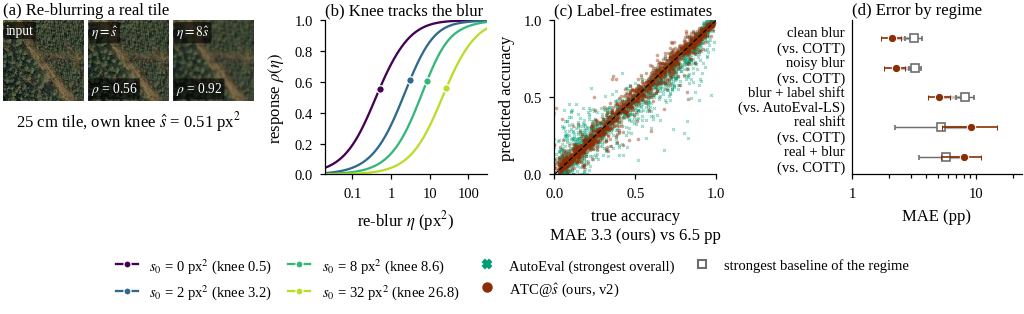

In [39]:
# === 7.5 Figure 1: teaser ===
# @needs-complete
LC_MISSING = "LandCover.ai missing in this run"
WITHIN0 = CELLS[(CELLS.seed == 0)] if len(CELLS) else CELLS
TEASE_COLORS = ["#440154", "#31688E", "#35B779", "#B8DE29"]

def build_fig1():
    d = dict(figsize=[CVPR_TEXT_W, 2.15], missing_msg=LC_MISSING)
    if PH is not None:
        t = PH["teaser"]
        d["a"] = dict(imgs=[t["tile"]] + list(t["imgs"]), top=["input", "$\\eta=\\hat{s}$", "$\\eta=8\\hat{s}$"],
                      bottom=["", f"$\\rho$ = {t['rho'][0]:.2f}", f"$\\rho$ = {t['rho'][1]:.2f}"],
                      xlabel=f"25 cm tile, own knee $\\hat{{s}}$ = {t['s_hat']:.2f} px$^2$")
        if "curves" in t:
            d["b"] = dict(eta=t["eta"], s0=t["s0"], curves=t["curves"], knees=t["knees"], colors=TEASE_COLORS[:len(t["s0"])])
    if len(WITHIN0) and ("e_" + OURS_V2) in WITHIN0:
        b, vals = best_in(WITHIN0, BASELINES, sorted(WITHIN0.dataset.unique()))
        if b is not None:
            _mae = lambda m: PPF * float(np.nanmean(np.abs(WITHIN0[m].values - WITHIN0.truth.values)))
            d["c"] = dict(truth=WITHIN0.truth.values, note=f"MAE {_mae(OURS_V2):.1f} (ours) vs {_mae(b):.1f} pp", series=[
                dict(pred=WITHIN0[b].values, color=mcolor(b), marker=mmarker(b), label=f"{mlabel(b)} (strongest overall)"),
                dict(pred=WITHIN0[OURS_V2].values, color=V2_COLOR, marker="o", label="ATC@$\\hat{s}$ (ours, v2)")])
    rows = []
    for rg, name in REGIMES:
        st = REGIME_STATS.get(rg, {})
        if not st.get("vals") or OURS_V2 not in st["vals"]:
            continue
        o, bb = st["vals"][OURS_V2], st["vals"][st["best_base"]]
        rows.append(dict(label=f"{name}\n(vs. {plain_label(st['best_base'])})",
                         ours=[PPF * o, PPF * st["ours_ci"][0], PPF * st["ours_ci"][1]],
                         base=[PPF * bb, PPF * st["base_ci"][0], PPF * st["base_ci"][1]]))
    if rows:
        allv = finite([v for r in rows for k in ("ours", "base") for v in r[k]])
        allv = allv[allv > 0]
        d["d"] = dict(rows=rows, ours_color=V2_COLOR, ours_label="ATC@$\\hat{s}$ (ours, v2)",
                      xlim=[float(10 ** np.floor(np.log10(allv.min() * 0.8))), float(allv.max() * 1.6)])
    return d

FIG_STATUS = {}

def make_figure(stem, builder):
    """Build the data dict, then render, check, save (PDF, PNG, data) and display; a failure is logged (strict in DRY_RUN)."""
    t0 = time.time()
    try:
        render(stem, builder())
        FIG_STATUS[stem] = dict(ok=True, seconds=round(time.time() - t0, 1))
    except Exception as e:
        if DRY_RUN:
            raise
        traceback.print_exc()
        FIG_STATUS[stem] = dict(ok=False, error=f"{type(e).__name__}: {str(e)[:300]}")
        FIG_REPORT[stem] = dict(ok=False, issues=[FIG_STATUS[stem]["error"]])
        runtime_decision(f"figure {stem} could not be produced: {type(e).__name__}: {e}")
        plt.close("all")

make_figure("fig1_teaser", build_fig1)

**Figure 2 (physics on LandCover.ai).** Tests Theorem 2(e), Corollary 1 and the effective-resolution prediction on real orthophotos. (a) A full held-out 25 cm orthophoto. (b) Its per-tile observability $O_x$ (px$^{-2}$; grey = tiles excluded by the no-data/contrast filter). (c) Its per-tile effective blur $s_{\rm raw}$ (px$^2$, log colour scale). (d) Data collapse of the high-observability tiles: $\rho$ against $u=\eta/\hat s$ for every applied blur $s_0\in\{1,2,4,8,16\}$ (hexbin density, log counts) with the power-law prediction $1-(1+u)^{-\hat\gamma}$ (rule R5). (e) Knee law: per-tile knee vs. applied blur (median and interquartile range over tiles) with the slope-1 reference and the median per-tile slope [95% orthophoto-cluster bootstrap CI] (rule R4). (f) Effective FWHM of the 25 cm and 50 cm products with 95% cluster-bootstrap CIs and the nominal ratio-2 line (rule R6).

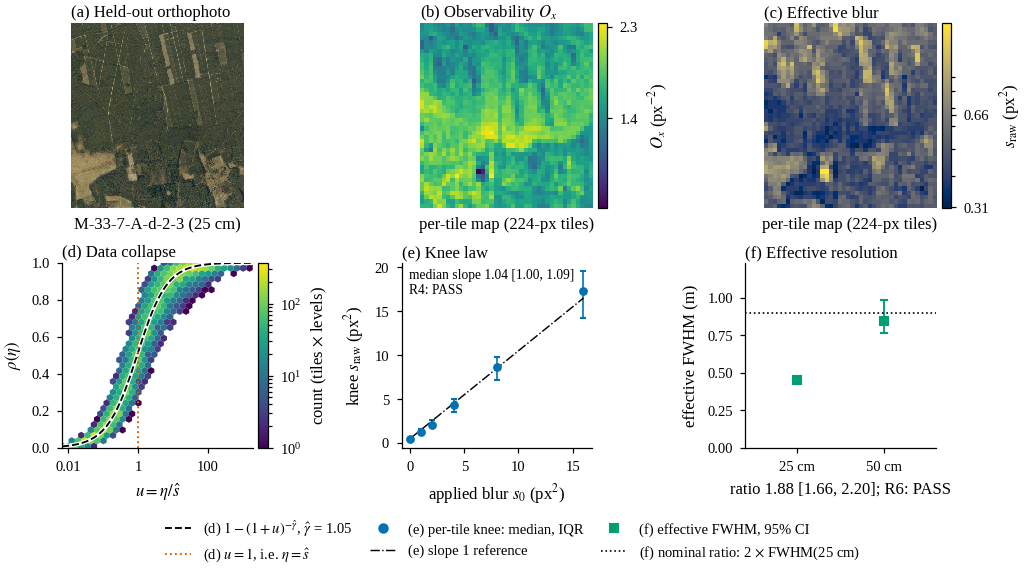

In [40]:
# === 7.6 Figure 2: physics ===
# @needs-complete
def build_fig2():
    d = dict(figsize=[CVPR_TEXT_W, 3.9], missing_msg=LC_MISSING)
    if PH is None:
        return d
    M = PH["maps"]
    d["maps"] = dict(thumb=M["thumb"], O=M["O"], knee=M["knee"], label=os.path.splitext(os.path.basename(M["path"]))[0] + " (25 cm)")
    Cl = PH["collapse"]
    d["collapse"] = dict(u=Cl["u"], rho=Cl["rho"], gamma_med=Cl["gamma_med"])
    hi = PH["high"]
    K = PH["KNEE"][hi]
    d["knee_law"] = dict(s0=PH["S0K"], med=np.median(K, 0), q1=np.percentile(K, 25, 0), q3=np.percentile(K, 75, 0),
                         intercept=float(np.median(K[:, 0])),
                         annot=f"median slope {R4_EST:.2f} [{R4_CI[0]:.2f}, {R4_CI[1]:.2f}]\nR4: {VERD.get('R4')}")
    d["fwhm"] = dict(fw25=R6_FW25, fw50=R6_FW50, ci25=R6_FW_CI["fw25"], ci50=R6_FW_CI["fw50"],
                     annot=f"ratio {R6_RATIO:.2f} [{R6_CI[0]:.2f}, {R6_CI[1]:.2f}]; R6: {VERD.get('R6')}")
    return d

make_figure("fig2_physics", build_fig2)

**Figure 3 (mechanism screen).** Tests the mechanistic corollary (rules M1–M4): can a frozen encoder report how blurred a single input is? Each row is one of the 17 encoders, grouped by augmentation family (colour) and ordered within groups; the knee $\rho$ is the Spearman correlation between the single-image feature knee $\eta_{1/2}$ and the applied blur $s_0$ (the better of the pooled and token statistics). Filled markers: LandCover.ai (B orthophotos); open markers: RESISC45 (seed-0 B). Bars: 95% bootstrap CIs over units (orthophotos or images, 10,000 resamples). Dashed lines: the pre-registered thresholds 0.6 and 0.8.

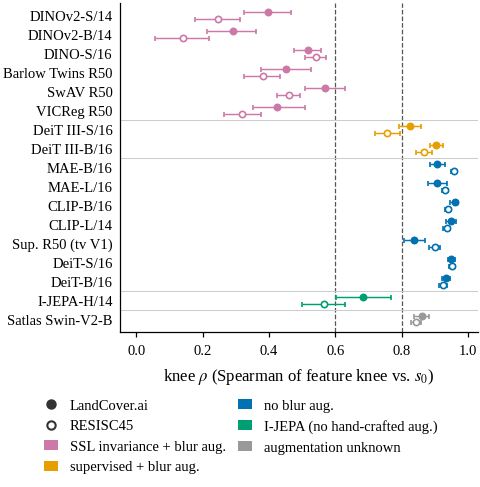

In [41]:
# === 7.7 Figure 3: mechanism ===
# @needs-complete
FAMILY_ORDER = ["ssl_blur", "sup_blur", "no_blur", "ijepa", "unknown"]

def build_fig3():
    d = dict(figsize=[CVPR_COL_W, 3.3], thresholds=[PREREG["M1"]["aug_median_max"], PREREG["M1"]["noaug_median_min"]],
             ds_labels=["LandCover.ai", "RESISC45"], families=[f for f in FAMILY_ORDER if f in {ENC_INFO[e][1] for e in AS["mech"]}])
    rows = []
    for fam in FAMILY_ORDER:
        for e in MECH_ENCODERS:
            if ENC_INFO[e][1] != fam or not len(MECHT) or e not in set(MECHT.encoder):
                continue
            r = dict(name=e, display=ENC_INFO[e][0], family=fam)
            for key, ds in (("lc", "landcoverai"), ("r45", "resisc45")):
                g = MECHT[(MECHT.encoder == e) & (MECHT.dataset == ds)]
                r[key] = [float(g.rho_best.iloc[0]), float(g.ci_best.iloc[0][0]), float(g.ci_best.iloc[0][1])] if len(g) else None
            rows.append(r)
    d["rows"] = rows
    lows = finite([v for r in rows for k in ("lc", "r45") if r[k] for v in r[k]])
    d["xlim"] = [float(min(lows.min() if len(lows) else 0.0, 0.0)) - 0.05, 1.03]
    return d

make_figure("fig3_mechanism", build_fig3)

**Figure 5 (main results; rules F1–F3).** Datasets on the y-axis (remote sensing above the divider, natural images below); seed 0. (a) Unflagged mean MAE over the six encoders for ATC@$\hat s$, the dataset's best single baseline (its own marker; grey link = the gap) and ATC. (b) The same for the worst case over encoders (F2). (c) Label-shift conditions (flagged or not): ATC@$\hat s$ vs. SAC-ATC (confidence matching) vs. the best other baseline, with the pooled SAC-ATC/ATC@$\hat s$ MAE ratio in the axis label (F3). Bars: 95% bootstrap CIs over conditions within the dataset (10,000 resamples; all encoders resampled together). Panels (a) and (b) share the x-axis.

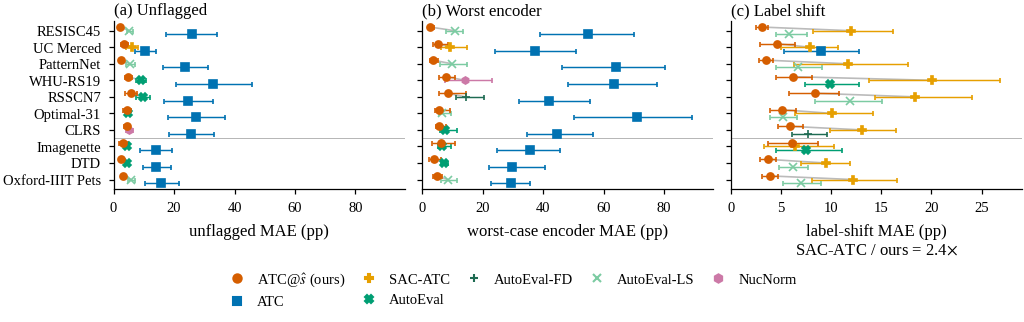

In [42]:
# === 7.8 Figure 5: main results ===
# @needs-complete
def _ds_stat(df, d, m, key):
    """Mean (or worst-case over encoders) of one dataset with its 95% bootstrap CI, in pp."""
    g = df[df.dataset == d]
    if not len(g) or ("e_" + m) not in g:
        return np.nan, np.nan, np.nan
    M = cond_matrix(g, m)
    if key == "mean":
        v = M.mean(1).values
        lo, hi = ci95(boot_dataset_mean(v, (key, d, m)))
        return PPF * float(v.mean()), PPF * lo, PPF * hi
    lo, hi = ci95(boot_worst(M.values, (key, d, m)))
    return PPF * float(M.mean(0).max()), PPF * lo, PPF * hi

def _series(stats, label, color, marker, dy, per_row=None):
    s = dict(x=[v[0] for v in stats], lo=[v[1] for v in stats], hi=[v[2] for v in stats], dy=dy, label=label, color=color, marker=marker)
    if per_row:
        s.update(colors=[mcolor(b) for b in per_row], markers=[mmarker(b) for b in per_row], labels=[mlabel(b) for b in per_row])   # same label as a fixed series -> one legend entry
    return s

OURS_LEG = "ATC@$\\hat{s}$ (ours)"

def build_fig5():
    d = dict(figsize=[CVPR_TEXT_W, 2.2], datasets=[DISPLAY[x] for x in SHOWN], n_rs=N_RS, panels=[],
             legend_first=[OURS_LEG, "ATC", "SAC-ATC"], captions=["Unflagged", "Worst encoder", "Label shift"])
    if not SHOWN:
        return d
    panels = []
    for key, xlabel, cap in (("mean", "unflagged MAE (pp)", "Unflagged"), ("worst", "worst-case encoder MAE (pp)", "Worst encoder")):
        best = [best_baseline(x, key) for x in SHOWN]
        ser = [_series([_ds_stat(U0, x, OURS, key) for x in SHOWN], OURS_LEG, OURS_COLOR, "o", 0.22),
               _series([_ds_stat(U0, x, b, key) for x, b in zip(SHOWN, best)], "best", None, None, 0.0, per_row=best),
               _series([_ds_stat(U0, x, "ATC", key) for x in SHOWN], "ATC", mcolor("ATC"), mmarker("ATC"), -0.22)]
        panels.append(dict(series=ser, link=[0, 1], xlabel=xlabel, top=OURS_LEG, caption=cap))
    others = [b for b in BASELINES if b != "SAC_ATC"]
    best_ls = []
    for x in SHOWN:
        g = LS0[LS0.dataset == x]
        best_ls.append(min(others, key=lambda b: g["e_" + b].mean()) if len(g) else others[0])
    ratio = pooled(LS0, "SAC_ATC") / pooled(LS0, OURS) if len(LS0) else np.nan
    ser = [_series([_ds_stat(LS0, x, OURS, "mean") for x in SHOWN], OURS_LEG, OURS_COLOR, "o", 0.22),
           _series([_ds_stat(LS0, x, "SAC_ATC", "mean") for x in SHOWN], "SAC-ATC", mcolor("SAC_ATC"), mmarker("SAC_ATC"), 0.0),
           _series([_ds_stat(LS0, x, b, "mean") for x, b in zip(SHOWN, best_ls)], "best other", None, None, -0.22, per_row=best_ls)]
    panels.append(dict(series=ser, link=[0, 1], xlabel=f"label-shift MAE (pp)\nSAC-ATC / ours = {ratio:.1f}$\\times$", top=OURS_LEG,
                       caption="Label shift"))
    hi_ab = finite([v for P in panels[:2] for s in P["series"] for v in s["hi"]] + [v for P in panels[:2] for s in P["series"] for v in s["x"]])
    hi_c = finite([v for s in panels[2]["series"] for v in s["hi"]] + [v for s in panels[2]["series"] for v in s["x"]])
    for P in panels[:2]:
        P["xlim"] = [0.0, float(hi_ab.max() * 1.08) if len(hi_ab) else 1.0]
    panels[2]["xlim"] = [0.0, float(hi_c.max() * 1.08) if len(hi_c) else 1.0]
    d["panels"] = panels
    return d

make_figure("fig5_main_results", build_fig5)

**Figure 7 (re-degradation as a plug-in; addendum rules P1–P4).** For six published estimators (rows), the pooled MAE as published (open grey circle) and with the labelled source re-degraded to the identified level (filled marker; arrow = change), in five regimes: (a) clean blur, (b) noisy blur (v2 level: $(\hat s,\hat\sigma)$ from the v1.1 tail fit), (c) blur + label shift, (d) real cross-dataset and cross-resolution shifts, (e) the same real shifts with added blur. All seeds; bars: hierarchical 95% bootstrap CIs (10,000 resamples); log axis. Re-degradation changes nothing when no blur is identified ((d), non-inferiority rule P3) and removes most of the blur-induced error otherwise; Table T13 gives the paired tests.

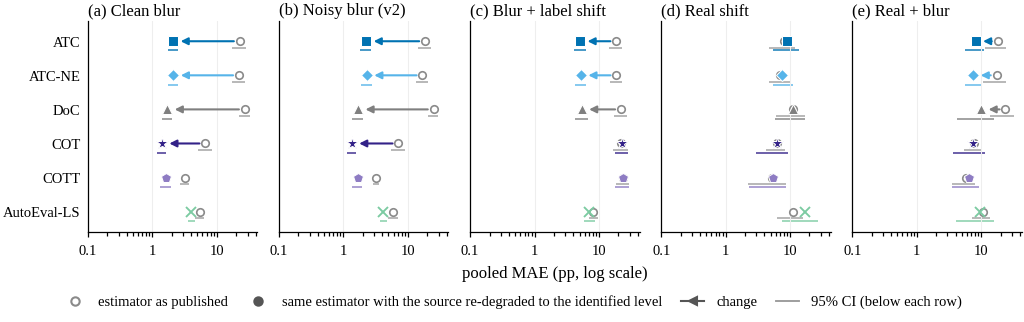

In [43]:
# === 7.8b Figure 7: re-degradation as a plug-in for every estimator ===
# @needs-complete
PLUG_CAPS = [("clean", "Clean blur"), ("noisy", "Noisy blur (v2)"), ("ls", "Blur + label shift"), ("real0", "Real shift"), ("realb", "Real + blur")]

def build_fig7():
    d = dict(figsize=[CVPR_TEXT_W, 2.2], rows=[plain_label(p[0]) for p in PLUGIN_PAIRS], colors=[mcolor(p[0]) for p in PLUGIN_PAIRS],
             markers=[mmarker(p[0]) for p in PLUGIN_PAIRS], panels=[],
             legend_plug="same estimator with the source re-degraded to the identified level")
    allv = []
    for rg, cap in PLUG_CAPS:
        g = regime_df(rg)
        if not len(g):
            d["panels"].append(dict(caption=cap))
            continue
        dss = sorted(g.dataset.unique().tolist())
        base, plug = [], []
        for pair in PLUGIN_PAIRS:
            b, m = pair[0], pair[2 if rg == "noisy" else 1]
            if ("e_" + m) not in g or ("e_" + b) not in g:
                base.append([np.nan] * 3)
                plug.append([np.nan] * 3)
                continue
            h = g[g[["e_" + b, "e_" + m]].notna().all(1)]
            for lst, mm in ((base, b), (plug, m)):
                v, ci = pooled(h, mm, dss), pooled_ci(h, mm, ("fig7", rg, mm), dss)
                lst.append([PPF * v, PPF * ci[0], PPF * ci[1]])
                allv += lst[-1]
        d["panels"].append(dict(caption=cap, base=base, plug=plug))
    allv = finite(allv)
    allv = allv[allv > 0]
    if len(allv):
        d["xlim"] = [float(10 ** np.floor(np.log10(allv.min() * 0.85))), float(allv.max() * 1.3)]
    return d

make_figure("fig7_plugin", build_fig7)

**Figure S1 (theory checks).** (a) Sensitivity identity (Theorem 2b, rule R1): closed-form $\partial\rho/\partial s_0$ against a central finite difference of the exact operators on LandCover.ai tiles × 13 $\eta$ (dashed: identity). (b) Narrowband obstruction (Theorem 2d, rule R2): $\max_x|N T_s x - N x|$ stays at machine precision for single-DCT-mode images (maximum over four images) but not for a broadband $1/f^2$ field; dotted: the $10^{-10}$ tolerance. (c) Half-energy law (Corollary 1): measured $\eta_{1/2}/s_0$ on synthetic $|\omega|^{-\alpha}$ fields (median over fields; one marker per $s_0\in\{2,4,8,16\}$, slightly offset) against $2^{1/\gamma}-1$ with $\gamma=2-\alpha/2$ (dashed: identity). (d) Proposition 5 (rule R3): measured drift $\|T_{\Lambda+s}x-T_\Lambda x\|$ against the bound, synthetic fields and real tiles; every point lies on or below the identity.

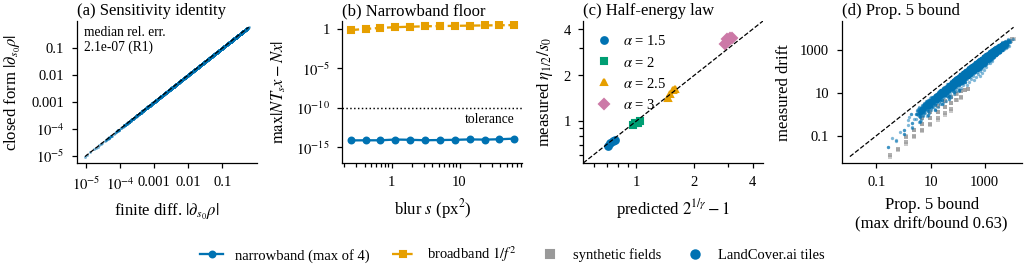

In [44]:
# === 7.9 Figure S1: theory checks ===
# @needs-complete
def build_figS1():
    d = dict(figsize=[CVPR_TEXT_W, 1.9])
    th = TH.get("theory", {})
    if PH is not None:
        d["r1"] = dict(an=PH["r1_an"].ravel(), fd=PH["r1_fd"].ravel(), annot=f"median rel. err.\n{_r1:.1e} (R1)")
    if "R2_floor" in th:
        cur = th["R2_floor"]["curves"]
        nb = np.max([v for k, v in cur.items() if not k.startswith("broadband")], axis=0)
        bb = next(v for k, v in cur.items() if k.startswith("broadband"))
        d["r2"] = dict(s=th["R2_floor"]["s"], tol=PREREG["R2"]["tol"], curves=[
            dict(values=nb, label="narrowband (max of 4)", color="#0072B2", marker="o", ls="-"),
            dict(values=bb, label="broadband $1/f^2$", color="#E69F00", marker="s", ls="--")])
    pl = TH.get("powerlaw")
    if pl is not None and len(pl):
        cols, mks = ["#0072B2", "#009E73", "#E69F00", "#CC79A7"], ["o", "s", "^", "D"]
        d["half"] = dict(groups=[dict(measured=pl[pl.alpha == a].groupby("s0").ratio.median().values.tolist(),
                                      predicted=float(pl[pl.alpha == a].predicted.iloc[0]), label=f"$\\alpha$ = {a:g}",
                                      color=cols[i % 4], marker=mks[i % 4]) for i, a in enumerate(sorted(pl.alpha.unique()))])
    groups, ratios = [], []
    for name, arr, col, mk in (("synthetic fields", th.get("R3_synthetic", {}).get("pairs"), "#999999", "s"),
                               ("LandCover.ai tiles", PH["p5"] if PH is not None else None, "#0072B2", "o")):
        if arr is None or not len(arr):
            continue
        arr = np.asarray(arr, float)
        arr = arr[arr[:, 1] > 0]
        groups.append(dict(bound=arr[:, 3], drift=arr[:, 2], label=name, color=col, marker=mk))
        ratios.append(np.max(arr[:, 2] / np.maximum(arr[:, 3], 1e-300)))
    if groups:
        d["prop5"] = dict(groups=groups, annot=f"max drift/bound {max(ratios):.2f}")
    return d

make_figure("figS1_theory_checks", build_figS1)

**Figure S2 (certificate, Theorem 3, rule R8).** Test-inversion certificate on the ten evaluation datasets (seed 0; $K$ = 13, $M$ = 10, $\delta$ = 0.1), Hoeffding and empirical-Bernstein tolerances. (a) Coverage of the accuracy interval $C$ against the target size $n_Q$: median and minimum over (dataset, encoder, $s_0$) configurations, with the nominal $1-\delta$ (dashed) and the pre-registered R8 threshold 0.88 (dotted); abstentions count as misses. (b) Median diameter of the confidence set $CS$ (px$^2$; configurations with a single grid point have diameter 0 and are not drawn) with a slope $-1/2$ reference (Theorem 3iii). (c) Median width of $C$. Open markers: $n_Q$ = all of B (one point per dataset at its own size).

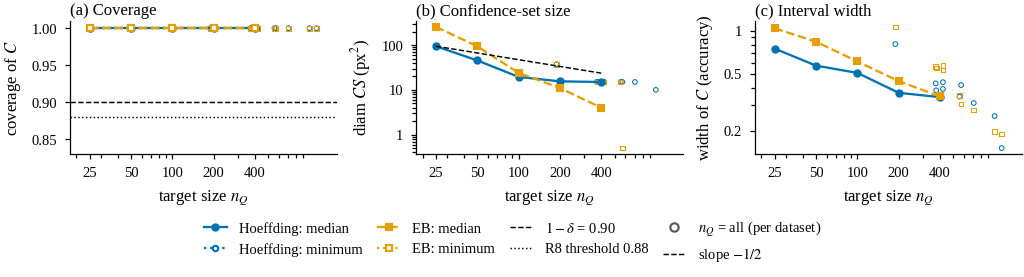

In [45]:
# === 7.10 Figure S2: certificate ===
# @needs-complete
def build_figS2():
    d = dict(figsize=[CVPR_TEXT_W, 1.9], delta=PREREG["R8"]["delta"], min_cov=PREREG["R8"]["min_coverage"], bounds={})
    if not len(CERT):
        return d
    xs = []
    for bound in ("Hoeffding", "EB"):
        g = CERT[CERT.bound == bound]
        nom = g[~g["all"].astype(bool)].groupby("nQ")
        al = g[g["all"].astype(bool)].groupby("dataset")
        S = dict(n=list(nom.groups), cov_med=nom.coverage.median().values, cov_min=nom.coverage.min().values,
                 diam_med=nom.diam_med.median().values, width_med=nom.width_med.median().values,
                 all_n=al.nQ.first().values, all_cov=al.coverage.median().values, all_diam=al.diam_med.median().values,
                 all_width=al.width_med.median().values)
        d["bounds"][bound] = S
        xs += list(S["n"]) + list(S["all_n"])
    xs = finite(xs)
    d["xlim"] = [float(xs.min() / 1.4), float(xs.max() * 1.4)]
    H = d["bounds"]["Hoeffding"]
    pos = [(n, v) for n, v in zip(H["n"], H["diam_med"]) if v > 0]
    if pos:
        d["ref"] = dict(n=[pos[0][0], max(H["n"])], y0=pos[0][1])
    return d

make_figure("figS2_certificate", build_figS2)

**Figure S3 (statistics and seeds).** (a) Paired per-cell differences $|\hat A-A|_{\rm ours}-|\hat A-A|_{\rm best}$ (pp) on unflagged seed-0 cells, per dataset against that dataset's best single baseline (box: quartiles, whiskers: 1.5 IQR; points: cells). Negative values favour ATC@$\hat s$. (b) Per-seed unflagged MAE on the multi-seed datasets (seeds 0, 1, 2 from left to right within each group) for ATC@$\hat s$, ATC and the best baseline by seed-averaged MAE (rule F6). (c) Exact cluster sign-flip null distribution (all $2^D$ sign patterns of the per-dataset mean differences) against the strongest single baseline, with the observed mean difference (the T2 test).

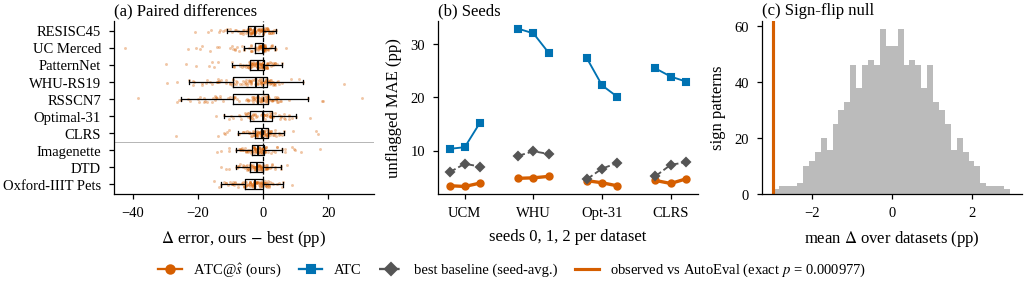

In [46]:
# === 7.11 Figure S3: statistics and seeds ===
# @needs-complete
def seed_mae(d, k, m):
    g = unflagged(CELLS[(CELLS.dataset == d) & (CELLS.seed == k)])
    return float(cond_series(g, m).mean()) if len(g) else np.nan

def build_figS3():
    d = dict(figsize=[CVPR_TEXT_W, 2.0])
    if len(U0):
        diffs, jit = [], []
        for x in SHOWN:
            g = U0[U0.dataset == x]
            b = best_baseline(x, "mean")
            v = PPF * (g["e_" + OURS] - g["e_" + b]).values
            diffs.append(v)
            jit.append(rng_for("figS3a", x).uniform(-0.18, 0.18, len(v)))
        d["paired"] = dict(datasets=[DISPLAY[x] for x in SHOWN], n_rs=N_RS, diffs=diffs, jitter=jit)
    groups = []
    for x in SEED_DATASETS:
        seeds = sorted(CELLS[CELLS.dataset == x].seed.unique().tolist()) if len(CELLS) else []
        if len(seeds) < 2:
            continue
        avg = {b: np.mean([seed_mae(x, k, b) for k in seeds]) for b in BASELINES}
        bb = min(avg, key=avg.get)
        groups.append(dict(label=DS_SHORT[x], seeds=seeds, series=[
            dict(key="ours", legend="ATC@$\\hat{s}$ (ours)", color=OURS_COLOR, marker="o", vals=[PPF * seed_mae(x, k, OURS) for k in seeds]),
            dict(key="ATC", legend="ATC", color=mcolor("ATC"), marker=mmarker("ATC"), vals=[PPF * seed_mae(x, k, "ATC") for k in seeds]),
            dict(key="best", legend="best baseline (seed-avg.)", color="#555555", marker="D", ls="--",
                 vals=[PPF * seed_mae(x, k, bb) for k in seeds])]))
    if groups:
        d["seeds"] = dict(groups=groups, xlabel="seeds 0, 1, 2 per dataset")
    if BEST_POOLED in SIGNFLIP:
        S = SIGNFLIP[BEST_POOLED]
        d["signflip"] = dict(null=PPF * np.asarray(S["null"]), obs=PPF * S["obs"],
                             label=f"observed vs {mlabel(BEST_POOLED)} (exact $p$ = {S['p']:.3g})")
    return d

make_figure("figS3_statistics_seeds", build_figS3)

**Figure S4 (encoder breakdown).** (a) Unflagged seed-0 MAE difference ATC@$\hat s$ minus the dataset's best single baseline for every dataset × encoder cell (pp; blue = ours better, red = worse; diverging scale centred at 0). The tick labels give each encoder's wins over datasets. (b) Number of encoders (of six) on which ATC@$\hat s$ beats the dataset's best single baseline. Tests whether the F1 win is carried by a few encoders (rules F1, F2).

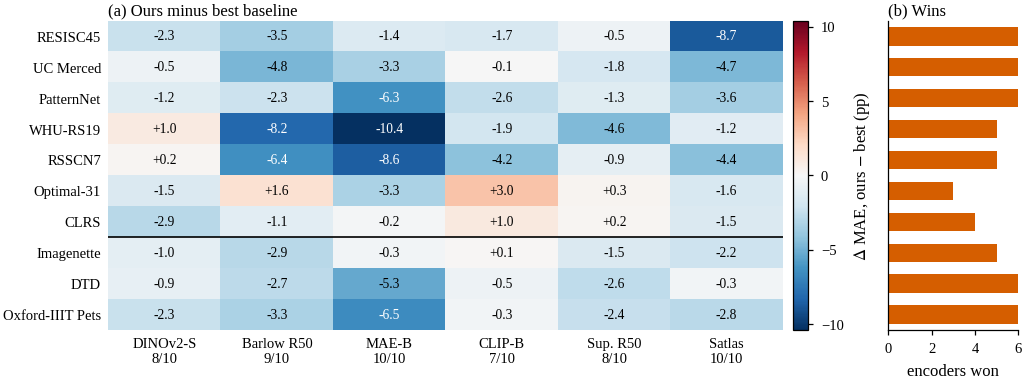

In [47]:
# === 7.12 Figure S4: encoder breakdown ===
# @needs-complete
def build_figS4():
    encs = [e for e in METHOD_ENCODERS if len(U0) and e in set(U0.encoder)]
    d = dict(figsize=[CVPR_TEXT_W, 2.6], datasets=[DISPLAY[x] for x in SHOWN], n_rs=N_RS, n_enc=len(encs) or 6)
    Z = np.full((len(SHOWN), len(encs)), np.nan)
    for i, x in enumerate(SHOWN):
        b = best_baseline(x, "mean")
        for j, e in enumerate(encs):
            po, pb = DS_STATS[x][OURS]["per_enc"].get(e, np.nan), DS_STATS[x][b]["per_enc"].get(e, np.nan)
            Z[i, j] = PPF * (po - pb)
    d["delta"] = Z
    d["wins_ds"] = np.sum(Z < 0, axis=1).tolist()
    d["enc_labels"] = [f"{ENC_SHORT[e]}\n{int(np.sum(Z[:, j] < 0))}/{len(SHOWN)}" for j, e in enumerate(encs)]
    return d

make_figure("figS4_encoder_breakdown", build_figS4)

**Figure S8 (accuracy curves).** Probe accuracy $A(s)$ on the clean labelled split A2 (seed 0) as a function of the blur $s$ (px$^2$, log1p axis) for the six method encoders on each evaluation dataset. These are the curves that ATC@$\hat s$ reads at the identified level; their steepness sets the stakes (rule F7) and the Theorem 4 regime.

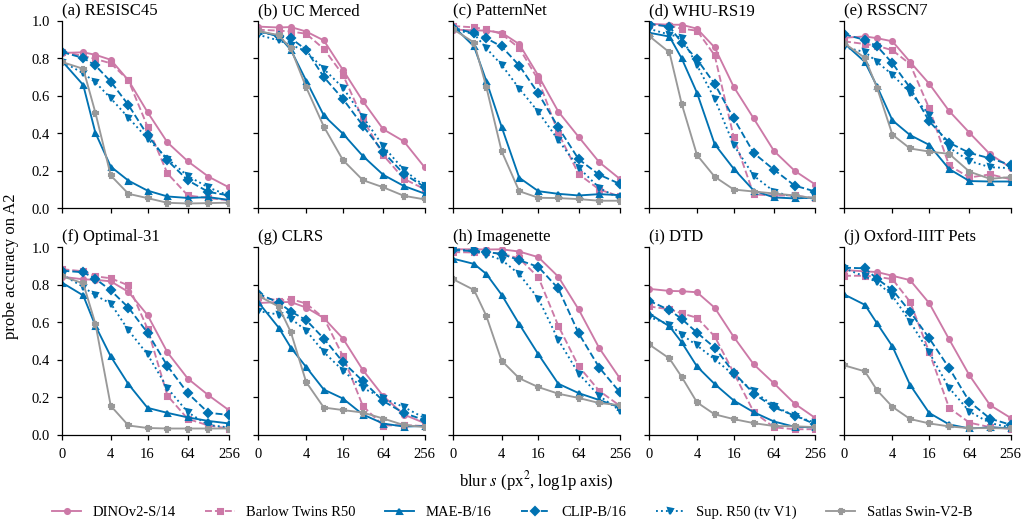

In [48]:
# === 7.13 Figure S8: accuracy curves ===
# @needs-complete
def build_figS8():
    d = dict(figsize=[CVPR_TEXT_W, 3.6], panels=[])
    if not len(ACC):
        return d
    for x in [x for x in DISPLAY_ORDER if x in DATASETS_OK]:
        a = ACC[(ACC.dataset == x) & (ACC.seed == 0) & (ACC.curve == "A2")]
        curves = []
        for e in METHOD_ENCODERS:
            g = a[a.encoder == e].sort_values("level")
            if len(g):
                curves.append(dict(encoder=e, label=ENC_INFO[e][0], s=g.level.values, acc=g.acc.values))
        d["panels"].append(dict(title=DISPLAY[x], curves=curves))
    return d

make_figure("figS8_accuracy_curves", build_figS8)

**Figure S10 (invariance vs. robustness).** For the six method encoders: the mechanism-screen knee $\rho$ (mean of LandCover.ai and RESISC45; horizontal bars span the lowest to the highest bound of the two 95% CIs) against the accuracy drop $A(0)-A(64)$ on A2 (mean over the ten datasets, seed 0; vertical bars: 95% bootstrap CI over datasets). Asks whether encoders that cannot sense blur are also the ones whose accuracy survives it.

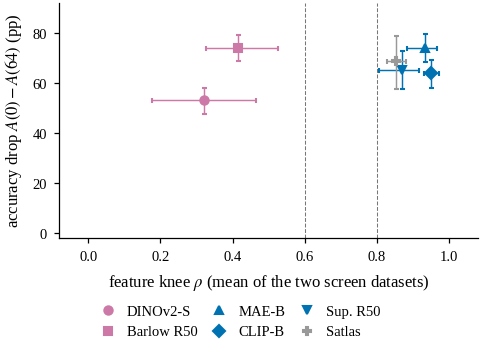

In [49]:
# === 7.14 Figure S10: invariance vs robustness ===
# @needs-complete
def build_figS10():
    d = dict(figsize=[CVPR_COL_W, 2.4], points=[])
    for e in METHOD_ENCODERS:
        g = MECHT[MECHT.encoder == e] if len(MECHT) else MECHT
        a = ACC[(ACC.seed == 0) & (ACC.curve == "A2") & (ACC.encoder == e)] if len(ACC) else ACC
        if not len(g) or not len(a):
            continue
        drops = np.array([PPF * (h[h.level == 0].acc.iloc[0] - h[h.level == 64].acc.iloc[0]) for _, h in a.groupby("dataset")])
        r = rng_for("figS10", e)
        reps = np.array([drops[r.integers(0, len(drops), len(drops))].mean() for _ in range(N_BOOT)])
        lo, hi = ci95(reps)
        d["points"].append(dict(encoder=e, label=ENC_SHORT[e], x=float(g.rho_best.mean()),
                                xlo=float(min(c[0] for c in g.ci_best)), xhi=float(max(c[1] for c in g.ci_best)),
                                y=float(drops.mean()), ylo=lo, yhi=hi))
    return d

make_figure("figS10_invariance_vs_robustness", build_figS10)

**Figure S11 (prediction scatter by regime).** Predicted vs. true accuracy on every seed-0 cell of three regimes, flagged or not: (a) clean in-family, (b) noisy in-family ($\sigma$ = 3 DN; the GOF test should fire, and the joint fit carries no guarantee), (c) label shift (invisible to pixels by Theorem 1). Each panel compares ATC@$\hat s$ with the strongest single baseline of that regime; the axis labels give both MAEs (dashed: identity; rules F3, F8).

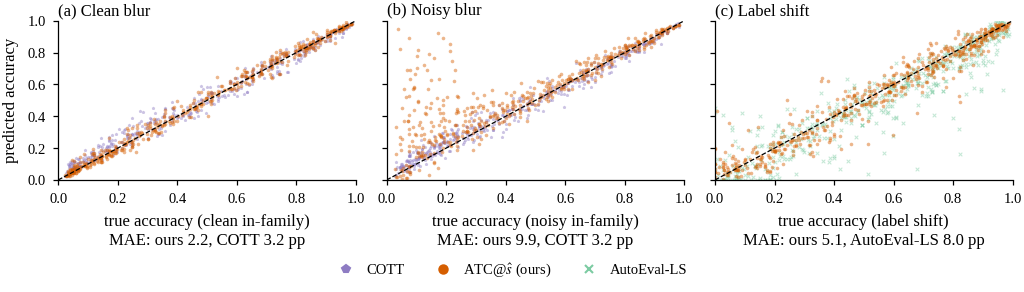

In [50]:
# === 7.15 Figure S11: prediction scatter ===
# @needs-complete
def build_figS11():
    d = dict(figsize=[CVPR_TEXT_W, 2.0], panels=[])
    regimes = [("clean in-family", S0C[(S0C.suite == "syn") & (S0C.sigma == 0)] if len(S0C) else S0C),
               ("noisy in-family", S0C[(S0C.suite == "syn") & (S0C.sigma > 0)] if len(S0C) else S0C),
               ("label shift", LS0)]
    for name, g in regimes:
        b, _ = best_in(g, BASELINES)
        if b is None:
            d["panels"].append(None)
            continue
        d["panels"].append(dict(truth=g.truth.values, xlabel=f"true accuracy ({name})\nMAE: ours {PPF * pooled(g, OURS):.1f}, "
                                f"{mlabel(b)} {PPF * pooled(g, b):.1f} pp", series=[
                                    dict(pred=g[b].values, color=mcolor(b), marker=mmarker(b), legend=mlabel(b)),
                                    dict(pred=g[OURS].values, color=OURS_COLOR, marker="o", legend="ATC@$\\hat{s}$ (ours)")]))
    return d

make_figure("figS11_prediction_scatter", build_figS11)

**Figure S12 (gallery).** (a)–(d) A LandCover.ai 25 cm tile under the exact blur ladder $s\in\{0,4,16,64\}$ px$^2$, labelled with the effective FWHM $2.3548\cdot\mathrm{GSD}\cdot\sqrt{\hat s+s}$ (m). (e) The highest- and lowest-observability tiles of the physics set (97.5th and 2.5th percentiles of $O_x$); low-observability scenes approach the Theorem 2(d) and Theorem 4 regimes.

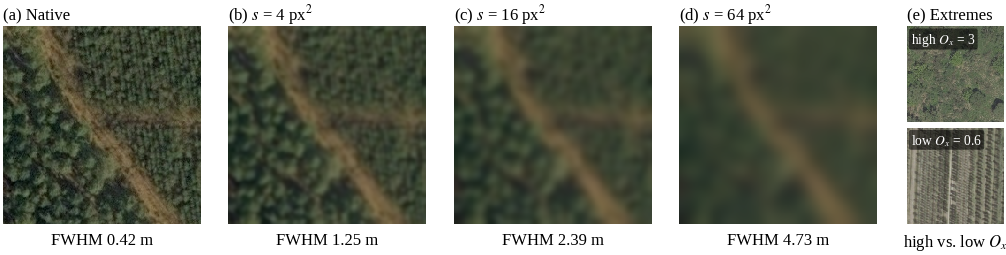

In [51]:
# === 7.16 Figure S12: gallery ===
# @needs-complete
def build_figS12():
    d = dict(figsize=[CVPR_TEXT_W, 1.75], missing_msg=LC_MISSING)
    if PH is None:
        return d
    L, O = PH["ladder"], PH["obs_examples"]
    d["ladder"] = dict(imgs=L["imgs"], labels=[f"FWHM {f:.2f} m" for f in L["fwhm"]],
                       caps=["Native" if s == 0 else f"$s$ = {s:g} px$^2$" for s in L["s"]])
    d["obs"] = dict(high=O["high"], low=O["low"], high_label=f"high $O_x$ = {O['O_high']:.2g}", low_label=f"low $O_x$ = {O['O_low']:.2g}")
    return d

make_figure("figS12_gallery", build_figS12)

**Figure S14 (regime map; addendum S2).** Pooled MAE (pp; all seeds; equal weight per dataset or real pair) of every estimator in each regime. Rows: ATC@$\hat s$ at the frozen v1.0 level and with the v2 path, the plug-in versions (v2 level) of five more estimators, and the eleven published baselines. Colour: log scale (viridis); the best value of each column is boxed and bold. Read down a column to see which method a regime favours, and along a row to see where a method breaks.

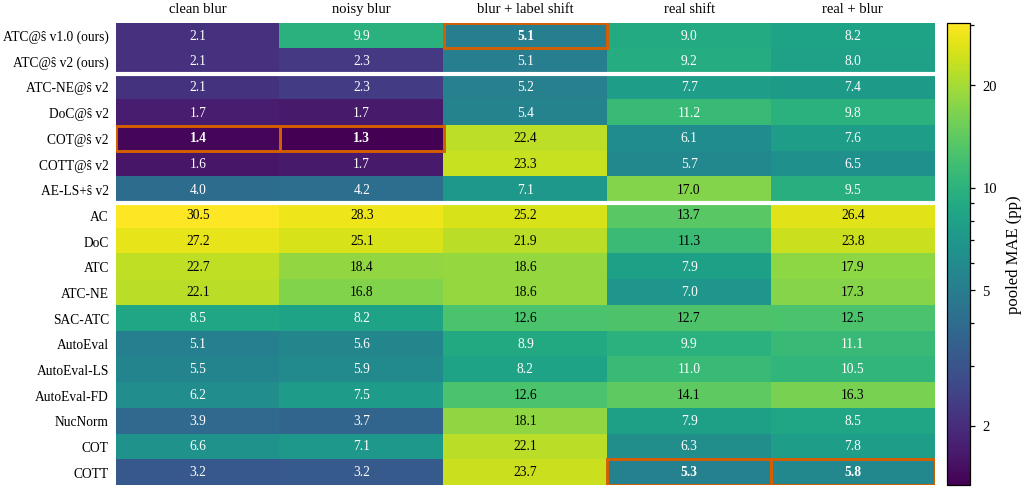

In [52]:
# === 7.16b Figure S14: regime map ===
# @needs-complete
S14_ROWS = [OURS, OURS_V2] + [p[2] for p in PLUGIN_PAIRS if p[2] != OURS_V2] + BASELINES

def build_figS14():
    d = dict(figsize=[CVPR_TEXT_W, 3.3], regimes=[n for _, n in REGIMES], methods=[], Z=[], best=[], dividers=[2, 2 + len(PLUGIN_PAIRS) - 1],
             cbar_label="pooled MAE (pp)")
    Z = np.full((len(S14_ROWS), len(REGIMES)), np.nan)
    for j, (rg, _) in enumerate(REGIMES):
        vals = REGIME_STATS.get(rg, {}).get("vals", {})
        for i, m in enumerate(S14_ROWS):
            Z[i, j] = PPF * vals.get(m, np.nan)
    d["methods"] = [plain_label(m).replace(" (ours)", " v1.0 (ours)") if m == OURS else plain_label(m) for m in S14_ROWS]
    d["Z"] = Z
    d["best"] = [int(np.nanargmin(Z[:, j])) if np.isfinite(Z[:, j]).any() else -1 for j in range(Z.shape[1])]
    return d

make_figure("figS14_regime_map", build_figS14)

**Figure S15 (dataset gallery).** One target image per evaluation dataset (the image of median observability in seed-0 B), shown native and after the exact applied blurs $s_0$ = 4 and 16 px$^2$, labelled with the dataset-level $\hat s$ that the pixel stage identified for that condition. Shows what the benchmark's blur levels look like on every image domain.

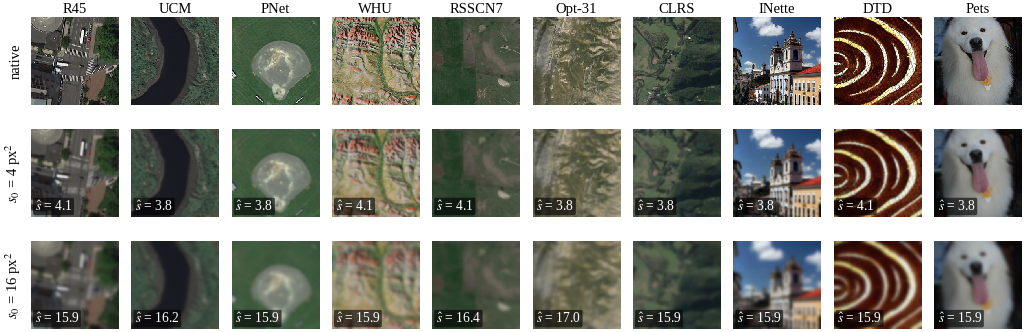

Section 7 figures: {'fig1_teaser': True, 'fig2_physics': True, 'fig3_mechanism': True, 'fig5_main_results': True, 'fig7_plugin': True, 'figS1_theory_checks': True, 'figS2_certificate': True, 'figS3_statistics_seeds': True, 'figS4_encoder_breakdown': True, 'figS8_accuracy_curves': True, 'figS10_invariance_vs_robustness': True, 'figS11_prediction_scatter': True, 'figS12_gallery': True, 'figS14_regime_map': True, 'figS15_dataset_gallery': True}


In [53]:
# === 7.16c Figure S15: dataset gallery ===
# @needs-complete
def build_figS15():
    d = dict(figsize=[CVPR_TEXT_W, 2.3], columns=[], rows=["native", "$s_0$ = 4 px$^2$", "$s_0$ = 16 px$^2$"], imgs=[], labels=[])
    for x in DISPLAY_ORDER:
        gx = AS["gallery"].get(x)
        if gx is None:
            continue
        img = np.asarray(gx["img"], np.uint8)
        xf = img.astype(np.float64).transpose(2, 0, 1)
        d["columns"].append(DS_SHORT[x])
        d["imgs"].append([img] + [_to_u8(heat(xf, s)) for s in (4.0, 16.0)])
        d["labels"].append([""] + [f"$\\hat{{s}}$ = {v:.1f}" if np.isfinite(v) else "" for v in gx["s_hat"][1:]])
    return d

make_figure("figS15_dataset_gallery", build_figS15)
print("Section 7 figures:", {k: v.get("ok") for k, v in FIG_STATUS.items()})

### Tables T1–T4 and T6–T8
Every table is written as booktabs LaTeX (`tables/<name>.tex`, `\footnotesize`, `\tabcolsep` = 4 pt, no `\resizebox`) and as CSV with the raw values (fractions, not percentage points). Before writing, every cell string is measured with matplotlib font metrics (serif, 8 pt) and the sum of column widths plus padding is checked against the CVPR text width (6.875 in) or column width (3.25 in).

In [54]:
# === 7.17 Table writer and tables T1-T4, T6-T8 ===
# @needs-complete
from matplotlib.font_manager import FontProperties
from matplotlib.textpath import TextToPath
_TTP = TextToPath()
_TFONT = {False: FontProperties(family="serif", size=8), True: FontProperties(family="serif", size=8, weight="bold")}
TABCOLSEP_PT = 4.0
TABLE_REPORT = {}
_TEX = {"\\": "\\textbackslash{}", "&": "\\&", "%": "\\%", "#": "\\#", "_": "\\_", "{": "\\{", "}": "\\}", "~": "\\textasciitilde{}",
        "^": "\\textasciicircum{}", "$": "\\$", "±": "$\\pm$", "×": "$\\times$", "≤": "$\\leq$", "≥": "$\\geq$", "−": "$-$", "–": "--",
        "<": "$<$", ">": "$>$", "ŝ": "$\\hat{s}$", "ρ": "$\\rho$", "σ": "$\\sigma$", "η": "$\\eta$", "δ": "$\\delta$", "α": "$\\alpha$",
        "γ": "$\\gamma$", "Δ": "$\\Delta$", "λ": "$\\lambda$", "²": "$^2$", "→": "$\\rightarrow$", "†": "$^\\dagger$"}
DASH = "–"                                                     # missing value in a table

def tex_escape(s):
    return "".join(_TEX.get(ch, ch) for ch in str(s))

def _cellify(c):
    if isinstance(c, dict):
        return dict(plain=c["plain"], tex=c.get("tex", tex_escape(c["plain"])), style=c.get("style", ""))
    if isinstance(c, tuple):
        return dict(plain=c[0], tex=tex_escape(c[0]), style=c[1])
    return dict(plain=str(c), tex=tex_escape(c), style="")

def text_width_in(s, bold=False):
    w, _, _ = _TTP.get_text_width_height_descent(str(s), _TFONT[bold], ismath=False)
    return w / 72.0

def num(v, nd=1, scale=1.0):
    if v is None or not np.isfinite(v):
        return DASH
    x = round(float(v) * scale, nd)
    s = f"{abs(x):.{nd}f}"
    return ("−" + s) if x < 0 and float(s) != 0 else s

def num_ci(v, lo, hi, nd=1, scale=1.0, short=False):
    f = (lambda z: num(z, nd, scale).replace("0.", ".", 1) if num(z, nd, scale).lstrip("−").startswith("0.") else num(z, nd, scale)) if short \
        else (lambda z: num(z, nd, scale))
    return f"{num(v, nd, scale)} [{f(lo)}, {f(hi)}]"

def pfmt(p):
    """p-value in scientific notation with two significant figures: plain text for measurement, math for LaTeX."""
    if p is None or not np.isfinite(p):
        return DASH
    m, e = f"{p:.1e}".split("e")
    return dict(plain=f"{m}×10{int(e)}", tex=f"${m}\\times10^{{{int(e)}}}$")

def write_table(name, header, rows, raw, caption, label, wide=True, pcols=None, midrules=(), align=None):
    """booktabs .tex (+ raw .csv); asserts the font-metric width fits the CVPR text or column width."""
    pcols = pcols or {}
    H = [_cellify(c) for c in header]
    R = [[_cellify(c) for c in r] for r in rows]
    widths, too_long = [], []
    for j in range(len(H)):
        if j in pcols:
            widths.append(float(pcols[j]))
            longest = max(text_width_in(w, "b" in c[j]["style"]) for c in [H] + R for w in (c[j]["plain"].split() or [""]))
            if longest > pcols[j]:                             # a wrapped column still cannot break inside a word
                too_long.append((j, round(longest, 2)))
            continue
        widths.append(max(text_width_in(c[j]["plain"], "b" in c[j]["style"]) for c in [H] + R))
    total = sum(widths) + len(H) * 2 * TABCOLSEP_PT / 72.27
    limit = CVPR_TEXT_W if wide else CVPR_COL_W
    ok = total <= limit and not too_long
    spec = "".join(f">{{\\raggedright\\arraybackslash}}p{{{pcols[j]:.2f}in}}" if j in pcols else
                   (align[j] if align else ("l" if j == 0 else "r")) for j in range(len(H)))
    sty = lambda c: (("\\textbf{" + c["tex"] + "}") if "b" in c["style"] else c["tex"]) if "u" not in c["style"] else \
        ("\\underline{" + (("\\textbf{" + c["tex"] + "}") if "b" in c["style"] else c["tex"]) + "}")
    env = "table*" if wide else "table"
    out = ["% requires \\usepackage{booktabs} and \\usepackage{array}", f"\\begin{{{env}}}[t]", "\\centering", "\\footnotesize", "\\setlength{\\tabcolsep}{4pt}",
           f"\\caption{{{caption}}}", f"\\label{{{label}}}", f"\\begin{{tabular}}{{{spec}}}", "\\toprule",
           " & ".join(sty(c) for c in H) + " \\\\", "\\midrule"]
    for i, r in enumerate(R):
        if i in midrules:
            out.append("\\midrule")
        out.append(" & ".join(sty(c) for c in r) + " \\\\")
    out += ["\\bottomrule", "\\end{tabular}", f"\\end{{{env}}}", ""]
    with open(os.path.join(TAB_DIR, name + ".tex"), "w", encoding="utf-8") as f:
        f.write("\n".join(out))
    raw.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=False)
    TABLE_REPORT[name] = dict(width_in=round(total, 3), limit_in=limit, fits=bool(ok), rows=len(R), cols=len(H), unbreakable=too_long)
    print(f"{name}: {len(R)} rows x {len(H)} cols, width {total:.2f} in of {limit} in -> {'fits' if ok else 'OVERFLOW'}"
          + (f"; unbreakable words wider than their column: {too_long}" if too_long else ""))
    if not ok:
        if DRY_RUN:
            raise AssertionError(f"{name} is {total:.2f} in wide (limit {limit} in) or has unbreakable words {too_long}")
        runtime_decision(f"table {name} measures {total:.2f} in (> {limit} in) or has unbreakable words {too_long}; kept unshrunk")
    display(pd.DataFrame([[c["plain"] for c in r] for r in R], columns=[c["plain"] for c in H]))
    return TABLE_REPORT[name]

def make_table(name, fn):
    try:
        return fn()
    except Exception as e:
        if DRY_RUN:
            raise
        traceback.print_exc()
        TABLE_REPORT[name] = dict(fits=False, error=f"{type(e).__name__}: {str(e)[:300]}")
        runtime_decision(f"table {name} could not be produced: {type(e).__name__}: {e}")

HDR12 = {"ATC_s": "Ours", "AC": "AC", "DoC": "DoC", "ATC": "ATC", "ATC_NE": "ATC-NE", "SAC_ATC": "SAC", "AE": "AE", "AE_LS": "AE-LS",
         "AE_FD": "AE-FD", "NucNorm": "Nuc", "COT": "COT", "COTT": "COTT"}

def ranked_row(vals):
    """Cells with the best value in bold and the second best underlined (lower is better)."""
    v = np.array([x if np.isfinite(x) else np.inf for x in vals])
    order = np.argsort(v, kind="stable")
    st = [""] * len(v)
    if np.isfinite(v[order[0]]):
        st[order[0]] = "b"
    if len(v) > 1 and np.isfinite(v[order[1]]):
        st[order[1]] = "u"
    return [(num(x, 1, PPF), s) for x, s in zip(vals, st)]

def table_T1():
    rows, raw = [], []
    for x in SHOWN:
        vals = [DS_STATS[x][m]["mean"] for m in EST12]
        rows.append([DISPLAY[x]] + ranked_row(vals))
        raw.append(dict(dataset=x, **{m: v for m, v in zip(EST12, vals)}))
    pv = [pooled(U0, m) for m in EST12]
    rows.append([("Pooled", "b")] + ranked_row(pv))
    raw.append(dict(dataset="pooled", **{m: v for m, v in zip(EST12, pv)}))
    cap = ("Main results: unflagged MAE (pp), seed 0, mean over the six encoders. Ours = ATC@$\\hat{s}$; SAC = SAC-ATC; AE = AutoEval; "
           "Nuc = NucNorm. Best per row in bold, second best underlined. Pooled = equal-weight mean over datasets.")
    return write_table("T1_main_results", ["Dataset"] + [HDR12[m] for m in EST12], rows, pd.DataFrame(raw), cap, "tab:main",
                       midrules=(N_RS, len(SHOWN)))

def table_T2():
    rows = []
    for _, r in T2.iterrows():
        rows.append([mlabel(r.baseline).replace("$\\hat{s}$", "ŝ"), num_ci(r.delta_mean, r.delta_lo, r.delta_hi, 1, PPF),
                     num_ci(r.delta_median, r.median_lo, r.median_hi, 1, PPF), pfmt(r.p_wilcoxon), pfmt(r.p_wilcoxon_holm),
                     pfmt(r.p_signflip), pfmt(r.p_signflip_holm), num(r.r_rb, 2), f"{r.wins}/{r.n_datasets}"])
    cap = ("Inference for ATC@$\\hat{s}$ against each baseline (unflagged, seed 0). $\\Delta$ = ours $-$ baseline in pp (negative favours ours): "
           "pooled mean with a hierarchical 95\\% bootstrap CI and the median over cells with its CI. $p_W$: one-sided Wilcoxon signed-rank on "
           "paired cells; $p_{SF}$: exact one-sided cluster sign-flip test on per-dataset mean differences; Holm: Holm-Bonferroni over the 11 "
           "baselines per test type; $r_{rb}$: matched-pairs rank-biserial correlation; wins: datasets with lower mean MAE.")
    hdr = ["Baseline", "Δ mean [95% CI]", "median Δ [95% CI]", {"plain": "p W", "tex": "$p_W$"}, {"plain": "p W Holm", "tex": "$p_W$ Holm"},
           {"plain": "p SF", "tex": "$p_{SF}$"}, {"plain": "p SF Holm", "tex": "$p_{SF}$ Holm"}, {"plain": "r rb", "tex": "$r_{rb}$"}, "wins"]
    return write_table("T2_inference", hdr, rows, T2, cap, "tab:inference")

def rel_err_med(est, s0):
    est, s0 = np.asarray(est, float), np.asarray(s0, float)
    return float(np.nanmedian(np.abs(est - s0) / s0)) if len(est) else np.nan

def id_feat_err(x, k=0):
    """Median over encoders of the per-encoder median relative error of id_feat on clean in-family conditions."""
    g = CELLS[(CELLS.dataset == x) & (CELLS.seed == k) & (CELLS.suite == "syn") & (CELLS.sigma == 0) & (CELLS.s0 >= 1)]
    return float(np.median([rel_err_med(h.id_feat, h.s0) for _, h in g.groupby("encoder")])) if len(g) else np.nan

def table_T3():
    rows, raw = [], []
    for x in [x for x in DISPLAY_ORDER if x in DATASETS_OK]:
        r = F45T[F45T.dataset == x].iloc[0]
        c = CONDS[(CONDS.dataset == x) & (CONDS.seed == 0) & (CONDS.suite == "syn") & (CONDS.sigma == 0) & (CONDS.s0 >= 1)]
        nb = float(np.median(AS["nb"][x])) if x in AS["nb"] else np.nan
        e_s, e_b, e_f = rel_err_med(c.id_single, c.s0), rel_err_med(c.id_batch, c.s0), id_feat_err(x)
        rows.append([DISPLAY[x], num(r.id_err, 3), num(r.flag_clean, 2), num(r.flag_noisy, 2), num(nb, 3), "pass" if r.F4 else "fail",
                     "pass" if r.F5 else "fail", num(e_s, 3), num(e_b, 3), num(e_f, 3)])
        raw.append(dict(dataset=x, id_rel_err=r.id_err, flag_clean=r.flag_clean, flag_noisy=r.flag_noisy, nb_index=nb, F4=bool(r.F4),
                        F5=bool(r.F5), id_single=e_s, id_batch=e_b, id_feat=e_f))
    cap = ("Identification and abstention per dataset (seed 0). rel.\\ err.: median $|\\hat{s}-s_0|/s_0$ over clean in-family conditions "
           "($s_0\\geq1$; F4 threshold 0.15); flag rates of the GOF test on clean and noisy ($\\sigma$ = 3 DN) in-family conditions (F5: "
           "$\\leq$ 0.10 and $\\geq$ 0.90); NB: median narrowband index of clean B. Identification baselines (same error): single re-blur "
           "ratio, Theorem-3 batch matching, and the feature severity regressor (median over the six encoders).")
    hdr = ["Dataset", "rel. err.", "flag clean", "flag noisy", "NB", "F4", "F5", "id single", "id batch", "id feat"]
    return write_table("T3_identification", hdr, rows, pd.DataFrame(raw), cap, "tab:identification", midrules=(N_RS,))

SRC_TXT = {"code": "code/config", "paper": "paper", "unknown": "not documented"}

def table_T4():
    rows, raw = [], []
    for fam in FAMILY_ORDER:
        for e in [e for e in MECH_ENCODERS if ENC_INFO[e][1] == fam]:
            disp, _, aug, src, obj = ENC_INFO[e]
            cells = [disp, obj, f"{aug} ({SRC_TXT.get(src, src)})"]
            rec = dict(encoder=e, family=fam, objective=obj, blur_aug=aug, label_source=src)
            for ds in ("landcoverai", "resisc45"):
                g = MECHT[(MECHT.encoder == e) & (MECHT.dataset == ds)] if len(MECHT) else MECHT
                for stat in ("pooled", "token"):
                    if len(g):
                        v, (lo, hi) = float(g[f"rho_{stat}"].iloc[0]), g[f"ci_{stat}"].iloc[0]
                        cells.append(num_ci(v, lo, hi, 2, short=True))
                        rec.update({f"{ds}_{stat}": v, f"{ds}_{stat}_lo": lo, f"{ds}_{stat}_hi": hi})
                    else:
                        cells.append(DASH)
            rows.append(cells)
            raw.append(rec)
    cap = ("Mechanism screen: knee $\\rho$ (Spearman of the single-image feature knee vs.\\ $s_0$) with 95\\% bootstrap CIs over units "
           "(10,000 resamples), pooled and token-wise, on LandCover.ai (LC) and RESISC45 (R45); fp32. Blur-augmentation labels give their "
           "source; DeiT's RandAugment contains a mild Sharpness op (no explicit Gaussian blur). Satlas is excluded from the group tests.")
    hdr = ["Encoder", "Objective", "Blur aug. (source)", "LC pooled", "LC token", "R45 pooled", "R45 token"]
    fam_starts = []
    k = 0
    for fam in FAMILY_ORDER:
        n_f = sum(ENC_INFO[e][1] == fam for e in MECH_ENCODERS)
        if k:
            fam_starts.append(k)
        k += n_f
    return write_table("T4_mechanism", hdr, rows, pd.DataFrame(raw), cap, "tab:mechanism", pcols={1: 0.95, 2: 1.35}, midrules=tuple(fam_starts))

def table_T6():
    rows, raw = [], []
    for x in [x for x in DISPLAY_ORDER if x in DATASETS_OK]:
        seeds = sorted(CELLS[CELLS.dataset == x].seed.unique().tolist())
        per = {m: [seed_mae(x, k, m) for k in seeds] for m in EST12}
        avg = {b: float(np.mean(per[b])) for b in BASELINES}
        bb = min(avg, key=avg.get)
        def ms(vals):
            if len(vals) >= 2:
                return f"{num(np.mean(vals), 1, PPF)} ± {num(np.std(vals, ddof=1), 1, PPF)}"
            return num(vals[0], 1, PPF)
        rows.append([DISPLAY[x], f"{len(seeds)} seed{'s' if len(seeds) != 1 else ''}", ms(per[OURS]), HDR12[bb], ms(per[bb]), ms(per["ATC"])])
        raw.append(dict(dataset=x, seeds=len(seeds), best_baseline=bb, **{f"{m}_mean": float(np.mean(per[m])) for m in (OURS, bb, "ATC")},
                        **{f"{m}_sd": (float(np.std(per[m], ddof=1)) if len(seeds) > 1 else np.nan) for m in (OURS, bb, "ATC")}))
    cap = ("Seed stability: unflagged MAE (pp) as mean $\\pm$ sd (ddof = 1) over seeds on the multi-seed datasets; a dataset run with one "
           "seed shows its single value (Seeds = 1 seed). The best baseline is chosen per dataset by seed-averaged MAE (rule F6).")
    return write_table("T6_seeds", ["Dataset", "Seeds", "Ours", "Best baseline", "Best MAE", "ATC"], rows, pd.DataFrame(raw), cap,
                       "tab:seeds", midrules=(sum(DS_INFO[x]["rs"] for x in DISPLAY_ORDER if x in DATASETS_OK),))

def _vrow(rule):
    v = next((r for r in VERDICTS if r["rule"] == rule), None)
    return v

def table_T7():
    rows, raw = [], []
    for rule in ["R0", "R1", "R2", "R3", "R4", "R5", "R6", "R7", "R8", "R9", "R10"]:
        v = _vrow(rule)
        if v is None:
            continue
        rows.append([rule, v["statement"], v["measured"], v["verdict"]])
        raw.append(dict(rule=rule, statement=v["statement"], threshold=v["threshold"], measured=v["measured"], verdict=v["verdict"]))
    cap = "Physics and theory checks R0--R10: measured values and verdicts (R0, R2, R3 are hard assertions)."
    return write_table("T7_physics_theory", ["Rule", "Check", "Measured", "Verdict"], rows, pd.DataFrame(raw), cap, "tab:physics",
                       pcols={1: 2.3, 2: 2.75})

def table_T8():
    order = [f"R{i}" for i in range(11)] + [f"F{i}" for i in range(1, 10)] + [f"M{i}" for i in range(1, 5)] + \
            ["P1", "P2", "P3", "P4", "N1", "N2", "N3", "G1"]
    rows, raw = [], []
    for rule in order:
        v = _vrow(rule)
        if v is None:
            continue
        rows.append([rule, v["threshold"], v["measured"], v["verdict"]])
        raw.append(dict(rule=rule, statement=v["statement"], threshold=v["threshold"], measured=v["measured"], verdict=v["verdict"]))
    cap = (f"Verdicts. R, F, M: frozen v1.0 rules (PREREG SHA-256 {PREREG_SHA256[:16]}\\ldots); P, N, G: addendum rules registered after "
           f"run 1 (SHA-256 {PREREG_V2_SHA256[:16]}\\ldots), with the verdict on the fresh data (seeds 1--2, PatternNet pairs) in the measured "
           f"column. Method: {METHOD_VERDICT}; mechanism: {tex_escape(MECH_VERDICT)}.")
    return write_table("T8_verdicts", ["Rule", "Threshold", "Measured", "Verdict"], rows, pd.DataFrame(raw), cap, "tab:verdicts",
                       pcols={1: 1.65, 2: 3.45}, midrules=(11, 20, 24))

def sota_status(lo, hi):
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return "NOT EVALUATED"
    return "EXCEEDED" if hi < 0 else ("BELOW" if lo > 0 else "MATCHED")

def table_T12():
    rows, raw = [], []
    for rg, name in REGIMES:
        st = REGIME_STATS.get(rg, {})
        v = st.get("vals", {})
        if not v:
            rows.append([name, "0"] + [DASH] * 6)
            continue
        bp, bb = st.get("best_plug"), st["best_base"]
        stat = sota_status(*st["diff_ci"])
        rows.append([name, str(st["n_cells"]), num(v.get(OURS, np.nan), 1, PPF), num(v.get(OURS_V2, np.nan), 1, PPF),
                     f"{plain_label(bp)} {num(v[bp], 1, PPF)}" if bp else DASH, f"{plain_label(bb)} {num(v[bb], 1, PPF)}",
                     num_ci(st["diff"], *st["diff_ci"], 1, PPF), stat])
        raw.append(dict(regime=rg, cells=st["n_cells"], ours_v1=v.get(OURS), ours_v2=v.get(OURS_V2), best_plugin=bp, best_plugin_mae=v.get(bp) if bp else np.nan,
                        best_baseline=bb, best_baseline_mae=v[bb], diff=st["diff"], lo=st["diff_ci"][0], hi=st["diff_ci"][1], status=stat))
    cap = ("Regime map (addendum S2): pooled MAE (pp, all seeds) of ATC@$\\hat{s}$ at the frozen v1.0 level and with the v2 path, the best "
           "plug-in, and the strongest of the 11 baselines in each regime, with the paired difference v2 $-$ baseline [hierarchical 95\\% CI] "
           "and its status (EXCEEDED: CI below 0; MATCHED: CI contains 0; BELOW: CI above 0).")
    hdr = ["Regime", "Cells", "v1.0", "v2", "Best plug-in", "Strongest baseline", "Δ v2 − baseline [95% CI]", "Status"]
    return write_table("T12_regimes", hdr, rows, pd.DataFrame(raw), cap, "tab:regimes", pcols={0: 0.95, 4: 0.95, 5: 1.05})

def table_T13():
    rows, raw = [], []
    for pair in PLUGIN_PAIRS:
        cells = [plain_label(pair[0])]
        for rg, cap in PLUG_CAPS:
            T = PLUGIN_TABLES.get(("all", rg), pd.DataFrame())
            r = T[T.base == pair[0]] if len(T) else T
            if not len(r):
                cells.append(DASH)
                continue
            r = r.iloc[0]
            if rg == "real0":                      # P3 is a non-inferiority rule: upper 95% bound of the paired difference <= margin
                mark = "†" if (np.isfinite(r.hi) and PPF * r.hi <= PREREG_V2["P3"]["margin_pp"]) else ""
            else:
                thr = PREREG_V2["P4"]["p_max"] if rg == "realb" else PREREG_V2["P1"]["p_max"]
                pv = r.p if rg == "realb" else r.p_holm
                mark = "*" if (np.isfinite(pv) and pv < thr and r["diff"] < 0) else ""
            cells.append(f"{num(r.mae_base, 1, PPF)} → {num(r.mae_plug, 1, PPF)}{mark}")
            raw.append(dict(base=pair[0], regime=rg, plug=r.plug, mae_base=r.mae_base, mae_plug=r.mae_plug, diff=r["diff"], lo=r.lo, hi=r.hi,
                            p=r.p, p_holm=r.p_holm, n_cells=r.n_cells))
        rows.append(cells)
    cap = ("Plug-in re-degradation (addendum P1--P4; all seeds): pooled MAE (pp) of each published estimator as published $\\rightarrow$ with "
           "the source re-degraded to the identified level (v2 level in the noisy regime). * one-sided Wilcoxon on paired cells, Holm over "
           "the six estimators, $p<0.01$ (real + blur: unadjusted $p<0.05$, as registered); $\\dagger$ real shift: non-inferior, upper 95\\% "
           "bound of the paired difference $\\le$ +1 pp (P3).")
    hdr = ["Estimator"] + [c for _, c in PLUG_CAPS]
    return write_table("T13_plugin", hdr, rows, pd.DataFrame(raw), cap, "tab:plugin")

for _name, _fn in (("T1_main_results", table_T1), ("T2_inference", table_T2), ("T3_identification", table_T3), ("T4_mechanism", table_T4),
                   ("T6_seeds", table_T6), ("T7_physics_theory", table_T7), ("T8_verdicts", table_T8), ("T12_regimes", table_T12),
                   ("T13_plugin", table_T13)):
    make_table(_name, _fn)

T1_main_results: 11 rows x 13 cols, width 5.12 in of 6.875 in -> fits


,Dataset,Ours,AC,DoC,ATC,ATC-NE,SAC,AE,AE-LS,AE-FD,Nuc,COT,COTT
0,RESISC45,2.2,35.1,30.6,25.8,26.7,9.4,5.9,5.2,7.8,8.6,10.3,9.7
1,UC Merced,3.4,14.0,14.8,10.3,13.1,5.9,9.0,8.9,10.4,13.6,18.8,20.2
2,PatternNet,2.6,23.6,24.6,23.7,23.5,10.8,6.2,5.5,9.2,11.6,17.3,15.9
3,WHU-RS19,4.8,33.2,34.0,32.9,28.7,17.6,9.0,9.7,12.9,11.3,14.8,14.2
4,RSSCN7,5.6,34.7,30.7,24.6,23.1,15.6,9.6,9.7,10.3,14.9,18.5,16.3
5,Optimal-31,4.4,31.1,30.2,27.4,27.3,11.7,4.6,4.7,6.1,5.9,6.8,7.3
6,CLRS,4.4,35.2,29.4,25.4,25.4,12.7,5.2,6.6,5.6,5.2,7.9,6.2
7,Imagenette,3.0,19.6,17.8,13.9,13.1,4.7,4.3,4.7,9.3,15.8,19.0,18.7
8,DTD,2.5,31.5,19.6,14.1,14.3,7.7,4.6,5.0,6.9,5.9,11.3,7.1
9,Oxford-IIIT Pets,3.0,24.9,20.4,15.6,14.8,9.3,6.9,5.9,8.6,11.2,15.0,13.7


T2_inference: 11 rows x 9 cols, width 5.78 in of 6.875 in -> fits


,Baseline,Δ mean [95% CI],median Δ [95% CI],p W,p W Holm,p SF,p SF Holm,r rb,wins
0,AC,"−24.7 [−29.5, −19.5]","−15.4 [−23.1, −7.7]",1.6×10-123,1.8×10-122,9.8×10-4,1.1×10-2,0.89,10/10
1,DoC,"−21.6 [−26.2, −17.2]","−12.1 [−18.4, −6.4]",1.0×10-108,1.0×10-107,9.8×10-4,1.1×10-2,0.84,10/10
2,ATC,"−17.8 [−22.7, −13.2]","−4.6 [−9.5, −2.1]",1.6×10-93,1.3×10-92,9.8×10-4,1.1×10-2,0.81,10/10
3,ATC-NE,"−17.4 [−21.7, −13.3]","−4.2 [−5.8, −2.9]",1.1×10-81,7.7×10-81,9.8×10-4,1.1×10-2,0.74,10/10
4,SAC-ATC,"−7.0 [−9.2, −4.9]","−0.3 [−0.8, 0.0]",1.7×10-43,5.0×10-43,9.8×10-4,1.1×10-2,0.59,10/10
5,AutoEval,"−3.0 [−4.1, −1.8]","−2.0 [−2.5, −1.3]",6.0×10-43,9.0×10-43,9.8×10-4,1.1×10-2,0.52,10/10
6,AutoEval-LS,"−3.0 [−4.1, −2.0]","−2.2 [−2.7, −1.6]",4.5×10-43,9.0×10-43,9.8×10-4,1.1×10-2,0.52,10/10
7,AutoEval-FD,"−5.1 [−6.6, −3.6]","−3.6 [−4.6, −2.3]",3.7×10-75,2.2×10-74,9.8×10-4,1.1×10-2,0.69,10/10
8,NucNorm,"−6.8 [−9.8, −4.1]","−2.5 [−3.5, −1.6]",6.4×10-62,3.2×10-61,9.8×10-4,1.1×10-2,0.63,10/10
9,COT,"−10.4 [−13.9, −7.1]","−5.4 [−7.7, −3.4]",5.6×10-94,5.1×10-93,9.8×10-4,1.1×10-2,0.78,10/10


T3_identification: 10 rows x 10 cols, width 4.70 in of 6.875 in -> fits


,Dataset,rel. err.,flag clean,flag noisy,NB,F4,F5,id single,id batch,id feat
0,RESISC45,0.030,0.00,1.00,0.256,pass,pass,0.012,0.071,0.032
1,UC Merced,0.024,0.00,1.00,0.237,pass,pass,0.011,0.071,0.031
2,PatternNet,0.016,0.00,1.00,0.263,pass,pass,0.017,0.071,0.028
3,WHU-RS19,0.011,0.00,1.00,0.273,pass,pass,0.032,0.071,0.052
4,RSSCN7,0.029,0.00,1.00,0.275,pass,pass,0.009,0.071,0.029
5,Optimal-31,0.039,0.12,1.00,0.265,pass,fail,0.015,0.071,0.038
6,CLRS,0.029,0.00,1.00,0.245,pass,pass,0.021,0.071,0.048
7,Imagenette,0.027,0.00,1.00,0.236,pass,pass,0.029,0.071,0.030
8,DTD,0.027,0.00,1.00,0.267,pass,pass,0.027,0.071,0.053
9,Oxford-IIIT Pets,0.022,0.00,1.00,0.213,pass,pass,0.009,0.071,0.025


... (8 outputs left out)

T12_regimes: 5 rows x 8 cols, width 6.11 in of 6.875 in -> fits


,Regime,Cells,v1.0,v2,Best plug-in,Strongest baseline,Δ v2 − baseline [95% CI],Status
0,clean blur,858,2.1,2.1,COT@ŝ 1.4,COTT 3.2,"−1.1 [−1.6, −0.6]",EXCEEDED
1,noisy blur,864,9.9,2.3,COT@ŝ v2 1.3,COTT 3.2,"−1.0 [−1.4, −0.6]",EXCEEDED
2,blur + label shift,972,5.1,5.1,ATC@ŝ (ours) 5.1,AutoEval-LS 8.2,"−3.1 [−3.9, −2.3]",EXCEEDED
3,real shift,30,9.0,9.2,COTT@ŝ 5.5,COTT 5.3,"3.9 [1.7, 6.5]",BELOW
4,real + blur,60,8.2,8.0,COTT@ŝ 6.4,COTT 5.8,"2.2 [−0.5, 4.8]",MATCHED


T13_plugin: 6 rows x 6 cols, width 4.47 in of 6.875 in -> fits


,Estimator,Clean blur,Noisy blur (v2),Blur + label shift,Real shift,Real + blur
0,ATC,22.7 → 2.1*,18.4 → 2.3*,18.6 → 5.1*,7.9 → 9.0,17.9 → 8.2*
1,ATC-NE,22.1 → 2.1*,16.8 → 2.3*,18.6 → 5.2*,7.0 → 7.5,17.3 → 7.5*
2,DoC,27.2 → 1.7*,25.1 → 1.7*,21.9 → 5.4*,11.3 → 11.2†,23.8 → 10.0*
3,COT,6.6 → 1.4*,7.1 → 1.3*,22.1 → 22.4,6.3 → 6.2,7.8 → 7.4
4,COTT,3.2 → 1.6*,3.2 → 1.7*,23.7 → 23.3*,5.3 → 5.5†,5.8 → 6.4
5,AutoEval-LS,5.5 → 4.0*,5.9 → 4.2*,8.2 → 7.1*,11.0 → 16.9,10.5 → 9.6


## Section 8 · Robustness, stress tests and ablations
Estimator ablation (the ingredients of ATC@$\hat s$ against the label-using oracle), identification ablation (v1.0 against uncalibrated, mean-based, batch-matching and single-ratio variants), sensitivity of the pixel stage (GOF $\alpha$, number of $\eta$ levels $K$, target size $n_Q$), pixel-only stress tests (noise sweep, PSF misspecification, JPEG) with the v1.0 and v2 abstention checks, efficiency, the real shifts and the addendum's GSD-aware path. Figures 6, 8, S5–S7, S9, S13, S16 and tables T5, T10, T11.

In [55]:
# === 8.1 Summaries: ablations, sensitivity (GOF alpha, K, n_Q) and stress tests ===
# @needs-complete
STRESS, NQ = AS["stress"], AS["nq"]
C0 = CONDS[CONDS.seed == 0] if len(CONDS) else CONDS
CLEAN_IF = C0[(C0.suite == "syn") & (C0.sigma == 0) & (C0.s0 >= 1)] if len(C0) else C0
NOISY_IF = C0[(C0.suite == "syn") & (C0.sigma > 0)] if len(C0) else C0
LS_C = C0[C0.suite == "ls"] if len(C0) else C0
ID_VARIANTS = [("s_hat", "v1.0"), ("id_raw", "raw"), ("id_mean", "mean"), ("id_batch", "batch"), ("id_single", "single")]

def per_ds_median_rel(df, col):
    """Per-dataset median relative identification error |est - s0| / s0 (one value per dataset)."""
    return np.array([rel_err_med(g[col], g.s0) for _, g in df.groupby("dataset")]) if len(df) and col in df else np.array([])

def q3stats(v):
    v = finite(v)
    return dict(med=float(np.median(v)), q1=float(np.percentile(v, 25)), q3=float(np.percentile(v, 75))) if len(v) else \
        dict(med=np.nan, q1=np.nan, q3=np.nan)

ID_ABL = {name: dict(clean=q3stats(per_ds_median_rel(CLEAN_IF, col)), ls=q3stats(per_ds_median_rel(LS_C, col))) for col, name in ID_VARIANTS}
EST_ABL_METHODS = [OURS, "PT", "PT_anchor", "DoC_m", "ATC_NE_m", "AE_LS_s"]
NOISE_METHODS = [OURS, "ATC_m2", "ATC_m_v11", "ATC_m_noGOF"]
O1_DS = [x for x in SHOWN if len(S0C) and S0C[S0C.dataset == x].ATC_m2.notna().all()]
FL0 = S0C[S0C.flagged.astype(bool)] if len(S0C) else S0C
EST_ABL = {}
for _m in EST_ABL_METHODS + NOISE_METHODS[1:] + ["oracle_ATC", "oracle_PT"]:
    EST_ABL[_m] = dict(unflagged=pooled(U0, _m), unflagged_ci=pooled_ci(U0, _m, ("abl_u", _m)),
                       all_o1=pooled(S0C, _m, O1_DS) if O1_DS else np.nan, all_o1_ci=pooled_ci(S0C, _m, ("abl_a", _m), O1_DS) if O1_DS else (np.nan, np.nan),
                       flag_o1=pooled(FL0, _m, O1_DS) if O1_DS else np.nan, flag_o1_ci=pooled_ci(FL0, _m, ("abl_f", _m), O1_DS) if O1_DS else (np.nan, np.nan))
print("estimator ablation (pp):", {k: round(PPF * v["unflagged"], 2) for k, v in EST_ABL.items()})
print(f"noise-path variants evaluated on {len(O1_DS)} datasets with O1: {O1_DS}")
print("identification ablation (median over datasets of the per-dataset median relative error):",
      {k: (round(v["clean"]["med"], 3), round(v["ls"]["med"], 3)) for k, v in ID_ABL.items()})

ALPHAS_GOF = [0.001, 0.005, 0.01, 0.05]
_cl_all = C0[(C0.suite == "syn") & (C0.sigma == 0)] if len(C0) else C0
GOF_SENS = dict(alpha=ALPHAS_GOF, frozen=GOF_ALPHA,
                clean=[float(np.mean([(g.p_gof < a).mean() for _, g in _cl_all.groupby("dataset")])) if len(_cl_all) else np.nan for a in ALPHAS_GOF],
                noisy=[float(np.mean([(g.p_gof < a).mean() for _, g in NOISY_IF.groupby("dataset")])) if len(NOISY_IF) else np.nan for a in ALPHAS_GOF])
K_SENS = {k: q3stats(per_ds_median_rel(CLEAN_IF, col)) for k, col in ((1, "id_K1"), (4, "id_K4"), (7, "id_K7"), (13, "s_hat"))}
NQ_SENS, NQ_SLOPE = None, np.nan
if len(NQ):
    _nom = NQ[~NQ["all"].astype(bool)].groupby("nQ").rel_err
    _all = NQ[NQ["all"].astype(bool)].groupby("dataset").agg(n=("nQ", "first"), err=("rel_err", "median"))
    _n, _med = np.array(list(_nom.groups), float), _nom.median().values
    _ok = _med > 0
    NQ_SLOPE = float(np.polyfit(np.log(_n[_ok]), np.log(_med[_ok]), 1)[0]) if _ok.sum() >= 2 else np.nan
    NQ_SENS = dict(n=_n, med=_med, q1=_nom.quantile(0.25).values, q3=_nom.quantile(0.75).values, all_n=_all.n.values, all_err=_all.err.values,
                   label=f"median (IQR band), slope {NQ_SLOPE:.2f}")
print("GOF alpha sensitivity:", GOF_SENS)
print("K sensitivity (median rel. error):", {k: round(v["med"], 3) for k, v in K_SENS.items()}, "| n_Q log-log slope:", round(NQ_SLOPE, 3))

STRESS_SUM = {}
if len(STRESS):
    _nz = STRESS[STRESS.family == "noise"]
    STRESS_SUM["noise"] = (_nz.groupby(["sigma", "s0"]).agg(s_joint=("s_use", "median"), s_v11=("s_v11", "median"), sig_hat=("sig_use", "median"),
                                                          flag=("flagged", "mean")).reset_index())
    _psf = STRESS[STRESS.family.isin(["box", "disk", "aniso"])]
    STRESS_SUM["psf"] = _psf.groupby(["family", "param"]).agg(truth=("truth", "first"), s_hat=("s_hat", "median"), flag=("flagged", "mean"),
                                                             flag2=("flagged2", "mean")).reset_index()
    STRESS_SUM["jpeg"] = STRESS[STRESS.family == "jpeg"].groupby("param").agg(flag=("flagged", "mean"), flag2=("flagged2", "mean")).reset_index()
    STRESS_SUM["noise"]["flag2"] = _nz.groupby(["sigma", "s0"]).flagged2.mean().values
    for _k, _v in STRESS_SUM.items():
        print(f"stress test: {_k}")
        print(_v.round(3).to_string(index=False))
        _v.to_csv(os.path.join(LOG_DIR, f"stress_{_k}_summary.csv"), index=False)

estimator ablation (pp): {'ATC_s': 3.58, 'PT': 3.95, 'PT_anchor': 3.84, 'DoC_m': 3.45, 'ATC_NE_m': 3.65, 'AE_LS_s': 5.45, 'ATC_m2': 3.58, 'ATC_m_v11': 3.58, 'ATC_m_noGOF': 3.58, 'oracle_ATC': 3.56, 'oracle_PT': 3.86}
noise-path variants evaluated on 10 datasets with O1: ['resisc45', 'ucm', 'patternnet', 'whu_rs19', 'rsscn7', 'optimal31', 'clrs', 'imagenette', 'dtd', 'pets']
identification ablation (median over datasets of the per-dataset median relative error): {'v1.0': (0.027, 0.04), 'raw': (0.154, 0.151), 'mean': (0.014, 0.036), 'batch': (0.071, 0.048), 'single': (0.016, 0.037)}
GOF alpha sensitivity: {'alpha': [0.001, 0.005, 0.01, 0.05], 'frozen': 0.01, 'clean': [0.0, 0.0, 0.0125, 0.0875], 'noisy': [1.0, 1.0, 1.0, 1.0]}
K sensitivity (median rel. error): {1: 0.034, 4: 0.026, 7: 0.024, 13: 0.027} | n_Q log-log slope: -0.323
stress test: noise
 sigma    s0  s_joint   s_v11  sig_hat  flag  flag2
   1.5   1.0    0.913   1.007    1.475   1.0    0.0
   1.5   2.0    1.820   2.061    1.482 

**Figure 6 (limits).** Where the guarantees end. (a) Noisy in-family conditions ($\sigma$ = 3 DN, outside Theorems 1–3): identified vs. true $s_0$ for the v1.0 joint blur+noise fit and the exploratory v1.1 tail fit (median and interquartile range over datasets; dashed: identity). (b) Clean false-flag rate of the GOF test against the narrowband index of each dataset (Theorem 2d predicts trouble for narrowband scenes; dotted: the F5 bound 0.10). (c) Per-image identification error (median over $s_0\in\{2,8,32\}$ of the increment error, rule R9) against observability deciles pooled over datasets (line: median; band: interquartile range).

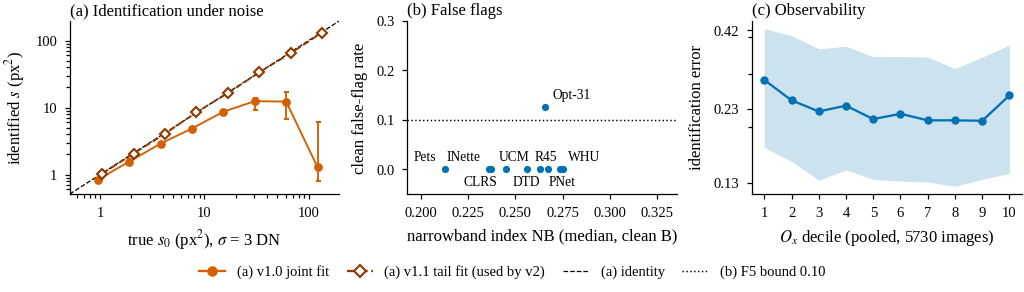

In [56]:
# === 8.2 Figure 6: limits ===
# @needs-complete
def build_fig6():
    d = dict(figsize=[CVPR_TEXT_W, 2.0])
    if len(NOISY_IF):
        s0s = sorted(NOISY_IF.s0.unique())
        series = []
        for col, lab, color, mk, ls, xs, filled in (("s_use", "v1.0 joint fit", OURS_COLOR, "o", "-", 0.95, True),
                                                    ("s_v11", "v1.1 tail fit (used by v2)", "#8C3800", "D", "--", 1.05, False)):
            per = [NOISY_IF[NOISY_IF.s0 == s][col].astype(float).values for s in s0s]
            st = [q3stats(v) for v in per]
            series.append(dict(label=lab, color=color, marker=mk, ls=ls, xshift=xs, filled=filled, med=[q["med"] for q in st],
                               q1=[q["q1"] for q in st], q3=[q["q3"] for q in st]))
        d["noisy"] = dict(s0=s0s, series=series)
    xs, ys, labs = [], [], []
    for x in [x for x in DISPLAY_ORDER if x in DATASETS_OK]:
        if x in AS["nb"] and len(F45T) and (F45T.dataset == x).any():
            xs.append(float(np.median(AS["nb"][x])))
            ys.append(float(F45T[F45T.dataset == x].flag_clean.iloc[0]))
            labs.append(DS_SHORT[x])
    d["nb"] = dict(x=xs, y=ys, labels=labs, max_clean=PREREG["F5"]["max_flag_clean"])
    if AS["r9"]:
        O = np.concatenate([np.asarray(v["O"], float) for v in AS["r9"].values()])
        E = np.concatenate([np.asarray(v["err"], float) for v in AS["r9"].values()])
        ok = np.isfinite(O) & np.isfinite(E)
        O, E = O[ok], E[ok]
        edges = np.percentile(O, np.linspace(0, 100, 11))
        idx = np.clip(np.searchsorted(edges, O, side="right") - 1, 0, 9)
        st = [q3stats(E[idx == k]) for k in range(10)]
        d["obs"] = dict(dec=list(range(1, 11)), med=[q["med"] for q in st], q1=[q["q1"] for q in st], q3=[q["q3"] for q in st],
                        xlabel=f"$O_x$ decile (pooled, {len(O)} images)")
    return d

make_figure("fig6_limits", build_fig6)

**Figure S5 (estimator ablation).** (a) Pooled unflagged MAE (seed 0) of ATC@$\hat s$ and its reported variants: pixel transport PT (= the probe's accuracy on A2 degraded to $\hat s$), importance-weighted PT_anchor, DoC@$\hat s$, ATC-NE@$\hat s$ and AutoEval-LS with $\log(1+\hat s)$ as a meta-feature. (b) The noise-path variants (two-stage subtraction, v1.1 tail fit, no GOF test) on the datasets where block O1 ran: all conditions (filled) and flagged conditions only (open). Bars: hierarchical 95% bootstrap CIs (10,000 resamples). Dashed line and grey band: the oracle ATC calibrated at the true $(s_0,\sigma_0)$, which uses information no label-free method has.

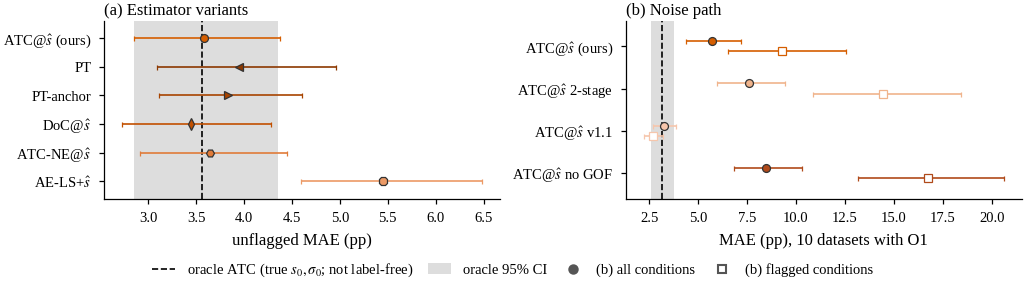

In [57]:
# === 8.3 Figure S5: estimator ablation ===
# @needs-complete
def _abl_row(m, key_a, key_b=None):
    v = EST_ABL[m]
    r = dict(label=mlabel(m), color=mcolor(m), marker=mmarker(m), a=[PPF * v[key_a], PPF * v[key_a + "_ci"][0], PPF * v[key_a + "_ci"][1]])
    if key_b:
        r["b"] = [PPF * v[key_b], PPF * v[key_b + "_ci"][0], PPF * v[key_b + "_ci"][1]]
    return r

def build_figS5():
    d = dict(figsize=[CVPR_TEXT_W, 2.0], panels=[None, None])
    if len(U0):
        o = EST_ABL["oracle_ATC"]
        d["panels"][0] = dict(rows=[_abl_row(m, "unflagged") for m in EST_ABL_METHODS], xlabel="unflagged MAE (pp)",
                              oracle=dict(x=PPF * o["unflagged"], lo=PPF * o["unflagged_ci"][0], hi=PPF * o["unflagged_ci"][1]))
    if O1_DS:
        o = EST_ABL["oracle_ATC"]
        d["panels"][1] = dict(rows=[_abl_row(m, "all_o1", "flag_o1") for m in NOISE_METHODS], xlabel=f"MAE (pp), {len(O1_DS)} datasets with O1",
                              oracle=dict(x=PPF * o["all_o1"], lo=PPF * o["all_o1_ci"][0], hi=PPF * o["all_o1_ci"][1]),
                              legend_a="all conditions", legend_b="flagged conditions")
    return d

make_figure("figS5_estimator_ablation", build_figS5)

**Figure S6 (identification ablation and sensitivity).** (a) Median relative identification error of v1.0 and the identification variants (raw = uncalibrated median knee, mean-based, Theorem-3 batch matching, single re-blur ratio at $\eta$ = 4) on clean in-family vs. label-shift conditions (points: median over datasets of the per-dataset medians; bars: interquartile range over datasets; dotted: the F4 threshold 0.15). (b) GOF flag rates on clean and noisy in-family conditions as a function of $\alpha$ (mean over datasets; dotted vertical: the frozen $\alpha$ = 0.01; dotted horizontal: the F5 bounds). (c) Identification error when the knee fit uses $K\in\{1,4,7,13\}$ re-blur levels (refit on the column subset with its own source calibration). (d) Identification error against the target size $n_Q$ (50 random subsamples per size; open markers: all of B per dataset), with the fitted log-log slope ($-1/2$ is the parametric rate).

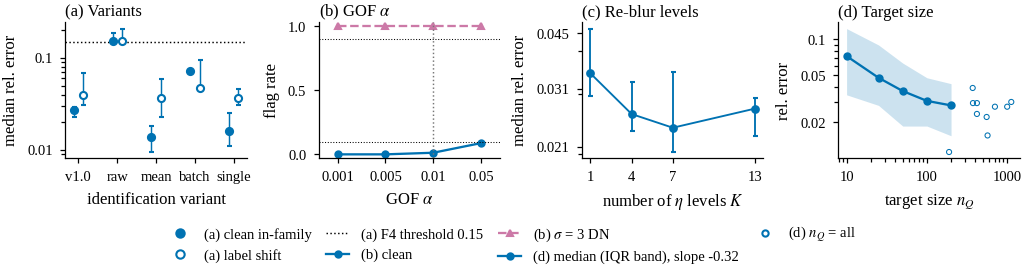

In [58]:
# === 8.4 Figure S6: identification ablation and sensitivity ===
# @needs-complete
def build_figS6():
    d = dict(figsize=[CVPR_TEXT_W, 1.9])
    if len(CLEAN_IF):
        names = [n for _, n in ID_VARIANTS]
        d["variants"] = dict(names=names, f4=PREREG["F4"]["max_median_rel_err"],
                             clean={k: [ID_ABL[n]["clean"][k] for n in names] for k in ("med", "q1", "q3")},
                             ls={k: [ID_ABL[n]["ls"][k] for n in names] for k in ("med", "q1", "q3")})
        d["alpha"] = GOF_SENS
        d["K"] = dict(K=list(K_SENS), **{k: [K_SENS[kk][k] for kk in K_SENS] for k in ("med", "q1", "q3")})
    if NQ_SENS is not None:
        d["nq"] = NQ_SENS
    return d

make_figure("figS6_identification_sensitivity", build_figS6)

**Figure S7 (efficiency).** Pooled unflagged MAE against the measured extra GPU cost of each label-free method: extra forward passes beyond the target features (degraded source copies, surrogate grids, meta-sets, anchors), converted to GPU-seconds with each (dataset, encoder) pair's measured throughput and averaged over pairs (seed 0). Methods that need no extra pass sit at the axis floor labelled 0. Dashed: the Pareto frontier. ATC@$\hat s$ additionally spends CPU time in the pixel stage (Table T10).

     method  extra_images  extra_gpu_s  unflagged_mae
         AC           0.0       0.0000         0.2828
        COT           0.0       0.0000         0.1398
        DoC         573.2       1.9645         0.2521
        ATC         573.2       1.9645         0.2138
     ATC_NE         573.2       1.9645         0.2100
       COTT         573.2       1.9645         0.1293
    SAC_ATC       11464.0      39.2897         0.1056
         AE        6573.2      22.5264         0.0654
      AE_LS        6573.2      22.5264         0.0660
      AE_FD        6573.2      22.5264         0.0871
    NucNorm        6000.0      20.5619         0.1040
      ATC_s       11896.0      40.7681         0.0358
         PT       11896.0      40.7681         0.0395
      DoC_m       11896.0      40.7681         0.0345
   ATC_NE_m       11896.0      40.7681         0.0365
  PT_anchor       13042.2      44.6964         0.0384
    AE_LS_s        6573.2      22.5264         0.0545
     ATC_m2       16828.7   

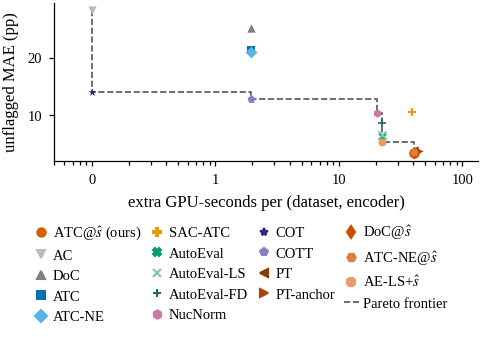

In [59]:
# === 8.5 Figure S7: efficiency ===
# @needs-complete
TIM = AS["timing"]

def extra_cost_table():
    t = TIM[(TIM.seed == 0) & TIM.unit.str.startswith("B3_") & (TIM.encoder != "pixel")].copy() if len(TIM) else pd.DataFrame()
    if not len(t):
        return pd.DataFrame()
    g = lambda c: t[c].fillna(0.0) if c in t else 0.0
    meta_half = g("img_meta") / 2.0
    imgs = {"AC": 0.0 * g("nA2"), "COT": 0.0 * g("nA2"), "DoC": g("nA2"), "ATC": g("nA2"), "ATC_NE": g("nA2"), "COTT": g("nA2"),
            "SAC_ATC": g("img_A2_grid") + g("img_A2_grid_noisy"), "AE": meta_half + g("nA2"), "AE_LS": meta_half + g("nA2"),
            "AE_FD": meta_half + g("nA2"), "NucNorm": meta_half, OURS: g("img_src_main"), "PT": g("img_src_main"), "DoC_m": g("img_src_main"),
            "ATC_NE_m": g("img_src_main"), "PT_anchor": g("img_src_main") + g("nA2") + g("nB"), "AE_LS_s": meta_half + g("nA2"),
            "ATC_m2": g("img_src_main") + g("img_src_ATC_m2"), "ATC_m_v11": g("img_src_main") + g("img_src_ATC_m_v11"),
            "ATC_m_noGOF": g("img_src_main") + g("img_src_ATC_m_noGOF")}
    rows = [dict(method=m, extra_images=float(np.mean(v)), extra_gpu_s=float(np.mean(v * t.sec_per_img))) for m, v in imgs.items()]
    return pd.DataFrame(rows)

COST = extra_cost_table()
if len(COST):
    COST["unflagged_mae"] = [pooled(U0, m) for m in COST.method]
    print(COST.round(4).to_string(index=False))
    COST.to_csv(os.path.join(LOG_DIR, "efficiency.csv"), index=False)

def build_figS7():
    d = dict(figsize=[CVPR_COL_W, 2.3], points=[])
    if not len(COST):
        return d
    keep = [m for m in [OURS] + BASELINES + ["PT", "PT_anchor", "DoC_m", "ATC_NE_m", "AE_LS_s"] if m in set(COST.method)]
    pos = COST[COST.extra_gpu_s > 0].extra_gpu_s
    d["floor"] = float(10 ** np.floor(np.log10(pos.min() / 3))) if len(pos) else 0.1
    for m in keep:
        r = COST[COST.method == m].iloc[0]
        d["points"].append(dict(key=m, label=mlabel(m), color=mcolor(m), marker=mmarker(m), cost=float(r.extra_gpu_s), mae=PPF * float(r.unflagged_mae)))
    return d

make_figure("figS7_efficiency", build_figS7)

**Figure S9 (real shifts; rule F9 and addendum P3, P4).** Absolute error (pp) on the five real shifts: RESISC45 ↔ UC Merced and PatternNet ↔ RESISC45 on their shared classes, and LandCover.ai 25 cm → 50 cm (P50, resampled to the 25 cm grid). Rows: ATC@$\hat s$ (v1.0 and v2), two plug-ins (DoC@$\hat s$, COTT@$\hat s$) above the divider, the eleven baselines below. Each point is one (encoder, extra target blur $s\in\{0,4,16\}$) cell; open markers: conditions the blur-model check flagged; tick: mean over cells.

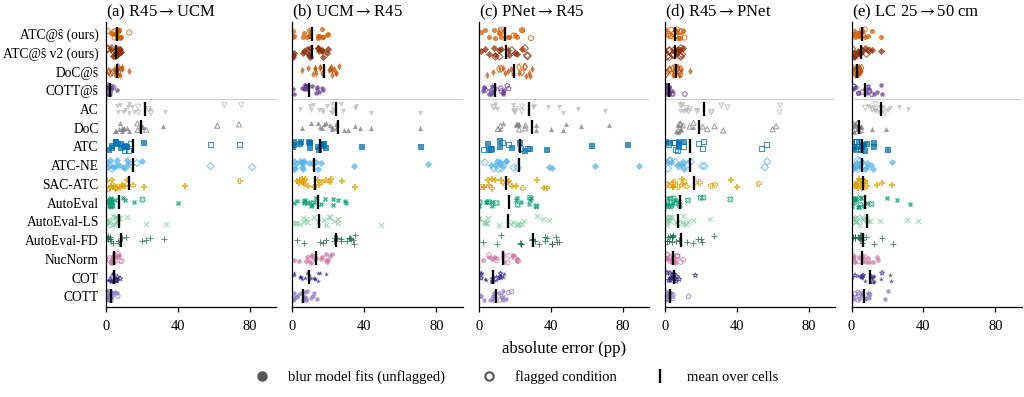

In [60]:
# === 8.6 Figure S9: real shifts ===
# @needs-complete
PAIR_TITLE = {"resisc45_to_ucm": "R45$\\rightarrow$UCM", "ucm_to_resisc45": "UCM$\\rightarrow$R45", "patternnet_to_resisc45": "PNet$\\rightarrow$R45",
              "resisc45_to_patternnet": "R45$\\rightarrow$PNet", "lcai25_to_lcai50": "LC 25$\\rightarrow$50 cm"}
S9_METHODS = [OURS, OURS_V2, "DoC_m", "COTT_m"] + BASELINES

def build_figS9():
    d = dict(figsize=[CVPR_TEXT_W, 2.7], methods=S9_METHODS, panels=[], captions=[])
    for src, tgt in REAL_PAIRS:
        name = f"{src}_to_{tgt}"
        g = REALC[REALC.dataset == name] if len(REALC) else REALC
        d["captions"].append(PAIR_TITLE[name])
        if not len(g):
            d["panels"].append(None)
            continue
        rows = []
        for m in S9_METHODS:
            e_ = PPF * g["e_" + m].values if ("e_" + m) in g else np.full(len(g), np.nan)
            rows.append(dict(err=e_, flagged=g.flagged.astype(float).values, jitter=rng_for("figS9", name, m).uniform(-0.25, 0.25, len(e_)),
                             mean=float(np.nanmean(e_)) if np.isfinite(e_).any() else np.nan, color=mcolor(m), marker=mmarker(m)))
        d["panels"].append(dict(title=PAIR_TITLE[name], rows=rows, dividers=[4]))
    return d

make_figure("figS9_real_shifts", build_figS9)

**Figure S13 (stress tests, pixel-only, seed 0).** (a) Noise sweep: identified $s$ against the true $s_0$ for $\sigma\in\{1.5,3,6\}$ DN with the v1.0 joint fit (solid) and the v1.1 tail fit (dashed); median over datasets; the legend gives each $\sigma$'s flag rate and median estimated $\hat\sigma$ (dotted: identity). (b) PSF misspecification: $\hat s$ against the Gaussian-equivalent variance (per-axis second moment) of box, disk and anisotropic Gaussian kernels (median and interquartile range over datasets; flag rates in the legend). (c) JPEG re-compression, a non-semigroup shift: GOF flag rate (abstention power) against quality.

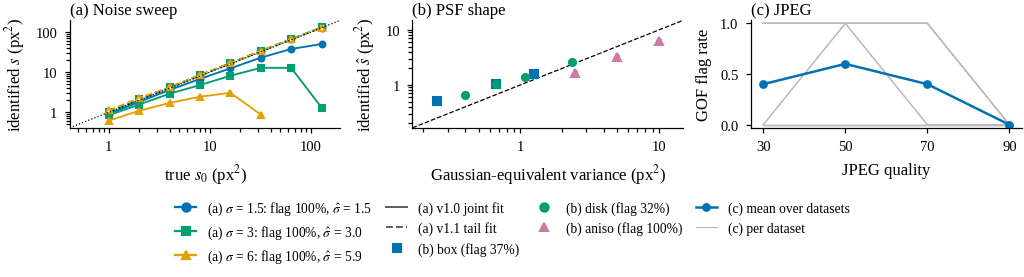

In [61]:
# === 8.7 Figure S13: stress tests ===
# @needs-complete
def build_figS13():
    d = dict(figsize=[CVPR_TEXT_W, 1.9])
    if not len(STRESS):
        return d
    cols, mks = {1.5: "#0072B2", 3.0: "#009E73", 6.0: "#E69F00"}, {1.5: "o", 3.0: "s", 6.0: "^"}
    nz = STRESS[STRESS.family == "noise"]
    series = []
    for sg in sorted(nz.sigma.unique()):
        h = nz[nz.sigma == sg]
        s0s = sorted(h.s0.unique())
        flag, sig = float(h.flagged.mean()), float(h.sig_use.median())
        for col, ls in (("s_use", "-"), ("s_v11", "--")):
            series.append(dict(s0=s0s, med=[float(np.nanmedian(h[h.s0 == s][col].astype(float))) for s in s0s], color=cols.get(sg, "#555555"),
                               marker=mks.get(sg, "o"), ls=ls, legend=f"$\\sigma$ = {sg:g}: flag {flag:.0%}, $\\hat\\sigma$ = {sig:.1f}"))
    d["noise"] = dict(series=series)
    groups = []
    for fam, col, mk in (("box", "#0072B2", "s"), ("disk", "#009E73", "o"), ("aniso", "#CC79A7", "^")):
        h = STRESS[STRESS.family == fam]
        if not len(h):
            continue
        pars = sorted(h.param.unique(), key=lambda p: float(h[h.param == p].truth.iloc[0]))
        st = [q3stats(h[h.param == p].s_hat.astype(float).values) for p in pars]
        groups.append(dict(truth=[float(h[h.param == p].truth.iloc[0]) for p in pars], med=[q["med"] for q in st], q1=[q["q1"] for q in st],
                           q3=[q["q3"] for q in st], color=col, marker=mk, label=f"{fam} (flag {h.flagged.mean():.0%})"))
    d["psf"] = dict(groups=groups)
    jp = STRESS[STRESS.family == "jpeg"].copy()
    if len(jp):
        jp["q"] = jp.param.astype(float)
        qs = sorted(jp.q.unique())
        per = [h.sort_values("q") for _, h in jp.groupby("dataset")]
        d["jpeg"] = dict(q=qs, mean=[float(jp[jp.q == q].flagged.mean()) for q in qs], per_ds_q=[h.q.values for h in per],
                         per_ds_rate=[h.flagged.astype(float).values for h in per])
    return d

make_figure("figS13_stress_tests", build_figS13)

**Figure 8 (real 25 cm → 50 cm shift; addendum G1).** LandCover.ai models trained on 25 cm tiles meet the 50 cm product (resampled to the 25 cm grid). (a) Centre crops (2× zoom) of a 25 cm source tile, the same tile re-degraded by the blur-only model at $\hat s$, the same tile passed through the identified resampling chain (blur $\hat\Delta$ → 50 cm → bicubic), and a real 50 cm tile. (b) Median response curves $\rho(\eta)$ of the real 50 cm tiles, the chain-simulated and blur-only-simulated sources, and the native 25 cm source: the chain reproduces the real product. (c) Absolute accuracy error per encoder (points; tick: mean) on the real shift without added blur, in three groups: ATC, ATC@$\hat s$ and ATC@GSD; COTT, COTT@$\hat s$ and COTT@GSD; the strongest other baseline and the best other GSD-aware estimator on this pair. Median GOF $p$-values of the blur-only and chain models are in the axis label.

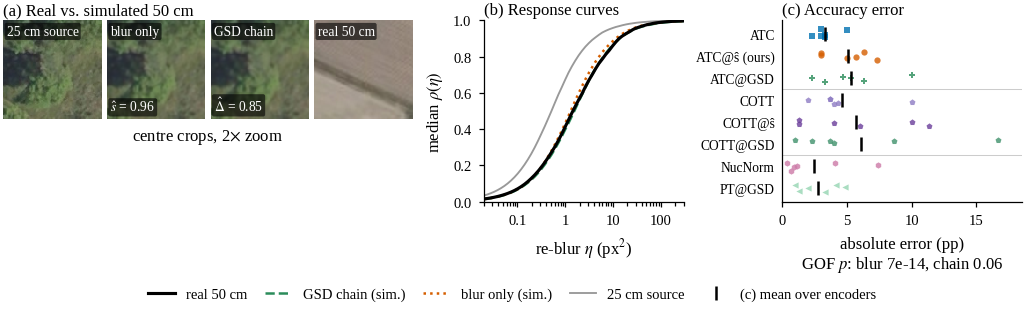

In [62]:
# === 8.8b Figure 8: real 25 -> 50 cm shift with the GSD-aware path ===
# @needs-complete
def _zoom(img, f=2):
    a = np.asarray(img, np.uint8)
    h, w = a.shape[:2]
    c = a[h // 4:h // 4 + h // 2, w // 4:w // 4 + w // 2]
    return np.repeat(np.repeat(c, f, 0), f, 1)

def build_fig8():
    d = dict(figsize=[CVPR_TEXT_W, 2.15], missing_msg="LandCover.ai pair missing in this run")
    V = AS.get("gsd_vis")
    if V is not None:
        d["tiles"] = dict(imgs=[_zoom(V["tile_source"]), _zoom(V["tile_blur"]), _zoom(V["tile_chain"]), _zoom(V["tile_target"])],
                          top=["25 cm source", "blur only", "GSD chain", "real 50 cm"],
                          bottom=["", f"$\\hat{{s}}$ = {V['s_hat']:.2f}", f"$\\hat\\Delta$ = {V['delta']:.2f}", ""],
                          xlabel="centre crops, 2$\\times$ zoom")
        d["curves"] = dict(eta=V["eta"], series=[
            dict(y=V["rho_target"], label="real 50 cm", color="black", ls="-", lw=1.5, z=3),
            dict(y=V["rho_chain"], label="GSD chain (sim.)", color=GSD_COLOR, ls="--", lw=1.2),
            dict(y=V["rho_blur"], label="blur only (sim.)", color=OURS_COLOR, ls=":", lw=1.2),
            dict(y=V["rho_source"], label="25 cm source", color="#999999", ls="-", lw=0.9, z=1)])
    g = regime_cells(REALC[REALC.dataset == "lcai25_to_lcai50"], "real0") if len(REALC) else REALC
    if len(g):
        _mae = lambda m: float(np.nanmean(g["e_" + m])) if ("e_" + m) in g and g["e_" + m].notna().any() else np.inf
        _b3 = min([b for b in BASELINES if b not in ("ATC", "COTT")], key=_mae)          # strongest other baseline on this pair
        _g3 = min([m for m in GSD_METHODS if m not in ("ATC_g", "COTT_g")], key=_mae)     # best other GSD-aware estimator
        ms = ["ATC", OURS, "ATC_g", "COTT", "COTT_m", "COTT_g", _b3, _g3]
        rows = []
        for m in ms:
            if ("e_" + m) not in g:
                continue
            e_ = PPF * g["e_" + m].values
            rows.append(dict(label=plain_label(m), err=e_, jitter=rng_for("fig8", m).uniform(-0.22, 0.22, len(e_)),
                             mean=float(np.nanmean(e_)) if np.isfinite(e_).any() else np.nan, color=mcolor(m), marker=mmarker(m)))
        pg = float(g.p_gof.median()) if "p_gof" in g else np.nan
        pc = float(g.p_gof_gsd.median()) if "p_gof_gsd" in g else np.nan
        _ps = lambda p: "n/a" if not np.isfinite(p) else (f"{p:.0e}".replace("e-0", "e-") if p < 1e-3 else f"{p:.2f}")
        d["errors"] = dict(rows=rows, dividers=[3, 6], xlabel=f"absolute error (pp)\nGOF $p$: blur {_ps(pg)}, chain {_ps(pc)}")
    return d

make_figure("fig8_real_gsd", build_fig8)

**Figure S16 (noise-aware path, addendum N1–N3).** (a) Identification under sensor noise (stress sweep, $\sigma\in\{1.5,3,6\}$ DN): the v1.0 joint fit collapses at large blur, the v1.1 tail fit used by v2 follows the identity (median over datasets; dotted: identity). (b) Abstention: flag rate of the v1.0 blur check and of v2 (both checks) on the noise sweep and on PSF and JPEG stress families (dotted: 0.10). (c) MAE on the noisy in-family cells per dataset (all seeds) for ATC@$\hat s$ v1.0, ATC@$\hat s$ v2 and the strongest baseline of the regime (bars: 95% bootstrap CIs over conditions).

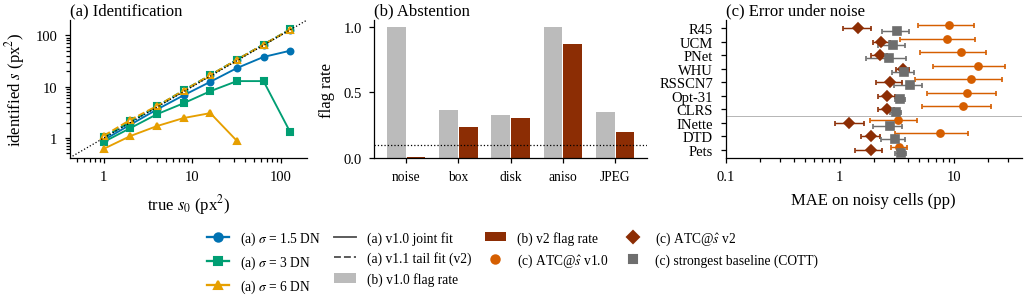

In [63]:
# === 8.8c Figure S16: noise-aware path ===
# @needs-complete
def build_figS16():
    d = dict(figsize=[CVPR_TEXT_W, 2.1], v2_color=V2_COLOR)
    if len(STRESS):
        cols, mks = {1.5: "#0072B2", 3.0: "#009E73", 6.0: "#E69F00"}, {1.5: "o", 3.0: "s", 6.0: "^"}
        nz = STRESS[STRESS.family == "noise"]
        series = []
        for sg in sorted(nz.sigma.unique()):
            h = nz[nz.sigma == sg]
            s0s = sorted(h.s0.unique())
            for col, ls in (("s_use", "-"), ("s_v11", "--")):
                series.append(dict(s0=s0s, med=[float(np.nanmedian(h[h.s0 == s][col].astype(float))) for s in s0s], color=cols.get(sg, "#555555"),
                                   marker=mks.get(sg, "o"), ls=ls, legend=f"$\\sigma$ = {sg:g} DN"))
        d["ident"] = dict(series=series)
        groups, v1, v2 = [], [], []
        for fam, lab in (("noise", "noise"), ("box", "box"), ("disk", "disk"), ("aniso", "aniso"), ("jpeg", "JPEG")):
            h = STRESS[STRESS.family == fam]
            if len(h):
                groups.append(lab)
                v1.append(float(h.flagged.astype(float).mean()))
                v2.append(float(h.flagged2.astype(float).mean()) if "flagged2" in h else np.nan)
        d["flags"] = dict(groups=groups, v1=v1, v2=v2)
    g = regime_df("noisy")
    if len(g):
        dss = [x for x in DISPLAY_ORDER if (g.dataset == x).any()]
        bb = REGIME_STATS.get("noisy", {}).get("best_base")
        ser = []
        for m, lab, col, mk, dy in ((OURS, "ATC@$\\hat{s}$ v1.0", OURS_COLOR, "o", 0.22), (OURS_V2, "ATC@$\\hat{s}$ v2", V2_COLOR, "D", 0.0),
                                    (bb, f"strongest baseline ({plain_label(bb)})" if bb else "baseline", "#6E6E6E", "s", -0.22)):
            if m is None:
                continue
            st = [_ds_stat(g, x, m, "mean") for x in dss]
            ser.append(dict(x=[v[0] for v in st], lo=[v[1] for v in st], hi=[v[2] for v in st], dy=dy, label=lab, color=col, marker=mk))
        allv = finite([v for s_ in ser for k in ("x", "lo", "hi") for v in s_[k]])
        allv = allv[allv > 0]
        d["mae"] = dict(datasets=[DS_SHORT[x] for x in dss], n_rs=sum(DS_INFO[x]["rs"] for x in dss), series=ser,
                        xlim=[float(10 ** np.floor(np.log10(allv.min() * 0.8))) if len(allv) else 0.1, float(allv.max() * 1.4) if len(allv) else 10.0])
    return d

make_figure("figS16_noise_v2", build_figS16)

### Tables T5 (ablations), T10 (compute) and T11 (datasets)

In [64]:
# === 8.8 Tables T5, T10, T11 ===
# @needs-complete
def table_T5():
    rows, raw = [], []
    for m in EST_ABL_METHODS + NOISE_METHODS[1:] + ["oracle_ATC", "oracle_PT"]:
        v = EST_ABL[m]
        lab = mlabel(m).replace("$\\hat{s}$", "ŝ").replace("+ŝ", "+ŝ")
        rows.append([lab + (" (oracle)" if m.startswith("oracle") and "oracle" not in lab else ""),
                     num_ci(v["unflagged"], *v["unflagged_ci"], 1, PPF), num_ci(v["all_o1"], *v["all_o1_ci"], 1, PPF),
                     num_ci(v["flag_o1"], *v["flag_o1_ci"], 1, PPF), DASH, DASH])
        raw.append(dict(kind="estimator", variant=m, unflagged_mae=v["unflagged"], unflagged_lo=v["unflagged_ci"][0], unflagged_hi=v["unflagged_ci"][1],
                        all_o1_mae=v["all_o1"], flagged_o1_mae=v["flag_o1"]))
    n_est = len(rows)
    for col, name in ID_VARIANTS:
        v = ID_ABL[name]
        rows.append([f"id: {name}", DASH, DASH, DASH, f"{num(v['clean']['med'], 3)} [{num(v['clean']['q1'], 3)}, {num(v['clean']['q3'], 3)}]",
                     f"{num(v['ls']['med'], 3)} [{num(v['ls']['q1'], 3)}, {num(v['ls']['q3'], 3)}]"])
        raw.append(dict(kind="identification", variant=col, clean_med=v["clean"]["med"], clean_q1=v["clean"]["q1"], clean_q3=v["clean"]["q3"],
                        ls_med=v["ls"]["med"], ls_q1=v["ls"]["q1"], ls_q3=v["ls"]["q3"]))
    cap = (f"Ablations (seed 0). Estimators: pooled MAE in pp with hierarchical 95\\% CIs; all-condition and flagged-only MAE use the "
           f"{len(O1_DS)} datasets on which block O1 ran. Oracles use the true $(s_0,\\sigma_0)$ and are not label-free. Identification: "
           f"median over datasets of the per-dataset median $|\\hat{{s}}-s_0|/s_0$ [interquartile range over datasets], clean in-family vs.\\ "
           f"label-shift conditions.")
    hdr = ["Variant", "Unflagged MAE", "All-cond. MAE", "Flagged MAE", "Clean id. err.", "Label-shift id. err."]
    return write_table("T5_ablations", hdr, rows, pd.DataFrame(raw), cap, "tab:ablations", midrules=(n_est,))

def _block_of(unit):
    if unit.startswith("B3_"):
        return "B3" if unit.endswith("_s0") else "B6"
    return unit.split("_")[0]

def _timed(rec):
    return (rec or {}).get("status") in ("done", "partial") and rec.get("start_h") is not None and rec.get("end_h") is not None

def _timing_record(u, rec, legacy):
    """(record, reused_from_run_1): a unit's own timing when a session of this run computed it, run 1's timing when the unit
    was reused from run 1's checkpoints, else (None, False)."""
    if _timed(rec):
        return rec, False
    if (rec or {}).get("status") == "resumed" and _timed(legacy.get(u)):
        return legacy[u], True
    return None, False

def table_T10():
    st = RUN_STATE.get("UNIT_STATUS", {})
    legacy = RUN_STATE.get("LEGACY_UNIT_STATUS") or LEGACY_STATE.get("UNIT_STATUS", {}) or {}
    blocks, from_run1 = {}, set()
    for u, rec in st.items():
        rec, reused = _timing_record(u, rec, legacy)
        if rec is None:
            continue
        if reused:
            from_run1.add(_block_of(u))
        blocks.setdefault(_block_of(u), []).append(60.0 * (rec["end_h"] - rec["start_h"]))
    blocks["B7"] = blocks.get("B7", []) + [60.0 * (elapsed_h() - B7_START_H)]
    names = {"B0": "setup, installs, downloads, self-check", "B1": "theory checks + power-law study", "B2": "LandCover.ai physics",
             "B3": "main evaluation, seed 0", "B4": "real shifts", "B5": "mechanism screen (fp32)", "B6": "seeds 1-2",
             "B7": "analyses, figures, tables (to end of Section 8)"}
    rows, raw = [], []
    for b in ["B0", "B1", "B2", "B3", "B4", "B5", "B6", "B7"]:
        if b in blocks:
            rows.append([b, f"{sum(blocks[b]):.1f}", DASH, DASH, f"{names[b]} ({len(blocks[b])} unit{'s' if len(blocks[b]) != 1 else ''}"
                         + ("; includes units reused from run 1)" if b in from_run1 else ")")])
            raw.append(dict(section="block", item=b, minutes=sum(blocks[b]), images=np.nan, img_per_s=np.nan, note=names[b]))
    n1 = len(rows)
    t = TIM[TIM.encoder != "pixel"] if len(TIM) else TIM
    for e in MECH_ENCODERS:
        g = t[t.encoder == e] if len(t) else t
        imgs = float(g[[c for c in g.columns if c.startswith("img_")]].fillna(0).values.sum()) if len(g) else 0.0
        feat = float(g.feat_seconds.sum()) if len(g) else 0.0
        mech = AS["mech"].get(e, {})
        r32 = mech.get("rate_fp32") if isinstance(mech, dict) else None
        b5, _ = _timing_record(f"B5_{e}", st.get(f"B5_{e}", {}), legacy)
        b5m = 60.0 * (b5["end_h"] - b5["start_h"]) if b5 is not None else np.nan
        note = f"fp16 {imgs / feat:.0f} img/s; " if feat > 0 else ""
        note += f"fp32 {r32:.0f} img/s" if r32 else "fp32 rate not measured"
        rows.append([ENC_INFO[e][0], f"{(feat / 60.0 + (b5m if np.isfinite(b5m) else 0.0)):.1f}", f"{imgs:.0f}" if imgs else DASH,
                     f"{imgs / feat:.0f}" if feat > 0 else DASH, note])
        raw.append(dict(section="encoder", item=e, minutes=feat / 60.0 + (b5m if np.isfinite(b5m) else 0.0), images=imgs,
                        img_per_s=imgs / feat if feat > 0 else np.nan, fp32_rate=r32, b5_minutes=b5m))
    n2 = len(rows)
    for x in [x for x in DISPLAY_ORDER if len(TIM) and (TIM.dataset == x).any()]:
        g = TIM[(TIM.dataset == x)]
        pix = float(g[g.encoder == "pixel"].seconds.sum())
        gpu = float(g[g.encoder != "pixel"].seconds.sum())
        imgs = float(g[[c for c in g.columns if c.startswith("img_")]].fillna(0).values.sum())
        seeds = sorted(g.seed.unique().tolist())
        rows.append([DISPLAY[x], f"{(pix + gpu) / 60.0:.1f}", f"{imgs:.0f}", DASH, f"pixel {pix / 60.0:.1f} min, encoders {gpu / 60.0:.1f} min; seeds {seeds}"])
        raw.append(dict(section="dataset", item=x, minutes=(pix + gpu) / 60.0, images=imgs, img_per_s=np.nan, pixel_minutes=pix / 60.0,
                        encoder_minutes=gpu / 60.0))
    cap = ("Compute on one GPU: wall-clock per block, per encoder (feature extraction in all evaluation units plus its mechanism unit) and "
           "per dataset (pixel stage and encoder stages, all seeds), with forward passes (images $\\times$ blur levels) and measured "
           "throughput. Timings are measured in the session that computed each unit (setup: the last session); units reused from run 1 "
           "keep run 1's timings.")
    return write_table("T10_compute", ["Item", "Minutes", "Forward passes", "img/s", "Note"], rows, pd.DataFrame(raw), cap, "tab:compute",
                       pcols={4: 2.6}, midrules=(n1, n2))

SOURCE_SHORT = {"resisc45": "HF torchgeo/resisc45 (zip)", "ucm": "HF torchgeo/ucmerced (zip)", "patternnet": "HF torchgeo/PatternNet (zip)",
                "whu_rs19": "HF jonathan-roberts1/WHU-RS19", "rsscn7": "HF jonathan-roberts1/RSSCN7", "optimal31": "HF jonathan-roberts1/Optimal-31",
                "clrs": "HF jonathan-roberts1/CLRS", "imagenette": "fast.ai S3 imagenette2-320.tgz", "dtd": "torchvision DTD (partition 1)",
                "pets": "torchvision OxfordIIITPet"}

def table_T11():
    dstat = RUN_STATE.get("DATASET_STATUS", {})
    rows, raw = [], []
    for x in DISPLAY_ORDER:
        info, s = DS_INFO[x], dstat.get(x, {})
        lic = s.get("licence", DASH)
        lic_short = "not machine-readable; verify at source" if str(lic).startswith("see ") else lic
        q = info["quota"]
        rows.append([DISPLAY[x], SOURCE_SHORT[x], lic_short, str(s.get("classes", info["n_classes"])), f"{q[0]}/{q[1]}/{q[2]}",
                     str(s.get("images", DASH)), s.get("status", "not run")])
        raw.append(dict(dataset=x, source=info["source"], licence=lic, classes=s.get("classes"), quota=f"{q[0]}/{q[1]}/{q[2]}",
                        images=s.get("images"), expected=info["expected"], status=s.get("status", "not run"), reason=s.get("reason", "")))
    ls_ = RUN_STATE.get("LCAI_STATUS", {})
    cnt = ls_.get("counts", {})
    rows.append(["LandCover.ai", "landcover.ai.linuxpolska.com", "CC BY-NC-SA 4.0", "3", "8/8/17 orthophotos",
                 f"41 orthophotos; {sum(cnt.values())} tiles" if cnt else DASH, ls_.get("status", "not run")])
    raw.append(dict(dataset="landcoverai", source=LCAI_URL, licence=LCAI_LICENCE, classes=3, quota="orthophotos A1 8 / A2 8 / B 17; P50 8",
                    images=sum(cnt.values()) if cnt else None, expected=41, status=ls_.get("status", "not run"), reason=ls_.get("reason", "")))
    cap = ("Datasets. Every scene dataset is pooled, split 60/20/20 per class with stream (seed, `split', dataset), and the per-class quotas "
           "A1 (probe) / A2 (source) / B (target) are drawn from train/val/test with stream (seed, `quota', dataset, split); official splits "
           "are ignored. LandCover.ai is split by orthophoto (stream (0, `lcai\\_split')). Licence strings are read from the HF dataset card "
           "where machine-readable; full strings are in the CSV. LandCover.ai: 3 task classes (background, woodland, water); quotas count "
           "orthophotos (A1/A2/B); the 8 orthophotos at 50 cm form P50.")
    hdr = ["Dataset", "Source", "Licence", "Classes", "Quota", "Images", "Status"]
    return write_table("T11_datasets", hdr, rows, pd.DataFrame(raw), cap, "tab:datasets", pcols={1: 1.42, 2: 1.25, 4: 0.62, 5: 0.75},
                       midrules=(N_RS_ALL, len(DISPLAY_ORDER)))

N_RS_ALL = sum(DS_INFO[x]["rs"] for x in DISPLAY_ORDER)
for _name, _fn in (("T5_ablations", table_T5), ("T10_compute", table_T10), ("T11_datasets", table_T11)):
    make_table(_name, _fn)
print("Section 8 figures:", {k: v.get("ok") for k, v in FIG_STATUS.items() if k.startswith(("fig6", "figS5", "figS6", "figS7", "figS9", "figS13"))})

T5_ablations: 16 rows x 6 cols, width 5.40 in of 6.875 in -> fits


,Variant,Unflagged MAE,All-cond. MAE,Flagged MAE,Clean id. err.,Label-shift id. err.
0,ATC@ŝ (ours),"3.6 [2.9, 4.4]","5.7 [4.4, 7.2]","9.3 [6.5, 12.6]",–,–
1,PT,"3.9 [3.1, 5.0]","8.0 [6.2, 10.1]","14.8 [10.7, 19.7]",–,–
2,PT-anchor,"3.8 [3.1, 4.6]","7.8 [6.1, 9.8]","14.5 [10.4, 19.3]",–,–
3,DoC@ŝ,"3.4 [2.7, 4.3]","6.3 [4.8, 7.9]","11.0 [7.8, 14.6]",–,–
4,ATC-NE@ŝ,"3.6 [2.9, 4.4]","5.6 [4.3, 7.0]","8.9 [6.2, 12.2]",–,–
5,AE-LS+ŝ,"5.5 [4.6, 6.5]","6.6 [5.6, 7.8]","8.4 [6.6, 10.6]",–,–
6,ATC@ŝ 2-stage,"3.6 [2.9, 4.4]","7.6 [6.0, 9.5]","14.5 [10.9, 18.4]",–,–
7,ATC@ŝ v1.1,"3.6 [2.9, 4.4]","3.3 [2.7, 3.9]","2.7 [2.2, 3.2]",–,–
8,ATC@ŝ no GOF,"3.6 [2.9, 4.4]","8.5 [6.8, 10.3]","16.8 [13.2, 20.6]",–,–
9,oracle ATC,"3.6 [2.9, 4.4]","3.2 [2.6, 3.8]","2.5 [2.0, 3.0]",–,–


T10_compute: 35 rows x 5 cols, width 5.29 in of 6.875 in -> fits


,Item,Minutes,Forward passes,img/s,Note
0,B0,6.4,–,–,"setup, installs, downloads, self-check (1 unit)"
1,B1,0.0,–,–,theory checks + power-law study (1 unit; inclu...
2,B2,0.4,–,–,LandCover.ai physics (1 unit)
3,B3,259.6,–,–,"main evaluation, seed 0 (10 units)"
4,B4,48.7,–,–,real shifts (5 units)
5,B5,53.9,–,–,mechanism screen (fp32) (17 units; includes un...
6,B6,112.1,–,–,seeds 1-2 (8 units)
7,B7,8.4,–,–,"analyses, figures, tables (to end of Section 8..."
8,DINOv2-S/14,31.5,987808,536,fp16 536 img/s; fp32 178 img/s
9,DINOv2-B/14,2.9,–,–,fp32 50 img/s


T11_datasets: 11 rows x 7 cols, width 6.19 in of 6.875 in -> fits


,Dataset,Source,Licence,Classes,Quota,Images,Status
0,RESISC45,HF torchgeo/resisc45 (zip),cc-by-nc-4.0 (HF dataset card),45,60/25/25,31500,loaded
1,UC Merced,HF torchgeo/ucmerced (zip),cc0-1.0 (HF dataset card),21,40/20/20,2100,loaded
2,PatternNet,HF torchgeo/PatternNet (zip),cc-by-4.0 (HF dataset card),38,30/15/15,30400,loaded
3,WHU-RS19,HF jonathan-roberts1/WHU-RS19,cc-by-4.0 (HF dataset card),19,30/10/10,1005,loaded
4,RSSCN7,HF jonathan-roberts1/RSSCN7,other (HF dataset card),7,120/60/60,2800,loaded
5,Optimal-31,HF jonathan-roberts1/Optimal-31,other (HF dataset card),31,30/12/12,1860,loaded
6,CLRS,HF jonathan-roberts1/CLRS,other (HF dataset card),25,30/15/15,15000,loaded
7,Imagenette,fast.ai S3 imagenette2-320.tgz,not machine-readable; verify at source,10,300/100/100,13394,loaded
8,DTD,torchvision DTD (partition 1),not machine-readable; verify at source,47,30/15/15,5640,loaded
9,Oxford-IIIT Pets,torchvision OxfordIIITPet,not machine-readable; verify at source,37,30/15/15,7349,loaded


Section 8 figures: {'fig6_limits': True, 'figS5_estimator_ablation': True, 'figS6_identification_sensitivity': True, 'figS7_efficiency': True, 'figS9_real_shifts': True, 'figS13_stress_tests': True}


## Section 9 · State-of-the-art comparison (T9)
No published numbers exist for this benchmark, so no literature number is quoted. For every metric the target is the **strongest baseline measured in this run** on identical features, probe, conditions and seeds. The status comes from the 95% hierarchical bootstrap CI (10,000 resamples) of the paired difference ours − target: entirely below 0 → EXCEEDED, containing 0 → MATCHED, entirely above 0 → BELOW (lower is better for every metric).

In [65]:
# === 9.1 SOTA targets, paired-difference CIs and statuses ===
# @needs-complete
def _boot_ds(n_ds, key, B=None):
    return rng_for("sota", *key), (B or N_BOOT)

def worst_matrix(df, d, m):
    return cond_matrix(df[df.dataset == d], m)

def boot_worst_diff(df, m_ours, m_base, key):
    """Hierarchical bootstrap of mean_d [worst_enc MAE(ours) - worst_enc MAE(base)]: datasets, then conditions."""
    ds = [x for x in SHOWN if (df.dataset == x).any()]
    mats = []
    for x in ds:
        Mo, Mb = worst_matrix(df, x, m_ours), worst_matrix(df, x, m_base)
        Mb = Mb.reindex(index=Mo.index, columns=Mo.columns)
        mats.append((Mo.values, Mb.values))
    r, B = _boot_ds(len(ds), key)
    out = np.empty(B)
    for b in range(B):
        acc = 0.0
        for j in r.integers(0, len(ds), len(ds)):
            Mo, Mb = mats[j]
            w = r.multinomial(len(Mo), np.full(len(Mo), 1.0 / len(Mo))).astype(float)
            acc += np.nanmax((w @ np.nan_to_num(Mo)) / np.maximum(w @ np.isfinite(Mo), 1e-12)) - \
                np.nanmax((w @ np.nan_to_num(Mb)) / np.maximum(w @ np.isfinite(Mb), 1e-12))
        out[b] = acc / len(ds)
    return out

def pooled_worst(df, m):
    ds = [x for x in SHOWN if (df.dataset == x).any()]
    return float(np.mean([worst_matrix(df, x, m).mean(0).max() for x in ds])) if ds else np.nan

def id_rel_errors(name):
    """Per-dataset arrays of relative errors on clean in-family seed-0 conditions (paired by condition id)."""
    out = {}
    for x in SHOWN:
        c = CLEAN_IF[CLEAN_IF.dataset == x].sort_values("cid")
        if not len(c):
            continue
        if name.startswith("id_feat_"):
            e = name[len("id_feat_"):]
            g = CELLS[(CELLS.dataset == x) & (CELLS.seed == 0) & (CELLS.encoder == e)].set_index("cid")
            if not len(g):
                continue
            est = g.reindex(c.cid).id_feat.values
        else:
            est = c[name].values
        out[x] = np.abs(est.astype(float) - c.s0.values) / c.s0.values
    return out

def boot_median_diff(eo, eb, key):
    ds = [x for x in eo if x in eb]
    r, B = _boot_ds(len(ds), key)
    out = np.empty(B)
    for b in range(B):
        po, pb = [], []
        for j in r.integers(0, len(ds), len(ds)):
            a, c = eo[ds[j]], eb[ds[j]]
            idx = r.integers(0, len(a), len(a))
            po.append(a[idx])
            pb.append(c[idx])
        out[b] = np.nanmedian(np.concatenate(po)) - np.nanmedian(np.concatenate(pb))
    return out

def seed_avg_vectors(m):
    """Multi-seed datasets with every seed: per dataset, list of (seed, per-condition unflagged errors)."""
    out = {}
    for x in SEED_DATASETS:
        g = CELLS[CELLS.dataset == x] if len(CELLS) else CELLS
        if not len(g) or g.seed.nunique() < PREREG["F6"]["n_seeds"]:
            continue
        out[x] = [(k, cond_series(unflagged(g[g.seed == k]), m).values) for k in sorted(g.seed.unique())]
    return out

def seed_avg(m):
    v = seed_avg_vectors(m)
    return float(np.mean([np.mean([s.mean() for _, s in per]) for per in v.values()])) if v else np.nan

def boot_seed_avg_diff(m_ours, m_base, key):
    vo, vb = seed_avg_vectors(m_ours), seed_avg_vectors(m_base)
    ds = [x for x in vo if x in vb]
    if not ds:
        return np.array([np.nan])
    r, B = _boot_ds(len(ds), key)
    out = np.empty(B)
    for b in range(B):
        acc = 0.0
        for j in r.integers(0, len(ds), len(ds)):
            per_o, per_b = vo[ds[j]], vb[ds[j]]
            sizes = [len(s) for _, s in per_o]
            cl = np.concatenate([np.full(n_, i) for i, n_ in enumerate(sizes)])     # (seed, condition) clusters
            idx = r.integers(0, len(cl), len(cl))
            do = np.concatenate([s for _, s in per_o]) - np.concatenate([s for _, s in per_b])
            seeds_m = [do[idx][cl[idx] == i].mean() for i in range(len(sizes)) if (cl[idx] == i).any()]
            acc += np.mean(seeds_m)
        out[b] = acc / len(ds)
    return out

SOTA_ROWS = []

def sota_row(metric, ours_v, cands, key, diff_fn, scale=PPF, nd=1):
    """cands: dict name -> value (lower is better); the target is the best candidate; diff_fn(name) -> bootstrap replicates."""
    cands = {k: v for k, v in cands.items() if np.isfinite(v)}
    if not cands or not np.isfinite(ours_v):
        SOTA_ROWS.append(dict(metric=metric, ours=ours_v, target=None, target_value=np.nan, diff=np.nan, lo=np.nan, hi=np.nan,
                              status="NOT EVALUATED", scale=scale, nd=nd))
        return
    tgt = min(cands, key=cands.get)
    reps = diff_fn(tgt)
    lo, hi = ci95(reps)
    SOTA_ROWS.append(dict(metric=metric, ours=ours_v, target=tgt, target_value=cands[tgt], diff=ours_v - cands[tgt], lo=lo, hi=hi,
                          status=sota_status(lo, hi), scale=scale, nd=nd))

if len(S0C):
    sota_row("Pooled unflagged MAE (pp)", pooled(U0, OURS), {b: pooled(U0, b) for b in BASELINES}, "unflagged",
             lambda t: boot_pooled([(ds_vectors(U0, OURS)[x] - ds_vectors(U0, t)[x]).values for x in SHOWN], ("sota", "unflagged", t)))
    sota_row("Mean worst-case-over-encoders MAE (pp)", pooled_worst(U0, OURS), {b: pooled_worst(U0, b) for b in BASELINES}, "worst",
             lambda t: boot_worst_diff(U0, OURS, t, ("worst", t)))
    _lsd = [x for x in SHOWN if (LS0.dataset == x).any()]
    sota_row("Label-shift MAE (pp)", pooled(LS0, OURS, _lsd), {b: pooled(LS0, b, _lsd) for b in BASELINES}, "ls",
             lambda t: boot_pooled([(ds_vectors(LS0, OURS, _lsd)[x] - ds_vectors(LS0, t, _lsd)[x]).values for x in _lsd], ("sota", "ls", t)))
    sota_row("All-conditions MAE incl. noise (pp)", pooled(S0C, OURS), {b: pooled(S0C, b) for b in BASELINES}, "all",
             lambda t: boot_pooled([(ds_vectors(S0C, OURS)[x] - ds_vectors(S0C, t)[x]).values for x in SHOWN], ("sota", "all", t)))
    _id_o = id_rel_errors("s_hat")
    _id_c = {n: id_rel_errors(n) for n in ["id_single", "id_batch"] + [f"id_feat_{e}" for e in METHOD_ENCODERS]}
    _med = lambda dct: float(np.nanmedian(np.concatenate(list(dct.values())))) if dct else np.nan
    sota_row("Clean blur-identification median rel. error", _med(_id_o), {n: _med(v) for n, v in _id_c.items() if v}, "id",
             lambda t: boot_median_diff(_id_o, _id_c[t], ("id", t)), scale=1.0, nd=3)
if len(REALC):
    _rd = sorted(REALC.dataset.unique())
    sota_row("Real-shift MAE (pp)", pooled(REALC, OURS, _rd), {b: pooled(REALC, b, _rd) for b in BASELINES}, "real",
             lambda t: boot_pooled([(ds_vectors(REALC, OURS, _rd)[x] - ds_vectors(REALC, t, _rd)[x]).values for x in _rd], ("sota", "real", t)))
else:
    SOTA_ROWS.append(dict(metric="Real-shift MAE (pp)", ours=np.nan, target=None, target_value=np.nan, diff=np.nan, lo=np.nan, hi=np.nan,
                          status="NOT EVALUATED", scale=PPF, nd=1))
sota_row("Seed-averaged unflagged MAE, multi-seed datasets (pp)", seed_avg(OURS), {b: seed_avg(b) for b in BASELINES}, "seeds",
         lambda t: boot_seed_avg_diff(OURS, t, ("seeds", t)))
# addendum S2: ATC@s_hat v2 against the strongest baseline of every regime (all seeds), and the GSD path on the real 25 -> 50 cm shift
for _rg, _name in REGIMES:
    _st = REGIME_STATS.get(_rg, {})
    if not _st.get("vals") or OURS_V2 not in _st["vals"]:
        SOTA_ROWS.append(dict(metric=f"{_name} MAE, v2 (pp)", ours=np.nan, target=None, target_value=np.nan, diff=np.nan, lo=np.nan, hi=np.nan,
                              status="NOT EVALUATED", scale=PPF, nd=1))
        continue
    _bb = _st["best_base"]
    SOTA_ROWS.append(dict(metric=f"{_name} MAE, v2 (pp)", ours=_st["vals"][OURS_V2], target=_bb, target_value=_st["vals"][_bb], diff=_st["diff"],
                          lo=_st["diff_ci"][0], hi=_st["diff_ci"][1], status=sota_status(*_st["diff_ci"]), scale=PPF, nd=1))
_lcg = regime_cells(REALC[REALC.dataset == "lcai25_to_lcai50"], "real0") if len(REALC) else REALC
if len(_lcg) and _lcg["e_ATC_g"].notna().any():
    _bb = min(BASELINES, key=lambda b: _lcg["e_" + b].mean())
    _d = (_lcg["e_ATC_g"] - _lcg["e_" + _bb]).values
    _r = rng_for("sota", "gsd")
    _reps = np.array([_d[_r.integers(0, len(_d), len(_d))].mean() for _ in range(N_BOOT)])
    _lo, _hi = ci95(_reps)
    SOTA_ROWS.append(dict(metric="Real 25->50 cm MAE, ATC@GSD (pp)", ours=float(_lcg.e_ATC_g.mean()), target=_bb, target_value=float(_lcg["e_" + _bb].mean()),
                          diff=float(_d.mean()), lo=_lo, hi=_hi, status=sota_status(_lo, _hi), scale=PPF, nd=1))
SOTA = pd.DataFrame(SOTA_ROWS)
print(SOTA[["metric", "ours", "target", "target_value", "diff", "lo", "hi", "status"]].to_string(index=False))

                                               metric     ours    target  target_value      diff        lo        hi   status
                            Pooled unflagged MAE (pp) 0.035803        AE      0.065359 -0.029556 -0.040914 -0.018324 EXCEEDED
               Mean worst-case-over-encoders MAE (pp) 0.054095     AE_LS      0.115288 -0.061193 -0.090063 -0.036132 EXCEEDED
                                 Label-shift MAE (pp) 0.050537     AE_LS      0.079907 -0.029370 -0.040598 -0.018094 EXCEEDED
                  All-conditions MAE incl. noise (pp) 0.057014        AE      0.064746 -0.007732 -0.020240  0.006014  MATCHED
          Clean blur-identification median rel. error 0.026482 id_single      0.015325  0.011157 -0.001324  0.018800  MATCHED
                                  Real-shift MAE (pp) 0.084469      COTT      0.056228  0.028241  0.004326  0.048635    BELOW
Seed-averaged unflagged MAE, multi-seed datasets (pp) 0.041726        AE      0.077880 -0.036154 -0.048811 -0.023680 E

### Table T9 (SOTA comparison)

In [66]:
# === 9.2 Table T9 ===
# @needs-complete
def table_T9():
    rows = []
    for _, r in SOTA.iterrows():
        sc, nd = r.scale, int(r.nd)
        has_t = isinstance(r.target, str)
        if has_t:
            base = r.target if not str(r.target).startswith("id_feat_") else "id_feat"
            name = mlabel(r.target) if r.target in METHOD_STYLE else (f"id_feat ({ENC_SHORT[r.target[8:]]})" if str(r.target).startswith("id_feat_") else r.target)
            src = f"measured in this run: {name} ({CITE.get(base, CITE.get(r.target, 'this run'))})"
        else:
            src = "not evaluated (data missing in this run)"
        rows.append([r.metric, num(r.ours, nd, sc), num(r.target_value, nd, sc), src.replace("$\\hat{s}$", "ŝ"),
                     f"{r.status} (Δ {num_ci(r['diff'], r.lo, r.hi, nd, sc)})" if has_t else r.status])
    cap = ("State-of-the-art comparison. The target for each metric is the strongest baseline measured in this run on identical features, "
           "probe, conditions and seeds; no literature number is quoted. Rows 1--7: the frozen v1.0 metrics (ours = ATC@$\\hat{s}$); rows marked "
           "v2: the addendum's regime map (ours = ATC@$\\hat{s}$ with the noise-aware path, all seeds) and the GSD path. Status from the "
           "hierarchical 95\\% bootstrap CI of the paired difference $\\Delta$ = ours $-$ target (lower is better): EXCEEDED if the CI lies "
           "below 0, MATCHED if it contains 0, BELOW if it lies above 0.")
    hdr = ["Metric", "This Work (measured)", "SOTA Target (strongest in-run baseline)", "Source/Status", "EXCEEDED / MATCHED / BELOW"]
    return write_table("T9_sota", hdr, rows, SOTA.drop(columns=["scale", "nd"]), cap, "tab:sota", pcols={0: 1.45, 1: 0.6, 2: 0.85, 3: 1.75, 4: 1.15})

make_table("T9_sota", table_T9)
SOTA_STATUS = {r.metric: r.status for _, r in SOTA.iterrows()}

T9_sota: 13 rows x 5 cols, width 6.35 in of 6.875 in -> fits


,Metric,This Work (measured),SOTA Target (strongest in-run baseline),Source/Status,EXCEEDED / MATCHED / BELOW
0,Pooled unflagged MAE (pp),3.6,6.5,measured in this run: AutoEval (Deng and Zheng...,"EXCEEDED (Δ −3.0 [−4.1, −1.8])"
1,Mean worst-case-over-encoders MAE (pp),5.4,11.5,measured in this run: AutoEval-LS (Deng and Zh...,"EXCEEDED (Δ −6.1 [−9.0, −3.6])"
2,Label-shift MAE (pp),5.1,8.0,measured in this run: AutoEval-LS (Deng and Zh...,"EXCEEDED (Δ −2.9 [−4.1, −1.8])"
3,All-conditions MAE incl. noise (pp),5.7,6.5,measured in this run: AutoEval (Deng and Zheng...,"MATCHED (Δ −0.8 [−2.0, 0.6])"
4,Clean blur-identification median rel. error,0.026,0.015,measured in this run: id_single (re-blur ratio...,"MATCHED (Δ 0.011 [−0.001, 0.019])"
5,Real-shift MAE (pp),8.4,5.6,"measured in this run: COTT (Lu et al., NeurIPS...","BELOW (Δ 2.8 [0.4, 4.9])"
6,"Seed-averaged unflagged MAE, multi-seed datase...",4.2,7.8,measured in this run: AutoEval (Deng and Zheng...,"EXCEEDED (Δ −3.6 [−4.9, −2.4])"
7,"clean blur MAE, v2 (pp)",2.1,3.2,"measured in this run: COTT (Lu et al., NeurIPS...","EXCEEDED (Δ −1.1 [−1.6, −0.6])"
8,"noisy blur MAE, v2 (pp)",2.3,3.2,"measured in this run: COTT (Lu et al., NeurIPS...","EXCEEDED (Δ −1.0 [−1.4, −0.6])"
9,"blur + label shift MAE, v2 (pp)",5.1,8.2,measured in this run: AutoEval-LS (Deng and Zh...,"EXCEEDED (Δ −3.1 [−3.9, −2.3])"


## Section 10 · Packaging
Runs in every session, even after the budget is used up. When this session drew figures, every figure is regenerated from `logs/` with the standalone `code/plot_figures.py` (numpy + matplotlib only, in a subprocess) and compared with the notebook's own PNGs. Then `key_results.txt` and an anonymous `run_manifest.json` are written and the lean outputs zip is built: unit checkpoints (everything the next session needs to skip finished work), figures (PDF + PNG), tables (TeX + CSV) and the key results. Raw CSVs, figure data and code stay in `OUTPUT_DIR` but are not zipped (the checkpoints regenerate them). Data and caches live in `DATA_DIR` and never enter the zip.

In [67]:
# === 10.1 Standalone regeneration check, key results, anonymous run manifest, lean zip ===
# @always-run
from PIL import Image                     # (also imported in Section 5; repeated so packaging works even if the budget ended earlier)
B8_START_H = elapsed_h()
ANALYSIS_DONE = all(k in globals() for k in ("VERDICTS", "SOTA", "METHOD_VERDICT")) and bool(globals().get("FIG_STATUS"))
if "B7_START_H" in globals():
    UNIT_STATUS["B7_analysis"] = dict(status="done" if ANALYSIS_DONE else "partial", start_h=round(B7_START_H, 3), end_h=round(B8_START_H, 3),
                                      note="Sections 7-9", session=ENV_INFO["timestamp"])
RUN_STATE = save_run_state()

with open(os.path.join(CODE_DIR, "plot_figures.py"), "w", encoding="utf-8") as _f:
    _f.write(PLOT_SRC + PLOT_STANDALONE_MAIN)
REGEN, REGEN_OK = {}, True
if FIG_REPORT:
    REGEN_DIR = os.path.join(DATA_DIR, "regenerated_figures")          # a check, not an output: kept outside OUTPUT_DIR
    shutil.rmtree(REGEN_DIR, ignore_errors=True)
    _res = subprocess.run([sys.executable, os.path.join(CODE_DIR, "plot_figures.py"), LOG_DIR, REGEN_DIR], capture_output=True, text=True, timeout=3600)
    _expected = sorted(s for s in FIG_REPORT if os.path.exists(os.path.join(LOG_DIR, f"{s}_data.json")))
    _regen = sorted(f[:-4] for f in os.listdir(REGEN_DIR) if f.endswith(".pdf")) if os.path.isdir(REGEN_DIR) else []
    for _s in _expected:
        a_p, b_p = os.path.join(FIG_DIR, _s + ".png"), os.path.join(REGEN_DIR, _s + ".png")
        if not (os.path.exists(a_p) and os.path.exists(b_p)):
            REGEN[_s] = "missing"
            continue
        with Image.open(a_p) as _a, Image.open(b_p) as _b:
            if _a.size != _b.size:
                REGEN[_s] = f"size differs {_a.size} vs {_b.size}"
                continue
            _diff = np.abs(np.asarray(_a.convert("RGB"), np.int16) - np.asarray(_b.convert("RGB"), np.int16))
            REGEN[_s] = "identical" if _diff.max() == 0 else f"same size, {np.mean(_diff.max(-1) > 0):.2%} of pixels differ"
    REGEN_OK = _res.returncode == 0 and set(_expected) <= set(_regen) and all(v == "identical" or v.startswith("same size") for v in REGEN.values())
    print(f"standalone regeneration: return code {_res.returncode}; {len(set(_regen) & set(_expected))}/{len(_expected)} figures regenerated")
    for _s, _v in REGEN.items():
        print(f"  {_s:<34} {_v}")
    if _res.returncode != 0:
        print(_res.stderr[-2000:])
    if not REGEN_OK:
        if DRY_RUN:
            raise AssertionError("code/plot_figures.py did not regenerate every figure")
        runtime_decision("standalone regeneration check reported a difference (see the manifest)")

def unit_seed_coverage():
    cov = {}
    for x in globals().get("DISPLAY_ORDER", EVAL_DATASETS):
        seeds = [k for k in (0, 1, 2) if unit_done(f"B3_{x}_s{k}")]
        if seeds:
            cov[x] = seeds
    return cov

SEED_COVERAGE = unit_seed_coverage()
_bad = {u: r for u, r in RUN_STATE.get("UNIT_STATUS", {}).items() if r.get("status") in ("failed", "partial", "pending", "skipped")
        and not unit_done(u)}
FAILURES = dict(units=_bad, datasets={k: v for k, v in RUN_STATE.get("DATASET_STATUS", {}).items() if v.get("status") != "loaded"},
                encoders={k: v for k, v in RUN_STATE.get("ENCODER_STATUS", {}).items() if v.get("status") != "loaded"},
                landcoverai=RUN_STATE.get("LCAI_STATUS", {}) if RUN_STATE.get("LCAI_STATUS", {}).get("status") not in ("loaded", "not needed in this session") else {},
                figures={k: v for k, v in FIG_REPORT.items() if not v.get("ok")},
                tables={k: v for k, v in globals().get("TABLE_REPORT", {}).items() if not v.get("fits")})
_g = globals()
_lines = ["Re-Degradation Reveals Resolution: Observation Semigroups Make Sensor Shift Identifiable Without Labels",
          f"Key results ({'DRY RUN, synthetic data and stand-in encoders' if DRY_RUN else 'MODE=analysis_only' if MODE == 'analysis_only' else 'full run'}; "
          f"session of {ENV_INFO['timestamp']}, "
          f"{len(RUN_STATE.get('SESSIONS', []))} session(s) so far)", "",
          f"PREREG v1.0 SHA-256: {PREREG_SHA256}", f"Addendum v2 SHA-256: {PREREG_V2_SHA256}",
          f"Compute units complete: {len(PLAN_UNITS) - len(PENDING_UNITS)}/{len(PLAN_UNITS)}" + (f"; pending: {PENDING_UNITS}" if PENDING_UNITS else "")]
if ANALYSIS_DONE:
    _lines += [f"METHOD VERDICT (frozen v1.0): {METHOD_VERDICT}", f"MECHANISM VERDICT: {MECH_VERDICT}", f"THEORY/PHYSICS: {PHYS_VERDICT}",
               f"ADDENDUM (v2): {ADDENDUM_VERDICT}", "", "Rules (rule | verdict | measured | threshold):"]
    _lines += [f"  {v['rule']:<4} {v['verdict']:<12} {v['measured']} | {v['threshold']}" for v in VERDICTS]
    _lines += ["", "Regime map (pooled MAE in pp, all seeds; ours = ATC@s_hat v2):"]
    for _rg, _nm in REGIMES:
        _st = REGIME_STATS.get(_rg, {})
        if _st.get("vals") and OURS_V2 in _st["vals"]:
            _lines.append(f"  {_nm:<20} ours {PPF * _st['vals'][OURS_V2]:5.1f} | strongest baseline {_st['best_base']} {PPF * _st['vals'][_st['best_base']]:5.1f} | "
                          f"diff {PPF * _st['diff']:+.1f} [{PPF * _st['diff_ci'][0]:+.1f}, {PPF * _st['diff_ci'][1]:+.1f}]")
    _lines += ["", "SOTA statuses (target = strongest baseline measured in this run):"]
    _lines += [f"  {r.metric}: {r.status} (ours {num(r.ours, int(r.nd), r.scale)}, target {r.target if isinstance(r.target, str) else 'none'} "
               f"{num(r.target_value, int(r.nd), r.scale)}, diff {num_ci(r['diff'], r.lo, r.hi, int(r.nd), r.scale)})" for _, r in SOTA.iterrows()]
else:
    _lines += ["", "The analyses did not run in this session (compute units pending or budget used up); they run in the session that completes the run."]
_lines += ["", f"Seed coverage achieved: {SEED_COVERAGE}", f"Not finished or failed: { {k: list(v) for k, v in FAILURES.items() if v} }", "", "Runtime decisions:"]
_lines += [f"  {d}" for d in RUN_STATE.get("RUNTIME_DECISIONS", [])] or ["  none"]
with open(os.path.join(OUTPUT_DIR, "key_results.txt"), "w", encoding="utf-8") as _f:
    _f.write("\n".join(_lines) + "\n")

MANIFEST = dict(
    title="Re-Degradation Reveals Resolution (CVPR 2027): complete experimental program (frozen v1.0 + addendum v2)",
    config=dict(MODE=MODE, DRY_RUN=DRY_RUN, ENV_NAME=ENV_NAME, BUDGET_H=BUDGET_H, COMPUTE_STOP_H=COMPUTE_STOP_H,
                N_BOOT=_g.get("N_BOOT"), N_META=_g.get("N_META"), N_CERT_REP=_g.get("N_CERT_REP"), N_STRESS=_g.get("N_STRESS"),
                ETA_PIX=_g.get("ETA_PIX"), S_ACC=_g.get("S_ACC"), CAL_GRID=_g.get("CAL_GRID"), CHAIN_GRID=_g.get("CHAIN_GRID"), METHOD_ENCODERS=METHOD_ENCODERS,
                MECH_ENCODERS=MECH_ENCODERS, EVAL_DATASETS=EVAL_DATASETS, SEED_DATASETS=SEED_DATASETS, REAL_PAIRS=REAL_PAIRS,
                quotas={k: v["quota"] for k, v in _g.get("DS_INFO", {}).items()}, LC_COUNTS=_g.get("LC_COUNTS")),
    prereg=PREREG, prereg_sha256=PREREG_SHA256, addendum=PREREG_V2, addendum_sha256=PREREG_V2_SHA256,
    seeds=dict(global_seed=GLOBAL_SEED, coverage=SEED_COVERAGE),
    environment=ENV_INFO, sessions=RUN_STATE.get("SESSIONS"), resume=dict(sources=RESUME_REPORT["sources"], zips=RESUME_REPORT["zips"],
                                                                          reused_units=sorted(c["unit"] for c in RESUME_REPORT["copied"]),
                                                                          not_usable=RESUME_REPORT["rejected"]),
    timestamps=dict(analysis_start_h=_g.get("B7_START_H"), packaging_start_h=B8_START_H, manifest_written=datetime.datetime.now().isoformat(timespec="seconds")),
    plan=PLAN_UNITS, pending_units=PENDING_UNITS, block_status=RUN_STATE.get("UNIT_STATUS"), failures=FAILURES,
    dataset_status=RUN_STATE.get("DATASET_STATUS"), landcoverai_status=RUN_STATE.get("LCAI_STATUS"), encoder_status=RUN_STATE.get("ENCODER_STATUS"),
    throughput={f"{k[0]}|{k[1]}" if isinstance(k, tuple) else str(k): v for k, v in (RUN_STATE.get("THROUGHPUT") or {}).items()},
    self_check=RUN_STATE.get("SELF_CHECK"), assumptions=list(_g.get("ASSUMPTIONS", [])) + list(RUN_STATE.get("ASSUMPTIONS_DATA") or []),
    verdicts=[{k: v for k, v in r.items() if k != "detail"} for r in _g.get("VERDICTS", [])],
    method_verdict=_g.get("METHOD_VERDICT"), mechanism_verdict=_g.get("MECH_VERDICT"), physics_verdict=_g.get("PHYS_VERDICT"),
    addendum_verdict=_g.get("ADDENDUM_VERDICT"),
    sota=_g["SOTA"].drop(columns=["scale", "nd"]).to_dict("records") if "SOTA" in _g else [], figures=FIG_REPORT,
    figure_build=_g.get("FIG_STATUS", {}), standalone_regeneration=REGEN, tables=_g.get("TABLE_REPORT", {}), self_selected_decisions=DECISIONS,
    runtime_decisions=RUN_STATE.get("RUNTIME_DECISIONS", []))
save_json(os.path.join(OUTPUT_DIR, "run_manifest.json"), MANIFEST)

def output_files():
    return sorted(os.path.relpath(os.path.join(r, f), OUTPUT_DIR) for r, _, fs in os.walk(OUTPUT_DIR) for f in fs)

N_FILES = len(output_files())
print(f"files in {OUTPUT_DIR}: {N_FILES} (budget < 400)")
if N_FILES >= 400:
    if DRY_RUN:
        raise AssertionError(f"{N_FILES} files in OUTPUT_DIR (budget 400)")
    runtime_decision(f"OUTPUT_DIR holds {N_FILES} files (budget 400)")

N_ZIPPED = build_zip("final package of this session" if not PENDING_UNITS else f"{len(PENDING_UNITS)} unit(s) pending")
UNIT_STATUS["B8_packaging"] = dict(status="done", start_h=round(B8_START_H, 3), end_h=round(elapsed_h(), 3), note=f"{N_ZIPPED} files zipped",
                                   session=ENV_INFO["timestamp"])
save_run_state()
build_zip("final package of this session" if not PENDING_UNITS else f"{len(PENDING_UNITS)} unit(s) pending")   # includes the last run state
print(f"zip written: {ZIP_PATH} ({ZIP_STATE['size_mb']:.1f} MB, {ZIP_STATE['files']} files, integrity checked, anonymity audit passed)")

standalone regeneration: return code 0; 24/24 figures regenerated
  fig1_teaser                        identical
  fig2_physics                       identical
  fig3_mechanism                     identical
  fig4_method                        identical
  fig5_main_results                  identical
  fig6_limits                        identical
  fig7_plugin                        identical
  fig8_real_gsd                      identical
  figS10_invariance_vs_robustness    identical
  figS11_prediction_scatter          identical
  figS12_gallery                     identical
  figS13_stress_tests                identical
  figS14_regime_map                  identical
  figS15_dataset_gallery             identical
  figS16_noise_v2                    identical
  figS1_theory_checks                identical
  figS2_certificate                  identical
  figS3_statistics_seeds             identical
  figS4_encoder_breakdown            identical
  figS5_estimator_ablation           iden

## Section 11 · Final summary and delivery
Runs in every session. Overall verdicts (when the analyses ran), the verdict table with its numbers, the SOTA and regime statuses, the seed coverage, unfinished or failed units, both hash re-checks, the zip's contents, and the download: the zip is embedded in this cell's output (it stays downloadable after the session ends) and starts downloading automatically in an open browser tab; on Kaggle it is also in the Output panel, on Colab the browser download is triggered as well.

In [68]:
# === 11.1 Final cell: verdicts, hash re-checks, zip contents, delivery ===
# @always-run
_sha_now = hashlib.sha256(json.dumps(PREREG, sort_keys=True, separators=(",", ":")).encode("utf-8")).hexdigest()
_sha2_now = hashlib.sha256(json.dumps(PREREG_V2, sort_keys=True, separators=(",", ":")).encode("utf-8")).hexdigest()
_g = globals()
print("=" * 110)
if ANALYSIS_DONE:
    print(f"METHOD VERDICT (frozen v1.0) : {METHOD_VERDICT}")
    print(f"MECHANISM VERDICT            : {MECH_VERDICT}")
    print(f"THEORY / PHYSICS             : {PHYS_VERDICT}")
    print(f"ADDENDUM (v2)                : {ADDENDUM_VERDICT}")
    print("=" * 110)
    _vt = pd.DataFrame([{k: v for k, v in r.items() if k not in ("detail", "statement")} for r in VERDICTS])
    with pd.option_context("display.max_colwidth", 150):
        print(_vt.to_string(index=False))
    print("\nSOTA and regime statuses (target = strongest baseline measured in this run):")
    for _, r in SOTA.iterrows():
        print(f"  {r.metric:<58} {r.status:<14} ours {num(r.ours, int(r.nd), r.scale):>7} | target {(r.target if isinstance(r.target, str) else 'none'):<10} "
              f"{num(r.target_value, int(r.nd), r.scale):>7} | diff {num_ci(r['diff'], r.lo, r.hi, int(r.nd), r.scale)}")
else:
    print(f"The analyses did not run in this session. Compute units complete: {len(PLAN_UNITS) - len(PENDING_UNITS)}/{len(PLAN_UNITS)}.")
    if PENDING_UNITS:
        print("Pending:", ", ".join(PENDING_UNITS))
    print("NEXT: upload this session's zip (download below) as a Kaggle dataset, attach it, and run all cells again.")
    print("=" * 110)
print(f"\nSeed coverage achieved: {SEED_COVERAGE}")
print(f"Datasets with one seed: {[x for x, s in SEED_COVERAGE.items() if len(s) == 1]}")
print("Not finished, failed or skipped units:", {u: (r.get('status'), r.get('note')) for u, r in FAILURES["units"].items()} or "none")
print("Failed datasets / encoders:", {**FAILURES["datasets"], **FAILURES["encoders"]} or "none")
print("Runtime decisions:", RUN_STATE.get("RUNTIME_DECISIONS") or "none")
print(f"\nPREREG v1.0 SHA-256 re-check: registered {PREREG_SHA256_REGISTERED[:16]}... | now {_sha_now[:16]}... -> "
      f"{'MATCH' if _sha_now == PREREG_SHA256_REGISTERED == PREREG_SHA256 else 'MISMATCH'}")
print(f"Addendum v2 SHA-256 re-check: registered {PREREG_V2_SHA256_REGISTERED[:16]}... | now {_sha2_now[:16]}... -> "
      f"{'MATCH' if _sha2_now == PREREG_V2_SHA256_REGISTERED == PREREG_V2_SHA256 else 'MISMATCH'}")
assert _sha_now == PREREG_SHA256_REGISTERED and _sha2_now == PREREG_V2_SHA256_REGISTERED, "PREREG or addendum changed during the run"
_files = output_files()
_zipped = lean_files()
print(f"\nOutputs: {len(_files)} files in {OUTPUT_DIR}; the zip carries {len(_zipped)}:")
for _p in _zipped:
    print("  " + _p)
print(f"figures {len(FIG_REPORT)} (PDF + PNG) | tables {len(_g.get('TABLE_REPORT', {}))} | checkpoints "
      f"{sum(p.startswith('checkpoints') for p in _zipped)} | total session runtime {elapsed_h():.2f} h of {BUDGET_H:g} h")

import os
zip_path = ZIP_PATH  # defined once in Section 1
from IPython.display import HTML
if DL_PANEL is not None:                                         # one embedded copy per notebook: the panel of Cell 1.5 points here
    DL_PANEL.update(HTML("<div style='font:13px sans-serif'>The final outputs zip of this session is embedded in the last cell.</div>"))
display(HTML(download_html(auto=True)))                          # embedded copy + automatic download in an open browser tab
ZIP_STATE["embedded_h"] = elapsed_h()
downloaded = False
if ENV_NAME == "colab":
    try:
        from google.colab import files
        files.download(zip_path); downloaded = True
        print("Download triggered automatically (Google Colab).")
    except Exception:
        pass
if os.path.exists("/kaggle/working"):
    print(f"Running on Kaggle: {zip_path} is in /kaggle/working/ (right-hand Output panel during the session; the version's Output "
          "tab after a commit). The embedded link above keeps working after the session ends.")
elif not downloaded:
    print(f"Zip file saved at: {zip_path} (embedded link above)")

METHOD VERDICT (frozen v1.0) : CONFIRMED
MECHANISM VERDICT            : GROUP SPLIT ONLY
THEORY / PHYSICS             : R0=PASS, R1=PASS, R2=PASS, R3=PASS, R4=PASS, R5=PASS, R6=PASS, R7=PASS, R8=PASS, R9=FAIL, R10=PASS
ADDENDUM (v2)                : P1=PASS, P2=PASS, P3=FAIL, P4=PARTIAL, N1=PASS, N2=PASS, N3=PASS, G1=REPORTED
rule                                        threshold                                                                                                                                                                                                                                  measured  verdict
  R0                                         <= 1e-10                                                                                                                                                                                                                         max error 1.4e-13     PASS
  R2                                         <= 1e-10                         

Running on Kaggle: /kaggle/working/outputs.zip is in /kaggle/working/ (right-hand Output panel during the session; the version's Output tab after a commit). The embedded link above keeps working after the session ends.
